# Field Shift — Estudo estatístico das bases de dados (NASA Space Apps 2026)

**Objetivo do produto:** uma ferramenta de apoio à decisão de **rotação de culturas** que funcione em
**qualquer lugar do mundo**, demonstrada no **Ceará / Nordeste do Brasil**.

**Este notebook:** para cada base de dados baixada, mostra:
1. ficha técnica;
2. **validação de cobertura global** (é global de verdade?);
3. qualidade dos dados;
4. estatística descritiva no Ceará e no Nordeste;
5. sazonalidade;
6. tendências (Mann-Kendall + Sen);
7. variabilidade e extremos;
8. insights para o produto.

Depois vêm as **relações entre bases** (seção 20), as **ideias de ML/DL** (seção 30) e a **síntese** (seção 90).

**Regiões usadas em todo o estudo**
- Ceará: caixa −41,5 a −37,0 de longitude, −8,0 a −2,5 de latitude (limite do IBGE recortado por dentro).
- Nordeste: −48,8 a −34,7 de longitude, −18,4 a −1,0 de latitude (sem Fernando de Noronha).
- 4 áreas agrícolas de interesse (AOIs, ~11 km de lado) para dados de alta resolução: Chapada do Apodi/Jaguaribe
  (irrigada), Cariri, Sertão Central e Serra da Ibiapaba.

Todos os dados estão em `E:/campeonato-nasa/dados/<base>/`, cada um com seu `MANIFESTO.json`.

In [1]:
import json
import sys
import warnings
from pathlib import Path

sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd
from comum import AOIS, BBOX_CE, BBOX_NE, DADOS, ESTUDO_CDL, ceara_gdf, municipios_ce_gdf, nordeste_gdf, tamanho_pasta

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 0.1 Inventário do que foi baixado
A tabela é calculada na hora a partir do disco: pasta, tamanho, número de arquivos e o resumo do `MANIFESTO.json`.

In [2]:
linhas = []
for p in sorted([d for d in DADOS.iterdir() if d.is_dir()] + [ESTUDO_CDL]):
    arqs = [f for f in p.rglob("*") if f.is_file()]
    man = p / "MANIFESTO.json"
    info = json.loads(man.read_text(encoding="utf-8")) if man.exists() else {}
    linhas.append({
        "pasta": p.name,
        "tamanho_GB": round(sum(f.stat().st_size for f in arqs) / 1e9, 3),
        "arquivos": len(arqs),
        "fonte": str(info.get("fonte", ""))[:90],
        "cobertura/recorte": str(info.get("cobertura", info.get("recorte", "")))[:90],
    })
inventario = pd.DataFrame(linhas).sort_values("tamanho_GB", ascending=False)
print(f"Total em disco: {inventario.tamanho_GB.sum():.2f} GB")
inventario

Total em disco: 19.38 GB


,pasta,tamanho_GB,arquivos,fonte,cobertura/recorte
17,estudo_cdl,7.735,54,"USDA NASS Cropland Data Layer (nacional, 30 m)",Estados Unidos contiguos (CONUS) - NAO e global
2,era5,2.588,550,,"[-48.8, -18.4, -34.7, -1.0]"
3,gaez,2.446,317,FAO GAEZ v4 (gaez-services.fao.org ImageServer + S3 data.gaezdev.aws.fao.org),"global, grade 5 arc-min (~9,3 km no equador), lat 90N-90S"
10,modis,2.015,20,,
14,sentinel2,1.740,9,"Microsoft Planetary Computer - sentinel-2-l2a (ESA Copernicus, Sen2Cor); HLS v2 (hls2-l30/",
6,imerg,0.913,1812,,
8,landsat,0.712,9,Microsoft Planetary Computer - colecao landsat-c2-l2 (USGS Landsat Collection 2 Level-2),
15,srtm,0.622,17,"Microsoft Planetary Computer - colecao nasadem (NASADEM_HGT v001, reprocessamento NASA do",
12,power,0.164,632,"NASA POWER (Prediction Of Worldwide Energy Resources), NASA LaRC",
4,grace,0.161,7,CSR/UT Austin GRACE & GRACE-FO RL06.3 mascons (all corrections),


## 0.2 Área de estudo

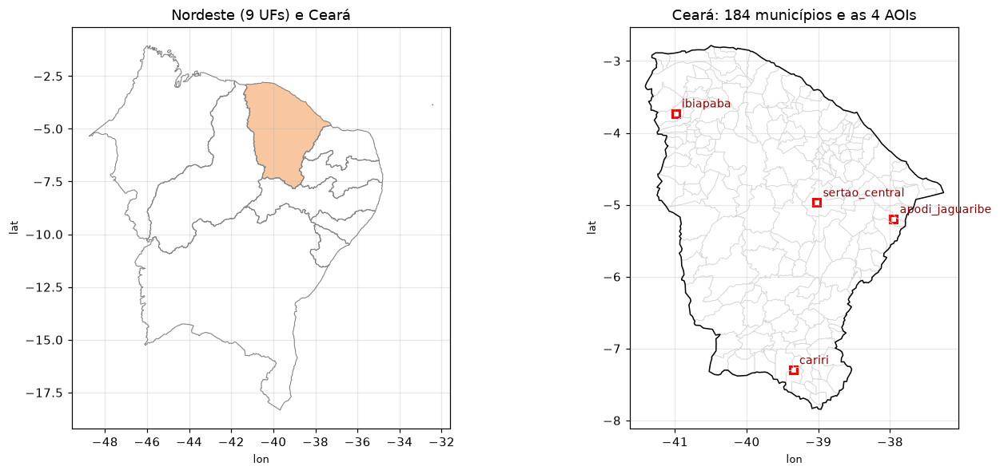

,aoi,lon,lat,descrição
0,apodi_jaguaribe,-37.95,-5.20,Chapada do Apodi / Limoeiro do Norte - fruticultura irrigada
1,cariri,-39.35,-7.30,"Cariri (Crato/Barbalha) - cana, graos de sequeiro"
2,sertao_central,-39.02,-4.97,"Sertao Central (Quixada) - milho/feijao de sequeiro, pastagem"
3,ibiapaba,-40.99,-3.73,"Serra da Ibiapaba (Tianguá/Ubajara) - horticultura, clima ameno"


In [3]:
ce, ne, mun = ceara_gdf(), nordeste_gdf(), municipios_ce_gdf()
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
ne.boundary.plot(ax=ax[0], color="gray", lw=0.7)
ce.plot(ax=ax[0], color="#f4a261", alpha=0.6)
ax[0].set_title("Nordeste (9 UFs) e Ceará")
mun.boundary.plot(ax=ax[1], color="lightgray", lw=0.4)
ce.boundary.plot(ax=ax[1], color="k", lw=1)
for nome, (lon, lat, desc) in AOIS.items():
    ax[1].add_patch(plt.Rectangle((lon - 0.05, lat - 0.05), 0.1, 0.1, fill=False, ec="red", lw=2))
    ax[1].annotate(nome, (lon, lat), xytext=(5, 5), textcoords="offset points", color="darkred", fontsize=9)
ax[1].set_title("Ceará: 184 municípios e as 4 AOIs")
for a in ax:
    a.set_xlabel("lon")
    a.set_ylabel("lat")
plt.tight_layout()
plt.show()
pd.DataFrame([(k, v[0], v[1], v[2]) for k, v in AOIS.items()], columns=["aoi", "lon", "lat", "descrição"])

# 1. NASA POWER — agroclimatologia diária (porta de entrada do produto)

**Ficha técnica**

| Item | Valor |
|---|---|
| Provedor | NASA Langley Research Center — projeto POWER (Prediction Of Worldwide Energy Resources) |
| Origem dos dados | meteorologia: reanálise **MERRA-2** (NASA GMAO); radiação: **CERES/FLASHFlux**; chuva alternativa: **IMERG** (GPM) |
| Variáveis baixadas | T2M, T2M_MAX, T2M_MIN, T2MDEW (°C); RH2M (%); PRECTOTCORR e IMERG_PRECTOT (mm/dia); WS2M (m/s); ALLSKY_SFC_SW_DWN (MJ m⁻² dia⁻¹); EVPTRNS (chega como fluxo de energia em MJ m⁻² dia⁻¹; convertido para mm/dia ÷ 2,45); GWETTOP/GWETROOT/GWETPROF (fração 0–1 de saturação do solo: superfície, zona de raízes, perfil) |
| Resolução espacial | meteorologia 0,5° × 0,625° (~55 × 69 km no Ceará); radiação 1° reamostrada |
| Resolução temporal | diária (também horária, mensal e climatologia) |
| Período | 1981 → hoje (radiação desde 1984; IMERG desde jun/2000) |
| Latência | ~2–4 dias (no download de 13/11/2026 o último dia válido foi 10/11) |
| Acesso | API REST aberta, **sem login**; regional: 1 parâmetro por pedido, ≤ 366 dias e ≤ 10° de lado |
| Licença | dados públicos da NASA; citar NASA POWER Project |

**Ponto de atenção descoberto no download:** `IMERG_PRECTOT` só vem preenchido quando se pede
`time-standard=UTC`; no horário local (padrão) a API devolve −999 em todos os anos. O dia do IMERG (UTC) fica,
portanto, deslocado 3 h em relação ao "dia local" das outras variáveis no Ceará.

In [4]:
import sys
import warnings

sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
from comum import *  # noqa

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymannkendall as mk
import xarray as xr
from scipy import stats

warnings.filterwarnings("ignore")
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
P = DADOS / "power"
ds = xr.open_dataset(P / "power_ce_diario.nc").load()
ds = ds.merge(xr.open_dataset(P / "power_ce_diario_et0.nc").load())
# EVPTRNS chega como fluxo de energia (MJ m-2 dia-1); em lâmina d'água: / 2,45 MJ/kg
ds["EVPTRNS"] = (ds["EVPTRNS"] / 2.45).assign_attrs(units="mm/day")
ind = pd.read_parquet(P / "power_ce_indicadores_anuais.parquet")
glob = pd.read_parquet(P / "power_global_amostra.parquet")
nem = xr.open_dataset(P / "power_ne_mensal.nc").load()
cem = pd.read_parquet(DERIV / "power_ce_mensal.parquet")
uf = nordeste_gdf(); ce_uf = ceara_gdf()
VARS = [v for v in ds.data_vars if "time" in ds[v].dims]
print("Grade Ceará:", dict(ds.sizes), "| variáveis:", VARS)
print("Período:", str(ds.time.values[0])[:10], "→", str(ds.time.values[-1])[:10])

Grade Ceará: {'time': 16753, 'lat': 12, 'lon': 7} | variáveis: ['T2M', 'T2M_MAX', 'T2M_MIN', 'T2MDEW', 'RH2M', 'PRECTOTCORR', 'WS2M', 'ALLSKY_SFC_SW_DWN', 'EVPTRNS', 'GWETTOP', 'GWETROOT', 'GWETPROF', 'IMERG_PRECTOT', 'ET0', 'P_menos_ET0']
Período: 1981-01-01 → 2026-11-13


## 1.1 Validação de cobertura global
Amostra de 107 pontos (2020, diário): todos os continentes, desertos, ilhas oceânicas, altas latitudes, Antártida,
Groenlândia e dois pontos em mar aberto. Para cada parâmetro, medimos a fração de dias com valor válido.

Fração válida média por faixa de latitude:
faixa_lat          (-90, -60]  (-60, -30]  (-30, 0]  (0, 30]  (30, 60]  (60, 90]
param                                                                           
ALLSKY_SFC_SW_DWN         1.0         1.0      1.00      1.0       1.0       1.0
EVPTRNS                   0.0         0.9      0.97      1.0       1.0       0.9
GWETROOT                  0.0         0.9      0.97      1.0       1.0       0.9
GWETTOP                   1.0         1.0      1.00      1.0       1.0       1.0
IMERG_PRECTOT             0.9         1.0      1.00      1.0       1.0       1.0
PRECTOTCORR               1.0         1.0      1.00      1.0       1.0       1.0
RH2M                      1.0         1.0      1.00      1.0       1.0       1.0
T2M                       1.0         1.0      1.00      1.0       1.0       1.0
T2M_MAX                   1.0         1.0      1.00      1.0       1.0       1.0
T2M_MIN                   1.0         1.0      1.00      1.0      

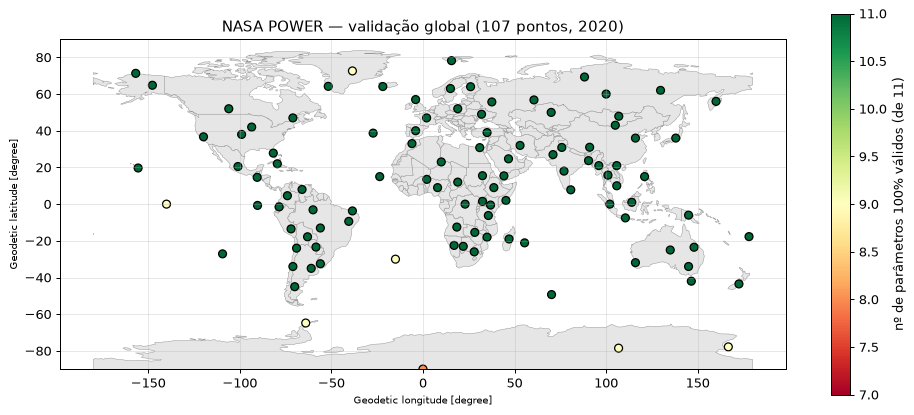

In [5]:
glob["valido"] = glob["valor"] != -999
val = glob.pivot_table(index=["ponto", "lat", "lon"], columns="param", values="valido", aggfunc="mean").reset_index()
val["faixa_lat"] = pd.cut(val["lat"], [-90, -60, -30, 0, 30, 60, 90])
print("Fração válida média por faixa de latitude:")
print(val.groupby("faixa_lat").mean(numeric_only=True).drop(columns=["lat", "lon"]).round(2).T.to_string())
falhos = val.set_index("ponto").drop(columns=["lat", "lon", "faixa_lat"])
print("\nPontos com algum parâmetro incompleto:")
print(falhos[(falhos < 1).any(axis=1)].round(2).to_string())

# sanidade climática: médias anuais por ponto
clim = glob[glob.valido].pivot_table(index="ponto", columns="param", values="valor", aggfunc="mean")
clim["chuva_anual_mm"] = clim["PRECTOTCORR"] * 366
print("\nSanidade (média 2020): mais secos, mais chuvosos, mais frios e mais quentes")
cols = ["T2M", "chuva_anual_mm", "ALLSKY_SFC_SW_DWN", "RH2M"]
print(pd.concat([clim.nsmallest(4, "chuva_anual_mm")[cols], clim.nlargest(4, "chuva_anual_mm")[cols],
                 clim.nsmallest(3, "T2M")[cols], clim.nlargest(3, "T2M")[cols]]).round(1).to_string())

fig, ax = plt.subplots(figsize=(13, 5.5))
paises_gdf().plot(ax=ax, color="0.9", edgecolor="0.6", lw=0.4)
v = val.copy(); v["n_param_ok"] = (falhos == 1).sum(axis=1).values
sc = ax.scatter(v.lon, v.lat, c=v.n_param_ok, cmap="RdYlGn", vmin=7, vmax=11, s=40, edgecolor="k")
plt.colorbar(sc, label="nº de parâmetros 100% válidos (de 11)")
ax.set_title("NASA POWER — validação global (107 pontos, 2020)"); ax.set_ylim(-90, 90); plt.show()

**Veredito de cobertura:** a meteorologia (temperatura, umidade, vento, chuva MERRA-2 e radiação) é **global de
verdade**: 100% dos dias válidos em todos os pontos, da Antártida a Svalbard e em mar aberto. As variáveis do
modelo de superfície (`EVPTRNS`, `GWETROOT`) faltam sobre mantos de gelo e oceano, o que é o esperado e não afeta
área agrícola. O `IMERG_PRECTOT` segue a cobertura do IMERG (ver a tabela acima, em UTC). Ou seja, o POWER sozinho
já garante o "funciona em qualquer fazenda do mundo" para clima, só que a ~50 km.

## 1.2 Qualidade no Ceará

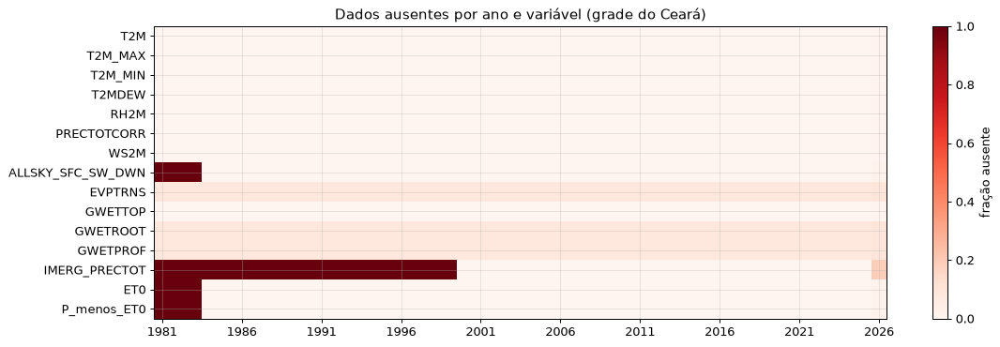

Último dia válido por variável: {'T2M': '2026-11-10', 'T2M_MAX': '2026-11-10', 'T2M_MIN': '2026-11-10', 'T2MDEW': '2026-11-10', 'RH2M': '2026-11-10', 'PRECTOTCORR': '2026-11-10', 'WS2M': '2026-11-10', 'ALLSKY_SFC_SW_DWN': '2026-11-09', 'EVPTRNS': '2026-11-10', 'GWETTOP': '2026-11-10', 'GWETROOT': '2026-11-10', 'GWETPROF': '2026-11-10', 'IMERG_PRECTOT': '2026-09-14', 'ET0': '2026-11-09', 'P_menos_ET0': '2026-11-09'}
Valores fora da faixa física: {'T2M': 0.0, 'T2M_MAX': 0.0, 'T2M_MIN': 0.0, 'RH2M': 0.0, 'PRECTOTCORR': 0.0, 'WS2M': 0.0, 'ALLSKY_SFC_SW_DWN': 0.0, 'GWETTOP': 0.0, 'GWETROOT': 0.0, 'GWETPROF': 0.0, 'EVPTRNS': 0.0, 'ET0': 0.0}
T2M_MIN > T2M_MAX (inconsistências): 0


In [6]:
anos = ds.time.dt.year
falta = pd.DataFrame({v: ds[v].isnull().groupby(anos).mean(("time", "lat", "lon")).to_series() for v in VARS})
fig, ax = plt.subplots(figsize=(14, 4.5))
im = ax.imshow(falta.T.values, aspect="auto", cmap="Reds", vmin=0, vmax=1)
ax.set_yticks(range(len(VARS))); ax.set_yticklabels(VARS)
ax.set_xticks(range(0, len(falta), 5)); ax.set_xticklabels(falta.index[::5])
plt.colorbar(im, label="fração ausente"); ax.set_title("Dados ausentes por ano e variável (grade do Ceará)"); plt.show()
ultimo = {v: str(ds[v].dropna("time", how="all").time.values[-1])[:10] for v in VARS}
print("Último dia válido por variável:", ultimo)

faixas = {"T2M": (5, 45), "T2M_MAX": (10, 48), "T2M_MIN": (0, 35), "RH2M": (0, 100), "PRECTOTCORR": (0, 400),
          "WS2M": (0, 25), "ALLSKY_SFC_SW_DWN": (0, 40), "GWETTOP": (0, 1), "GWETROOT": (0, 1), "GWETPROF": (0, 1),
          "EVPTRNS": (0, 15), "ET0": (0, 15)}
fora = {v: float(((ds[v] < a) | (ds[v] > b)).sum()) for v, (a, b) in faixas.items() if v in ds}
print("Valores fora da faixa física:", fora)
print("T2M_MIN > T2M_MAX (inconsistências):", int((ds.T2M_MIN > ds.T2M_MAX).sum()))

## 1.3 Estatística descritiva — Ceará (diário, pontos dentro do estado)

Pontos da grade POWER dentro do Ceará: 38 de 84


                          n  média  desvio    mín    p01    p10    p50    p90    p99     máx  assimetria  curtose
T2M                636500.0  26.94    2.03  18.39  22.32  24.18  27.06  29.49  30.85   32.81       -0.22    -0.61
T2M_MAX            636500.0  33.22    3.36  21.38  26.13  28.49  33.61  37.45  38.91   40.94       -0.26    -0.93
T2M_MIN            636500.0  22.04    1.79  13.40  17.27  19.70  22.13  24.28  25.63   27.81       -0.40     0.20
T2MDEW             636500.0  18.89    3.08   5.07  11.40  14.54  19.30  22.65  24.11   25.91       -0.46    -0.46
RH2M               636500.0  66.34   14.63  25.73  39.03  46.97  65.61  86.69  91.72   96.83        0.02    -1.13
PRECTOTCORR        636500.0   2.26    4.68   0.00   0.00   0.00   0.19   7.50  22.20  103.15        3.63    19.29
WS2M               636500.0   3.19    1.11   0.22   0.80   1.75   3.17   4.68   5.52    6.89        0.02    -0.67
ALLSKY_SFC_SW_DWN  594776.0  20.73    3.78   1.83  10.00  15.70  21.12  25.31  27.35   2

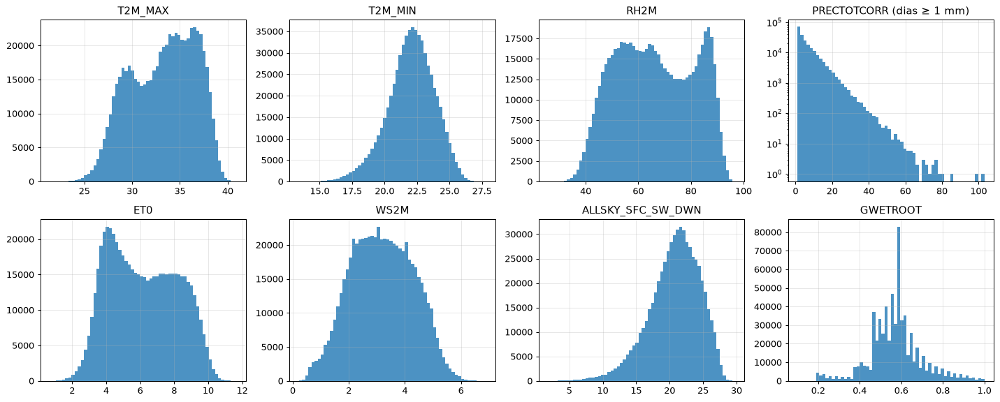

In [7]:
from shapely.geometry import Point
import geopandas as gpd
lo, la = np.meshgrid(ds.lon.values, ds.lat.values)
dentro = gpd.GeoSeries([Point(x, y) for x, y in zip(lo.ravel(), la.ravel())], crs=4326).within(ce_uf.union_all()).values.reshape(lo.shape)
mce = xr.DataArray(dentro, coords={"lat": ds.lat, "lon": ds.lon}, dims=("lat", "lon"))
print("Pontos da grade POWER dentro do Ceará:", int(mce.sum()), "de", mce.size)

def descr(x):
    x = x[np.isfinite(x)]
    return pd.Series({"n": len(x), "média": x.mean(), "desvio": x.std(), "mín": x.min(), "p01": np.percentile(x, 1),
                      "p10": np.percentile(x, 10), "p50": np.percentile(x, 50), "p90": np.percentile(x, 90),
                      "p99": np.percentile(x, 99), "máx": x.max(), "assimetria": stats.skew(x), "curtose": stats.kurtosis(x)})
tab = pd.DataFrame({v: descr(ds[v].where(mce).values.ravel()) for v in VARS}).T
print(tab.round(2).to_string())

fig, axs = plt.subplots(2, 4, figsize=(16, 6.5))
for a, v in zip(axs.ravel(), ["T2M_MAX", "T2M_MIN", "RH2M", "PRECTOTCORR", "ET0", "WS2M", "ALLSKY_SFC_SW_DWN", "GWETROOT"]):
    x = ds[v].where(mce).values.ravel(); x = x[np.isfinite(x)]
    if v == "PRECTOTCORR":
        x = x[x >= 1]; a.set_yscale("log"); a.set_title("PRECTOTCORR (dias ≥ 1 mm)")
    else:
        a.set_title(v)
    a.hist(x, bins=60, color="tab:blue", alpha=0.8)
plt.tight_layout(); plt.show()

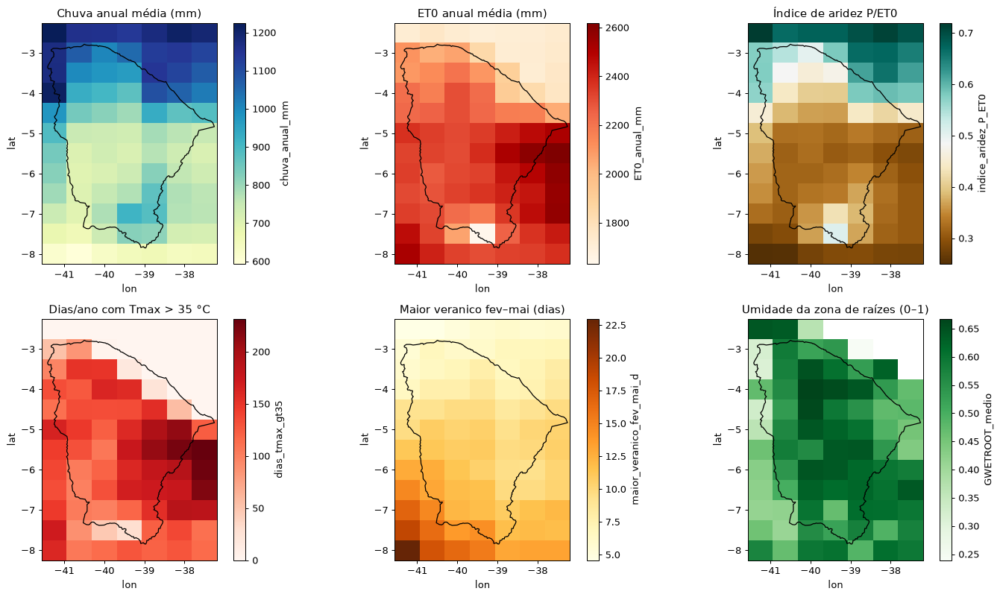

Classes de aridez (UNEP) nos pontos do Ceará: {'hiperárido': 0, 'árido': 0, 'semiárido': 32, 'subúmido seco': 6, 'úmido': 0}


In [8]:
ia = ind[ind.ano.between(1984, 2025)].groupby(["lat", "lon"]).mean(numeric_only=True).to_xarray()
fig, axs = plt.subplots(2, 3, figsize=(16, 9))
for a, (v, cm, t) in zip(axs.ravel(), [("chuva_anual_mm", "YlGnBu", "Chuva anual média (mm)"), ("ET0_anual_mm", "OrRd", "ET0 anual média (mm)"),
                                        ("indice_aridez_P_ET0", "BrBG", "Índice de aridez P/ET0"), ("dias_tmax_gt35", "Reds", "Dias/ano com Tmax > 35 °C"),
                                        ("maior_veranico_fev_mai_d", "YlOrBr", "Maior veranico fev–mai (dias)"), ("GWETROOT_medio", "Greens", "Umidade da zona de raízes (0–1)")]):
    ia[v].plot(ax=a, cmap=cm); ce_uf.boundary.plot(ax=a, color="k", lw=1); a.set_title(t)
plt.tight_layout(); plt.show()
print("Classes de aridez (UNEP) nos pontos do Ceará:",
      pd.cut(ia["indice_aridez_P_ET0"].where(mce).values.ravel(), [0, .05, .2, .5, .65, 10],
             labels=["hiperárido", "árido", "semiárido", "subúmido seco", "úmido"]).value_counts().to_dict())

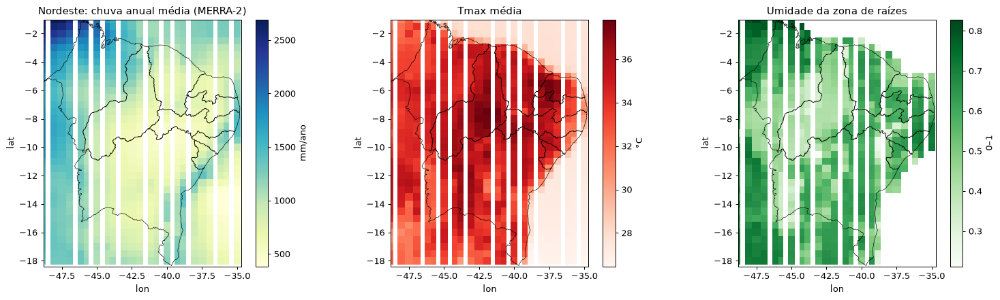

Unidade de PRECTOTCORR no mensal: mm/dia (média do mês)


In [9]:
# Nordeste (mensal): mapas de chuva e temperatura máxima médias
fig, axs = plt.subplots(1, 3, figsize=(17, 5))
(nem.PRECTOTCORR.groupby("time.year").sum(min_count=12).mean("year") * 30.4).plot(ax=axs[0], cmap="YlGnBu", cbar_kwargs={"label": "mm/ano"})
axs[0].set_title("Nordeste: chuva anual média (MERRA-2)")
nem.T2M_MAX.mean("time").plot(ax=axs[1], cmap="Reds", cbar_kwargs={"label": "°C"}); axs[1].set_title("Tmax média")
nem.GWETROOT.mean("time").plot(ax=axs[2], cmap="Greens", cbar_kwargs={"label": "0–1"}); axs[2].set_title("Umidade da zona de raízes")
for a in axs:
    uf.boundary.plot(ax=a, color="k", lw=0.5); a.set_xlim(BBOX_NE[0], BBOX_NE[2]); a.set_ylim(BBOX_NE[1], BBOX_NE[3])
plt.tight_layout(); plt.show()
print("Unidade de PRECTOTCORR no mensal:", nem.PRECTOTCORR.attrs.get("units", "mm/dia (média do mês)"))

## 1.4 Sazonalidade e balanço hídrico

month            1      2      3      4      5      6      7      8      9      10     11     12
chuva_mm_mes  103.1  128.6  196.3  176.8   89.5   42.3   21.7    7.4    3.7    6.4   11.6   37.0
ET0_mm_mes    182.6  147.9  141.5  123.3  132.5  141.6  174.1  219.5  248.3  267.8  247.5  226.1
P_menos_ET0   -79.5  -19.3   54.7   53.6  -42.9  -99.3 -152.4 -212.1 -244.5 -261.4 -235.9 -189.1
T2M_MAX        33.3   32.0   30.7   29.8   30.4   31.3   32.5   34.4   36.0   36.7   36.4   35.2
T2M_MIN        22.8   22.4   22.3   22.1   21.6   20.9   20.6   21.0   21.9   22.7   23.2   23.2
RH2M           67.8   74.3   80.2   83.4   79.4   72.6   64.8   56.4   52.3   52.2   54.3   58.7
GWETROOT        0.5    0.6    0.6    0.7    0.7    0.6    0.6    0.5    0.5    0.5    0.5    0.5


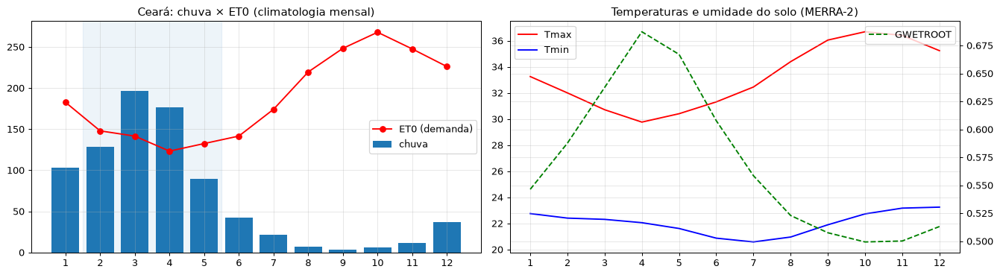

Meses com chuva < ET0 (déficit climático): [1, 2, 5, 6, 7, 8, 9, 10, 11, 12] → 10 de 12


In [10]:
w = np.cos(np.deg2rad(ds.lat)) * mce
med = ds[["PRECTOTCORR", "ET0", "T2M_MAX", "T2M_MIN", "RH2M", "GWETROOT", "ALLSKY_SFC_SW_DWN", "IMERG_PRECTOT"]].where(mce).weighted(w).mean(("lat", "lon"))
mens = med.resample(time="MS").mean()
clim_m = mens.groupby("time.month").mean().to_dataframe()
dias = pd.Series([31, 28.25, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], index=range(1, 13))
clim_m["chuva_mm_mes"] = clim_m["PRECTOTCORR"] * dias
clim_m["ET0_mm_mes"] = clim_m["ET0"] * dias
clim_m["P_menos_ET0"] = clim_m["chuva_mm_mes"] - clim_m["ET0_mm_mes"]
print(clim_m[["chuva_mm_mes", "ET0_mm_mes", "P_menos_ET0", "T2M_MAX", "T2M_MIN", "RH2M", "GWETROOT"]].round(1).T.to_string())
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
ax[0].bar(clim_m.index, clim_m.chuva_mm_mes, label="chuva", color="tab:blue")
ax[0].plot(clim_m.index, clim_m.ET0_mm_mes, "r-o", label="ET0 (demanda)")
ax[0].axvspan(1.5, 5.5, color="tab:blue", alpha=0.08); ax[0].set_xticks(range(1, 13)); ax[0].legend()
ax[0].set_title("Ceará: chuva × ET0 (climatologia mensal)")
ax2 = ax[1].twinx()
ax[1].plot(clim_m.index, clim_m.T2M_MAX, "r-", label="Tmax"); ax[1].plot(clim_m.index, clim_m.T2M_MIN, "b-", label="Tmin")
ax2.plot(clim_m.index, clim_m.GWETROOT, "g--", label="GWETROOT"); ax[1].legend(loc="upper left"); ax2.legend(loc="upper right")
ax[1].set_xticks(range(1, 13)); ax[1].set_title("Temperaturas e umidade do solo (MERRA-2)")
plt.tight_layout(); plt.show()
meses_def = clim_m.index[clim_m.P_menos_ET0 < 0].tolist()
print("Meses com chuva < ET0 (déficit climático):", meses_def, "→", len(meses_def), "de 12")

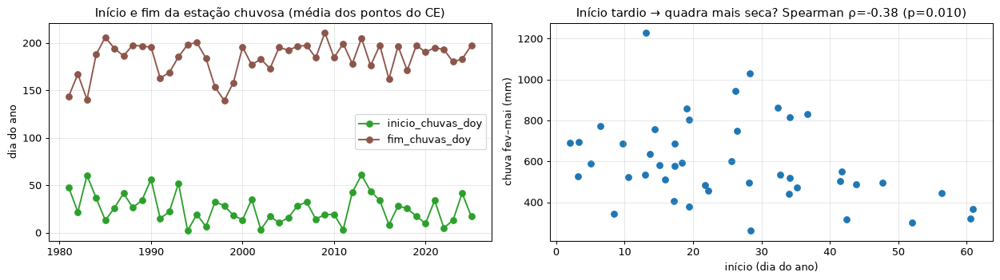

                   count   mean   std    min    25%    50%    75%    max
inicio_chuvas_doy   45.0   25.7  15.5    2.0   14.4   22.2   34.2   60.9
fim_chuvas_doy      45.0  184.0  17.6  139.3  176.1  187.9  196.7  210.9


In [11]:
ic = ind[ind.no_ceara].groupby("ano").mean(numeric_only=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for v, c in [("inicio_chuvas_doy", "tab:green"), ("fim_chuvas_doy", "tab:brown")]:
    ax[0].plot(ic.index, ic[v], "-o", color=c, label=v)
ax[0].set_ylabel("dia do ano"); ax[0].legend(); ax[0].set_title("Início e fim da estação chuvosa (média dos pontos do CE)")
ax[1].scatter(ic.inicio_chuvas_doy, ic.chuva_fev_mai_mm); ax[1].set_xlabel("início (dia do ano)"); ax[1].set_ylabel("chuva fev–mai (mm)")
r = stats.spearmanr(ic.inicio_chuvas_doy, ic.chuva_fev_mai_mm, nan_policy="omit")
ax[1].set_title(f"Início tardio → quadra mais seca? Spearman ρ={r.correlation:.2f} (p={r.pvalue:.3f})")
plt.tight_layout(); plt.show()
print(ic[["inicio_chuvas_doy", "fim_chuvas_doy"]].describe().round(1).T.to_string())

## 1.5 Tendências 1984–2025 (Mann-Kendall + Sen)

               indicador  tendência     p  Sen/ano  Sen/década
          chuva_anual_mm   no trend 0.153   -4.848     -48.480
        chuva_fev_mai_mm   no trend 0.056   -5.216     -52.161
            ET0_anual_mm   no trend 0.186    2.624      26.235
     indice_aridez_P_ET0   no trend 0.179   -0.003      -0.026
          dias_tmax_gt35 increasing 0.005    1.024      10.235
          dias_tmax_gt38 increasing 0.000    0.525       5.251
         dias_chuva_gt50 increasing 0.001    0.002       0.022
maior_veranico_fev_mai_d   no trend 0.264    0.047       0.474
 n_veranicos_10d_fev_mai   no trend 0.224    0.004       0.041
       inicio_chuvas_doy   no trend 0.429   -0.156      -1.564
          fim_chuvas_doy   no trend 0.991   -0.002      -0.019
          GWETROOT_medio   no trend 0.153   -0.001      -0.007
                 T2M_MAX increasing 0.010    0.037       0.366
                 T2M_MIN increasing 0.000    0.024       0.240


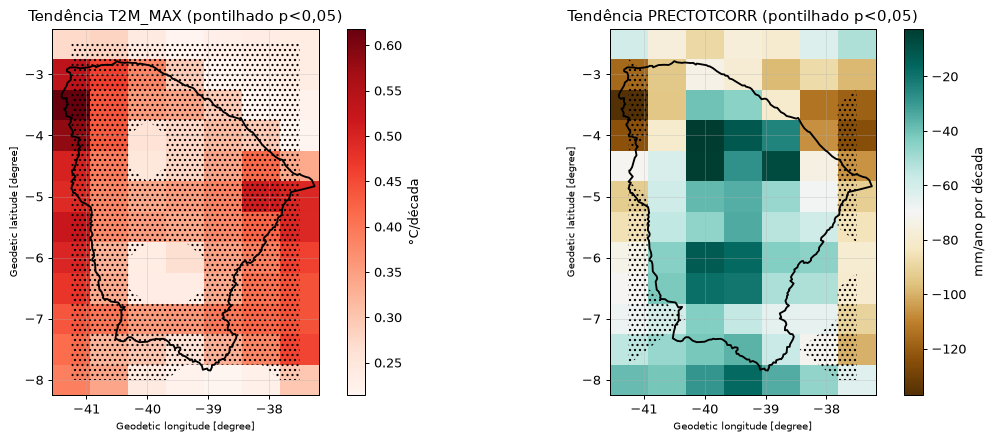

In [12]:
cols = ["chuva_anual_mm", "chuva_fev_mai_mm", "ET0_anual_mm", "indice_aridez_P_ET0", "dias_tmax_gt35", "dias_tmax_gt38",
        "dias_chuva_gt50", "maior_veranico_fev_mai_d", "n_veranicos_10d_fev_mai", "inicio_chuvas_doy", "fim_chuvas_doy", "GWETROOT_medio"]
anual_t = med[["T2M_MAX", "T2M_MIN"]].groupby("time.year").mean().to_dataframe()
icx = ic.loc[1984:2025, cols].join(anual_t.loc[1984:2025])
res = []
for c in icx.columns:
    x = icx[c].dropna()
    r = mk.original_test(x.values)
    res.append((c, r.trend, round(r.p, 4), r.slope, r.slope * 10))
print(pd.DataFrame(res, columns=["indicador", "tendência", "p", "Sen/ano", "Sen/década"]).round(3).to_string(index=False))

# por pixel: Tmax e chuva anual
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for a, v, cm, un in [(axs[0], "T2M_MAX", "Reds", "°C/década"), (axs[1], "PRECTOTCORR", "BrBG", "mm/ano por década")]:
    agg = ds[v].sel(time=slice("1984", "2025")).groupby("time.year")
    arr = (agg.mean() if v == "T2M_MAX" else agg.sum(min_count=360))
    sl = np.full(mce.shape, np.nan); pv = sl.copy()
    for i in range(mce.shape[0]):
        for j in range(mce.shape[1]):
            y = arr[:, i, j].values; y = y[np.isfinite(y)]
            if len(y) > 20:
                rr = mk.original_test(y); sl[i, j] = rr.slope * 10; pv[i, j] = rr.p
    im = a.pcolormesh(ds.lon, ds.lat, sl, cmap=cm if v == "PRECTOTCORR" else "Reds", shading="auto")
    a.contourf(ds.lon, ds.lat, (pv < 0.05).astype(float), levels=[0.5, 1.5], hatches=["..."], colors="none")
    ce_uf.boundary.plot(ax=a, color="k"); plt.colorbar(im, ax=a, label=un); a.set_title(f"Tendência {v} (pontilhado p<0,05)")
plt.tight_layout(); plt.show()

## 1.6 Variabilidade interanual, seca de 2012–2017 e extremos

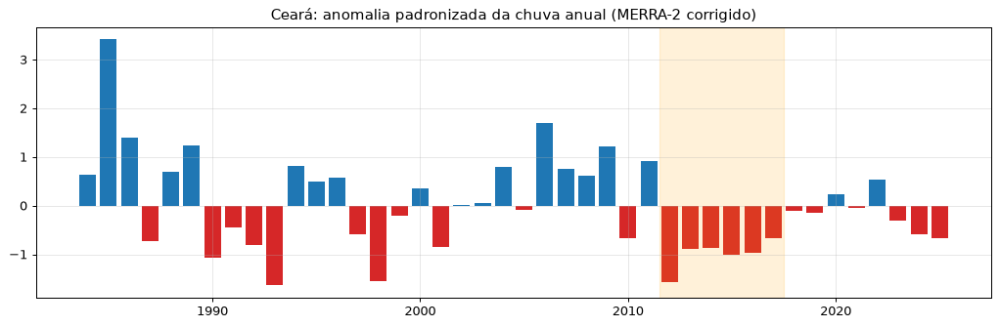

Anos mais secos: {1993: -1.63, 2012: -1.56, 1998: -1.55, 1990: -1.07, 2015: -1.0, 2016: -0.97}
Anos mais chuvosos: {1985: 3.42, 2006: 1.71, 1986: 1.4, 1989: 1.25, 2009: 1.21, 2011: 0.91}
Seca 2012–2017: chuva média 584 mm vs climatologia 849 mm (-31%)

Percentis de chuva em dias úmidos (≥1 mm): {50: 4.3, 90: 14.3, 95: 18.8, 99: 29.5, 99.9: 46.5}
Percentis de Tmax: {50: 33.6, 90: 37.5, 95: 38.0, 99: 38.9}
Fração de dias com Tmax > 35 °C (limiar de estresse térmico para milho/feijão na floração): 0.355


In [13]:
ch = ic.loc[1984:2025, "chuva_anual_mm"]
anom = (ch - ch.mean()) / ch.std()
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(anom.index, anom, color=np.where(anom < 0, "tab:red", "tab:blue"))
ax.axvspan(2011.5, 2017.5, color="orange", alpha=0.15); ax.set_title("Ceará: anomalia padronizada da chuva anual (MERRA-2 corrigido)")
plt.show()
print("Anos mais secos:", anom.nsmallest(6).round(2).to_dict())
print("Anos mais chuvosos:", anom.nlargest(6).round(2).to_dict())
print("Seca 2012–2017: chuva média", round(ch.loc[2012:2017].mean()), "mm vs climatologia", round(ch.mean()), "mm",
      f"({100 * (ch.loc[2012:2017].mean() / ch.mean() - 1):.0f}%)")

pr = ds.PRECTOTCORR.where(mce).values
pr = pr[np.isfinite(pr)]
umidos = pr[pr >= 1]
print("\nPercentis de chuva em dias úmidos (≥1 mm):", {p: round(float(np.percentile(umidos, p)), 1) for p in (50, 90, 95, 99, 99.9)})
tx = ds.T2M_MAX.where(mce).values; tx = tx[np.isfinite(tx)]
print("Percentis de Tmax:", {p: round(float(np.percentile(tx, p)), 1) for p in (50, 90, 95, 99)})
print("Fração de dias com Tmax > 35 °C (limiar de estresse térmico para milho/feijão na floração):", round(float((tx > 35).mean()), 3))

## 1.7 Duas chuvas no mesmo produto: MERRA-2 corrigido × IMERG
O POWER entrega duas estimativas de chuva. Se elas divergem, o app precisa escolher e explicar a incerteza.

Meses comparados: 321 | correlação mensal r=0.967 | viés MERRA-2 vs IMERG: -0.3%
Diário: r = 0.831 | dias ≥ 1 mm MERRA-2: 0.401 IMERG: 0.342


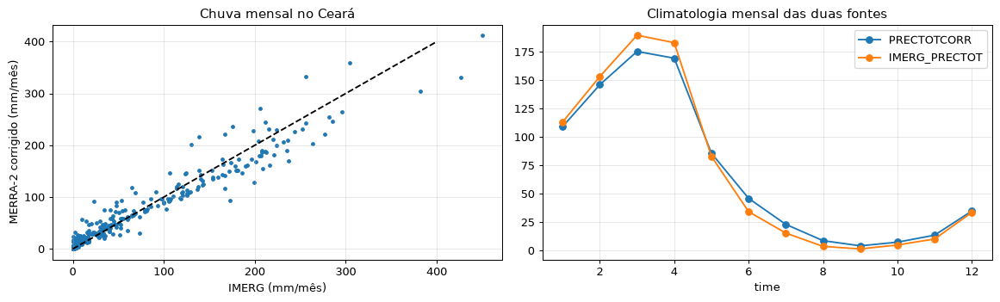

In [14]:
mm = med[["PRECTOTCORR", "IMERG_PRECTOT"]].resample(time="MS").mean().to_dataframe().dropna()
if len(mm) > 24:
    r = np.corrcoef(mm.PRECTOTCORR, mm.IMERG_PRECTOT)[0, 1]
    vies = 100 * (mm.PRECTOTCORR.mean() / mm.IMERG_PRECTOT.mean() - 1)
    print(f"Meses comparados: {len(mm)} | correlação mensal r={r:.3f} | viés MERRA-2 vs IMERG: {vies:+.1f}%")
    d = ds[["PRECTOTCORR", "IMERG_PRECTOT"]].where(mce).weighted(w).mean(("lat", "lon")).to_dataframe().dropna()
    print("Diário: r =", round(np.corrcoef(d.PRECTOTCORR, d.IMERG_PRECTOT)[0, 1], 3),
          "| dias ≥ 1 mm MERRA-2:", round((d.PRECTOTCORR >= 1).mean(), 3), "IMERG:", round((d.IMERG_PRECTOT >= 1).mean(), 3))
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].scatter(mm.IMERG_PRECTOT * 30.4, mm.PRECTOTCORR * 30.4, s=8); ax[0].plot([0, 400], [0, 400], "k--")
    ax[0].set_xlabel("IMERG (mm/mês)"); ax[0].set_ylabel("MERRA-2 corrigido (mm/mês)"); ax[0].set_title("Chuva mensal no Ceará")
    c2 = mm.groupby(mm.index.month).mean() * 30.4
    c2.plot(ax=ax[1], marker="o"); ax[1].set_title("Climatologia mensal das duas fontes"); plt.tight_layout(); plt.show()
else:
    print("IMERG_PRECTOT sem dados suficientes nesta grade.")

## 1.8 Insights e uso no produto

- **Cobertura global comprovada**: a meteorologia do POWER foi 100% válida em 107 pontos de todos os continentes.
  É a camada que garante que o app funcione em qualquer fazenda. Só que é **regional (~50 km)**: sem microclima,
  sem efeito de serra (Ibiapaba/Araripe ficam suavizadas). O SRTM entra para corrigir isso.
- **Balanço hídrico climático**: a ET0 calculada por FAO-56 (~6 mm/dia no interior, 5,2 em Fortaleza) supera a
  chuva em **10 de 12 meses**; só março e abril têm excedente (~+55 mm/mês). A estação útil vai, em média, do dia
  26 (fim de janeiro) ao dia 184 (início de julho). Isso define a **janela de plantio de sequeiro** e quanto falta
  para irrigar; é o núcleo do motor de rotação (a cultura cabe na janela? quanto de água ela pede?). 32 dos 38
  pontos do estado são **semiáridos** (P/ET0 entre 0,2 e 0,5) e 6 são subúmidos secos (litoral e serras).
- **O sinal de mudança climática está na temperatura, não na chuva**: Tmax +0,37 °C/década e Tmin +0,24 °C/década
  (p ≤ 0,01); dias acima de 35 °C crescem **+10 por década** e acima de 38 °C, +5 por década. A chuva anual não tem
  tendência significativa (p = 0,15). Resultado: a mesma chuva com mais calor e mais ET, ou seja, mais estresse.
  Rotações com culturas tolerantes ao calor na floração (sorgo, caupi, gergelim) ganham peso ao longo do tempo.
- **Seca 2012–2017** = −31% de chuva (584 mm/ano contra 849 mm da climatologia). Os anos mais secos (1993, 2012,
  1998) são anos de El Niño e/ou de dipolo positivo, ligação explorada na seção 13.
- **Indicadores de risco prontos** para o calendário do app: dias com Tmax > 35 °C (estresse na floração; 35% dos
  dias no Ceará), veranicos na quadra chuvosa, chuvas > 50 mm (erosão), início e fim das chuvas (data de plantio).
- **Duas chuvas, quase a mesma resposta no mensal**: `PRECTOTCORR` (MERRA-2 corrigido) e `IMERG_PRECTOT` têm
  r = 0,97 no mensal e viés de −0,3%, mas r = 0,83 no diário e o IMERG tem menos dias de chuva (34% × 40%). Para
  balanço mensal tanto faz; para veranicos e dias de plantio, a escolha da fonte muda o resultado e o app deve
  mostrar a faixa entre as duas.
- **Ideias de ML/DL**:
  1. *Previsão sazonal da quadra chuvosa* (fev–mai) com ENSO/dipolo (seção 13) + chuva de dezembro e janeiro
     (gradient boosting ou regressão quantílica) → probabilidade de quadra seca, normal ou chuvosa para escolher a
     rotação.
  2. *Detecção do início das chuvas* em tempo real (classificador sobre janelas de 30 dias) para dizer "pode plantar".
  3. *Gerador de cenários* (bootstrap por blocos de anos ou GAN/difusão sobre séries diárias) para os controles de
     cenário do app (+2 °C, −20% de chuva).
  4. *Emulador de produtividade*: modelos de cultura (DSSAT/APSIM aceitam o POWER como entrada) → rede neural
     substituta para avaliar milhares de rotações em segundos.

# 2. GPM IMERG — precipitação por satélite (NASA/JAXA)

**Ficha técnica**

| Item | Valor |
|---|---|
| Missão / produto | GPM (Global Precipitation Measurement), algoritmo IMERG — fusão de micro-ondas passivas de ~10 satélites + infravermelho geoestacionário, calibrada pelo radar DPR e por pluviômetros (GPCC) na versão Final |
| Variável | precipitação total (mm/dia; mm/h na meia-hora) |
| Resolução | 0,1° (~11 km no Ceará); meia-hora (nativo) e diário (agregado) |
| Período baixado | **diário V07: 01/01/1998 a 14/09/2026** (inclui a era TRMM; o POWER tem ~2 meses de latência); **meia-hora V06: amostra de 12 dias, 10–21/03/2009** (auge da quadra de um ano muito chuvoso) |
| Rotas usadas (sem login) | diário: NASA POWER `IMERG_PRECTOT` com `time-standard=UTC` (o POWER entrega o IMERG na grade nativa 0,1°); meia-hora: Microsoft Planetary Computer `gpm-imerg-hhr` (Zarr V06, 2000-06 a 2021-05) |
| Rota oficial | GES DISC (GPM_3IMERGDF/DL/DE V07) — exige Earthdata Login; Final V07 só até set/2025, Early/Late até ontem |
| Recorte | Ceará (−41,5 a −37,0 lon; −8,0 a −2,5 lat; 45×55 pixels) e Nordeste (−48,8 a −34,7; −18,4 a −1,0; 141×174 pixels) |

**Por que o meia-hora é só uma amostra:** no Planetary Computer cada bloco Zarr tem 12 meias-horas do
**globo inteiro** (~52 MB comprimidos). Para recortar o Ceará é preciso baixar o planeta: o registro completo
daria ~1,6 TB. Com a conexão medida (5–6 MB/s) isso é inviável; ficamos com uma amostra para ciclo diurno,
intensidade de 30 min (erosividade) e validação global.

In [15]:
import sys, warnings
sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
from comum import *  # noqa
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import shapely
import pymannkendall as mk
from scipy import stats

warnings.filterwarnings("ignore")
try:
    sys.stdout.reconfigure(encoding="utf-8")
except Exception:
    pass
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
DIR = DADOS / "imerg"
ce_gdf, ne_gdf, terra = ceara_gdf(), nordeste_gdf(), terra_gdf()
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]


def mascara(geom, lon, lat):
    lo, la = np.meshgrid(lon, lat)
    return shapely.contains_xy(geom, lo, la)


def mapa(ax, da, titulo, cmap="viridis", gdf=None, **kw):
    m = ax.pcolormesh(da.lon, da.lat, da, cmap=cmap, shading="auto", **kw)
    (gdf if gdf is not None else ce_gdf).boundary.plot(ax=ax, color="k", lw=0.6)
    ax.set_title(titulo, fontsize=10)
    ax.set_aspect("equal")
    plt.colorbar(m, ax=ax, shrink=0.8)
    return m


ce = xr.open_mfdataset(sorted(DIR.glob("imerg_ce_diario_*.nc")), combine="by_coords")["precip"].load()
M_CE = xr.DataArray(mascara(ce_gdf.geometry.union_all(), ce.lon.values, ce.lat.values), dims=("lat", "lon"))
ce_m = ce.where(M_CE)
serie_ce = ce_m.mean(("lat", "lon")).to_series()  # media diaria na area do Ceara
print("Ceará diário:", ce.sizes, "| período", str(ce.time.values[0])[:10], "→", str(ce.time.values[-1])[:10])
print("pixels dentro do Ceará:", int(M_CE.sum()), "de", M_CE.size)

Ceará diário: Frozen({'time': 10484, 'lat': 55, 'lon': 45}) | período 1998-01-01 → 2026-09-14
pixels dentro do Ceará: 1212 de 2475


## 2.1 Validação de cobertura global
Duas evidências independentes:
1. **POWER/IMERG V07:** grade regular de 216 pontos (18 latitudes de 85°S a 85°N × 12 longitudes, terra e oceano), 10 dias de mar/2019.
2. **Planetary Computer/IMERG V06:** cada bloco baixado é o campo global completo; guardamos o total diário em 0,5° e o número de meias-horas válidas por célula.

POWER/IMERG V07 — pontos com 10/10 dias válidos: 100% | latitudes testadas: -85 a 85
dias da amostra nativa V06: 12


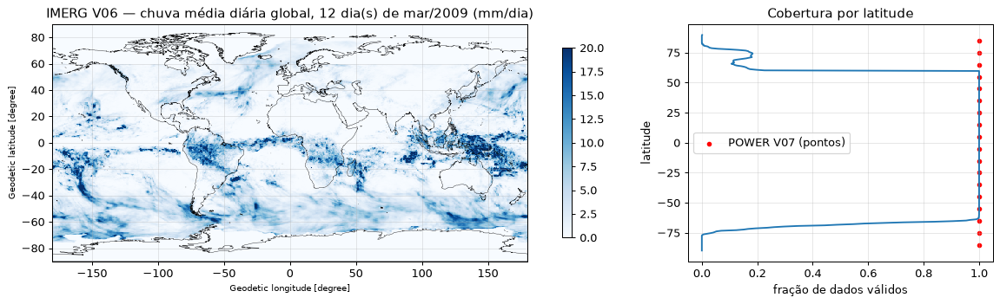

V06 — fração válida entre 60°S e 60°N: 1.0 | acima de 60°: 0.1899999976158142


In [16]:
val = pd.read_csv(DIR / "validacao_global_power_imerg.csv")
print("POWER/IMERG V07 — pontos com 10/10 dias válidos:", f"{(val.n_validos == val.n_dias).mean():.0%}",
      "| latitudes testadas:", val.lat.min(), "a", val.lat.max())
pc_arqs = sorted((DIR / "pc_nativo").glob("imerg_v06_*.nc"))
print("dias da amostra nativa V06:", len(pc_arqs))
if pc_arqs:
    g = xr.open_mfdataset(pc_arqs, combine="nested", concat_dim="dia")[["global_dia_05", "global_nvalidos_05"]].load()
    frac_lat = (g.global_nvalidos_05 / 48).mean(("dia", "lon05"))
    fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.3, 1]})
    m = ax[0].pcolormesh(g.lon05, g.lat05, g.global_dia_05.mean("dia").T, cmap="Blues", vmax=20, shading="auto")
    terra.boundary.plot(ax=ax[0], color="k", lw=0.3)
    ax[0].set_title(f"IMERG V06 — chuva média diária global, {len(pc_arqs)} dia(s) de mar/2009 (mm/dia)")
    plt.colorbar(m, ax=ax[0], shrink=0.8)
    ax[1].plot(frac_lat, g.lat05)
    ax[1].scatter(val.groupby("lat").n_validos.mean() / 10, val.groupby("lat").n_validos.mean().index, c="r", s=12,
                  label="POWER V07 (pontos)")
    ax[1].set_xlabel("fração de dados válidos")
    ax[1].set_ylabel("latitude")
    ax[1].set_title("Cobertura por latitude")
    ax[1].legend()
    plt.tight_layout()
    plt.show()
    print("V06 — fração válida entre 60°S e 60°N:", float(frac_lat.sel(lat05=slice(-60, 60)).mean().round(3)),
          "| acima de 60°:", float(frac_lat.where(abs(frac_lat.lat05) > 60).mean().round(3)))

**Veredito de cobertura.** O IMERG é **global de fato** para o uso agrícola. A V07 (via POWER) tem valores
em todas as latitudes testadas, de 85°S a 85°N, terra e oceano. Na V06, a fração válida cai acima de ~60°,
onde só há micro-ondas esparsas e neve/gelo; isso não afeta nenhuma região agrícola relevante.
Toda a faixa 60°S–60°N, onde está praticamente toda a agricultura do planeta, tem cobertura completa a 0,1° e
30 min. **Pode ser a camada de chuva do produto mundial.**

## 2.2 Qualidade: ausentes, buracos, faixas e outliers

In [17]:
dias_esperados = pd.date_range(ce.time.values[0], ce.time.values[-1], freq="D")
nan_frac = float(ce_m.isnull().where(M_CE).mean())
print(f"dias esperados {len(dias_esperados)} | dias presentes {ce.sizes['time']} | buracos {len(dias_esperados) - ce.sizes['time']}")
print(f"fração de ausentes (pixels do Ceará): {nan_frac:.4%}")
print("dias com algum pixel ausente:", int(ce_m.isnull().where(M_CE, False).any(("lat", "lon")).sum()))
v = ce_m.values[np.isfinite(ce_m.values)]
print(f"mín {v.min():.2f} | máx {v.max():.1f} mm/dia | negativos: {(v < 0).sum()}")
print("percentis dos dias de chuva (≥1 mm):", np.percentile(v[v >= 1], [50, 90, 95, 99, 99.9]).round(1))
top = ce_m.where(ce_m > 150, drop=True)
print("pixel-dias > 150 mm:", int(np.isfinite(top.values).sum()), "| > 250 mm:", int((ce_m > 250).sum()))
idx = np.unravel_index(np.nanargmax(ce_m.values), ce_m.shape)
print("máximo absoluto:", float(ce_m.values[idx]), "mm em", str(ce.time.values[idx[0]])[:10],
      "lat", float(ce.lat[idx[1]]), "lon", float(ce.lon[idx[2]]))
# outliers espaciais: pixel muito acima dos vizinhos no mesmo dia (robustez)
viz = ce.rolling(lat=3, lon=3, center=True).median()
iso = ((ce > 100) & (ce > 5 * (viz + 1))).where(M_CE, False)
print("pixel-dias isolados (>100 mm e >5x a mediana 3x3):", int(iso.sum()), "— candidatos a artefato a revisar")

dias esperados 10484 | dias presentes 10484 | buracos 0
fração de ausentes (pixels do Ceará): 0.0000%
dias com algum pixel ausente: 0
mín 0.00 | máx 216.9 mm/dia | negativos: 0
percentis dos dias de chuva (≥1 mm): [ 5.3 23.2 32.5 55.4 89.6]
pixel-dias > 150 mm: 32 | > 250 mm: 0


máximo absoluto: 216.9199981689453 mm em 2014-02-20 lat -3.45 lon -40.65


pixel-dias isolados (>100 mm e >5x a mediana 3x3): 3 — candidatos a artefato a revisar


### 2.2b Viés no litoral leste do Nordeste (chuva "quente")
Total anual médio do IMERG em pixels de capitais contra as normais climatológicas aproximadas (INMET 1991–2020,
valores de referência arredondados, a conferir com a tabela oficial). Satélites de micro-ondas e infravermelho
enxergam mal a chuva de nuvens rasas e quentes trazida pelos alísios e pelos distúrbios de leste na costa
oriental. A calibração mensal do GPCC, em 1°, não resolve o gradiente costeiro.

In [18]:
ne_all = xr.open_mfdataset(sorted(DIR.glob("imerg_ne_diario_*.nc")), combine="by_coords")["precip"].sel(time=slice("1998", "2025"))
pts = {"Recife": (-34.95, -8.05, 2400), "Maceió": (-35.75, -9.65, 2100), "Aracaju": (-37.05, -10.95, 1600),
       "João Pessoa": (-34.85, -7.15, 2000), "Salvador": (-38.50, -12.95, 2100), "Natal": (-35.20, -5.80, 1700),
       "Fortaleza": (-38.55, -3.75, 1600), "São Luís": (-44.25, -2.55, 2300),
       "Petrolina (sertão)": (-40.50, -9.40, 550), "Quixadá (sertão)": (-39.00, -4.95, 800),
       "Crato (Cariri)": (-39.40, -7.25, 1100)}
lin = []
for k, (lo, la, normal) in pts.items():
    s = ne_all.sel(lon=lo, lat=la, method="nearest").load()
    im = float(s.resample(time="YS").sum().mean())
    lin.append({"local": k, "IMERG_mm_ano": round(im), "normal_aprox_mm": normal, "razão": round(im / normal, 2)})
tab_costa = pd.DataFrame(lin).set_index("local")
print(tab_costa.to_string())
print("\n→ litoral leste (Natal a Salvador): IMERG ≈", f"{tab_costa.loc[['Recife','Maceió','Aracaju','João Pessoa','Salvador','Natal'],'razão'].mean():.0%}",
      "da normal; sertão ≈", f"{tab_costa.loc[['Petrolina (sertão)','Quixadá (sertão)'],'razão'].mean():.0%}")

                    IMERG_mm_ano  normal_aprox_mm  razão
local                                                   
Recife                      1041             2400   0.43
Maceió                       859             2100   0.41
Aracaju                      761             1600   0.48
João Pessoa                 1206             2000   0.60
Salvador                    1101             2100   0.52
Natal                       1086             1700   0.64
Fortaleza                   1174             1600   0.73
São Luís                    2098             2300   0.91
Petrolina (sertão)           449              550   0.82
Quixadá (sertão)             756              800   0.94
Crato (Cariri)               856             1100   0.78

→ litoral leste (Natal a Salvador): IMERG ≈ 51% da normal; sertão ≈ 88%


**Consequência para o produto:** no sertão do Ceará (o foco da demo) o IMERG é confiável. No litoral leste ele
fica em ~40–60 % das normais aproximadas. Parte disso pode vir de o pixel de 0,1° misturar terra e mar, e o ERA5
também subestima Recife (ver seção 3.7), mas a ordem de grandeza indica um viés real. Qualquer balanço hídrico
ali precisa de **correção de viés com pluviômetros** (INMET, ANA, FUNCEME/APAC ou CHIRPS, que já incorpora
estações). A ferramenta deve mostrar um selo de confiança por pixel, calculado onde houver estação.

## 2.3 Estatística descritiva — Ceará e Nordeste

Total anual médio na área do Ceará (1998–2025):
count      28.0
mean      812.0
std       217.0
min       432.5
25%       671.5
50%       745.6
75%       961.8
max      1401.8
assimetria 0.68 | curtose 0.32 | CV 26.7%
dias de chuva (≥1 mm) por ano, média por pixel: 83
intensidade média nos dias de chuva (SDII): 9.6 mm/dia


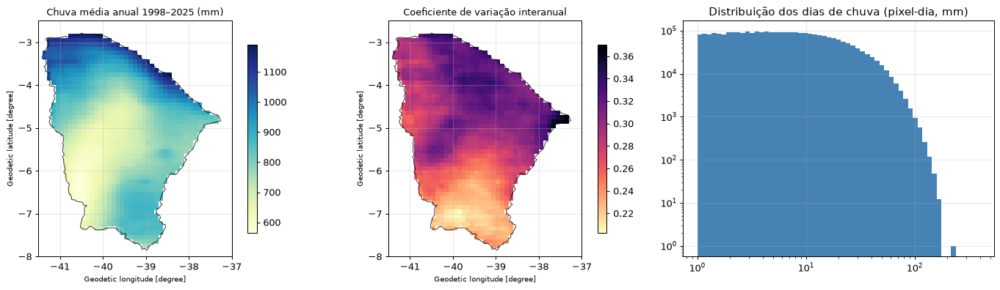

In [19]:
anos_completos = [a for a in range(1998, 2026)]
anual_ce = ce.sel(time=ce.time.dt.year.isin(anos_completos)).resample(time="YS").sum()
anual_ce["time"] = anual_ce.time.dt.year
serie_anual = serie_ce[serie_ce.index.year.isin(anos_completos)].resample("YS").sum()
serie_anual.index = serie_anual.index.year
desc = serie_anual.describe()
print("Total anual médio na área do Ceará (1998–2025):")
print(desc.round(1).to_string())
print(f"assimetria {stats.skew(serie_anual):.2f} | curtose {stats.kurtosis(serie_anual):.2f} | CV {serie_anual.std()/serie_anual.mean():.1%}")
chuva = v[v >= 1]
print(f"dias de chuva (≥1 mm) por ano, média por pixel: {(ce_m >= 1).sum('time').where(M_CE).mean().item() / len(np.unique(ce.time.dt.year)):.0f}")
print(f"intensidade média nos dias de chuva (SDII): {chuva.mean():.1f} mm/dia")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
mapa(ax[0], anual_ce.mean("time").where(M_CE), "Chuva média anual 1998–2025 (mm)", "YlGnBu")
cv = (anual_ce.std("time") / anual_ce.mean("time")).where(M_CE)
mapa(ax[1], cv, "Coeficiente de variação interanual", "magma_r")
ax[2].hist(chuva, bins=np.logspace(0, 2.6, 60), color="steelblue")
ax[2].set_xscale("log")
ax[2].set_yscale("log")
ax[2].set_title("Distribuição dos dias de chuva (pixel-dia, mm)")
plt.tight_layout()
plt.show()

arquivos NE: 29


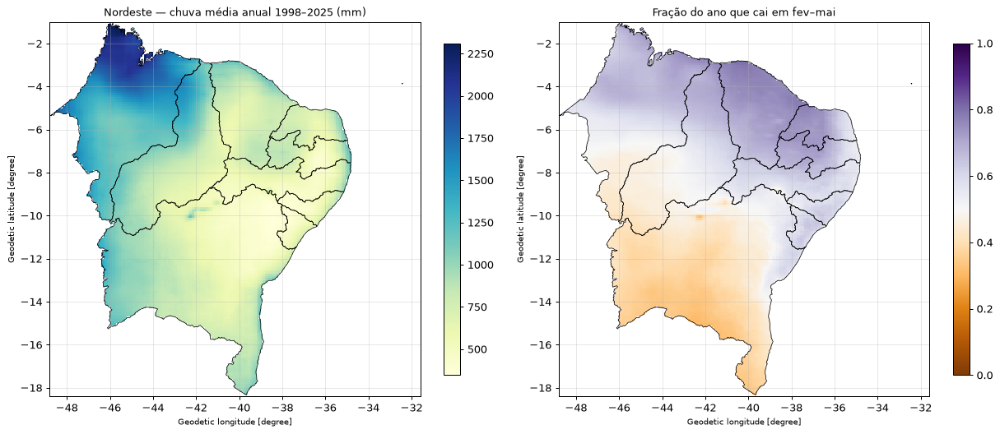

    anual_media_mm  anual_dp_mm    CV  min_ano       min_mm  fração_fev_mai
UF                                                                         
SE      511.660004   157.929993  0.31     2012   160.979996            0.58
AL      548.780029   202.270004  0.37     2012   166.940002            0.57
PE      586.599976   174.289993  0.30     2012   227.350006            0.59
PB      694.239990   209.529999  0.30     1998   329.630005            0.65
BA      735.609985   162.380005  0.22     2012   434.820007            0.41
RN      748.950012   244.110001  0.33     2012   379.390015            0.69
CE      812.000000   217.029999  0.27     2012   432.500000            0.73
PI      941.119995   154.639999  0.16     2012   671.469971            0.56
MA     1497.939941   215.630005  0.14     2015  1124.459961            0.61


In [20]:
# Nordeste: agregados anuais ano a ano (sem carregar tudo de uma vez)
ne_arqs = sorted(DIR.glob("imerg_ne_diario_*.nc"))
print("arquivos NE:", len(ne_arqs))
anual_ne, quadra_ne, clim_ne = [], [], []
if not ne_arqs:
    raise SystemExit("dados do Nordeste ainda não consolidados")
for a in ne_arqs:
    d = xr.open_dataset(a)["precip"].load()
    ano = int(d.time.dt.year[0])
    if ano in anos_completos:
        anual_ne.append(d.sum("time").expand_dims(ano=[ano]))
    quadra_ne.append(d.sel(time=d.time.dt.month.isin([2, 3, 4, 5])).sum("time").expand_dims(ano=[ano]))
    clim_ne.append(d.resample(time="MS").sum())
anual_ne = xr.concat(anual_ne, "ano")
quadra_ne = xr.concat(quadra_ne, "ano")
mens_ne = xr.concat(clim_ne, "time")
M_NE = xr.DataArray(mascara(ne_gdf.geometry.union_all(), anual_ne.lon.values, anual_ne.lat.values), dims=("lat", "lon"))
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
mapa(ax[0], anual_ne.mean("ano").where(M_NE), "Nordeste — chuva média anual 1998–2025 (mm)", "YlGnBu", gdf=ne_gdf)
mapa(ax[1], (quadra_ne.mean("ano") / anual_ne.mean("ano")).where(M_NE), "Fração do ano que cai em fev–mai", "PuOr",
     gdf=ne_gdf, vmin=0, vmax=1)
plt.tight_layout()
plt.show()
siglas = {"21": "MA", "22": "PI", "23": "CE", "24": "RN", "25": "PB", "26": "PE", "27": "AL", "28": "SE", "29": "BA"}
tab = []
for _, r in ne_gdf.iterrows():
    m = xr.DataArray(mascara(r.geometry, anual_ne.lon.values, anual_ne.lat.values), dims=("lat", "lon"))
    s = anual_ne.where(m).mean(("lat", "lon")).to_series()
    q = quadra_ne.where(m).mean(("lat", "lon")).to_series()
    tab.append({"UF": siglas[str(r.codarea)], "anual_media_mm": s.mean(), "anual_dp_mm": s.std(), "CV": s.std() / s.mean(),
                "min_ano": s.idxmin(), "min_mm": s.min(), "fração_fev_mai": (q.reindex(s.index) / s).mean()})
print(pd.DataFrame(tab).set_index("UF").round(2).sort_values("anual_media_mm").to_string())

## 2.4 Sazonalidade e a quadra chuvosa (fev–mai)

          media         dp         p10         p90
jan  116.000000  92.900002   41.700001  216.100006
fev  138.600006  66.099998   51.900002  201.100006
mar  194.399994  61.799999  133.000000  263.299988
abr  176.600006  72.099998   99.199997  242.500000
mai   85.699997  53.099998   32.900002  141.800003
jun   32.700001  19.700001   10.800000   55.900002
jul   15.300000  12.400000    3.400000   32.000000
ago    3.600000   7.400000    0.200000    8.500000
set    1.400000   2.400000    0.300000    2.100000
out    4.800000   8.600000    0.700000    8.200000
nov   10.100000  13.500000    2.100000   23.299999
dez   35.000000  25.299999    9.800000   59.400002
fração do total anual em fev–mai: 73.1%


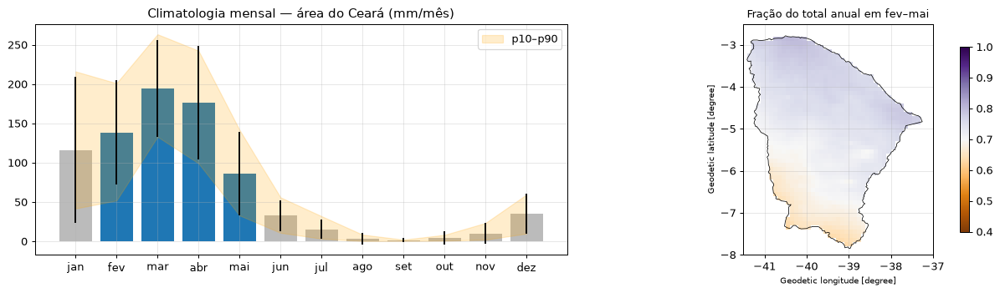

In [21]:
mens_ce = serie_ce.resample("MS").sum()
mens_ce = mens_ce[mens_ce.index < "2026-09-01"]
clim = mens_ce.groupby(mens_ce.index.month).agg(["mean", "std", lambda x: x.quantile(0.1), lambda x: x.quantile(0.9)])
clim.columns = ["media", "dp", "p10", "p90"]
clim.index = MESES
print(clim.round(1).to_string())
print(f"fração do total anual em fev–mai: {clim.loc[['fev','mar','abr','mai'],'media'].sum()/clim['media'].sum():.1%}")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(MESES, clim.media, yerr=clim.dp, color=["#1f77b4" if m in ("fev", "mar", "abr", "mai") else "#bbb" for m in MESES])
ax[0].fill_between(range(12), clim.p10, clim.p90, alpha=0.2, color="orange", label="p10–p90")
ax[0].set_title("Climatologia mensal — área do Ceará (mm/mês)")
ax[0].legend()
mapa(ax[1], ce.sel(time=ce.time.dt.month.isin([2, 3, 4, 5])).groupby("time.year").sum().mean("year").where(M_CE)
     / anual_ce.mean("time").where(M_CE), "Fração do total anual em fev–mai", "PuOr", vmin=0.4, vmax=1)
plt.tight_layout()
plt.show()

In [22]:
# Início/fim da estação chuvosa (Liebmann & Marengo 2001: acumulado de anomalias no ano hidrológico ago–jul)
media_diaria = serie_ce.mean()
reg = []
for ano in range(1998, 2026):
    s = serie_ce[f"{ano}-08-01":f"{ano+1}-07-31"]
    if len(s) < 360:
        continue
    A = (s - media_diaria).cumsum()
    ini = A[: f"{ano+1}-04-30"].idxmin()        # inicio: minimo do acumulado ate o fim de abril
    fim = A[ini:].idxmax()                      # fim: maximo do acumulado depois do inicio
    if fim <= ini:
        continue
    reg.append({"ano_hidro": f"{ano}/{ano+1}", "inicio": ini, "fim": fim, "duracao_dias": (fim - ini).days,
                "total_estacao_mm": s[ini:fim].sum()})
est = pd.DataFrame(reg)
est["inicio_doy"] = est.inicio.dt.dayofyear.where(est.inicio.dt.month < 8, est.inicio.dt.dayofyear - 365)
print(est[["ano_hidro", "inicio", "fim", "duracao_dias", "total_estacao_mm"]].to_string(index=False))
print(f"\ninício médio: dia {est.inicio_doy.mean():.0f} do ano (dp {est.inicio_doy.std():.0f} dias) | duração média {est.duracao_dias.mean():.0f} dias")
r = stats.spearmanr(est.inicio_doy, est.total_estacao_mm)
print(f"correlação (Spearman) início × total da estação: {r.statistic:.2f} (p={r.pvalue:.3f})")

ano_hidro     inicio        fim  duracao_dias  total_estacao_mm
1998/1999 1999-01-06 1999-05-23           137        748.021118
1999/2000 1999-12-19 2000-05-18           151        898.801941
2000/2001 2001-01-30 2001-05-01            91        510.949066
2001/2002 2001-12-27 2002-05-13           137        877.161865
2002/2003 2003-01-18 2003-05-05           107        855.178711
2003/2004 2004-01-08 2004-05-05           118       1001.627441
2004/2005 2005-01-14 2005-05-24           130        554.187866
2005/2006 2006-02-10 2006-05-15            94        720.801270
2006/2007 2007-01-30 2007-05-06            96        626.987610
2007/2008 2008-01-14 2008-05-15           122        935.095154
2008/2009 2009-01-15 2009-06-11           147       1284.145874
2009/2010 2010-03-18 2010-05-05            48        315.069733
2010/2011 2010-12-08 2011-05-20           163       1076.844971
2011/2012 2012-02-09 2012-04-21            72        333.495972
2012/2013 2013-02-13 2013-05-25         

## 2.5 Tendências (Mann-Kendall + declive de Sen)

                     série tendência     p  Sen/ano  Sen/década_%média
   total anual (1998–2025)  no trend 0.418    -3.03               -3.7
quadra fev–mai (1998–2026)  no trend 0.639    -2.12               -3.6
        duração da estação  no trend 0.812     0.18                1.5
   início da estação (dia)  no trend 0.905     0.03                1.7


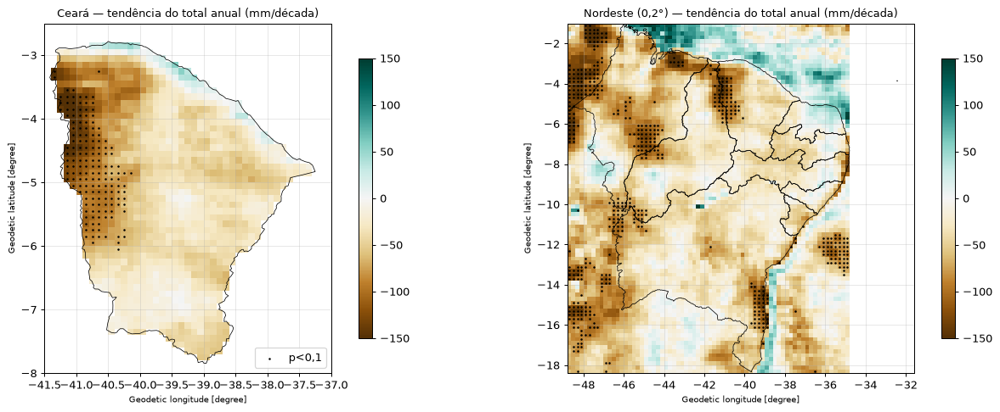

pixels do Ceará com tendência significativa (p<0,1): 13.0%
células do NE com tendência significativa (p<0,1): 7.9%


In [23]:
quadra_ce = serie_ce[serie_ce.index.month.isin([2, 3, 4, 5])].resample("YS").sum()
quadra_ce.index = quadra_ce.index.year
dias_chuva = (ce_m >= 1).where(M_CE).sum("time")
res = []
for nome, s in [("total anual (1998–2025)", serie_anual), ("quadra fev–mai (1998–2026)", quadra_ce),
                ("duração da estação", est.set_index("ano_hidro").duracao_dias),
                ("início da estação (dia)", est.set_index("ano_hidro").inicio_doy)]:
    t = mk.original_test(s.values)
    res.append({"série": nome, "tendência": t.trend, "p": round(t.p, 3), "Sen/ano": round(t.slope, 2),
                "Sen/década_%média": round(10 * t.slope / s.mean() * 100, 1)})
print(pd.DataFrame(res).to_string(index=False))


def sen_mk_grade(cubo):
    """cubo (ano, lat, lon) -> declive de Sen e p-valor por pixel."""
    sl = np.full(cubo.shape[1:], np.nan)
    pv = np.full(cubo.shape[1:], np.nan)
    arr = cubo.values
    for i in range(arr.shape[1]):
        for j in range(arr.shape[2]):
            y = arr[:, i, j]
            if np.isfinite(y).sum() > 10:
                t = mk.original_test(y)
                sl[i, j], pv[i, j] = t.slope, t.p
    return (xr.DataArray(sl, coords={"lat": cubo.lat, "lon": cubo.lon}, dims=("lat", "lon")),
            xr.DataArray(pv, coords={"lat": cubo.lat, "lon": cubo.lon}, dims=("lat", "lon")))


sl_ce, p_ce = sen_mk_grade(anual_ce.where(M_CE))
ne_c = anual_ne.coarsen(lat=2, lon=2, boundary="trim").mean()
sl_ne, p_ne = sen_mk_grade(ne_c)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
mapa(ax[0], (sl_ce * 10).where(M_CE), "Ceará — tendência do total anual (mm/década)", "BrBG", vmin=-150, vmax=150)
yy, xx = np.where((p_ce < 0.1).values & M_CE.values)
ax[0].scatter(ce.lon.values[xx], ce.lat.values[yy], s=1, c="k", label="p<0,1")
ax[0].legend(loc="lower right")
mapa(ax[1], sl_ne * 10, "Nordeste (0,2°) — tendência do total anual (mm/década)", "BrBG", gdf=ne_gdf, vmin=-150, vmax=150)
yy, xx = np.where((p_ne < 0.1).values)
ax[1].scatter(ne_c.lon.values[xx], ne_c.lat.values[yy], s=1, c="k")
plt.tight_layout()
plt.show()
print(f"pixels do Ceará com tendência significativa (p<0,1): {float(((p_ce < 0.1) & M_CE).sum() / M_CE.sum()):.1%}")
print(f"células do NE com tendência significativa (p<0,1): {float((p_ne < 0.1).sum() / np.isfinite(p_ne).sum()):.1%}")

## 2.6 Variabilidade interanual, seca 2012–2017 e extremos

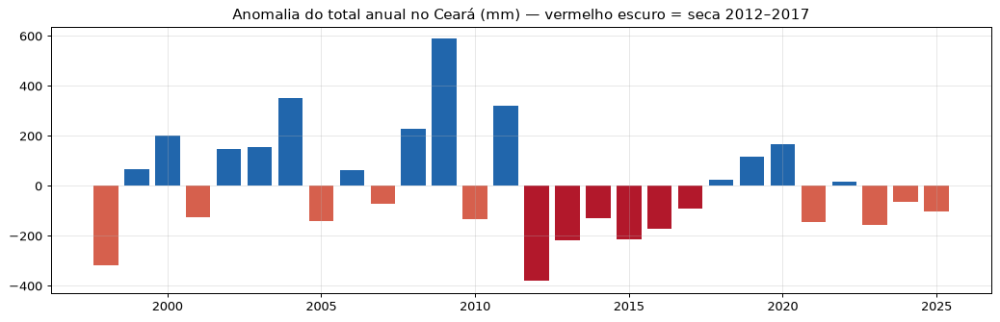

seca 2012–2017: média 612 mm vs normal 867 mm (-29%); 6 anos seguidos abaixo da média: True
anos mais secos: {2012: 432.0, 1998: 496.0, 2013: 595.0, 2015: 597.0}
anos mais chuvosos: {2009: 1402.0, 2004: 1164.0, 2011: 1132.0, 2008: 1040.0}


In [24]:
anom = (serie_anual - serie_anual.mean()) / serie_anual.std()
fig, ax = plt.subplots(figsize=(14, 4))
cores = ["#b2182b" if 2012 <= a <= 2017 else ("#d6604d" if z < 0 else "#2166ac") for a, z in anom.items()]
ax.bar(anom.index, serie_anual - serie_anual.mean(), color=cores)
ax.set_title("Anomalia do total anual no Ceará (mm) — vermelho escuro = seca 2012–2017")
plt.show()
seca = serie_anual.loc[2012:2017]
print(f"seca 2012–2017: média {seca.mean():.0f} mm vs normal {serie_anual.drop(range(2012, 2018)).mean():.0f} mm "
      f"({seca.mean()/serie_anual.drop(range(2012, 2018)).mean()-1:+.0%}); 6 anos seguidos abaixo da média: "
      f"{(seca < serie_anual.mean()).all()}")
print("anos mais secos:", serie_anual.nsmallest(4).round(0).to_dict())
print("anos mais chuvosos:", serie_anual.nlargest(4).round(0).to_dict())

Índices na MÉDIA do Ceará (a média espacial suaviza extremos; ver mapas por pixel abaixo):
         Rx1day  Rx5day  dias>20mm  dias>50mm  CDD_quadra  veranicos≥10d  veranicos≥5d
ano                                                                                   
1998  27.500000    56.4          1          0          11              2             6
1999  32.599998    88.9          4          0           3              0             0
2000  33.700001   100.1          6          0          11              1             1
2001  26.200001    70.2          3          0          14              1             3
2002  34.900002   104.5          9          0          15              1             2
2003  37.400002   104.1          6          0           7              0             2
2004  50.400002   165.5         14          1           6              0             2
2005  24.400000    93.4          4          0           9              0             1
2006  30.100000    89.5          5     

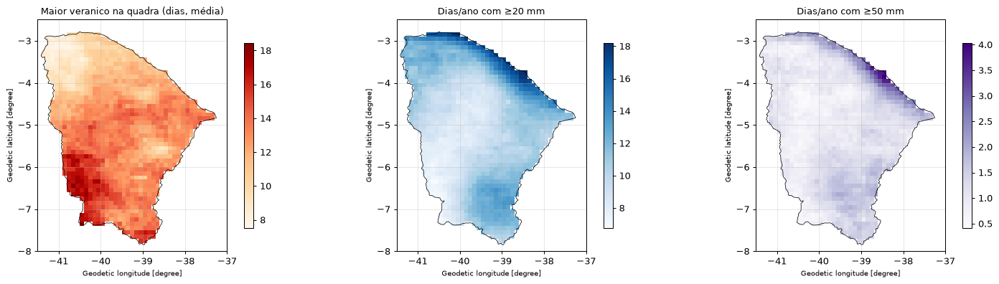

maior veranico médio na quadra (pixel): 12.7 dias; na seca 2012: 22.6; no chuvoso 2009: 6.9


In [25]:
# Índices de extremos por pixel (ETCCDI simplificados) e veranicos na quadra
def maior_seq(b):
    m = c = 0
    for x in b:
        c = c + 1 if x else 0
        m = max(m, c)
    return m


def veranicos(serie_quadra, limiar=1.0, minimo=10):
    seca = serie_quadra < limiar
    n = c = 0
    for x in seca:
        if x:
            c += 1
        else:
            if c >= minimo:
                n += 1
            c = 0
    return n + (1 if c >= minimo else 0)


ind = []
for ano in range(1998, 2027):
    s = serie_ce[str(ano)]
    q = s[s.index.month.isin([2, 3, 4, 5])]
    ind.append({"ano": ano, "Rx1day": s.max(), "Rx5day": s.rolling(5).sum().max(),
                "dias>20mm": int((s >= 20).sum()), "dias>50mm": int((s >= 50).sum()),
                "CDD_quadra": maior_seq(q < 1), "veranicos≥10d": veranicos(q, 1, 10), "veranicos≥5d": veranicos(q, 1, 5)})
ind = pd.DataFrame(ind).set_index("ano")
print("Índices na MÉDIA do Ceará (a média espacial suaviza extremos; ver mapas por pixel abaixo):")
print(ind.round(1).to_string())

# por pixel: maior veranico da quadra (média dos anos) e frequência de dias > 20/50 mm
qd = ce.sel(time=ce.time.dt.month.isin([2, 3, 4, 5]))
cdd = []
for ano in range(1998, 2027):
    b = (qd.sel(time=str(ano)) < 1).values
    run = np.zeros(b.shape[1:])
    mx = np.zeros(b.shape[1:])
    for t in range(b.shape[0]):
        run = np.where(b[t], run + 1, 0)
        mx = np.maximum(mx, run)
    cdd.append(mx)
cdd = xr.DataArray(np.array(cdd), dims=("ano", "lat", "lon"), coords={"ano": range(1998, 2027), "lat": ce.lat, "lon": ce.lon})
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
mapa(ax[0], cdd.mean("ano").where(M_CE), "Maior veranico na quadra (dias, média)", "OrRd")
mapa(ax[1], ((ce >= 20).sum("time") / len(np.unique(ce.time.dt.year))).where(M_CE), "Dias/ano com ≥20 mm", "Blues")
mapa(ax[2], ((ce >= 50).sum("time") / len(np.unique(ce.time.dt.year))).where(M_CE), "Dias/ano com ≥50 mm", "Purples")
plt.tight_layout()
plt.show()
print(f"maior veranico médio na quadra (pixel): {float(cdd.mean('ano').where(M_CE).mean()):.1f} dias; "
      f"na seca 2012: {float(cdd.sel(ano=2012).where(M_CE).mean()):.1f}; no chuvoso 2009: {float(cdd.sel(ano=2009).where(M_CE).mean()):.1f}")

Rx1day mediano entre pixels — níveis de retorno (mm): {2: np.float64(55.4), 5: np.float64(64.4), 10: np.float64(70.4), 25: np.float64(78.0)}


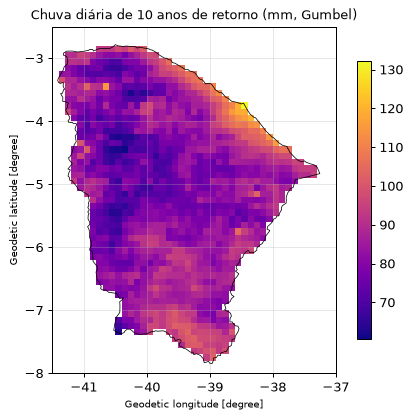

In [26]:
# Período de retorno do máximo diário (Gumbel) — média dos pixels do Ceará e mapa do evento de 10 anos
amax = ce.sel(time=ce.time.dt.year.isin(range(1998, 2026))).groupby("time.year").max()
loc, esc = stats.gumbel_r.fit(amax.where(M_CE).stack(p=("lat", "lon")).dropna("p").median("p").values)
print("Rx1day mediano entre pixels — níveis de retorno (mm):",
      {T: round(stats.gumbel_r.ppf(1 - 1 / T, loc, esc), 1) for T in (2, 5, 10, 25)})
a = amax.values
mu = np.nanmean(a, 0)
sd = np.nanstd(a, 0)
# método dos momentos (rápido por pixel)
beta = sd * np.sqrt(6) / np.pi
mu_g = mu - 0.5772 * beta
r10 = mu_g - beta * np.log(-np.log(1 - 1 / 10))
fig, ax = plt.subplots(figsize=(6, 5))
mapa(ax, xr.DataArray(r10, coords={"lat": ce.lat, "lon": ce.lon}, dims=("lat", "lon")).where(M_CE),
     "Chuva diária de 10 anos de retorno (mm, Gumbel)", "plasma")
plt.show()

## 2.7 Erosividade da chuva (fator R da USLE/RUSLE)
Duas estimativas:
1. **Mensal (toda a série):** equação de Lombardi Neto & Moldenhauer (1992),
   $EI_{30} = 67{,}355\,(r^2/P)^{0,85}$, com $r$ = chuva do mês e $P$ = chuva anual
   (MJ·mm·ha⁻¹·h⁻¹; equação de Campinas/SP, que precisa de validação no semiárido).
2. **Por evento (amostra meia-hora V06):** energia cinética de Brown & Foster (1987),
   $e = 0{,}29[1-0{,}72e^{-0{,}05i}]$, vezes a intensidade máxima em 30 min ($I_{30}$).

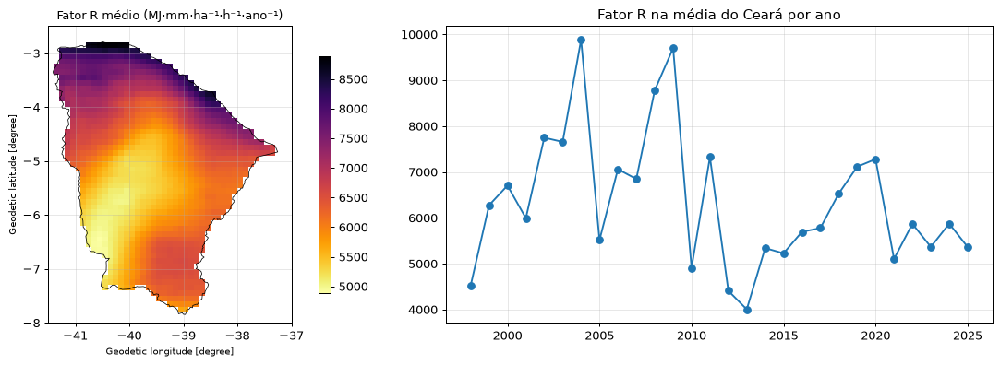

R médio no Ceará: 6353 (faixa entre anos 4005–9884); correlação com o total anual: 0.92


In [27]:
mens_px = ce.resample(time="MS").sum()
anual_px = mens_px.groupby("time.year").sum()
eir = []
for ano in range(1998, 2026):
    r = mens_px.sel(time=str(ano))
    P = anual_px.sel(year=ano)
    eir.append((67.355 * (r ** 2 / P) ** 0.85).sum("time"))
R = xr.concat(eir, "ano").assign_coords(ano=range(1998, 2026))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
mapa(ax[0], R.mean("ano").where(M_CE), "Fator R médio (MJ·mm·ha⁻¹·h⁻¹·ano⁻¹)", "inferno_r")
Rs = R.where(M_CE).mean(("lat", "lon")).to_series()
ax[1].plot(Rs.index, Rs.values, "o-")
ax[1].set_title("Fator R na média do Ceará por ano")
plt.tight_layout()
plt.show()
print(f"R médio no Ceará: {Rs.mean():.0f} (faixa entre anos {Rs.min():.0f}–{Rs.max():.0f}); "
      f"correlação com o total anual: {np.corrcoef(Rs.values, serie_anual.loc[1998:2025].values)[0,1]:.2f}")

## 2.8 Ciclo diurno e intensidade de 30 min (amostra nativa V06, horário local UTC−3)

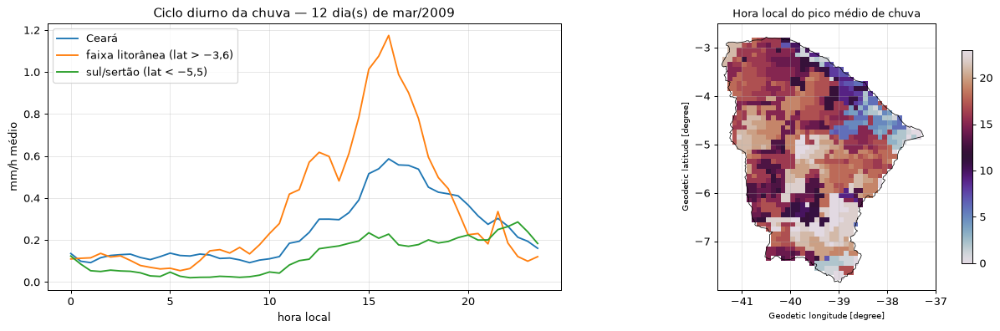

Ceará: pico às 16.0 h local, mínimo às 9.0 h; razão pico/média 2.4
litoral: pico às 16.0 h local, mínimo às 5.5 h; razão pico/média 3.4
sul/sertão: pico às 22.5 h local, mínimo às 6.0 h; razão pico/média 2.3
I30 máximo na amostra: 80 mm/h | EI30 diário máx: 2476 MJ·mm·ha⁻¹·h⁻¹
fração da chuva caída com intensidade > 25 mm/h: 5.6%


In [28]:
if pc_arqs:
    hh = xr.open_mfdataset(pc_arqs, combine="by_coords")["precip_ne"].load()  # (time, lon, lat) mm/h
    hh = hh.transpose("time", "lat", "lon").sel(lon=slice(BBOX_CE[0], BBOX_CE[2]), lat=slice(BBOX_CE[1], BBOX_CE[3]))
    hh = hh.assign_coords(time=hh.time - np.timedelta64(3, "h"))
    Mh = xr.DataArray(mascara(ce_gdf.geometry.union_all(), hh.lon.values, hh.lat.values), dims=("lat", "lon"))
    hora = hh.time.dt.hour + hh.time.dt.minute / 60
    ciclo = hh.where(Mh).groupby(hora).mean().mean(("lat", "lon"))
    costa = hh.where(Mh & (hh.lat > -3.6)).groupby(hora).mean().mean(("lat", "lon"))
    interior = hh.where(Mh & (hh.lat < -5.5)).groupby(hora).mean().mean(("lat", "lon"))
    pico = hh.groupby(hh.time.dt.hour).mean().idxmax("hour")
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    ax[0].plot(ciclo.group, ciclo, label="Ceará")
    ax[0].plot(costa.group, costa, label="faixa litorânea (lat > −3,6)")
    ax[0].plot(interior.group, interior, label="sul/sertão (lat < −5,5)")
    ax[0].set_xlabel("hora local")
    ax[0].set_ylabel("mm/h médio")
    ax[0].set_title(f"Ciclo diurno da chuva — {len(pc_arqs)} dia(s) de mar/2009")
    ax[0].legend()
    mapa(ax[1], pico.where(Mh), "Hora local do pico médio de chuva", "twilight")
    plt.tight_layout()
    plt.show()
    for nome, c in [("Ceará", ciclo), ("litoral", costa), ("sul/sertão", interior)]:
        print(f"{nome}: pico às {float(c.idxmax()):.1f} h local, mínimo às {float(c.idxmin()):.1f} h; "
              f"razão pico/média {float(c.max() / c.mean()):.1f}")
    # erosividade por evento diário (I30 = maior intensidade em 30 min; energia Brown & Foster)
    e_unit = 0.29 * (1 - 0.72 * np.exp(-0.05 * hh))  # MJ/ha/mm
    energia = (e_unit * hh * 0.5).resample(time="D").sum()  # MJ/ha
    i30 = hh.resample(time="D").max()
    ei30 = (energia * i30).where(Mh)
    tot = (hh * 0.5).resample(time="D").sum().where(Mh)
    print(f"I30 máximo na amostra: {float(i30.where(Mh).max()):.0f} mm/h | EI30 diário máx: {float(ei30.max()):.0f} MJ·mm·ha⁻¹·h⁻¹")
    print(f"fração da chuva caída com intensidade > 25 mm/h: "
          f"{float((hh.where(hh > 25) * 0.5).where(Mh).sum() / (hh * 0.5).where(Mh).sum()):.1%}")
else:
    print("amostra meia-hora ainda não baixada")

## 2.9 Coerência entre versões: V07 diário (POWER) × V06 meia-hora (Planetary Computer)

In [29]:
if pc_arqs:
    v06 = (hh.assign_coords(time=hh.time + np.timedelta64(3, "h")) * 0.5).resample(time="D").sum()
    comum_t = np.intersect1d(v06.time.values, ce.time.values)
    a6 = v06.sel(time=comum_t).interp(lat=ce.lat, lon=ce.lon, method="nearest").where(M_CE)
    a7 = ce.sel(time=comum_t).where(M_CE)
    x, y = a6.values.ravel(), a7.values.ravel()
    ok = np.isfinite(x) & np.isfinite(y)
    print(f"dias comparados: {len(comum_t)} | pixel-dias: {ok.sum()} | r de Pearson {np.corrcoef(x[ok], y[ok])[0,1]:.2f} | "
          f"viés V07−V06: {np.mean(y[ok]-x[ok]):+.2f} mm/dia ({np.mean(y[ok])/np.mean(x[ok])-1:+.0%})")

dias comparados: 12 | pixel-dias: 14544 | r de Pearson 0.80 | viés V07−V06: +0.63 mm/dia (+11%)


## 2.10 Insights e ideias para o produto
(números medidos nas células acima; IMERG V07 diário 1998–2026 e amostra V06 meia-hora de mar/2009)

1. **Chuva concentrada = risco concentrado.** 73 % da chuva anual do Ceará cai em fev–mai, com média de
   812 mm/ano (1998–2025) e CV interanual de 27 % na média estadual (maior no sertão, ver mapa). O calendário do
   produto deve trabalhar com probabilidades (p10/p90 por mês), não com médias.
2. **O dia de início da estação prevê a estação.** Pelo acumulado de anomalias (Liebmann & Marengo), o início
   médio é ~17/jan (dp 22 dias) e tem correlação de Spearman **−0,67** com o total da estação. Inícios tardios
   (mar/2010, fev/2012) vieram com estações de 48–72 dias e ~330 mm. Regra de decisão para o produto: se até
   meados de fevereiro a estação não "abriu", trocar para a rotação de ciclo curto / tolerante à seca.
3. **Seca 2012–2017: seis anos seguidos abaixo da média**, com média de 612 mm contra 867 mm nos demais anos (−29 %).
   2012 (432 mm) foi o pior ano da série. Justifica um módulo de "rotação de emergência" (sorgo, palma
   forrageira, caupi precoce, milheto).
4. **Veranicos.** O maior período seco dentro da quadra tem em média 12,7 dias por pixel; foram 22,6 dias em 2012
   contra 6,9 em 2009. Culturas com fase crítica (floração/enchimento) de mais de 2 semanas sem chuva correm
   risco alto em boa parte do sertão.
5. **Sem tendência robusta de chuva em 28 anos** (−3,7 %/década, p = 0,42; só 13 % dos pixels com p < 0,1). A
   variabilidade interanual domina a tendência; o risco vem da variabilidade, não de um secamento linear.
6. **Erosividade alta e concentrada.** O fator R médio é ~6.350 MJ·mm·ha⁻¹·h⁻¹·ano⁻¹ (4.000–9.900 entre anos),
   com correlação 0,92 com o total anual. Na amostra de 30 min há I30 de até 80 mm/h, e 5,7 % da chuva cai acima
   de 25 mm/h. A chuva de 10 anos de retorno é ~70 mm/dia (mediana dos pixels). Solo descoberto no início da
   quadra é o pior cenário, o que dá argumento para cobertura morta e plantas de cobertura (cruzar com NDVI de
   solo exposto e declividade do SRTM).
7. **Ciclo diurno muda entre litoral e interior:** pico às 16 h no litoral (convecção de brisa) e às 22h30 no sul
   do estado (sistemas noturnos). Isso orienta a janela de pulverização, de fenação e de colheita.
8. **Limitação crítica: o IMERG fica muito abaixo das normais no litoral leste do NE** (Recife, Maceió, Aracaju,
   Salvador ≈ 41–60 % das normais aproximadas; parte pode ser efeito de pixel misto terra/mar), mas é bom no
   sertão (82–94 %). Para a demo no sertão do Ceará ele serve. No produto mundial, cada pixel precisa de um selo
   de confiança e de correção por pluviômetros onde houver.
9. **Coerência entre versões:** V07 (POWER) × V06 (Planetary Computer) nos mesmos dias: r = 0,80; a V07 tem +10 %.

**Ideias de ML/DL a partir desta base**
- **Previsão sazonal da quadra** com índices oceânicos (Niño 3.4, gradiente do Atlântico tropical) + o próprio
  início da estação: gradient boosting / regressão quantílica → probabilidade de ano seco, normal ou chuvoso por município.
- **Modelo de sobrevivência para veranicos** (Weibull / Cox, covariáveis: ENSO, altitude, mês) → risco de
  veranico ≥ 15 dias na floração de cada cultura candidata. Entra direto na pontuação das rotações.
- **Correção de viés costeiro**: regressão espacial (GWR / random forest com distância ao mar, altitude e vento)
  treinada com pluviômetros INMET/ANA/FUNCEME → IMERG corrigido; avaliar com validação cruzada espacial.
- **Nowcasting 0–6 h** (ConvLSTM / U-Net temporal) com o IMERG de meia hora (Early, latência ~4 h) para alertas de
  chuva forte em colheita e aplicação de defensivos.
- **Downscaling 0,1° → 1 km** com SRTM e NDVI como covariáveis (U-Net/SRCNN), para chegar à escala do talhão.

# 3. ERA5 — reanálise climática (ECMWF / Copernicus, parceiro ESA)

**Ficha técnica**

| Item | Valor |
|---|---|
| Produto | ERA5, 5ª reanálise do ECMWF: modelo IFS + assimilação 4D-Var de satélites, radiossondas, estações e boias |
| Resolução | 0,25° (~28 km), horária, 1940→presente (latência ~5 dias no CDS) |
| Período baixado | **1979–2020** (o que o espelho aberto `era5-pds` do Planetary Computer oferece; 2021+ só pelo CDS, que exige chave) |
| Variáveis baixadas (horárias → diárias, dia local UTC−3) | T2m média; Tmax/Tmin (máx/mín horárias da previsão); ponto de orvalho; precipitação; radiação solar descendente (ssrd); vento a 10 m (u, v) |
| Derivadas (calculadas aqui) | ET0 FAO-56 Penman-Monteith, VPD, umidade relativa, graus-dia base 10 °C, dias com Tmax ≥ 35 °C, déficit P − ET0 |
| Recorte | Nordeste (−48,8 a −34,7 lon; −18,4 a −1,0 lat; 70×57 pixels). O Nordeste inteiro cai num único bloco Zarr (372 h × 150 × 150), então o custo é ~11 MB por mês por variável |
| Licença | Copernicus (uso livre com atribuição) |

In [30]:
import sys, warnings
sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
from comum import *  # noqa
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import shapely
import pymannkendall as mk
from scipy import stats

warnings.filterwarnings("ignore")
try:
    sys.stdout.reconfigure(encoding="utf-8")
except Exception:
    pass
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
DIR = DADOS / "era5"
ce_gdf, ne_gdf, terra = ceara_gdf(), nordeste_gdf(), terra_gdf()
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]


def mascara(geom, lon, lat):
    lo, la = np.meshgrid(lon, lat)
    return xr.DataArray(shapely.contains_xy(geom, lo, la), dims=("lat", "lon"))


def mapa(ax, da, titulo, cmap="viridis", gdf=None, **kw):
    m = ax.pcolormesh(da.lon, da.lat, da, cmap=cmap, shading="auto", **kw)
    (gdf if gdf is not None else ne_gdf).boundary.plot(ax=ax, color="k", lw=0.5)
    ax.set_title(titulo, fontsize=10)
    ax.set_aspect("equal")
    plt.colorbar(m, ax=ax, shrink=0.8)


grade = xr.open_dataset(DIR / "era5_ne_mensal_grade.nc").load().sortby("lat")
M_NE = mascara(ne_gdf.geometry.union_all(), grade.lon.values, grade.lat.values)
M_CEg = mascara(ce_gdf.geometry.union_all(), grade.lon.values, grade.lat.values)
# diario so do Ceara (com folga) para estatisticas diarias
arqs = sorted(DIR.glob("era5_ne_diario_*.nc"))
d_ce = xr.open_mfdataset(arqs, combine="by_coords")[["t2m", "tmax", "tmin", "d2m", "tp", "ssrd", "ws10", "ws10_max"]] \
    .sel(lon=slice(BBOX_CE[0], BBOX_CE[2]), lat=slice(BBOX_CE[3], BBOX_CE[1])).load().sortby("lat")
der = xr.open_dataset(DIR / "era5_ne_derivados_diario.nc").sel(lon=slice(BBOX_CE[0], BBOX_CE[2]),
                                                                lat=slice(BBOX_CE[1], BBOX_CE[3])).load()
d_ce = xr.merge([d_ce, der])
M_CE = mascara(ce_gdf.geometry.union_all(), d_ce.lon.values, d_ce.lat.values)
s_ce = d_ce.where(M_CE).mean(("lat", "lon")).to_dataframe().drop(columns=["n_horas_an", "n_horas_fc"], errors="ignore")
print("diário Ceará:", dict(d_ce.sizes), "| pixels no Ceará:", int(M_CE.sum()), "| período",
      str(d_ce.data.values[0])[:10], "→", str(d_ce.data.values[-1])[:10])

diário Ceará: {'data': 15339, 'lat': 23, 'lon': 19} | pixels no Ceará: 194 | período 1979-01-02 → 2020-12-30


## 3.1 Validação de cobertura global
Evidência: um mês inteiro (jan/2020) do planeta, t2m médio e precipitação total, lido do mesmo espelho.

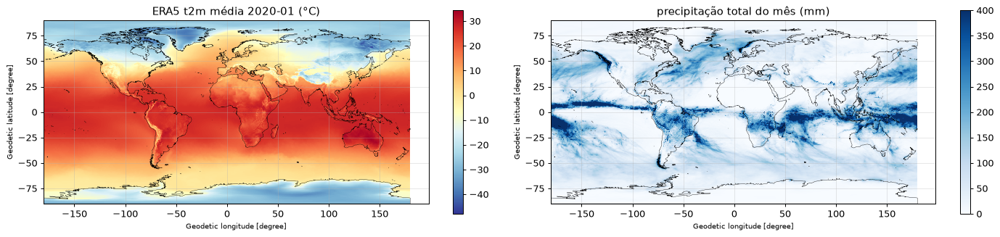

fração de valores ausentes no globo (t2m horário): 0.0 | grade: {'lat': 721, 'lon': 1440} | lat -90.0 a 90.0


In [31]:
gl_arq = sorted(DIR.glob("era5_global_*.nc"))
if gl_arq:
    gl = xr.open_dataset(gl_arq[0]).load()
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.2))
    m = ax[0].pcolormesh(gl.lon, gl.lat, gl.t2m_media, cmap="RdYlBu_r", shading="auto")
    plt.colorbar(m, ax=ax[0], shrink=0.8)
    ax[0].set_title(f"ERA5 t2m média {gl.attrs.get('mes')} (°C)")
    m = ax[1].pcolormesh(gl.lon, gl.lat, gl.tp_total_mm, cmap="Blues", vmax=400, shading="auto")
    plt.colorbar(m, ax=ax[1], shrink=0.8)
    ax[1].set_title("precipitação total do mês (mm)")
    for a in ax:
        terra.boundary.plot(ax=a, color="k", lw=0.3)
    plt.tight_layout()
    plt.show()
    print("fração de valores ausentes no globo (t2m horário):", float(gl.t2m_nan_frac.mean()),
          "| grade:", dict(gl.sizes), "| lat", float(gl.lat.min()), "a", float(gl.lat.max()))
else:
    print("arquivo global ainda não baixado")

**Veredito de cobertura.** O ERA5 é **global e sem lacunas por construção**: é um modelo físico com
assimilação de dados, com valor em toda célula de 0,25° de 90°S a 90°N, terra e oceano, a cada hora desde 1940.
Ele preenche os lugares sem estação meteorológica, o que é exatamente o caso de grande parte do sertão. O preço é
a resolução (~28 km): não enxerga microclima de baixada ou serra (ver Ibiapaba) e herda vieses do modelo na
frequência e intensidade da chuva (ver 3.7). **Serve de camada climática mundial de base**, com correção de viés
local quando houver estação ou IMERG.

## 3.2 Qualidade: ausentes, consistência física e outliers

In [32]:
dias = pd.date_range(s_ce.index.min(), s_ce.index.max(), freq="D")
print(f"dias esperados {len(dias)} | presentes {len(s_ce)} | buracos {len(dias.difference(s_ce.index))}")
vals = d_ce.where(M_CE)
print("ausentes por variável (%):", {v: round(float(vals[v].isnull().where(M_CE).mean() * 100), 3)
                                     for v in ["t2m", "tmax", "tmin", "d2m", "tp", "ssrd", "ws10"]})
chk = {
    "tmax < tmin": int((vals.tmax < vals.tmin).sum()),
    "t2m fora de [tmin, tmax] (>0,5 °C)": int(((vals.t2m < vals.tmin - 0.5) | (vals.t2m > vals.tmax + 0.5)).sum()),
    "orvalho > t2m": int((vals.d2m > vals.t2m + 0.1).sum()),
    "precipitação negativa": int((vals.tp < 0).sum()),
    "ssrd > 35 MJ/m²/dia": int((vals.ssrd > 35).sum()),
    "Tmax > 45 °C": int((vals.tmax > 45).sum()),
    "Tmin < 10 °C": int((vals.tmin < 10).sum()),
}
print("verificações físicas (pixel-dias):", chk)
print(s_ce[["t2m", "tmax", "tmin", "d2m", "tp", "ssrd", "ws10", "et0", "vpd", "ur"]].describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2).to_string())
z = (s_ce[["tmax", "tmin", "ssrd", "ws10"]] - s_ce[["tmax", "tmin", "ssrd", "ws10"]].groupby(s_ce.index.month).transform("mean")) \
    / s_ce[["tmax", "tmin", "ssrd", "ws10"]].groupby(s_ce.index.month).transform("std")
print("dias com |z| > 4 (anomalia extrema vs mês):", (z.abs() > 4).sum().to_dict())

dias esperados 15339 | presentes 15339 | buracos 0


ausentes por variável (%): {'t2m': 0.0, 'tmax': 0.0, 'tmin': 0.0, 'd2m': 0.0, 'tp': 0.0, 'ssrd': 0.0, 'ws10': 0.0}
verificações físicas (pixel-dias): {'tmax < tmin': 0, 't2m fora de [tmin, tmax] (>0,5 °C)': 33, 'orvalho > t2m': 0, 'precipitação negativa': 0, 'ssrd > 35 MJ/m²/dia': 0, 'Tmax > 45 °C': 0, 'Tmin < 10 °C': 0}
            t2m      tmax      tmin       d2m        tp      ssrd      ws10       et0       vpd        ur
count  15339.00  15339.00  15339.00  15339.00  15339.00  15339.00  15339.00  15339.00  15339.00  15339.00
mean      26.97     31.46     22.52     19.73      2.22     20.74      3.50      5.36      1.37     63.90
std        1.26      2.09      0.85      1.99      4.26      3.83      0.97      1.40      0.52     11.71
min       22.63     24.51     19.24     13.48      0.00      4.96      0.98      1.23      0.21     40.86
1%        24.27     27.07     20.45     15.58      0.00     10.76      1.36      2.47      0.43     45.57
5%        24.89     28.10     21.11     1

## 3.3 Estatística descritiva espacial — Nordeste e Ceará

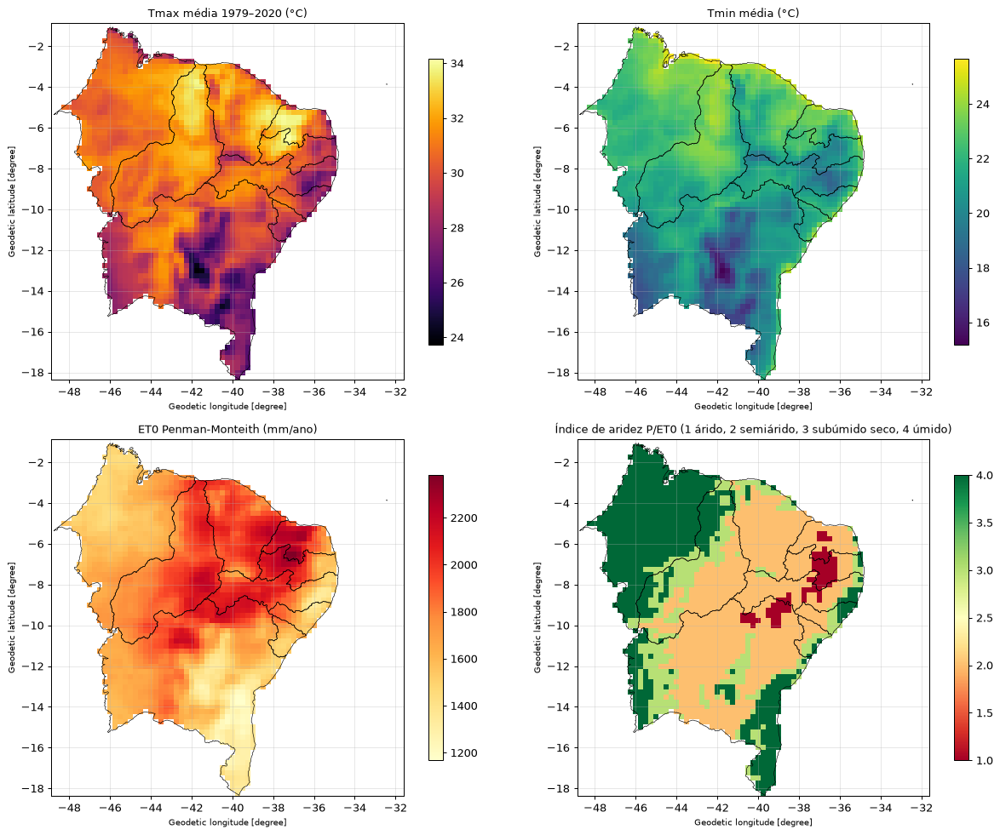

Ceará — fração da área por classe de aridez (UNEP): {'árido': '0%', 'semiárido': '80%', 'subúmido seco': '15%', 'úmido': '4%'}
Nordeste — fração da área por classe de aridez (UNEP): {'árido': '4%', 'semiárido': '45%', 'subúmido seco': '16%', 'úmido': '35%'}
Ceará: P médio 811 mm/ano vs ET0 1959 mm/ano → déficit climático -1148 mm/ano


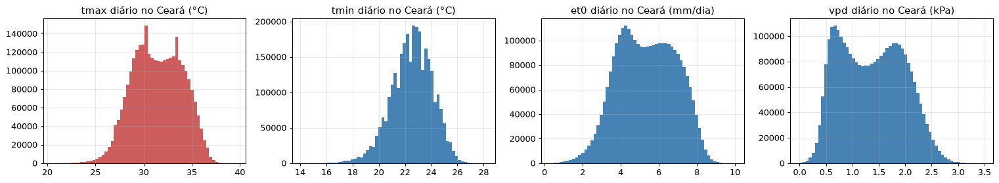

In [33]:
anual = grade.resample(data="YS")
tmax_a = anual.mean()["tmax"].mean("data")
et0_a = anual.sum(min_count=12)["et0"].mean("data")
tp_a = anual.sum(min_count=12)["tp"].mean("data")
ia = (tp_a / et0_a)
fig, ax = plt.subplots(2, 2, figsize=(14, 11))
mapa(ax[0, 0], tmax_a.where(M_NE), "Tmax média 1979–2020 (°C)", "inferno")
mapa(ax[0, 1], grade["tmin"].mean("data").where(M_NE), "Tmin média (°C)", "viridis")
mapa(ax[1, 0], et0_a.where(M_NE), "ET0 Penman-Monteith (mm/ano)", "YlOrRd")
cl = xr.where(ia < 0.2, 1, xr.where(ia < 0.5, 2, xr.where(ia < 0.65, 3, 4))).where(M_NE)
mapa(ax[1, 1], cl, "Índice de aridez P/ET0 (1 árido, 2 semiárido, 3 subúmido seco, 4 úmido)", "RdYlGn", vmin=1, vmax=4)
plt.tight_layout()
plt.show()
for nome, M in [("Ceará", M_CEg), ("Nordeste", M_NE)]:
    frac = {k: float(((cl == v) & M).sum() / M.sum()) for k, v in
            [("árido", 1), ("semiárido", 2), ("subúmido seco", 3), ("úmido", 4)]}
    print(nome, "— fração da área por classe de aridez (UNEP):", {k: f"{x:.0%}" for k, x in frac.items()})
print(f"Ceará: P médio {float(tp_a.where(M_CEg).mean()):.0f} mm/ano vs ET0 {float(et0_a.where(M_CEg).mean()):.0f} mm/ano "
      f"→ déficit climático {float((tp_a - et0_a).where(M_CEg).mean()):.0f} mm/ano")
fig, ax = plt.subplots(1, 4, figsize=(17, 3.2))
for a, v, u in zip(ax, ["tmax", "tmin", "et0", "vpd"], ["°C", "°C", "mm/dia", "kPa"]):
    a.hist(d_ce[v].where(M_CE).values.ravel(), bins=60, color="indianred" if v == "tmax" else "steelblue")
    a.set_title(f"{v} diário no Ceará ({u})")
plt.tight_layout()
plt.show()

## 3.4 Sazonalidade: calor, demanda hídrica e o balanço P − ET0

       t2m   tmax   tmin          tp         et0   vpd   ssrd  ws10     ur
jan  27.20  31.32  22.95  109.410004  156.649994  1.24  20.28  3.09  67.58
fev  26.62  30.48  22.66  140.460007  131.809998  1.01  19.97  2.75  72.58
mar  26.19  29.82  22.54  194.440002  131.089996  0.83  19.01  2.40  76.89
abr  26.03  29.51  22.45  172.389999  118.000000  0.77  17.98  2.36  78.11
mai  26.18  29.86  22.37   84.360001  126.980003  0.93  17.88  2.84  73.70
jun  26.03  30.09  21.93   30.790001  133.240005  1.16  17.78  3.48  67.03
jul  26.15  30.62  21.61   16.719999  157.410004  1.40  18.95  3.96  60.58
ago  26.91  32.05  21.80    5.130000  190.080002  1.70  22.06  4.30  54.36
set  27.68  33.23  22.38    3.440000  205.360001  1.89  24.21  4.44  51.90
out  28.17  33.80  22.90    7.180000  217.880005  1.95  24.77  4.37  52.10
nov  28.31  33.71  23.25    9.240000  202.630005  1.88  23.91  4.21  53.96
dez  28.10  32.92  23.37   37.330002  187.880005  1.67  22.10  3.80  58.65


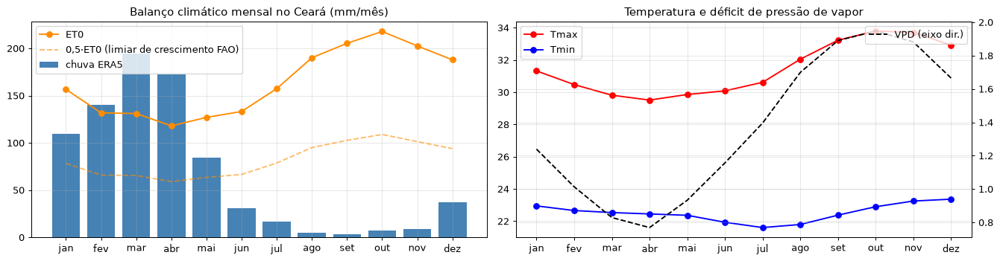

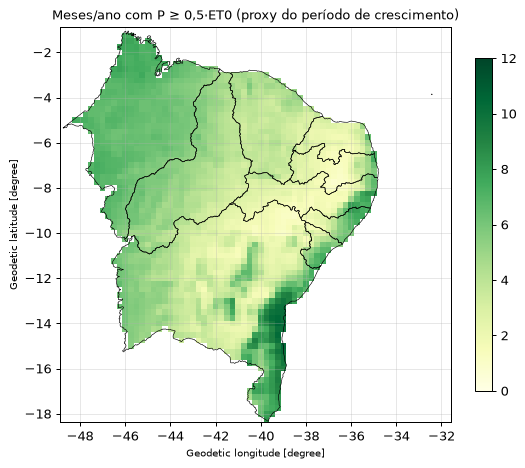

período de crescimento médio no Ceará: 3.9 meses/ano


In [34]:
SOMA = lambda x: x.sum(min_count=1)  # noqa: E731
mm = s_ce.resample("MS").agg({"t2m": "mean", "tmax": "mean", "tmin": "mean", "tp": SOMA, "et0": SOMA, "vpd": "mean",
                               "ssrd": "mean", "ws10": "mean", "ur": "mean"})
clim = mm.groupby(mm.index.month).mean()
clim.index = MESES
print(clim.round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].bar(MESES, clim.tp, color="steelblue", label="chuva ERA5")
ax[0].plot(MESES, clim.et0, "o-", c="darkorange", label="ET0")
ax[0].plot(MESES, 0.5 * clim.et0, "--", c="darkorange", alpha=0.6, label="0,5·ET0 (limiar de crescimento FAO)")
ax[0].set_title("Balanço climático mensal no Ceará (mm/mês)")
ax[0].legend()
ax2 = ax[1].twinx()
ax[1].plot(MESES, clim.tmax, "r-o", label="Tmax")
ax[1].plot(MESES, clim.tmin, "b-o", label="Tmin")
ax2.plot(MESES, clim.vpd, "k--", label="VPD (eixo dir.)")
ax[1].set_title("Temperatura e déficit de pressão de vapor")
ax[1].legend(loc="upper left")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()
# comprimento do periodo de crescimento (proxy mensal): meses com P >= 0,5 ET0
lgp = ((grade.tp >= 0.5 * grade.et0).where(grade.et0.notnull()).groupby("data.year").sum(min_count=12)).mean("year")
fig, ax = plt.subplots(figsize=(7, 6))
mapa(ax, lgp.where(M_NE), "Meses/ano com P ≥ 0,5·ET0 (proxy do período de crescimento)", "YlGn", vmin=0, vmax=12)
plt.show()
print(f"período de crescimento médio no Ceará: {float(lgp.where(M_CEg).mean()):.1f} meses/ano")

## 3.5 Tendências 1979–2020 (Mann-Kendall + Sen)

   variável  tendência      p  Sen/década       média
        t2m increasing 0.0105       0.181   26.970000
       tmax   no trend 0.2248       0.107   31.460000
       tmin increasing 0.0119       0.113   22.520000
         tp   no trend 0.7451     -13.910  810.890015
        et0   no trend 0.6181       6.045 1959.010010
        vpd   no trend 0.9654       0.001    1.370000
       ssrd   no trend 0.7781       0.026   20.740000
       ws10   no trend 0.7125       0.015    3.500000
dias_tmax35 increasing 0.0009       2.000    6.050000


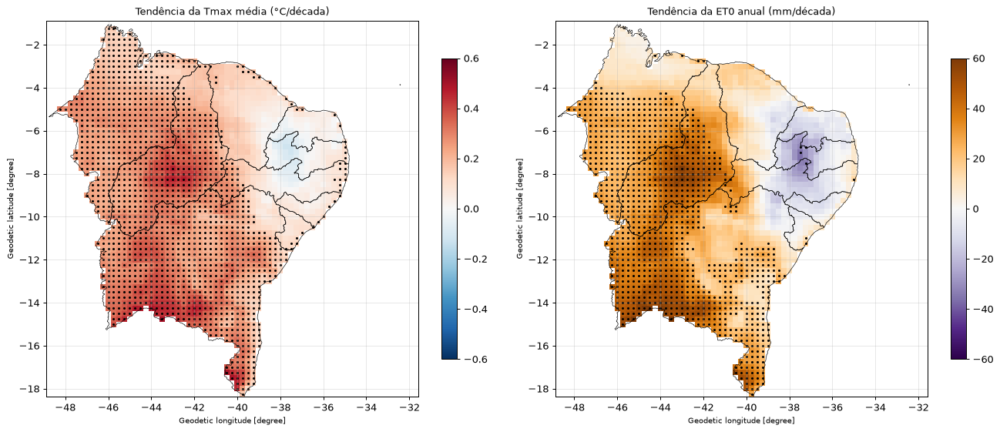

pixels do NE com aquecimento significativo de Tmax (p<0,05): 73%


In [35]:
an = s_ce.resample("YS").agg({"t2m": "mean", "tmax": "mean", "tmin": "mean", "tp": SOMA, "et0": SOMA, "vpd": "mean",
                               "ssrd": "mean", "ws10": "mean"})
an["dias_tmax35"] = (s_ce.tmax >= 35).resample("YS").sum()
an = an[s_ce.tmax.resample("YS").count() >= 360]  # so anos completos
an.index = an.index.year
res = []
for v in an.columns:
    t = mk.original_test(an[v].values)
    res.append({"variável": v, "tendência": t.trend, "p": round(t.p, 4), "Sen/década": round(t.slope * 10, 3),
                "média": round(an[v].mean(), 2)})
print(pd.DataFrame(res).to_string(index=False))


def sen_grade(cubo):
    sl = np.full(cubo.shape[1:], np.nan)
    pv = np.full(cubo.shape[1:], np.nan)
    for i in range(cubo.shape[1]):
        for j in range(cubo.shape[2]):
            y = cubo.values[:, i, j]
            if np.isfinite(y).all():
                t = mk.original_test(y)
                sl[i, j], pv[i, j] = t.slope, t.p
    return (xr.DataArray(sl, coords={"lat": cubo.lat, "lon": cubo.lon}, dims=("lat", "lon")),
            xr.DataArray(pv, coords={"lat": cubo.lat, "lon": cubo.lon}, dims=("lat", "lon")))


s_tx, p_tx = sen_grade(grade.tmax.resample(data="YS").mean())
s_et, p_et = sen_grade(grade.et0.resample(data="YS").sum(min_count=12))
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
mapa(ax[0], (s_tx * 10).where(M_NE), "Tendência da Tmax média (°C/década)", "RdBu_r", vmin=-0.6, vmax=0.6)
yy, xx = np.where((p_tx < 0.05).values & M_NE.values)
ax[0].scatter(grade.lon.values[xx], grade.lat.values[yy], s=2, c="k")
mapa(ax[1], (s_et * 10).where(M_NE), "Tendência da ET0 anual (mm/década)", "PuOr_r", vmin=-60, vmax=60)
yy, xx = np.where((p_et < 0.05).values & M_NE.values)
ax[1].scatter(grade.lon.values[xx], grade.lat.values[yy], s=2, c="k")
plt.tight_layout()
plt.show()
print(f"pixels do NE com aquecimento significativo de Tmax (p<0,05): {float(((p_tx < 0.05) & (s_tx > 0) & M_NE).sum() / M_NE.sum()):.0%}")

## 3.6 Variabilidade interanual, seca 2012–2017 (dentro da janela até 2020) e extremos de calor

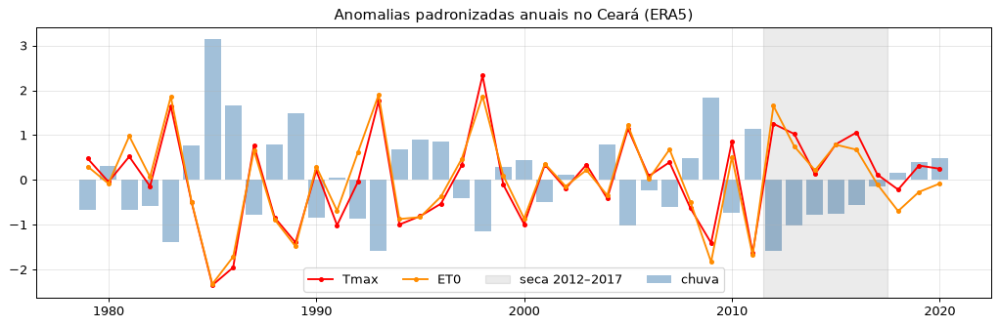

seca 2012–2017 vs demais anos: {'tp': '-261.13', 'tmax': '+0.58', 'et0': '+95.58', 'vpd': '+0.09', 'dias_tmax35': '+1.89'}
Spearman chuva × Tmax anual: -0.88 (p=0.000) — anos secos são também mais quentes (seca composta)
anos com mais dias Tmax≥35 °C: {2019: 28, 2005: 23, 1998: 21, 2020: 17, 2016: 15}
na quadra chuvosa: dias com Tmax≥35 °C por ano = 0.3; na estação seca (ago–dez) = 5.2


In [36]:
z = (an - an.mean()) / an.std()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(z.index, z.tmax, "r-o", ms=3, label="Tmax")
ax.plot(z.index, z.et0, "-o", c="darkorange", ms=3, label="ET0")
ax.bar(z.index, z.tp, color="steelblue", alpha=0.5, label="chuva")
ax.axvspan(2011.5, 2017.5, color="k", alpha=0.08, label="seca 2012–2017")
ax.set_title("Anomalias padronizadas anuais no Ceará (ERA5)")
ax.legend(ncol=4)
plt.show()
sec, fora = an.loc[2012:2017], an.drop(range(2012, 2018))
print("seca 2012–2017 vs demais anos:", {v: f"{sec[v].mean() - fora[v].mean():+.2f}" for v in ["tp", "tmax", "et0", "vpd", "dias_tmax35"]})
r = stats.spearmanr(an.tp, an.tmax)
print(f"Spearman chuva × Tmax anual: {r.statistic:.2f} (p={r.pvalue:.3f}) — anos secos são também mais quentes (seca composta)")
print("anos com mais dias Tmax≥35 °C:", an.dias_tmax35.nlargest(5).to_dict())
q = s_ce[s_ce.index.month.isin([2, 3, 4, 5])]
print(f"na quadra chuvosa: dias com Tmax≥35 °C por ano = {(q.tmax >= 35).groupby(q.index.year).sum().mean():.1f}; "
      f"na estação seca (ago–dez) = {(s_ce.tmax[s_ce.index.month.isin([8,9,10,11,12])] >= 35).groupby(s_ce.index.year[s_ce.index.month.isin([8,9,10,11,12])]).sum().mean():.1f}")

## 3.7 Comparação com outras bases (IMERG e POWER, se presentes)

Chuva mensal no Ceará, 1998-01→2020-12: r=0.985 | ERA5/IMERG = 0.93


frequência de dias com chuva ≥1 mm: ERA5 31.0% vs IMERG 23.5%;  ≥0,1 mm: ERA5 55.0% vs IMERG 36.7%  → ERA5 tem MAIS dias de chuva que o IMERG no Ceará


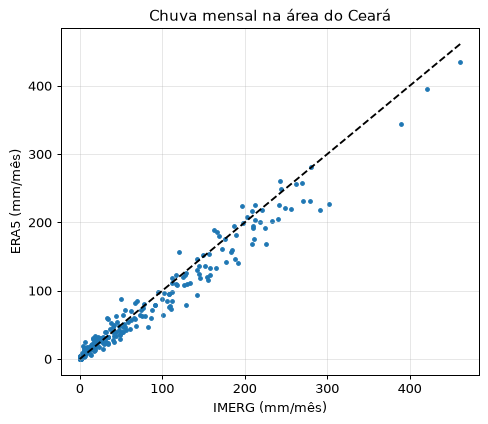


Chuva anual média 1998–2020 em pontos de referência (normais aproximadas, a conferir):
                    ERA5_mm  IMERG_mm  normal_aprox_mm  ERA5/normal  IMERG/normal
local                                                                            
Recife                 1013      1059             2400         0.42          0.44
Maceió                 1335       855             2100         0.64          0.41
Aracaju                1250       768             1600         0.78          0.48
Salvador               1283      1104             2100         0.61          0.53
Fortaleza              1095      1178             1600         0.68          0.74
São Luís               2212      2098             2300         0.96          0.91
Petrolina (sertão)      385       441              550         0.70          0.80
Quixadá (sertão)        691       769              800         0.86          0.96
POWER — variáveis disponíveis: ['ALLSKY_SFC_SW_DWN', 'ET0', 'EVPTRNS', 'GWETPROF', 'GWETROOT

In [37]:
im = DERIV / "imerg_ce_mensal.parquet"
if im.exists():
    i = pd.read_parquet(im)
    i = i[i.variavel == "precip_total"].set_index("data")["valor"]
    e = mm.tp
    comum_idx = e.index.intersection(i.index)
    x, y = e.loc[comum_idx], i.loc[comum_idx]
    print(f"Chuva mensal no Ceará, {comum_idx.min():%Y-%m}→{comum_idx.max():%Y-%m}: r={np.corrcoef(x, y)[0,1]:.3f} | "
          f"ERA5/IMERG = {x.sum()/y.sum():.2f}")
    dce = xr.open_mfdataset(sorted((DADOS / "imerg").glob("imerg_ce_diario_*.nc")), combine="by_coords")["precip"]
    dce = dce.sel(time=slice("1998-01-01", "2020-12-31")).coarsen(lat=2, lon=2, boundary="trim").mean().load()
    fe1 = (d_ce.tp.sel(data=slice('1998', '2020')).where(M_CE) >= 1).where(M_CE).mean().item()
    M_im = mascara(ce_gdf.geometry.union_all(), dce.lon.values, dce.lat.values)
    dce = dce.where(M_im)
    fi1 = (dce >= 1).where(M_im).mean().item()
    fe01 = (d_ce.tp.sel(data=slice('1998', '2020')).where(M_CE) >= 0.1).where(M_CE).mean().item()
    fi01 = (dce >= 0.1).where(M_im).mean().item()
    print(f"frequência de dias com chuva ≥1 mm: ERA5 {fe1:.1%} vs IMERG {fi1:.1%};  ≥0,1 mm: ERA5 {fe01:.1%} vs IMERG {fi01:.1%}"
          f"  → ERA5 tem {'MENOS' if fe1 < fi1 else 'MAIS'} dias de chuva que o IMERG no Ceará")
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(y, x, s=8)
    ax.plot([0, y.max()], [0, y.max()], "k--")
    ax.set_xlabel("IMERG (mm/mês)")
    ax.set_ylabel("ERA5 (mm/mês)")
    ax.set_title("Chuva mensal na área do Ceará")
    plt.show()
# litoral leste: ERA5 x IMERG x normais aproximadas (mesmos pontos da secao do IMERG)
pts = {"Recife": (-34.95, -8.05, 2400), "Maceió": (-35.75, -9.65, 2100), "Aracaju": (-37.05, -10.95, 1600),
       "Salvador": (-38.50, -12.95, 2100), "Fortaleza": (-38.55, -3.75, 1600), "São Luís": (-44.25, -2.55, 2300),
       "Petrolina (sertão)": (-40.50, -9.40, 550), "Quixadá (sertão)": (-39.00, -4.95, 800)}
an_tp = grade.tp.sel(data=slice("1998", "2020")).resample(data="YS").sum(min_count=12).mean("data")
ne_im = sorted((DADOS / "imerg").glob("imerg_ne_diario_*.nc"))
if ne_im:
    im_all = xr.open_mfdataset(ne_im, combine="by_coords")["precip"].sel(time=slice("1998", "2020"))
lin = []
for k, (lo, la, normal) in pts.items():
    e5 = float(an_tp.sel(lon=lo, lat=la, method="nearest"))
    im_v = float(im_all.sel(lon=lo, lat=la, method="nearest").resample(time="YS").sum().mean()) if ne_im else np.nan
    lin.append({"local": k, "ERA5_mm": round(e5), "IMERG_mm": round(im_v), "normal_aprox_mm": normal,
                "ERA5/normal": round(e5 / normal, 2), "IMERG/normal": round(im_v / normal, 2)})
print("\nChuva anual média 1998–2020 em pontos de referência (normais aproximadas, a conferir):")
print(pd.DataFrame(lin).set_index("local").to_string())
pw = DERIV / "power_ce_mensal.parquet"
if pw.exists():
    p = pd.read_parquet(pw)
    print("POWER — variáveis disponíveis:", sorted(p.variavel.unique())[:30])
    mapa_v = {"T2M_MAX": "tmax", "T2M_MIN": "tmin", "T2M": "t2m", "PRECTOTCORR": "tp"}
    for vp, ve in mapa_v.items():
        s = p[p.variavel == vp].set_index("data")["valor"]
        if len(s):
            ref = mm[ve] if ve != "tp" else mm.tp
            c = ref.index.intersection(s.index)
            if len(c) > 12:
                extra = (f", razão POWER/ERA5 {s.loc[c].sum()/ref.loc[c].sum():.2f}" if ve == "tp"
                         else f", viés POWER−ERA5 {np.mean(s.loc[c]-ref.loc[c]):+.2f} °C")
                print(f"  {vp} × ERA5 {ve} ({c.min():%Y}–{c.max():%Y}): r={np.corrcoef(ref.loc[c], s.loc[c])[0,1]:.3f}{extra}")
else:
    print("derivado do POWER ainda não disponível (outra frente)")

## 3.8 Insights e ideias para o produto

(números medidos nas células acima; ERA5 diário 1979–2020, área do Ceará)

1. **A demanda supera a oferta de água quase o ano todo.** A ET0 Penman-Monteith do Ceará é ~1.960 mm/ano, contra
   ~810 mm de chuva: déficit climático de ~−1.150 mm/ano. Só fev–abr têm chuva > ET0. O período de crescimento
   (meses com P ≥ 0,5·ET0, critério FAO) é de **~3,9 meses**. Culturas de ciclo longo só funcionam com irrigação
   ou nas serras.
2. **O índice de aridez separa o mapa em zonas de manejo.** P/ET0 (UNEP) põe 80 % do Ceará no semiárido, 15 % no
   subúmido seco e 4 % no úmido (serras/litoral). No Nordeste: 45 % semiárido, 35 % úmido. É uma classificação
   mundial e barata (P/ET0 em qualquer pixel ERA5) que o produto pode usar para pré-filtrar culturas antes do GAEZ.
3. **Aquecimento.** A T2m média sobe +0,18 °C/década (p = 0,01) e a Tmin +0,11 °C/década (p = 0,01). A Tmax média
   estadual não é significativa (+0,11, p = 0,22), mas **73 % dos pixels do Nordeste** têm aumento significativo de
   Tmax. Os dias com Tmax ≥ 35 °C crescem +2/década (p = 0,001), com recordes em 2019 (28 dias), 2005 e 1998.
   Quase todos caem em ago–dez (5,2/ano contra 0,3 na quadra).
4. **Seca composta.** Correlação de Spearman entre chuva anual e Tmax anual = **−0,88**. Em 2012–2017 houve
   −261 mm de chuva, +0,58 °C de Tmax e +96 mm de ET0 por ano em relação aos demais anos. O estresse hídrico do
   agricultor é o produto dos dois, então o motor de risco precisa combinar chuva (IMERG) e demanda (ERA5/POWER).
5. **Chuva: ERA5 × IMERG (viés de chuvisco confirmado).** Os totais mensais batem (r = 0,985; ERA5 ≈ 93 % do IMERG),
   mas o ERA5 tem **mais** dias com chuva: 31 % contra 23,5 % para ≥ 1 mm, e 55 % contra 37 % para ≥ 0,1 mm. Ele
   distribui chuva fraca demais e encurta os veranicos. Para contar veranicos e dias de chuva, use o IMERG;
   para temperatura, radiação, vento e umidade, o ERA5/POWER.
6. **POWER × ERA5:** as séries mensais concordam (r 0,93–0,97), mas a Tmax do POWER é ~1,7 °C mais quente que a do
   ERA5. Limiares absolutos (dias ≥ 35 °C, graus-dia) mudam conforme a fonte. O produto deve fixar uma fonte por
   indicador e calibrar os limiares nela.
7. **Litoral leste:** o ERA5 também fica abaixo das normais aproximadas (Recife 0,42; Salvador 0,61; Maceió 0,64),
   mas menos que o IMERG em Maceió e Aracaju. Parte do déficit costeiro pode vir de pixel misto terra/mar. Validar
   com estações antes de usar no litoral.

**Ideias de ML/DL**
- **Correção de viés + downscaling** (quantile mapping → gradient boosting/U-Net) do ERA5 para 1 km usando
  SRTM (altitude, face de encosta) e distância ao mar; alvo = estações INMET/FUNCEME.
- **Gerador estocástico de tempo** (Markov para ocorrência de chuva + cópulas para T/radiação), condicionado a
  ENSO/dipolo, para simular centenas de safras e estimar a probabilidade de sucesso de cada rotação.
- **Modelo de cultivo simplificado** (FAO AquaCrop-like: balanço hídrico diário com Kc por fase × ET0) acoplado ao
  motor de rotação: produtividade relativa = f(Σ ETc real / Σ ETc potencial).
- **Seleção de cenários futuros**: os mesmos indicadores (dias ≥ 35 °C, ET0, período de crescimento) calculados com
  o NEX-GDDP-CMIP6 alimentam os controles deslizantes de "clima 2050".

## 4. SMAP, GLDAS, NLDAS, IMERG V07 recente e VIIRS NDVI — bases que exigem Earthdata Login

Essas coleções **só são entregues com conta NASA Earthdata** (gratuita).
Exceção já resolvida: o **IMERG V07 diário a 0,1° (1998 → set/2026)** veio aberto pela API do NASA POWER (seção 2).
Só os últimos ~2 meses (Early/Late) dependem do Earthdata.
- **Enquanto a credencial não existir:** a análise abaixo usa os **metadados abertos do catálogo CMR** da NASA
  (extensão espacial, período e número de arquivos por ano) para validar a cobertura global e planejar os recortes.
- **Quando o arquivo `_netrc` existir:** `scripts/baixar_earthdata.py --dados` baixa os recortes do Ceará.

**Ficha técnica (resumo)**

| Base | Variável-chave para o produto | Resolução | Período |
|---|---|---|---|
| SMAP L3 (SPL3SMP_E) | umidade do solo 0–5 cm | 9 km, ~2–3 dias | 2015– |
| SMAP L4 (SPL4SMGP) | umidade da superfície e da **zona da raiz** (0–100 cm) | 9 km, 3 h | 2015– |
| GLDAS-2.1 Noah | umidade por camada, ET, escoamento | 0,25°, mensal/3 h | 2000– |
| GLDAS-2.2 CLSM | idem + **água subterrânea** (assimila GRACE) | 0,25°, diário | 2003– |
| NLDAS-2 | idem, alta frequência | 0,125°, hora/mês | 1979– |
| IMERG V07 Late/Final | chuva | 0,1°, 30 min/dia | 1998– |
| VIIRS VNP13 | NDVI/EVI (continuidade do MODIS) | 500 m / 0,05° | 2012– |

In [38]:
import json
import sys
import warnings

sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd
from comum import DADOS, paises_gdf

meta = json.loads((DADOS / "earthdata_metadados" / "cmr_colecoes.json").read_text(encoding="utf-8"))
linhas = []
for rot, m in meta.items():
    s, w, n, e = map(float, m["caixa_espacial (S W N E)"][0].split())
    linhas.append({
        "coleção": rot, "short_name": m["short_name"], "versão": m["versao"],
        "lat_min": s, "lat_max": n, "lon_min": w, "lon_max": e,
        "início": m["primeiro_granulo"][:10] if m["primeiro_granulo"] else None,
        "último granulo": m["ultimo_granulo"][:10] if m["ultimo_granulo"] else None,
        "granulos que tocam o Ceará": m["granulos_ceara"], "na nuvem": m["nuvem"],
    })
tab = pd.DataFrame(linhas)
tab["global?"] = tab.apply(lambda r: "sim" if (r.lon_max - r.lon_min) >= 359 and r.lat_min <= -55 and r.lat_max >= 60 else
                           ("quase (sem Antártida)" if (r.lon_max - r.lon_min) >= 359 else "NÃO (regional)"), axis=1)
tab

,coleção,short_name,versão,lat_min,lat_max,lon_min,lon_max,início,último granulo,granulos que tocam o Ceará,na nuvem,global?
0,SMAP L3 umidade 9 km diaria (SPL3SMP_E),SPL3SMP_E,006,-85.044,90.000,-180.0,180.0,2015-03-31,2026-11-12,4167,True,sim
1,SMAP L4 umidade superficie+raiz 9 km 3h (SPL4SMGP),SPL4SMGP,008,-85.044,85.044,-180.0,180.0,2015-03-31,2026-11-10,33961,True,sim
2,"GLDAS-2.1 Noah 0,25 mensal",GLDAS_NOAH025_M,2.1,-60.000,90.000,-180.0,180.0,2000-01-01,2026-07-01,319,True,sim
3,"GLDAS-2.2 CLSM 0,25 diario (com GRACE-DA, agua subterranea)",GLDAS_CLSM025_DA1_D,2.2,-60.000,90.000,-180.0,180.0,2003-02-01,2026-08-31,8613,True,sim
4,"NLDAS-2 Noah 0,125 mensal",NLDAS_NOAH0125_M,2.0,25.000,53.000,-125.0,-67.0,1979-01-01,2026-10-01,0,True,NÃO (regional)
5,IMERG V07 Late diario,GPM_3IMERGDL,07,-90.000,90.000,-180.0,180.0,1998-01-01,2026-11-12,10543,True,sim
6,IMERG V07 Final diario,GPM_3IMERGDF,07,-90.000,90.000,-180.0,180.0,1998-01-01,2025-09-30,10135,True,sim
7,IMERG V07 Final mensal,GPM_3IMERGM,07,-90.000,90.000,-180.0,180.0,1998-01-01,2025-09-01,333,True,sim
8,VIIRS VNP13A1 NDVI 500 m 16 d,VNP13A1,002,-90.000,90.000,-180.0,180.0,2012-01-17,2026-10-24,1360,True,sim
9,"VIIRS VNP13C2 NDVI 0,05 mensal (CMG)",VNP13C2,002,-90.000,90.000,-180.0,180.0,2012-01-01,2026-11-01,179,True,sim


### 4.1 Validação de cobertura global (pelo catálogo)
O mapa mostra a caixa espacial declarada de cada coleção. Note que **NLDAS cobre só os EUA contíguos**: para um produto
mundial, o equivalente global é o **GLDAS**.

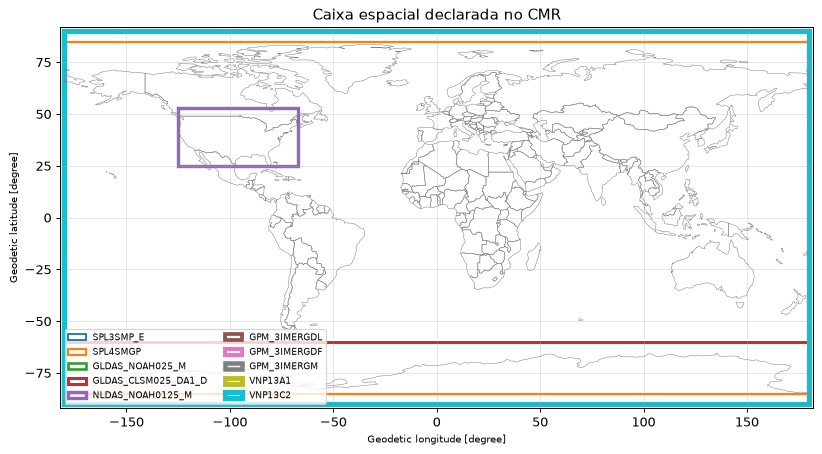

In [39]:
paises = paises_gdf()
fig, ax = plt.subplots(figsize=(12, 5.5))
paises.boundary.plot(ax=ax, color="gray", lw=0.4)
cores = plt.cm.tab10.colors
for i, r in tab.iterrows():
    ax.add_patch(plt.Rectangle((r.lon_min, r.lat_min), r.lon_max - r.lon_min, r.lat_max - r.lat_min,
                               fill=False, ec=cores[i % 10], lw=1.5 + 0.3 * i, label=r.short_name))
ax.set_xlim(-182, 182)
ax.set_ylim(-92, 92)
ax.legend(fontsize=7, loc="lower left", ncol=2)
ax.set_title("Caixa espacial declarada no CMR")
plt.show()

### 4.2 Continuidade temporal — granulos por ano
Ano com número de arquivos abaixo do esperado indica lacuna (ou ano corrente incompleto).
O **IMERG Final** para em set/2025: para 2025–2026 só existem as versões Early/Late, que não têm correção por pluviômetros.

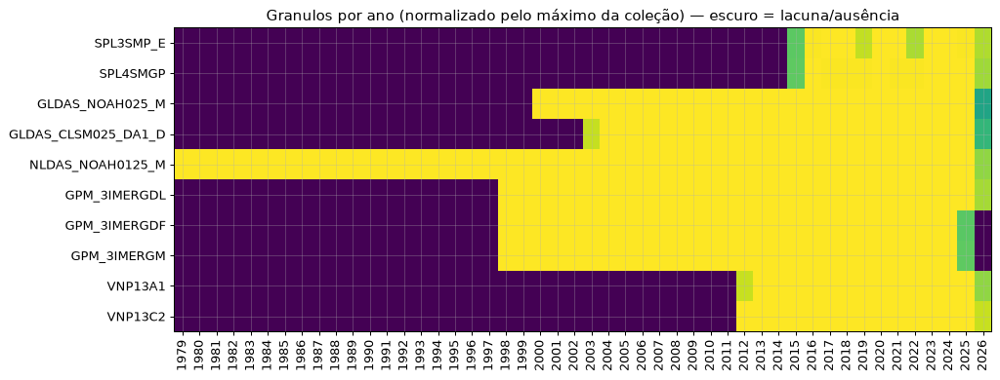

,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
SPL3SMP_E,0,0,0,0,0,0,0,0,0,0,...,365,365,332,366,365,319,365,366,364,322
SPL4SMGP,0,0,0,0,0,0,0,0,0,0,...,2921,2921,2921,2929,2921,2921,2926,2936,2925,2514
GLDAS_NOAH025_M,0,0,0,0,0,0,0,0,0,0,...,12,12,12,12,12,12,12,12,12,7
GLDAS_CLSM025_DA1_D,0,0,0,0,0,0,0,0,0,0,...,365,365,365,366,365,365,365,366,365,243
NLDAS_NOAH0125_M,12,12,12,12,12,12,12,12,12,12,...,12,12,12,12,12,12,12,12,12,10
GPM_3IMERGDL,0,0,0,0,0,0,0,0,0,0,...,365,365,365,366,365,365,365,366,365,316
GPM_3IMERGDF,0,0,0,0,0,0,0,0,0,0,...,365,365,365,366,365,365,365,366,273,0
GPM_3IMERGM,0,0,0,0,0,0,0,0,0,0,...,12,12,12,12,12,12,12,12,9,0
VNP13A1,0,0,0,0,0,0,0,0,0,0,...,13632,13632,13632,13632,13632,13632,13630,13632,13631,11360
VNP13C2,0,0,0,0,0,0,0,0,0,0,...,12,12,12,12,12,12,12,12,12,11


In [40]:
por_ano = pd.DataFrame({m["short_name"]: pd.Series(m["granulos_por_ano"]) for m in meta.values()}).fillna(0).astype(int)
por_ano.index = por_ano.index.astype(int)
fig, ax = plt.subplots(figsize=(12, 4.5))
(por_ano.div(por_ano.max()).T).pipe(lambda d: ax.imshow(d.values, aspect="auto", cmap="viridis"))
ax.set_yticks(range(len(por_ano.columns)))
ax.set_yticklabels(por_ano.columns)
ax.set_xticks(range(len(por_ano.index)))
ax.set_xticklabels(por_ano.index, rotation=90)
ax.set_title("Granulos por ano (normalizado pelo máximo da coleção) — escuro = lacuna/ausência")
plt.show()
por_ano.T

### 4.3 Volume do recorte do Ceará (planejamento)
O número de granulos que tocam o Ceará dá a escala do download quando houver login.

**Estratégia de download**
- **SMAP e VIIRS:** via **AppEEARS**, que recorta no servidor pelo polígono do Ceará e evita baixar arquivos globais.
- **GLDAS e IMERG V07:** via **OPeNDAP**, fatiando lat/lon.

**Insights para o produto**
- **SMAP L4 (zona da raiz)** é a variável de umidade certa para lavoura. O L3 mede só os 5 cm de cima e, a 9 km,
  descreve a região, não o talhão.
- **GLDAS-2.2 CLSM** assimila o GRACE e entrega **água subterrânea a 0,25°**: é a ponte entre o GRACE (~300 km) e o talhão.
- **NLDAS** fica fora do núcleo global; só serve para enriquecer quando o usuário estiver nos EUA.
- **Alternativas abertas enquanto não há login** (seção 01): o POWER traz umidade do solo do MERRA-2
  (`GWETTOP`, `GWETROOT`, `GWETPROF`), um substituto global grosseiro (~50 km) do SMAP/GLDAS.

In [41]:
pend = [p for p in ["smap", "gldas", "nldas", "imerg_v07", "viirs_vnp13"] if (DADOS / p).exists()]
print("Pastas de dados Earthdata já presentes:", pend or "nenhuma (aguardando credencial)")

Pastas de dados Earthdata já presentes: nenhuma (aguardando credencial)


# 6. GRACE / GRACE-FO — armazenamento total de água (TWS)

**Ficha técnica**

| Item | Valor |
|---|---|
| Provedor | NASA/DLR (GRACE, 2002–2017) e NASA/GFZ (GRACE-FO, 2018–); solução de *mascons* do CSR/Universidade do Texas (RL06.3) |
| Variável | `lwe_thickness`: anomalia do armazenamento total de água (solo + subsolo + aquífero + superfície + neve), em **cm de água equivalente**, relativa à média 2004–2009 |
| Resolução espacial | grade de 0,25° (amostragem); mascons de ~1° (~120 km); **resolução efetiva ~300 km** |
| Resolução temporal | mensal |
| Período | abr/2002 → set/2026 (261 meses), com a lacuna GRACE→GRACE-FO (jul/2017–mai/2018) |
| Latência | ~2–3 meses |
| Acesso | aberto, sem login (download.csr.utexas.edu); a versão JPL fica no PO.DAAC e exige Earthdata |
| Licença / citação | dados abertos; citar Save, Bettadpur & Tapley (2016), DOI 10.15781/cgq9-nh24 |

Para que serve no produto: é o único dado que "enxerga" **água subterrânea/aquífero**. Mostra se a região está
esgotando ou recarregando água ano a ano. Não serve para um talhão: é um sinal **regional**.

In [42]:
import sys
import warnings

sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
from comum import *  # noqa

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymannkendall as mk
import xarray as xr
from scipy import stats

warnings.filterwarnings("ignore")
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
G = DADOS / "grace"
resumo = xr.open_dataset(G / "grace_global_resumo.nc")
cob = pd.read_parquet(G / "grace_cobertura_mensal.parquet")
ne = xr.open_dataset(G / "grace_ne_mensal.nc")["lwe_thickness"]
ce = pd.read_parquet(DERIV / "grace_ce_mensal.parquet").set_index("data")["valor"]
nem = pd.read_parquet(DERIV / "grace_ne_mensal.parquet").set_index("data")["valor"]
aoi = pd.read_parquet(DERIV / "grace_aoi_mensal.parquet")
uru = aoi[aoi.aoi == "oeste_bahia_urucuia"].set_index("data")["valor"]
print("NE:", dict(ne.sizes), "| Ceará:", ce.index.min().date(), "->", ce.index.max().date(), len(ce), "meses")

NE: {'time': 261, 'lat': 78, 'lon': 64} | Ceará: 2002-04-01 -> 2026-09-01 259 meses


## 6.1 Validação de cobertura global
Testes: (a) fração de células com valor em cada mês, separando terra e oceano; (b) extensão em latitude;
(c) mapa global de tendência e de amplitude sazonal; (d) meses faltantes na série.

Latitude: -89.875 a 89.875 | Longitude: -179.875 a 179.875
Fração de meses válidos por pixel (mín/médio): 1.0 1.0
Fração de pixels com valor por mês — terra: mín 1.0 | oceano: mín 1.0
 faixa_lat  celulas_terra  frac_com_valor  |tendência| média cm/ano
(-90, -60]         106609             1.0                  2.056436
(-60, -30]           9025             1.0                  0.786376
  (-30, 0]          40551             1.0                  0.392152
   (0, 30]          50979             1.0                  0.483865
  (30, 60]          90272             1.0                  0.616973
  (60, 90]          67890             1.0                  3.109166


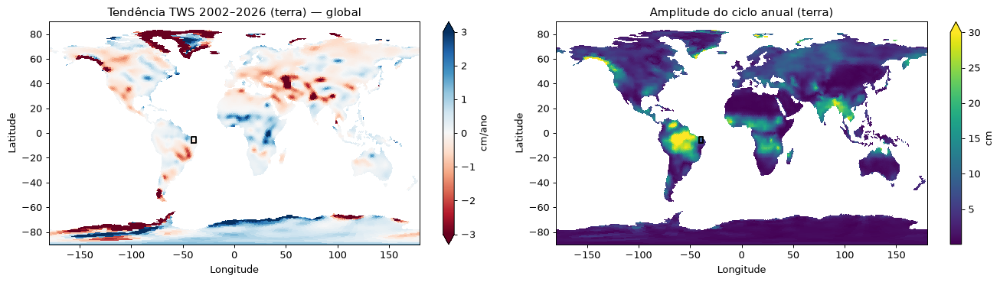

In [43]:
print("Latitude:", float(resumo.lat.min()), "a", float(resumo.lat.max()), "| Longitude:", float(resumo.lon.min()), "a", float(resumo.lon.max()))
print("Fração de meses válidos por pixel (mín/médio):", float(resumo.fracao_meses_validos.min()), float(resumo.fracao_meses_validos.mean()))
print("Fração de pixels com valor por mês — terra: mín", cob.frac_terra.min(), "| oceano: mín", cob.frac_oceano.min())
faixas = pd.cut(resumo.lat.values, [-90, -60, -30, 0, 30, 60, 90])
terra = resumo.terra.values > 0.5
tab = []
for f in faixas.categories:
    sel = (faixas == f)
    m = resumo.tendencia_cm_ano.values[sel][terra[sel]]
    tab.append((str(f), int(terra[sel].sum()), float(np.isfinite(m).mean()), float(np.nanmean(np.abs(m)))))
print(pd.DataFrame(tab, columns=["faixa_lat", "celulas_terra", "frac_com_valor", "|tendência| média cm/ano"]).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
r = resumo.tendencia_cm_ano.where(resumo.terra > 0.5)
r.plot(ax=ax[0], cmap="RdBu", vmin=-3, vmax=3, cbar_kwargs={"label": "cm/ano"})
ax[0].set_title("Tendência TWS 2002–2026 (terra) — global")
resumo.amplitude_sazonal_cm.where(resumo.terra > 0.5).plot(ax=ax[1], cmap="viridis", vmax=30, cbar_kwargs={"label": "cm"})
ax[1].set_title("Amplitude do ciclo anual (terra)")
for a in ax:
    a.plot([-41.4, -37.25, -37.25, -41.4, -41.4], [-7.85, -7.85, -2.78, -2.78, -7.85], "k-", lw=1.5)
plt.tight_layout(); plt.show()

In [44]:
todos = pd.period_range("2002-04", "2026-09", freq="M")
presentes = pd.PeriodIndex(pd.to_datetime(ne.time.values).to_period("M"))
faltam = todos.difference(presentes)
print(f"Meses esperados {len(todos)} | presentes (únicos) {presentes.nunique()} | faltantes {len(faltam)}")
grupos = pd.Series(faltam.to_timestamp()).diff().dt.days.gt(40).cumsum()
for _, g in pd.Series(faltam.astype(str)).groupby(grupos.values):
    print("  lacuna:", g.iloc[0], "→", g.iloc[-1], f"({len(g)} meses)")

Meses esperados 294 | presentes (únicos) 259 | faltantes 35
  lacuna: 2002-06 → 2002-07 (2 meses)
  lacuna: 2003-06 → 2003-06 (1 meses)
  lacuna: 2011-01 → 2011-01 (1 meses)
  lacuna: 2011-06 → 2011-06 (1 meses)
  lacuna: 2011-11 → 2011-11 (1 meses)
  lacuna: 2012-05 → 2012-05 (1 meses)
  lacuna: 2012-10 → 2012-10 (1 meses)
  lacuna: 2013-03 → 2013-03 (1 meses)
  lacuna: 2013-08 → 2013-09 (2 meses)
  lacuna: 2014-02 → 2014-02 (1 meses)
  lacuna: 2014-07 → 2014-07 (1 meses)
  lacuna: 2014-12 → 2014-12 (1 meses)
  lacuna: 2015-05 → 2015-06 (2 meses)
  lacuna: 2015-10 → 2015-11 (2 meses)
  lacuna: 2016-04 → 2016-04 (1 meses)
  lacuna: 2016-09 → 2016-10 (2 meses)
  lacuna: 2017-02 → 2017-02 (1 meses)
  lacuna: 2017-07 → 2018-05 (11 meses)
  lacuna: 2018-08 → 2018-09 (2 meses)


**Veredito de cobertura:** é **global de verdade**, inclusive oceanos e polos (de −89,9° a +89,9°), com 100% das
células preenchidas em todos os meses. O que limita não é a cobertura, é a **resolução**: ~300 km efetivos. O
Ceará inteiro equivale a poucos "pixels independentes". Há ~35 meses faltantes, a maioria na lacuna de 11 meses
entre as missões (2017–2018) e em falhas pontuais de bateria do GRACE (2011–2017).

## 6.2 Qualidade da série regional

In [45]:
def resumo_estat(s, nome):
    s = s.dropna()
    return pd.Series({"n": len(s), "média": s.mean(), "desvio": s.std(), "mín": s.min(), "p05": s.quantile(.05),
                      "p25": s.quantile(.25), "mediana": s.median(), "p75": s.quantile(.75), "p95": s.quantile(.95),
                      "máx": s.max(), "assimetria": stats.skew(s), "curtose": stats.kurtosis(s)}, name=nome)

tabela = pd.concat([resumo_estat(ce, "Ceará"), resumo_estat(nem, "Nordeste"), resumo_estat(uru, "Oeste BA/Urucuia")]
                   + [resumo_estat(aoi[aoi.aoi == a].set_index("data")["valor"], a) for a in AOIS], axis=1).T
print(tabela.round(2).to_string())
z = (ce - ce.mean()) / ce.std()
print("\nOutliers |z|>2,5 no Ceará:", z[abs(z) > 2.5].round(2).to_dict())
print("Duplicatas de mês no arquivo original:", int(presentes.duplicated().sum()), "(meses com duas soluções; foram promediadas)")

                      n  média  desvio    mín    p05    p25  mediana   p75    p95    máx  assimetria  curtose
Ceará             259.0  -3.50   10.41 -26.51 -17.98 -10.66    -5.20  3.43  15.21  36.49        0.61     0.46
Nordeste          259.0  -2.86    9.36 -25.27 -16.07  -9.59    -4.60  3.77  13.21  21.42        0.24    -0.58
Oeste BA/Urucuia  259.0 -15.07   18.12 -60.12 -43.85 -28.70   -16.51 -1.01  12.97  27.70        0.06    -0.61
apodi_jaguaribe   259.0  -3.91    8.49 -22.72 -17.03  -9.57    -4.91  1.71   9.75  26.51        0.38     0.28
cariri            259.0  -6.81    9.17 -34.19 -20.48 -13.31    -7.25 -0.59   8.82  22.40        0.31     0.18
sertao_central    259.0  -4.39   10.55 -25.26 -20.13 -11.45    -5.82  2.86  14.33  35.17        0.56     0.34
ibiapaba          259.0  -0.72   12.79 -44.46 -17.68  -9.46    -2.30  7.68  21.01  47.17        0.40     0.58

Outliers |z|>2,5 no Ceará: {Timestamp('2004-03-01 00:00:00'): 2.95, Timestamp('2009-05-01 00:00:00'): 3.84, Timestamp('

## 6.3 Distribuição e mapas no Nordeste

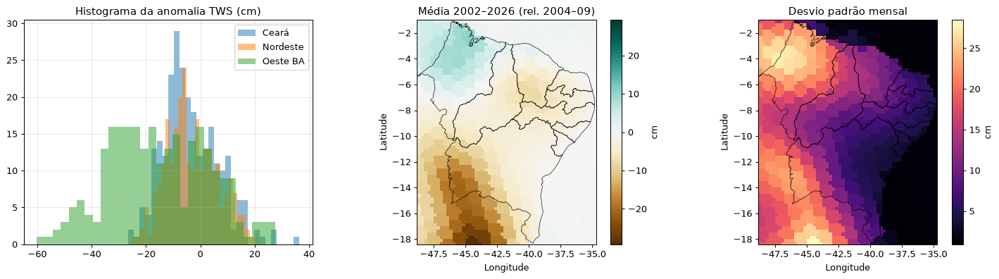

In [46]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for s, n in [(ce, "Ceará"), (nem, "Nordeste"), (uru, "Oeste BA")]:
    ax[0].hist(s.dropna(), bins=30, alpha=0.5, label=n)
ax[0].set_title("Histograma da anomalia TWS (cm)"); ax[0].legend()
ne.mean("time").plot(ax=ax[1], cmap="BrBG", center=0, cbar_kwargs={"label": "cm"})
ax[1].set_title("Média 2002–2026 (rel. 2004–09)")
ne.std("time").plot(ax=ax[2], cmap="magma", cbar_kwargs={"label": "cm"})
ax[2].set_title("Desvio padrão mensal")
uf = nordeste_gdf()
for a in ax[1:]:
    uf.boundary.plot(ax=a, color="k", lw=0.5)
    a.set_xlim(BBOX_NE[0], BBOX_NE[2]); a.set_ylim(BBOX_NE[1], BBOX_NE[3])
plt.tight_layout(); plt.show()

## 6.4 Sazonalidade (climatologia mensal)
No Ceará a chuva cai em fevereiro–maio. O armazenamento total responde com atraso: o pico de água vem no fim
da quadra chuvosa e o mínimo no fim da estação seca (nov–dez).

data        1    2    3    4    5     6     7     8     9     10    11    12
Ceará    -10.9 -6.1  1.2  6.0  8.1   2.3  -1.9  -4.7  -6.4  -8.4 -10.8 -11.5
Nordeste  -7.1 -1.0  3.8  7.9  6.5   2.0  -1.6  -5.6  -8.2 -11.3 -11.3  -9.9
Oeste BA -11.6 -3.0 -2.6  0.7 -8.0 -18.2 -20.0 -24.6 -26.3 -29.7 -24.0 -16.0


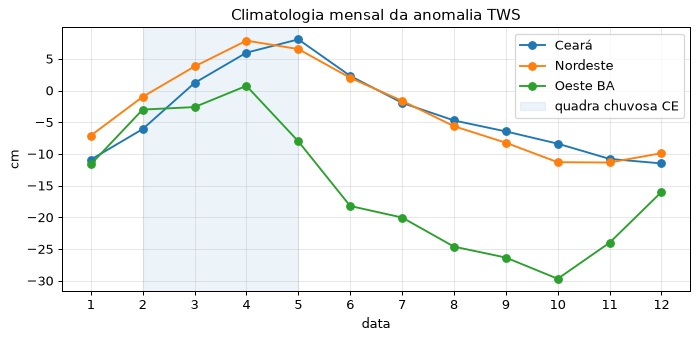

Mês de pico no Ceará: 5 | mês de mínimo: 12 | amplitude: 19.6 cm


In [47]:
clim = pd.DataFrame({"Ceará": ce.groupby(ce.index.month).mean(), "Nordeste": nem.groupby(nem.index.month).mean(),
                     "Oeste BA": uru.groupby(uru.index.month).mean()})
print(clim.round(1).T.to_string())
ax = clim.plot(marker="o", figsize=(9, 3.8)); ax.axvspan(2, 5, color="tab:blue", alpha=0.08, label="quadra chuvosa CE")
ax.set_xticks(range(1, 13)); ax.set_ylabel("cm"); ax.set_title("Climatologia mensal da anomalia TWS"); ax.legend(); plt.show()
print("Mês de pico no Ceará:", int(clim["Ceará"].idxmax()), "| mês de mínimo:", int(clim["Ceará"].idxmin()),
      "| amplitude:", round(clim["Ceará"].max() - clim["Ceará"].min(), 1), "cm")

## 6.5 Tendências (Mann-Kendall com correção de autocorrelação + inclinação de Sen)

          região MK mensal (Hamed-Rao)     p  Sen cm/ano   MK anual  p anual  Sen anual cm/ano
           Ceará              no trend 0.716       0.075   no trend    1.000             0.003
        Nordeste              no trend 0.799       0.056   no trend    0.907             0.041
Oeste BA/Urucuia            decreasing 0.000      -1.705 decreasing    0.000            -1.429
 apodi_jaguaribe              no trend 0.458      -0.124   no trend    0.498            -0.101
          cariri              no trend 0.175      -0.327   no trend    0.199            -0.294
  sertao_central              no trend 0.680      -0.089   no trend    0.944            -0.054
        ibiapaba              no trend 0.082       0.386   no trend    0.183             0.348


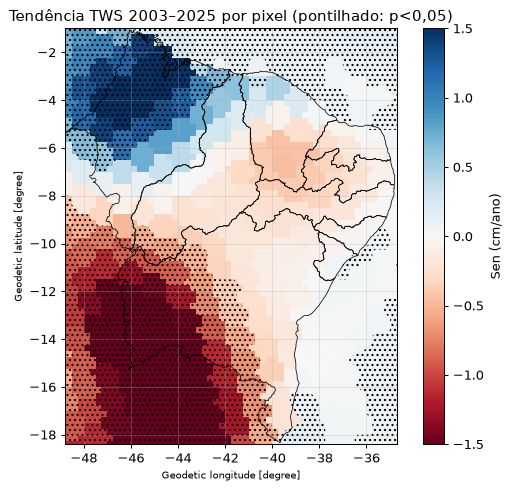

In [48]:
def dessaz(s):
    return s - s.groupby(s.index.month).transform("mean")

linhas = []
for nome, s in [("Ceará", ce), ("Nordeste", nem), ("Oeste BA/Urucuia", uru)] + [(a, aoi[aoi.aoi == a].set_index("data")["valor"]) for a in AOIS]:
    d = dessaz(s).dropna()
    r1 = mk.hamed_rao_modification_test(d.values)
    anual = s.resample("YE").mean().dropna()
    r2 = mk.original_test(anual.values)
    linhas.append((nome, r1.trend, r1.p, r1.slope * 12, r2.trend, r2.p, r2.slope))
print(pd.DataFrame(linhas, columns=["região", "MK mensal (Hamed-Rao)", "p", "Sen cm/ano", "MK anual", "p anual", "Sen anual cm/ano"]).round(3).to_string(index=False))

# tendência por pixel no NE (médias anuais, 2003-2025 completos)
anual = ne.groupby("time.year").mean().sel(year=slice(2003, 2025))
sl = np.full((ne.sizes["lat"], ne.sizes["lon"]), np.nan); pv = sl.copy()
for i in range(ne.sizes["lat"]):
    for j in range(ne.sizes["lon"]):
        v = anual[:, i, j].values
        if np.isfinite(v).sum() > 15:
            r = mk.original_test(v[np.isfinite(v)]); sl[i, j], pv[i, j] = r.slope, r.p
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.pcolormesh(ne.lon, ne.lat, sl, cmap="RdBu", vmin=-1.5, vmax=1.5, shading="auto")
ax.contourf(ne.lon, ne.lat, (pv < 0.05).astype(float), levels=[0.5, 1.5], hatches=["..."], colors="none")
uf.boundary.plot(ax=ax, color="k", lw=0.6); plt.colorbar(im, label="Sen (cm/ano)")
ax.set_xlim(BBOX_NE[0], BBOX_NE[2]); ax.set_ylim(BBOX_NE[1], BBOX_NE[3])
ax.set_title("Tendência TWS 2003–2025 por pixel (pontilhado: p<0,05)"); plt.show()

## 6.6 Variabilidade interanual e a seca de 2012–2017

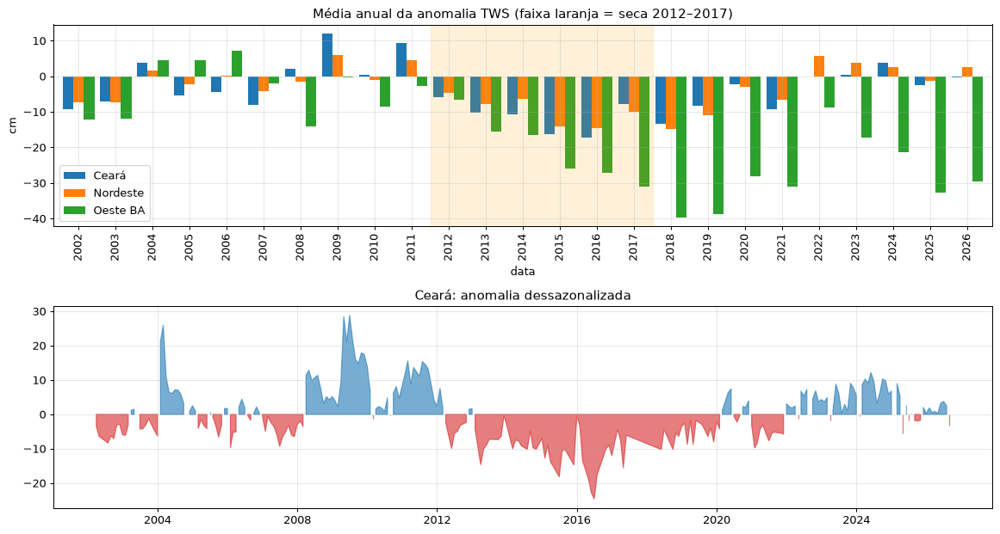

Meses por classe de seca (Ceará, dessazonalizado):
 valor
D4 excepcional      5
D3 extrema          7
D2 severa          13
D1 moderada        26
D0 anormal         26
normal/úmido      182

Mínimo da série: 2016-07-01 -24.6 cm
Seca 2012–2017: média -8.1 cm | meses abaixo de 0: 45 de 50
Déficit acumulado (soma das anomalias negativas, cm·mês): -422.0


In [49]:
an = pd.DataFrame({"Ceará": ce.resample("YE").mean(), "Nordeste": nem.resample("YE").mean(), "Oeste BA": uru.resample("YE").mean()})
an.index = an.index.year
fig, ax = plt.subplots(2, 1, figsize=(13, 7))
an.plot.bar(ax=ax[0], width=0.85); ax[0].axvspan(9.5, 15.5, color="orange", alpha=0.15)
ax[0].set_title("Média anual da anomalia TWS (faixa laranja = seca 2012–2017)"); ax[0].set_ylabel("cm")
d = dessaz(ce)
ax[1].fill_between(d.index, d, 0, where=d < 0, color="tab:red", alpha=0.6)
ax[1].fill_between(d.index, d, 0, where=d >= 0, color="tab:blue", alpha=0.6)
ax[1].set_title("Ceará: anomalia dessazonalizada"); plt.tight_layout(); plt.show()

# classificação por percentis (estilo monitor de seca com GRACE)
pct = d.rank(pct=True)
classe = pd.cut(pct, [0, .02, .05, .10, .20, .30, 1.0], labels=["D4 excepcional", "D3 extrema", "D2 severa", "D1 moderada", "D0 anormal", "normal/úmido"])
print("Meses por classe de seca (Ceará, dessazonalizado):\n", classe.value_counts().sort_index().to_string())
print("\nMínimo da série:", d.idxmin().date(), round(d.min(), 1), "cm")
seca = d["2012":"2017"]
print("Seca 2012–2017: média", round(seca.mean(), 1), "cm | meses abaixo de 0:", int((seca < 0).sum()), "de", len(seca))
print("Déficit acumulado (soma das anomalias negativas, cm·mês):", round(seca[seca < 0].sum(), 0))

In [50]:
# Relação com a chuva do POWER (se o derivado existir): correlação com defasagem
p = DERIV / "power_ce_mensal.parquet"
if p.exists():
    pw = pd.read_parquet(p)
    chuva = pw[pw.variavel == "PRECTOTCORR"].set_index("data")["valor"]
    chuva_anom = dessaz(chuva)
    acum = chuva_anom.rolling(12).sum()
    base = dessaz(ce).dropna()
    res = []
    for lag in range(0, 13):
        x = acum.shift(lag).reindex(base.index)
        ok = x.notna()
        res.append((lag, np.corrcoef(base[ok], x[ok])[0, 1]))
    res = pd.DataFrame(res, columns=["defasagem_meses", "r"])
    print("Correlação TWS × chuva acumulada 12 meses (anomalias):\n", res.round(2).to_string(index=False))
else:
    print("Derivado do POWER ainda não existe; correlação será feita na seção de relações.")

Correlação TWS × chuva acumulada 12 meses (anomalias):
  defasagem_meses    r
               0 0.46
               1 0.47
               2 0.42
               3 0.38
               4 0.34
               5 0.32
               6 0.31
               7 0.30
               8 0.28
               9 0.26
              10 0.27
              11 0.29
              12 0.32


## 6.7 Insights e uso no produto

- **Global de verdade, mas regional**: serve a qualquer fazenda do mundo como "termômetro" da água da bacia ou do
  aquífero, nunca como dado do talhão. No app, entra como um **semáforo regional de água** ("a água da sua região
  está X cm abaixo do normal; tendência de Y cm/ano").
- **A seca 2012–2017 aparece com clareza** no Ceará: 45 de 50 meses abaixo do normal, mínimo de −24,6 cm em
  jul/2016 e −17 cm na média anual de 2016. A recuperação só se completa em 2022–2024. Isso mostra a **memória longa**
  do sistema: um ano de chuva boa não repõe o aquífero. O motor de rotação deve penalizar culturas de alta demanda
  hídrica (irrigadas) quando o TWS está em déficit persistente.
- **Ceará e Nordeste não têm tendência de longo prazo** (Mann-Kendall com correção de autocorrelação, p ≈ 0,7–0,8):
  o sinal é dominado por ciclos de seca e recuperação, não por esgotamento contínuo.
- **Oeste da Bahia (Urucuia) perde água de forma significativa**: −1,4 a −1,7 cm/ano (p < 0,001) e anomalia média de
  −15 cm, coerente com a expansão da irrigação por pivô. É o caso de "rotação que economiza água" para a
  apresentação e um contraponto ao Ceará.
- **Validade científica**: as AOIs do Ceará (11 km) caem dentro de um ou dois mascons, então os valores por AOI são
  quase iguais ao regional. Isso precisa ser dito no app, para não sugerir uma precisão que o dado não tem.
- **Sazonalidade com atraso**: o TWS do Ceará chega ao pico em maio (fim da quadra) e ao mínimo em dezembro, com
  amplitude de ~20 cm. Isso permite uma regra simples de "água guardada" para decidir a safrinha ou a cultura de
  segunda época.
- **Ligação com a chuva do POWER**: a anomalia de TWS correlaciona com a chuva acumulada de 12 meses (r ≈ 0,47 com
  1 mês de defasagem) e a correlação decai devagar (r ≈ 0,3 com 12 meses), outra evidência da memória plurianual.
- **Ideias de ML**:
  1. *downscaling* do GRACE (300 km → 5–10 km) com floresta aleatória ou gradient boosting, usando chuva (IMERG/POWER),
     ET (MODIS/ECOSTRESS), NDVI e relevo (SRTM) como preditores; é técnica publicada para aquíferos.
  2. Preencher a lacuna 2017–2018 com um modelo de séries (LSTM/SARIMAX) dirigido pela chuva.
  3. Previsão de TWS 3–6 meses à frente a partir de ENSO/dipolo do Atlântico (seção 13) e da chuva acumulada,
     para alertas de risco hídrico na rotação.

# 7. Landsat Collection 2 Level-2 (NASA/USGS)

**O que é:** reflectância de superfície (corrigida da atmosfera) dos satélites Landsat 4/5 (TM), 7 (ETM+) e 8/9 (OLI),
a 30 m, desde 1982. É o **histórico mais longo de imagens de lavoura do planeta**: dá para ver o mesmo talhão desde os anos 80.

**Como baixamos:** Microsoft Planetary Computer (`landsat-c2-l2`), lendo só a janela de cada AOI dentro dos COGs.
- metadados STAC de **todas** as cenas que tocam o Ceará (1982–hoje);
- cubos 30 m (vermelho, NIR, SWIR1, NDVI, NDMI) nas 4 AOIs com Landsat 8/9 (2013–hoje);
- estatísticas por cena nas AOIs com Landsat 4/5/7 (1984–2012), para a série longa das secas.

Máscara de nuvem: bits 0–5 do `QA_PIXEL` (preenchimento, nuvem dilatada, cirro, nuvem, sombra, neve).

In [51]:
import json
import sys
import warnings

sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymannkendall as mk
import xarray as xr
from comum import AOIS, DADOS, paises_gdf
from frente_c_util import mk_sen_vetorizado

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
D = DADOS / "landsat"
CORES = {"apodi_jaguaribe": "#1f77b4", "cariri": "#d62728", "sertao_central": "#ff7f0e", "ibiapaba": "#2ca02c"}
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

meta = pd.read_parquet(D / "landsat_stac_ceara.parquet")
glob = pd.read_parquet(D / "landsat_stac_global.parquet")
c89 = pd.read_parquet(D / "landsat_aoi_cenas_l89.parquet")
hist = pd.read_parquet(D / "landsat_aoi_cenas_hist.parquet") if (D / "landsat_aoi_cenas_hist.parquet").exists() else pd.DataFrame()
for df in (meta, glob, c89, hist):
    if len(df):
        df["datetime"] = pd.to_datetime(df["datetime"], utc=True).dt.tz_localize(None)
man = json.loads((D / "MANIFESTO.json").read_text(encoding="utf-8")) if (D / "MANIFESTO.json").exists() else {}
print(f"cenas no Ceará (STAC): {len(meta):,} | cenas L8/9 nas AOIs: {len(c89):,} | cenas L4/5/7 nas AOIs: {len(hist):,}")

cenas no Ceará (STAC): 15,981 | cenas L8/9 nas AOIs: 1,624 | cenas L4/5/7 nas AOIs: 2,272


## 7.1 Ficha técnica

In [52]:
ficha = pd.DataFrame([
    ("Provedor", "NASA/USGS; espelho aberto no Microsoft Planetary Computer"),
    ("Produto", "Landsat Collection 2 Level-2 Surface Reflectance (SR) + QA_PIXEL"),
    ("Resolução espacial", "30 m (bandas ópticas); térmica reamostrada para 30 m"),
    ("Revisita nominal", "16 dias por satélite; 8 dias com dois satélites (L8+L9, ou L5+L7)"),
    ("Período", f"{meta.datetime.min():%Y-%m-%d} a {meta.datetime.max():%Y-%m-%d} (cenas que tocam o Ceará)"),
    ("Escala SR", "refl = DN × 0,0000275 − 0,2"),
    ("Acesso", "aberto (USGS EarthExplorer pede login gratuito; o Planetary Computer não pede)"),
    ("Tamanho local", f"{man.get('tamanho_bytes', 0)/1e9:.2f} GB"),
], columns=["item", "valor"])
ficha

,item,valor
0,Provedor,NASA/USGS; espelho aberto no Microsoft Planetary Computer
1,Produto,Landsat Collection 2 Level-2 Surface Reflectance (SR) + QA_PIXEL
2,Resolução espacial,30 m (bandas ópticas); térmica reamostrada para 30 m
3,Revisita nominal,"16 dias por satélite; 8 dias com dois satélites (L8+L9, ou L5+L7)"
4,Período,1984-04-12 a 2026-11-03 (cenas que tocam o Ceará)
5,Escala SR,"refl = DN × 0,0000275 − 0,2"
6,Acesso,aberto (USGS EarthExplorer pede login gratuito; o Planetary Computer não pede)
7,Tamanho local,0.71 GB


## 7.2 Validação de cobertura global
Consultamos o catálogo STAC em **27 caixas de 1°** espalhadas por todos os continentes e faixas de latitude, no ano de 2023.
- **Revisita efetiva:** mediana do intervalo entre datas distintas de aquisição.
- **Revisita limpa:** o mesmo intervalo, contando só cenas com menos de 20% de nuvem.

In [53]:
def resumo_amostra(g):
    g = g.dropna(subset=["id"])
    if g.empty:
        return pd.Series({"cenas": 0, "datas": 0, "revisita_d": np.nan, "revisita_limpa_d": np.nan, "nuvem_mediana": np.nan, "plataformas": ""})
    datas = np.sort(g.datetime.dt.normalize().unique())
    lim = np.sort(g[g.cloud_cover < 20].datetime.dt.normalize().unique())
    gap = lambda d: float(np.median(np.diff(d).astype("timedelta64[D]").astype(int))) if len(d) > 1 else np.nan
    return pd.Series({"cenas": len(g), "datas": len(datas), "revisita_d": gap(datas), "revisita_limpa_d": gap(lim),
                      "nuvem_mediana": g.cloud_cover.median(), "plataformas": ",".join(sorted(g.platform.dropna().unique()))})

cob = glob.groupby(["amostra", "lon", "lat"]).apply(resumo_amostra).reset_index().sort_values("lat", ascending=False)
cob

,amostra,lon,lat,cenas,datas,revisita_d,revisita_limpa_d,nuvem_mediana,plataformas
11,Groenlandia_N,-40.0,81.0,1216,159,1.0,1.0,10.295,"landsat-8,landsat-9"
24,Svalbard,16.0,78.5,589,170,1.0,2.0,61.520,"landsat-8,landsat-9"
5,Canada_N,-95.0,70.0,314,155,1.0,1.0,50.575,"landsat-7,landsat-8,landsat-9"
23,Siberia,100.0,62.0,270,143,1.0,5.0,62.280,"landsat-7,landsat-8,landsat-9"
26,Ucrania,32.0,49.0,325,157,1.0,3.5,47.140,"landsat-7,landsat-8,landsat-9"
10,Franca,2.0,48.5,322,153,1.0,4.0,64.115,"landsat-7,landsat-8,landsat-9"
17,Mongolia,103.0,46.0,318,157,1.0,2.0,8.690,"landsat-7,landsat-8,landsat-9"
14,Iowa_US,-93.5,42.0,238,115,2.0,5.0,28.640,"landsat-7,landsat-8,landsat-9"
7,China_N,115.0,37.0,239,113,2.0,5.0,13.050,"landsat-7,landsat-8,landsat-9"
15,Japao,139.0,36.0,221,113,2.0,7.0,40.130,"landsat-7,landsat-8,landsat-9"


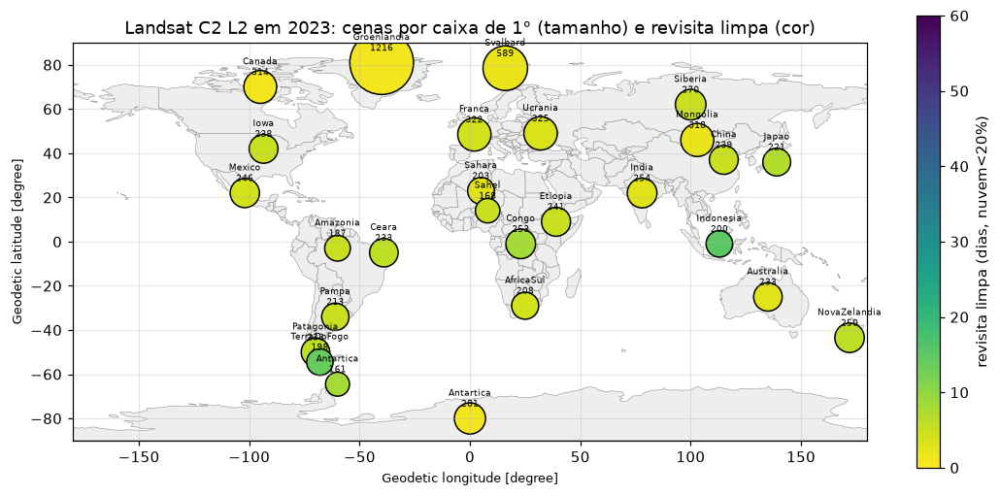

In [54]:
fig, ax = plt.subplots(figsize=(12, 5.5))
paises_gdf().plot(ax=ax, color="#eeeeee", edgecolor="#999999", lw=0.4)
sc = ax.scatter(cob.lon, cob.lat, s=20 + cob.cenas * 1.5, c=cob.revisita_limpa_d, cmap="viridis_r", edgecolor="k", vmin=0, vmax=60)
for _, r in cob.iterrows():
    ax.annotate(f"{r.amostra.split('_')[0]}\n{int(r.cenas)}", (r.lon, r.lat), fontsize=6, ha="center", va="bottom", xytext=(0, 6), textcoords="offset points")
plt.colorbar(sc, ax=ax, label="revisita limpa (dias, nuvem<20%)")
ax.set_title("Landsat C2 L2 em 2023: cenas por caixa de 1° (tamanho) e revisita limpa (cor)")
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90)
plt.show()

In [55]:
lat_ok = cob[cob.cenas > 0]
print("Latitude máxima com cenas L2 em 2023:", lat_ok.lat.max(), "| mínima:", lat_ok.lat.min())
print("Amostras sem nenhuma cena:", ", ".join(cob[cob.cenas == 0].amostra) or "nenhuma")
print(f"Revisita efetiva mediana (todas as amostras com dados): {lat_ok.revisita_d.median():.0f} dias;"
      f" revisita limpa mediana: {lat_ok.revisita_limpa_d.median():.0f} dias")
glob["mes"] = glob.datetime.dt.month
meses_amostra = glob.dropna(subset=["id"]).groupby("amostra").agg(
    meses_com_dados=("mes", lambda s: len(set(s.dropna()))), lista=("mes", lambda s: ",".join(str(int(m)) for m in sorted(set(s.dropna())))),
    pct_T1=("categoria", lambda s: round(100 * (s == "T1").mean(), 1)))
meses_amostra.join(cob.set_index("amostra")[["lat"]]).sort_values("lat", ascending=False)

Latitude máxima com cenas L2 em 2023: 81.0 | mínima: -80.0
Amostras sem nenhuma cena: nenhuma
Revisita efetiva mediana (todas as amostras com dados): 2 dias; revisita limpa mediana: 5 dias


,meses_com_dados,lista,pct_T1,lat
amostra,,,,
Groenlandia_N,6,"4,5,6,7,8,9",67.8,81.0
Svalbard,7,"3,4,5,6,7,8,9",42.4,78.5
Canada_N,8,"3,4,5,6,7,8,9,10",65.3,70.0
Siberia,9,"2,3,4,5,6,7,8,9,10",76.3,62.0
Ucrania,12,"1,2,3,4,5,6,7,8,9,10,11,12",74.2,49.0
Franca,12,"1,2,3,4,5,6,7,8,9,10,11,12",73.3,48.5
Mongolia,12,"1,2,3,4,5,6,7,8,9,10,11,12",98.1,46.0
Iowa_US,12,"1,2,3,4,5,6,7,8,9,10,11,12",80.3,42.0
China_N,12,"1,2,3,4,5,6,7,8,9,10,11,12",87.4,37.0


**Veredito de cobertura (tirado das tabelas acima):** o Landsat C2 L2 é **global sobre terra**. Todas as 27 caixas,
do Ártico ao interior da Antártida, têm centenas de cenas em 2023, com dois satélites (L8 + L9) e, em várias
regiões, ainda o L7. Os limites de verdade são outros três:
1. **Iluminação:** acima de ~60° de latitude só há cenas nos meses com Sol alto o bastante (Antártida: out–fev;
   Svalbard/Groenlândia: mar–set). Entre os trópicos e as latitudes médias, onde está a agricultura, há dados nos
   12 meses.
2. **Qualidade geométrica:** nos polos as cenas são *Tier 2* (sem pontos de controle no solo). Nas regiões agrícolas,
   como o Ceará, ~95% é *Tier 1*, que é o nível adequado para séries temporais por pixel.
3. **Revisita limpa:** depende do clima. É curta em desertos e longa nos trópicos úmidos e nas quadras chuvosas.

Para o produto: funciona em qualquer região agrícola do mundo, mas a expectativa de "quantas imagens úteis por mês"
tem de ser calibrada pelo clima local, como fazemos abaixo para o Ceará.

## 7.3 Qualidade e disponibilidade no Ceará
### Quantas cenas existem por ano e por satélite (todas as que tocam o Ceará)

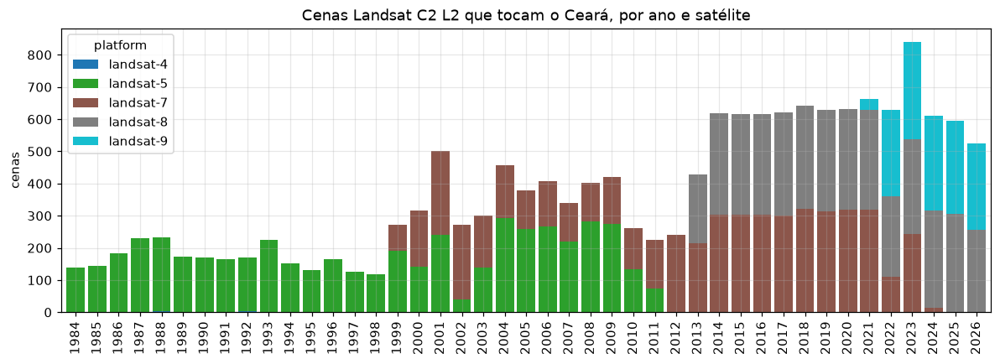

Categoria (T1 = qualidade geométrica para série temporal):
categoria
T1    0.931
T2    0.069
Pares path/row distintos: 19


In [56]:
meta["ano"] = meta.datetime.dt.year
meta["mes"] = meta.datetime.dt.month
tab = meta.pivot_table(index="ano", columns="platform", values="id", aggfunc="count").fillna(0)
ax = tab.plot(kind="bar", stacked=True, figsize=(13, 4), width=0.85, colormap="tab10")
ax.set_title("Cenas Landsat C2 L2 que tocam o Ceará, por ano e satélite"); ax.set_ylabel("cenas"); ax.set_xlabel("")
plt.show()
print("Categoria (T1 = qualidade geométrica para série temporal):")
print(meta.categoria.value_counts(normalize=True).round(3).to_string())
print(f"Pares path/row distintos: {meta.groupby(['path','row']).ngroups}")

### Nuvem por mês: quando dá para enxergar o campo

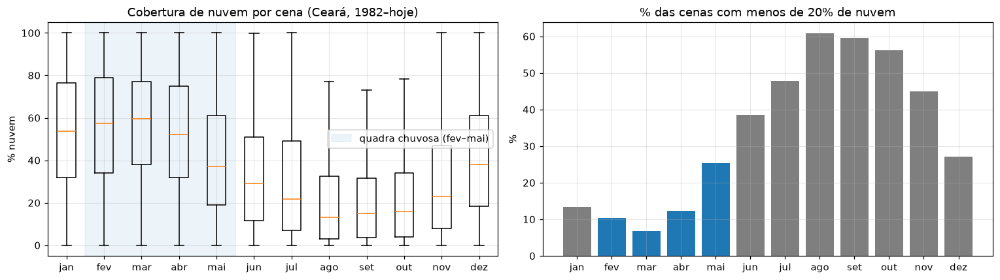

mes
jan    13.4
fev    10.3
mar     6.8
abr    12.3
mai    25.4
jun    38.5
jul    47.8
ago    60.8
set    59.6
out    56.2
nov    44.9
dez    27.1


In [57]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
dados_mes = [meta.loc[meta.mes == m, "cloud_cover"].dropna() for m in range(1, 13)]
axs[0].boxplot(dados_mes, tick_labels=MESES, showfliers=False)
axs[0].axvspan(1.5, 5.5, color="tab:blue", alpha=0.08, label="quadra chuvosa (fev–mai)")
axs[0].set_title("Cobertura de nuvem por cena (Ceará, 1982–hoje)"); axs[0].set_ylabel("% nuvem"); axs[0].legend()
p20 = meta.groupby("mes").cloud_cover.apply(lambda s: (s < 20).mean() * 100)
axs[1].bar(MESES, p20.values, color=["tab:blue" if 2 <= m <= 5 else "tab:gray" for m in range(1, 13)])
axs[1].set_title("% das cenas com menos de 20% de nuvem"); axs[1].set_ylabel("%")
plt.tight_layout(); plt.show()
print(p20.round(1).rename(lambda m: MESES[m - 1]).to_string())

### Fração de pixels limpos nas AOIs (máscara QA, Landsat 8/9)

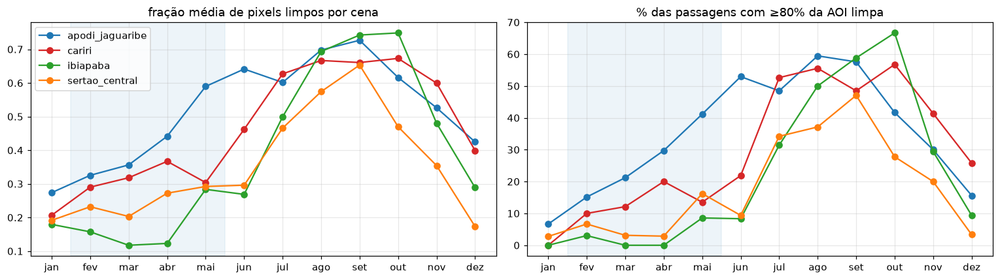

Passagens úteis (≥80% limpas) por ano e AOI:
aoi   apodi_jaguaribe  cariri  ibiapaba  sertao_central
ano                                                    
2013                6       6         6               5
2014                5       4         8               4
2015                7       9         5               4
2016                9       9         5               4
2017                9       5         9               4
2018               13       8         4               3
2019               11       8         6               4
2020                6       5         3               2
2021                7       5         4               3
2022               12      12         6               5
2023               14      15         6               9
2024               19      13        10              11
2025               15      12        11              10
2026               10      12         8               5


In [58]:
c89["mes"] = c89.datetime.dt.month
c89["ano"] = c89.datetime.dt.year
fv = c89.pivot_table(index="mes", columns="aoi", values="frac_valida", aggfunc="mean")
prob80 = c89.assign(ok=c89.frac_valida >= 0.8).pivot_table(index="mes", columns="aoi", values="ok", aggfunc="mean")
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for a in fv.columns:
    axs[0].plot(range(1, 13), fv[a], "-o", color=CORES[a], label=a)
    axs[1].plot(range(1, 13), prob80[a] * 100, "-o", color=CORES[a], label=a)
for ax, t in zip(axs, ["fração média de pixels limpos por cena", "% das passagens com ≥80% da AOI limpa"]):
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(MESES); ax.axvspan(1.5, 5.5, color="tab:blue", alpha=0.08); ax.set_title(t)
axs[0].legend(); plt.tight_layout(); plt.show()
n_limpas = c89[c89.frac_valida >= 0.8].groupby(["aoi", "ano"]).size().unstack(0)
print("Passagens úteis (≥80% limpas) por ano e AOI:")
print(n_limpas.fillna(0).astype(int).to_string())

## 7.4 Estatística descritiva nas AOIs (pixels, Landsat 8/9, 2013–hoje)

In [59]:
def abrir_cubo(nome, var="ndvi"):
    ds = xr.open_dataset(D / f"landsat_aoi_{nome}.nc", decode_cf=False)
    a = ds[var].values.astype(np.float32)
    a[a == -32768] = np.nan
    a *= 1e-4
    t = pd.to_datetime(xr.decode_cf(ds[["time"]]).time.values)
    return a, t, ds.x.values, ds.y.values

cubos = {n: abrir_cubo(n) for n in AOIS}
linhas = []
rng = np.random.default_rng(0)
amostras_pix = {}
for n, (a, t, x, y) in cubos.items():
    v = a[np.isfinite(a)]
    amostras_pix[n] = rng.choice(v, size=min(400_000, v.size), replace=False)
    s = pd.Series(amostras_pix[n])
    linhas.append({"aoi": n, "cenas_no_cubo": a.shape[0], "pixels_validos_M": v.size / 1e6,
                   "media": s.mean(), "dp": s.std(), "p05": s.quantile(.05), "p25": s.quantile(.25), "mediana": s.median(),
                   "p75": s.quantile(.75), "p95": s.quantile(.95), "assimetria": s.skew(), "curtose": s.kurt(),
                   "frac_NDVI<0.2 (solo exposto)": (s < 0.2).mean(), "frac_NDVI>0.6 (veg. densa)": (s > 0.6).mean()})
desc = pd.DataFrame(linhas).set_index("aoi").round(3)
desc

,cenas_no_cubo,pixels_validos_M,media,dp,p05,p25,mediana,p75,p95,assimetria,curtose,frac_NDVI<0.2 (solo exposto),frac_NDVI>0.6 (veg. densa)
aoi,,,,,,,,,,,,,
apodi_jaguaribe,330,28.757,0.543,0.238,0.191,0.345,0.494,0.792,0.884,0.077,-1.397,0.058,0.426
cariri,317,25.864,0.572,0.205,0.243,0.409,0.569,0.758,0.872,-0.132,-1.019,0.025,0.457
sertao_central,309,19.468,0.493,0.210,0.228,0.336,0.430,0.668,0.860,0.350,0.055,0.030,0.305
ibiapaba,316,21.619,0.625,0.201,0.251,0.479,0.655,0.803,0.880,-0.545,-0.591,0.027,0.581


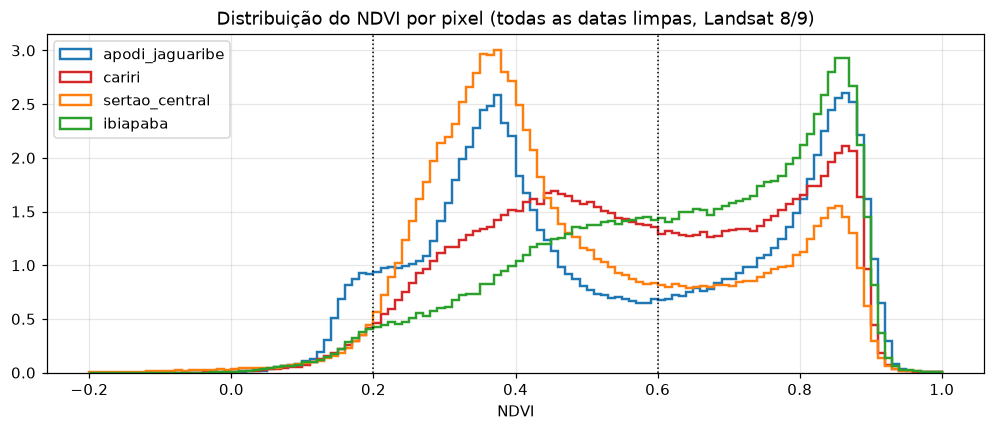

In [60]:
fig, ax = plt.subplots(figsize=(11, 4))
for n, v in amostras_pix.items():
    ax.hist(v, bins=120, range=(-0.2, 1.0), histtype="step", lw=1.6, density=True, color=CORES[n], label=n)
ax.axvline(0.2, color="k", ls=":", lw=1); ax.axvline(0.6, color="k", ls=":", lw=1)
ax.set_title("Distribuição do NDVI por pixel (todas as datas limpas, Landsat 8/9)"); ax.set_xlabel("NDVI"); ax.legend()
plt.show()

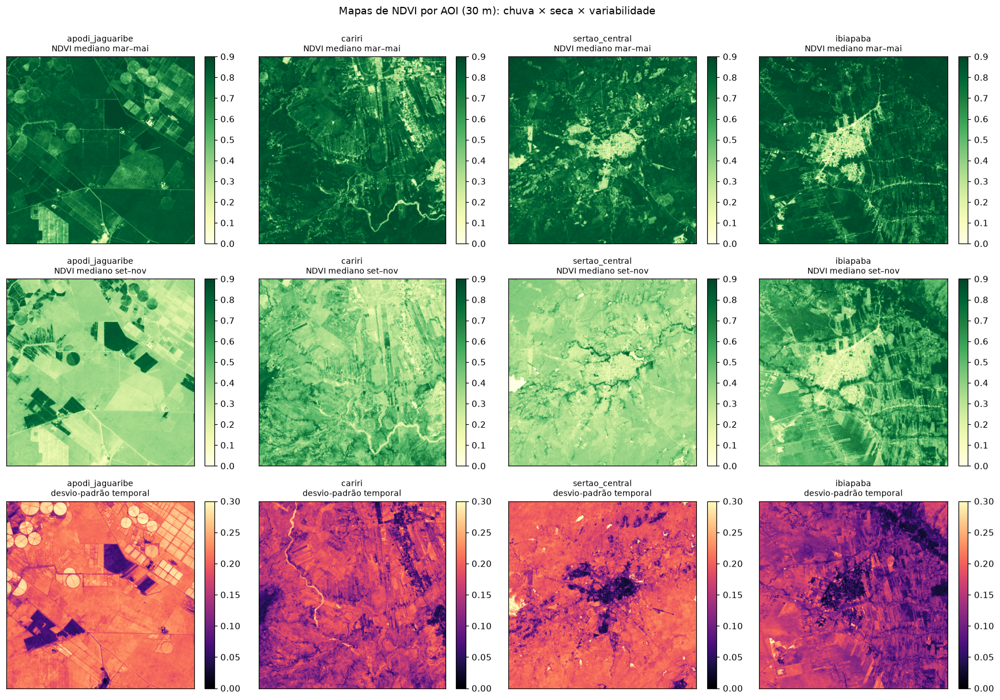

In [61]:
fig, axs = plt.subplots(3, 4, figsize=(16, 11))
for j, (n, (a, t, x, y)) in enumerate(cubos.items()):
    ext = [x.min() / 1e3, x.max() / 1e3, y.min() / 1e3, y.max() / 1e3]
    chuva = np.isin(t.month, [3, 4, 5]); seca = np.isin(t.month, [9, 10, 11])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m_ch = np.nanmedian(a[chuva], axis=0); m_se = np.nanmedian(a[seca], axis=0); dp = np.nanstd(a, axis=0)
    for i, (img, tit, cm, vmin, vmax) in enumerate([(m_ch, "NDVI mediano mar–mai", "YlGn", 0, 0.9),
                                                     (m_se, "NDVI mediano set–nov", "YlGn", 0, 0.9),
                                                     (dp, "desvio-padrão temporal", "magma", 0, 0.3)]):
        im = axs[i, j].imshow(img, extent=ext, cmap=cm, vmin=vmin, vmax=vmax)
        axs[i, j].set_title(f"{n}\n{tit}", fontsize=9); axs[i, j].set_xticks([]); axs[i, j].set_yticks([])
        plt.colorbar(im, ax=axs[i, j], fraction=0.046)
plt.suptitle("Mapas de NDVI por AOI (30 m): chuva × seca × variabilidade", y=1.0); plt.tight_layout(); plt.show()

**Como ler os mapas:**
- Na **Chapada do Apodi**, os talhões irrigados aparecem como blocos verdes mesmo na seca (set–nov). O contraste com
  a Caatinga ao redor é o sinal de irrigação.
- No **Sertão Central** e no **Cariri**, quase tudo fica marrom na seca. O desvio-padrão alto marca áreas de lavoura e
  pasto de sequeiro, que respondem forte à chuva.
- A **Ibiapaba** mantém NDVI mais alto o ano todo, por ser serra úmida, com chuva orográfica e nuvem.

## 7.5 Sazonalidade: o calendário do verde

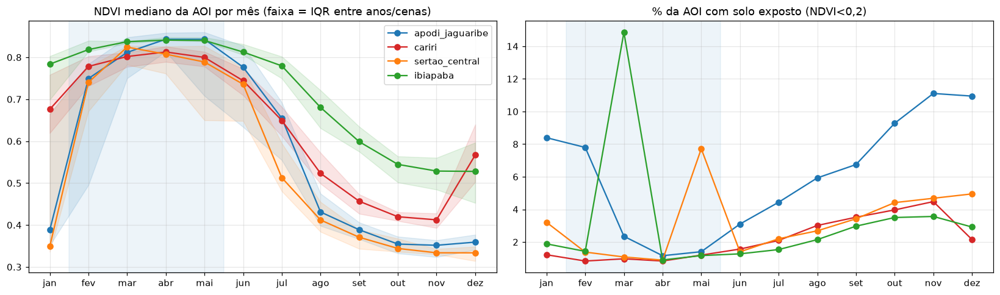

                mes_pico mes_vale  amplitude_NDVI
aoi                                              
apodi_jaguaribe      mai      nov           0.491
cariri               abr      nov           0.400
ibiapaba             abr      dez           0.313
sertao_central       mar      dez           0.491


In [62]:
c89v = c89[c89.frac_valida >= 0.3].copy()
clim = c89v.groupby(["aoi", "mes"]).ndvi_mediana.agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75), "count"])
clim.columns = ["mediana", "q25", "q75", "n"]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for n in AOIS:
    c = clim.loc[n]
    axs[0].plot(c.index, c.mediana, "-o", color=CORES[n], label=n)
    axs[0].fill_between(c.index, c.q25, c.q75, color=CORES[n], alpha=0.12)
    s = c89v[c89v.aoi == n].groupby("mes").frac_solo_exposto.mean()
    axs[1].plot(s.index, s * 100, "-o", color=CORES[n], label=n)
for ax, t in zip(axs, ["NDVI mediano da AOI por mês (faixa = IQR entre anos/cenas)", "% da AOI com solo exposto (NDVI<0,2)"]):
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(MESES); ax.axvspan(1.5, 5.5, color="tab:blue", alpha=0.08); ax.set_title(t)
axs[0].legend(); plt.tight_layout(); plt.show()
pico = clim.mediana.groupby(level=0).idxmax().apply(lambda x: MESES[x[1] - 1])
vale = clim.mediana.groupby(level=0).idxmin().apply(lambda x: MESES[x[1] - 1])
amp = clim.mediana.groupby(level=0).agg(lambda s: s.max() - s.min())
print(pd.DataFrame({"mes_pico": pico, "mes_vale": vale, "amplitude_NDVI": amp.round(3)}).to_string())

**Leitura agronômica:**
- O pico do NDVI vem **depois** do pico da chuva (abr–mai). Isso indica uma defasagem de ~1–2 meses entre a chuva e
  o verde.
- O **solo exposto** cresce de agosto a dezembro. É a **janela de campo nu**, exatamente onde o desafio pede para
  pensar em cobertura do solo e rotação: palhada, consórcio, forrageiras perenes como palma ou capim, ou culturas
  de ciclo curto no início das chuvas.

## 7.6 Tendências (Mann-Kendall + Sen)
### Série longa por AOI (1984–hoje; TM/ETM+ e OLI juntos)
Atenção: o NDVI do OLI é ligeiramente maior que o do TM/ETM+ (Roy et al. 2016). Por isso testamos a tendência na série
completa e também só na era OLI (2013+).

In [63]:
todas = pd.concat([hist.assign(sensor="TM/ETM+"), c89.assign(sensor="OLI")], ignore_index=True) if len(hist) else c89.assign(sensor="OLI")
todas = todas[(todas.frac_valida >= 0.3) & todas.ndvi_mediana.notna()].copy()
todas["ano"] = todas.datetime.dt.year
anual = todas.groupby(["aoi", "ano"]).ndvi_mediana.median().unstack(0)
seca_anual = todas[todas.datetime.dt.month.isin([8, 9, 10, 11])].groupby(["aoi", "ano"]).ndvi_mediana.median().unstack(0)
linhas = []
for n in AOIS:
    for rot, serie in (("anual", anual), ("seca ago–nov", seca_anual)):
        if n not in serie:
            continue
        for per, s in (("série completa", serie[n].dropna()), ("só OLI 2013+", serie[n].dropna().loc[2013:])):
            if len(s) >= 6:
                r = mk.original_test(s.values)
                linhas.append({"aoi": n, "estatística": rot, "período": per, "anos": len(s), "início": s.index.min(),
                               "tendência": r.trend, "p": round(r.p, 4), "Sen_NDVI_por_década": round(r.slope * 10, 4)})
pd.DataFrame(linhas)

,aoi,estatística,período,anos,início,tendência,p,Sen_NDVI_por_década
0,apodi_jaguaribe,anual,série completa,43,1984,no trend,0.9833,0.0003
1,apodi_jaguaribe,anual,só OLI 2013+,14,2013,increasing,0.0375,0.1587
2,apodi_jaguaribe,seca ago–nov,série completa,42,1984,increasing,0.0486,0.0265
3,apodi_jaguaribe,seca ago–nov,só OLI 2013+,14,2013,no trend,0.0627,0.0519
4,cariri,anual,série completa,43,1984,no trend,0.0900,0.0217
5,cariri,anual,só OLI 2013+,14,2013,no trend,1.0000,-0.0035
6,cariri,seca ago–nov,série completa,43,1984,no trend,0.4143,0.0090
7,cariri,seca ago–nov,só OLI 2013+,14,2013,no trend,0.9128,0.0102
8,sertao_central,anual,série completa,43,1984,no trend,0.8835,0.0032
9,sertao_central,anual,só OLI 2013+,14,2013,no trend,1.0000,0.0027


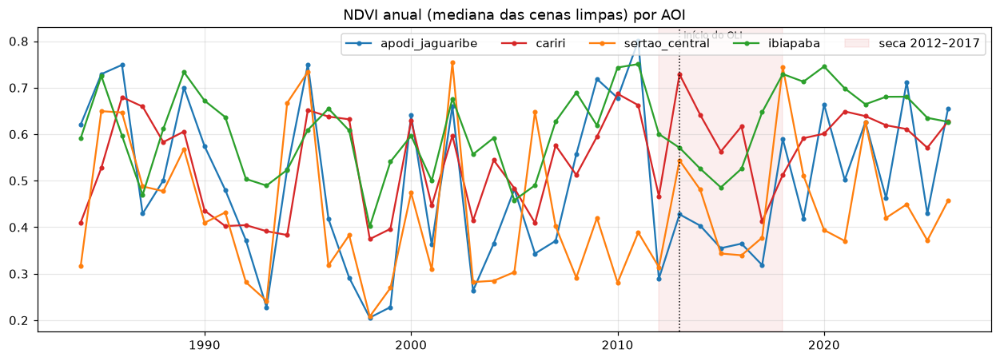

In [64]:
fig, ax = plt.subplots(figsize=(14, 4.5))
for n in AOIS:
    if n in anual:
        ax.plot(anual.index, anual[n], "-o", ms=3, color=CORES[n], label=n)
ax.axvspan(2012, 2017.99, color="tab:red", alpha=0.08, label="seca 2012–2017")
ax.axvline(2013, color="k", ls=":", lw=1)
ax.text(2013.2, ax.get_ylim()[1] * 0.97, "início do OLI", fontsize=8)
ax.set_title("NDVI anual (mediana das cenas limpas) por AOI"); ax.legend(ncol=5); plt.show()

### Tendência por pixel (Sen da mediana de NDVI da seca, 2013–hoje)

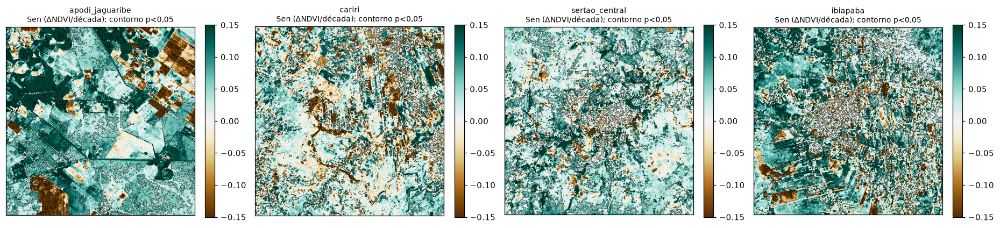

,aoi,"% pixels esverdeando (p<0,05)","% pixels perdendo verde (p<0,05)",Sen mediano/década
0,apodi_jaguaribe,35.687,3.682,0.057
1,cariri,13.404,8.452,0.015
2,sertao_central,23.103,2.879,0.035
3,ibiapaba,25.973,5.333,0.044


In [65]:
fig, axs = plt.subplots(1, 4, figsize=(17, 4.3))
resumo_pix = []
for j, (n, (a, t, x, y)) in enumerate(cubos.items()):
    anos = np.arange(2013, t.year.max() + 1)
    comp = []
    for ano in anos:
        m = (t.year == ano) & np.isin(t.month, [8, 9, 10, 11])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            comp.append(np.nanmedian(a[m], axis=0) if m.sum() else np.full(a.shape[1:], np.nan))
    comp = np.stack(comp, axis=-1)
    sen, z, p = mk_sen_vetorizado(comp, anos.astype(float))
    ext = [x.min() / 1e3, x.max() / 1e3, y.min() / 1e3, y.max() / 1e3]
    im = axs[j].imshow(sen * 10, extent=ext, cmap="BrBG", vmin=-0.15, vmax=0.15)
    axs[j].contour(np.flipud(p < 0.05), levels=[0.5], colors="k", linewidths=0.3, extent=ext, origin="lower")
    axs[j].set_title(f"{n}\nSen (ΔNDVI/década); contorno p<0,05", fontsize=9); axs[j].set_xticks([]); axs[j].set_yticks([])
    plt.colorbar(im, ax=axs[j], fraction=0.046)
    ok = np.isfinite(p)
    resumo_pix.append({"aoi": n, "% pixels esverdeando (p<0,05)": 100 * ((p < 0.05) & (sen > 0))[ok].mean(),
                       "% pixels perdendo verde (p<0,05)": 100 * ((p < 0.05) & (sen < 0))[ok].mean(),
                       "Sen mediano/década": float(np.nanmedian(sen) * 10)})
plt.tight_layout(); plt.show()
pd.DataFrame(resumo_pix).round(3)

## 7.7 Variabilidade interanual e extremos (secas)

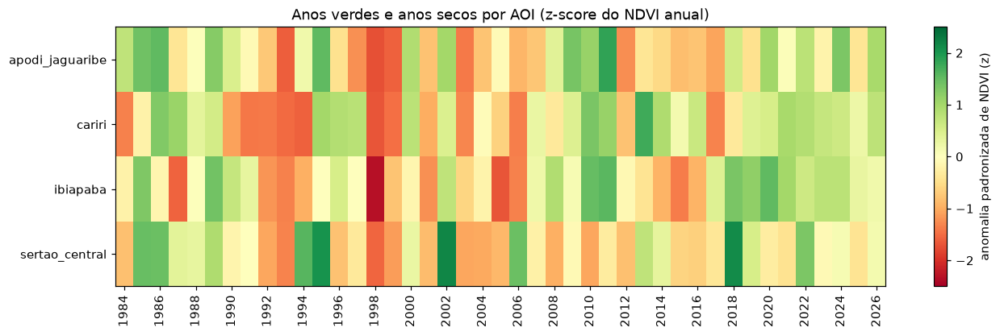

5 anos mais 'secos' (média dos z das AOIs): 1998 (-1.82), 1993 (-1.44), 1999 (-1.24), 1992 (-1.09), 2003 (-1.08)
5 anos mais 'verdes': 1995 (+1.15), 2002 (+1.10), 2011 (+1.05), 1986 (+1.03), 1989 (+1.02)
z médio 2012–2017 por AOI: {'apodi_jaguaribe': -0.81, 'cariri': 0.22, 'ibiapaba': -0.56, 'sertao_central': -0.23}


In [66]:
z_an = (anual - anual.mean()) / anual.std()
fig, ax = plt.subplots(figsize=(14, 3.8))
im = ax.imshow(z_an.T.values, aspect="auto", cmap="RdYlGn", vmin=-2.5, vmax=2.5)
ax.set_yticks(range(len(z_an.columns))); ax.set_yticklabels(z_an.columns)
ax.set_xticks(range(0, len(z_an.index), 2)); ax.set_xticklabels(z_an.index[::2], rotation=90)
plt.colorbar(im, ax=ax, label="anomalia padronizada de NDVI (z)")
ax.set_title("Anos verdes e anos secos por AOI (z-score do NDVI anual)"); ax.grid(False); plt.show()
media_z = z_an.mean(axis=1).sort_values()
print("5 anos mais 'secos' (média dos z das AOIs):", ", ".join(f"{a} ({v:+.2f})" for a, v in media_z.head(5).items()))
print("5 anos mais 'verdes':", ", ".join(f"{a} ({v:+.2f})" for a, v in media_z.tail(5)[::-1].items()))
if len(z_an.loc[2012:2017]):
    print("z médio 2012–2017 por AOI:", z_an.loc[2012:2017].mean().round(2).to_dict())

**Cuidado com o salto de sensor.** O NDVI médio da era OLI (2013+) é maior que o da era TM/ETM+ em quase todas as
AOIs (tabela abaixo). Parte disso é diferença de sensor (Roy et al. 2016), não só clima. Por isso a anomalia na
série completa "esconde" parte da seca de 2012–2017. Para comparar anos, padronizamos **dentro de cada era**.

In [67]:
print("NDVI anual médio por era:")
print(pd.DataFrame({"TM/ETM+ 1984–2012": anual.loc[:2012].mean(), "OLI 2013+": anual.loc[2013:].mean(),
                    "salto": anual.loc[2013:].mean() - anual.loc[:2012].mean()}).round(3).to_string())
oli = anual.loc[2013:2025]
z_oli = (oli - oli.mean()) / oli.std()
print("\nAnos mais secos dentro da era OLI (média dos z):", z_oli.mean(axis=1).sort_values().head(5).round(2).to_dict())
pk = todas[todas.datetime.dt.month.isin([3, 4, 5, 6])].groupby(["aoi", "ano"]).ndvi_p90.max().unstack(0).loc[2013:2025]
print("Picos de chuva mais fracos na era OLI (média dos z do p90 mar–jun):", ((pk - pk.mean()) / pk.std()).mean(axis=1).sort_values().head(5).round(2).to_dict())
tm = anual.loc[:2012]
print("Anos mais secos dentro da era TM/ETM+:", ((tm - tm.mean()) / tm.std()).mean(axis=1).sort_values().head(6).round(2).to_dict())

NDVI anual médio por era:
                 TM/ETM+ 1984–2012  OLI 2013+  salto
aoi                                                 
apodi_jaguaribe              0.494      0.495  0.001
cariri                       0.524      0.599  0.075
ibiapaba                     0.595      0.638  0.042
sertao_central               0.422      0.459  0.037

Anos mais secos dentro da era OLI (média dos z): {2017: -1.08, 2015: -1.06, 2016: -0.75, 2025: -0.38, 2014: -0.29}
Picos de chuva mais fracos na era OLI (média dos z do p90 mar–jun): {2016: -1.03, 2014: -1.01, 2017: -0.96, 2020: -0.43, 2021: -0.24}
Anos mais secos dentro da era TM/ETM+: {1998: -1.61, 1993: -1.24, 1999: -1.05, 1992: -0.92, 2003: -0.9, 2001: -0.8}


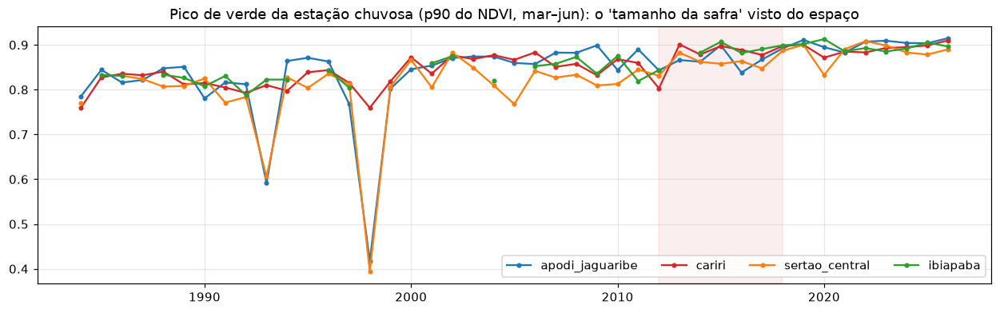

In [68]:
pico_anual =todas[todas.datetime.dt.month.isin([3, 4, 5, 6])].groupby(["aoi", "ano"]).ndvi_p90.max().unstack(0)
fig, ax = plt.subplots(figsize=(14, 3.8))
for n in AOIS:
    if n in pico_anual:
        ax.plot(pico_anual.index, pico_anual[n], "-o", ms=3, color=CORES[n], label=n)
ax.axvspan(2012, 2017.99, color="tab:red", alpha=0.08)
ax.set_title("Pico de verde da estação chuvosa (p90 do NDVI, mar–jun): o 'tamanho da safra' visto do espaço"); ax.legend(ncol=4)
plt.show()

## 7.8 Insights e ideias para o produto
1. **Janela de visibilidade.** No Ceará, de fevereiro a maio, poucas cenas Landsat ficam com menos de 20% de nuvem
   (gráfico 7.3). De julho a dezembro, quase todas as passagens são úteis. Por isso o produto não deve depender de uma
   imagem óptica na quadra chuvosa: convém combinar com SAR (NISAR/Sentinel-1) ou com o HLS, que é mais frequente.
2. **Calendário do verde e janela de campo nu.** O pico de NDVI vem ~1–2 meses depois do pico da chuva, e o solo
   exposto domina de agosto a dezembro no sequeiro. Esse é o insumo direto para recomendar **cobertura do solo** e
   **datas de semeadura**.
3. **Irrigação aparece como "verde na seca".** NDVI de seca alto e estável identifica perímetros irrigados (Apodi).
   É um rótulo barato para separar sistemas irrigados de sequeiro em qualquer lugar do mundo, sem cadastro.
4. **Secas ficam registradas.** A série 1984–hoje marca, sincronizados entre as AOIs, os anos de seca conhecidos do
   Nordeste:
   - 1992–93, 1998–99 e 2003 na era TM/ETM+;
   - 2015–2017 (fim da grande seca de 2012–2017) dentro da era OLI.

   Daí sai um índice de **risco histórico por talhão**: quantos anos em 40 o verde falhou. Para isso as anomalias
   precisam ser padronizadas **por sensor**, por causa do salto TM → OLI.
5. **Tendência por pixel separa** áreas que estão degradando (perda de verde na seca) de áreas que estão sendo
   convertidas para irrigação (ganho). Serve como camada "saúde do solo/cobertura" no mapa do agricultor.

**Ideias de modelo:**
- Classificador de sistema (irrigado × sequeiro × pasto × Caatinga) com features fenológicas: pico, vale, amplitude,
  integral de NDVI e NDVI de seca.
- Detecção de mudança (BFAST/CCDC) para datar as conversões.
- Previsão do NDVI de pico a partir da chuva de fev–mar, usando as seções de clima, para alerta precoce de quebra
  de safra.

# 8. Sentinel-2 L2A (ESA Copernicus) e HLS (NASA)

**O que é:** imagens multiespectrais de 10–20 m dos satélites Sentinel-2A/B/C da ESA, com bandas de vermelho, NIR,
*red-edge* e SWIR. A revisita é de 5 dias com dois satélites; onde duas órbitas se sobrepõem (caso da AOI do Apodi), cai
para ~2,5 dias.
O **HLS** (Harmonized Landsat Sentinel-2, da NASA) junta Landsat 8/9 e Sentinel-2 numa grade única de 30 m, com
correções para os dois sensores ficarem comparáveis.

**Como baixamos:**
- Sentinel-2: Planetary Computer (`sentinel-2-l2a`). O Earth Search (`sentinel-2-c1-l2a`) foi testado e descartado
  por ter o arquivo incompleto (numa AOI: 2017 com 1 cena, 2018 com 42, 2022 com 13, contra ~140 no Planetary
  Computer).
- Offset das *baselines* ≥ 04.00 (desde 25/01/2022): o DN ganhou +1000, então refl = (DN − 1000)/10000. Conferimos
  que o valor bate exatamente com o Earth Search em datas comuns.
- Cubos de 20 m (NDVI, NDMI) nas 4 AOIs, de 2017 até hoje, só com cenas de nuvem ≤ 90%. Máscara SCL ∈ {4 vegetação,
  5 solo, 6 água}.
- HLS L30/S30 (2020–hoje), com estatísticas por cena nas AOIs (nuvem ≤ 80%; máscara Fmask bits 1–3).

In [69]:
import json
import sys
import warnings

sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymannkendall as mk
import xarray as xr
from comum import AOIS, DADOS, paises_gdf

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
D = DADOS / "sentinel2"
CORES = {"apodi_jaguaribe": "#1f77b4", "cariri": "#d62728", "sertao_central": "#ff7f0e", "ibiapaba": "#2ca02c"}
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

def ler(nome):
    p = D / nome
    if not p.exists():
        return pd.DataFrame()
    df = pd.read_parquet(p)
    if "datetime" in df:
        df["datetime"] = pd.to_datetime(df["datetime"], utc=True).dt.tz_localize(None)
    return df

meta, glob, cen, hls = ler("s2_stac_ceara.parquet"), ler("s2_stac_global.parquet"), ler("s2_aoi_cenas.parquet"), ler("hls_aoi_cenas.parquet")
man = json.loads((D / "MANIFESTO.json").read_text(encoding="utf-8")) if (D / "MANIFESTO.json").exists() else {}
print(f"S2 no Ceará (STAC): {len(meta):,} itens | cenas nas AOIs: {len(cen):,} | HLS nas AOIs: {len(hls):,}")

S2 no Ceará (STAC): 32,721 itens | cenas nas AOIs: 3,565 | HLS nas AOIs: 2,486


## 8.1 Ficha técnica

In [70]:
pd.DataFrame([
    ("Provedor", "ESA/Copernicus (Sentinel-2) e NASA (HLS v2.0); espelho aberto no Microsoft Planetary Computer"),
    ("Produto", "Sentinel-2 L2A (Sen2Cor): reflectância de superfície + SCL (classificação de cena)"),
    ("Resolução", "10 m (B02/B03/B04/B08), 20 m (red-edge, B11/B12, SCL), 60 m (atmosféricas); usamos 20 m"),
    ("Revisita", "5 dias com 2 satélites (S2A+S2B; S2C entrou em 2025); ~2,5 dias onde duas órbitas se sobrepõem (AOI Apodi: 1.421 datas em ~10 anos; demais AOIs: ~710)"),
    ("Período no Ceará", f"{meta.datetime.min():%Y-%m-%d} a {meta.datetime.max():%Y-%m-%d}" if len(meta) else "-"),
    ("HLS", "30 m, Landsat 8/9 (L30) + Sentinel-2 (S30) harmonizados; Planetary Computer a partir de 2020"),
    ("Acesso", "aberto (Copernicus Data Space pede cadastro gratuito; Planetary Computer não)"),
    ("Tamanho local", f"{man.get('tamanho_bytes', 0)/1e9:.2f} GB"),
], columns=["item", "valor"])

,item,valor
0,Provedor,ESA/Copernicus (Sentinel-2) e NASA (HLS v2.0); espelho aberto no Microsoft Planetary Computer
1,Produto,Sentinel-2 L2A (Sen2Cor): reflectância de superfície + SCL (classificação de cena)
2,Resolução,"10 m (B02/B03/B04/B08), 20 m (red-edge, B11/B12, SCL), 60 m (atmosféricas); usamos 20 m"
3,Revisita,"5 dias com 2 satélites (S2A+S2B; S2C entrou em 2025); ~2,5 dias onde duas órbitas se sobrepõem (AOI Apodi: 1.421 dat..."
4,Período no Ceará,2015-11-26 a 2026-11-13
5,HLS,"30 m, Landsat 8/9 (L30) + Sentinel-2 (S30) harmonizados; Planetary Computer a partir de 2020"
6,Acesso,aberto (Copernicus Data Space pede cadastro gratuito; Planetary Computer não)
7,Tamanho local,1.74 GB


## 8.2 Validação de cobertura global (amostras de 1° em 2023)

In [71]:
def resumo(g):
    g = g.dropna(subset=["id"])
    if g.empty:
        return pd.Series({"itens": 0, "datas": 0, "revisita_d": np.nan, "revisita_limpa_d": np.nan, "nuvem_mediana": np.nan})
    d = np.sort(g.datetime.dt.normalize().unique()); l = np.sort(g[g.cloud_cover < 20].datetime.dt.normalize().unique())
    gap = lambda x: float(np.median(np.diff(x).astype("timedelta64[D]").astype(int))) if len(x) > 1 else np.nan
    return pd.Series({"itens": len(g), "datas": len(d), "revisita_d": gap(d), "revisita_limpa_d": gap(l), "nuvem_mediana": g.cloud_cover.median()})

cob = glob.groupby(["amostra", "lon", "lat"]).apply(resumo).reset_index().sort_values("lat", ascending=False)
cob

,amostra,lon,lat,itens,datas,revisita_d,revisita_limpa_d,nuvem_mediana
11,Groenlandia_N,-40.0,81.0,7418.0,193.0,1.0,1.0,34.624380
24,Svalbard,16.0,78.5,1457.0,215.0,1.0,2.0,74.701011
5,Canada_N,-95.0,70.0,1401.0,197.0,1.0,2.0,75.375295
23,Siberia,100.0,62.0,618.0,241.0,1.0,3.0,74.933377
26,Ucrania,32.0,49.0,961.0,146.0,2.0,3.0,61.228281
10,Franca,2.0,48.5,975.0,146.0,2.0,5.0,79.798579
17,Mongolia,103.0,46.0,843.0,146.0,3.0,3.0,15.986654
14,Iowa_US,-93.5,42.0,1092.0,145.0,3.0,3.0,45.330998
7,China_N,115.0,37.0,849.0,143.0,3.0,5.0,39.019665
15,Japao,139.0,36.0,879.0,146.0,3.0,5.0,49.640739


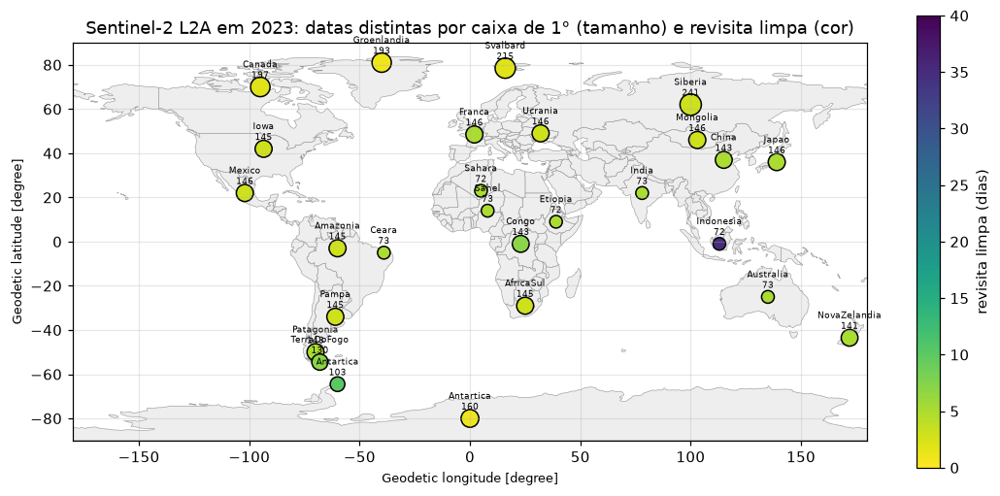

Latitude máx/mín com dados: 81.0 -80.0 | sem dados: nenhuma
Revisita mediana: 3 dias; revisita limpa mediana: 5 dias


,lat,meses,lista
amostra,,,
Groenlandia_N,81.0,7,"3,4,5,6,7,8,9"
Svalbard,78.5,8,"3,4,5,6,7,8,9,10"
Canada_N,70.0,9,"2,3,4,5,6,7,8,9,10"
Siberia,62.0,11,"1,2,3,4,5,6,7,8,9,10,11"
Ucrania,49.0,12,"1,2,3,4,5,6,7,8,9,10,11,12"
Franca,48.5,12,"1,2,3,4,5,6,7,8,9,10,11,12"
Mongolia,46.0,12,"1,2,3,4,5,6,7,8,9,10,11,12"
Iowa_US,42.0,12,"1,2,3,4,5,6,7,8,9,10,11,12"
China_N,37.0,12,"1,2,3,4,5,6,7,8,9,10,11,12"


In [72]:
fig, ax = plt.subplots(figsize=(12, 5.5))
paises_gdf().plot(ax=ax, color="#eeeeee", edgecolor="#999999", lw=0.4)
sc = ax.scatter(cob.lon, cob.lat, s=15 + cob.datas * 0.8, c=cob.revisita_limpa_d, cmap="viridis_r", edgecolor="k", vmin=0, vmax=40)
for _, r in cob.iterrows():
    ax.annotate(f"{r.amostra.split('_')[0]}\n{int(r.datas)}", (r.lon, r.lat), fontsize=6, ha="center", xytext=(0, 6), textcoords="offset points")
plt.colorbar(sc, ax=ax, label="revisita limpa (dias)")
ax.set_title("Sentinel-2 L2A em 2023: datas distintas por caixa de 1° (tamanho) e revisita limpa (cor)")
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); plt.show()
ok = cob[cob.itens > 0]
print("Latitude máx/mín com dados:", ok.lat.max(), ok.lat.min(), "| sem dados:", ", ".join(cob[cob.itens == 0].amostra) or "nenhuma")
print(f"Revisita mediana: {ok.revisita_d.median():.0f} dias; revisita limpa mediana: {ok.revisita_limpa_d.median():.0f} dias")
glob["mes"] = glob.datetime.dt.month
glob.dropna(subset=["id"]).groupby("amostra").agg(lat=("lat", "first"), meses=("mes", lambda s: len(set(s.dropna()))),
    lista=("mes", lambda s: ",".join(str(int(m)) for m in sorted(set(s.dropna()))))).sort_values("lat", ascending=False)

**Veredito de cobertura (tirado das tabelas acima):** o Sentinel-2 L2A é **global sobre terra**. As 27 caixas têm
dados em 2023, do norte da Groenlândia (81°N) ao interior da Antártida (80°S). Os limites:
1. **Iluminação:** acima de ~60° só há imagens nos meses com Sol. Entre os trópicos e as latitudes médias há os
   12 meses.
2. **Número de órbitas:** caixas cobertas por uma órbita têm ~73 datas/ano (5 dias). Onde duas órbitas se sobrepõem,
   são ~145 datas/ano (2–3 dias). No Ceará, as AOIs ficam nessas faixas de sobreposição.
3. **Histórico curto:** os dados úteis começam em 2015–2017, então para tendências longas e secas antigas o Landsat
   é a base.

Para lavoura em **qualquer país**, o Sentinel-2 é a camada de alta frequência do produto.

## 8.3 Qualidade e disponibilidade no Ceará

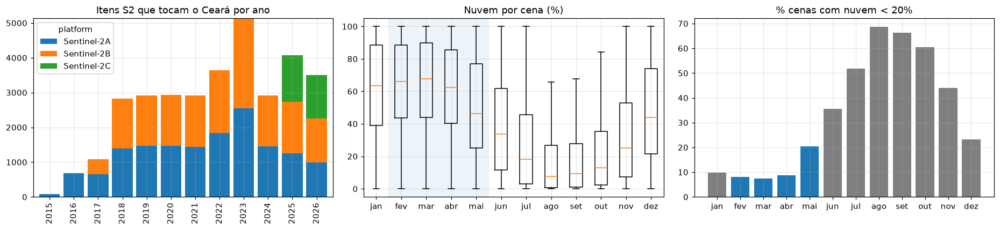

Baselines de processamento (mistura de versões ao longo do tempo):
baseline
02.12    11753
05.11     5617
05.10     4749
04.00     3161
05.12     2513
05.09     2350
03.00     1887
05.13      691
Tiles MGRS distintos: 29


In [73]:
meta["ano"] = meta.datetime.dt.year; meta["mes"] = meta.datetime.dt.month
fig, axs = plt.subplots(1, 3, figsize=(17, 4))
meta.pivot_table(index="ano", columns="platform", values="id", aggfunc="count").fillna(0).plot(kind="bar", stacked=True, ax=axs[0], width=0.85)
axs[0].set_title("Itens S2 que tocam o Ceará por ano"); axs[0].set_xlabel("")
axs[1].boxplot([meta.loc[meta.mes == m, "cloud_cover"].dropna() for m in range(1, 13)], tick_labels=MESES, showfliers=False)
axs[1].axvspan(1.5, 5.5, color="tab:blue", alpha=0.08); axs[1].set_title("Nuvem por cena (%)")
p20 = meta.groupby("mes").cloud_cover.apply(lambda s: (s < 20).mean() * 100)
axs[2].bar(MESES, p20.values, color=["tab:blue" if 2 <= m <= 5 else "tab:gray" for m in range(1, 13)]); axs[2].set_title("% cenas com nuvem < 20%")
plt.tight_layout(); plt.show()
print("Baselines de processamento (mistura de versões ao longo do tempo):")
print(meta.baseline.value_counts().head(10).to_string())
print(f"Tiles MGRS distintos: {meta.mgrs.nunique()}")

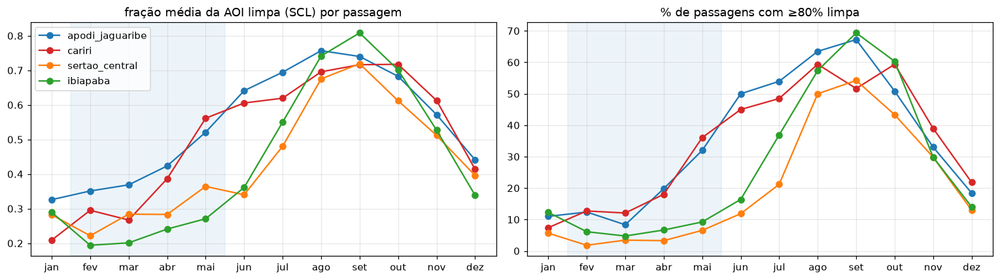

Passagens úteis (≥80% limpas) por ano:
aoi   apodi_jaguaribe  cariri  ibiapaba  sertao_central
ano                                                    
2017               20       6        12               6
2018               52      26        29              18
2019               61      26        18              15
2020               57      27        18              20
2021               46      22        19              10
2022               35      19        14              15
2023               49      27        17              15
2024               50      27        18              12
2025               78      32        27              25
2026               60      40        26              11


In [74]:
cen["mes"] = cen.datetime.dt.month; cen["ano"] = cen.datetime.dt.year
cv = cen[~cen.get("pulada_nuvem", pd.Series(False, index=cen.index)).fillna(False).astype(bool)]
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for n in AOIS:
    g = cen[cen.aoi == n]
    axs[0].plot(range(1, 13), g.groupby("mes").frac_valida.mean().reindex(range(1, 13)), "-o", color=CORES[n], label=n)
    axs[1].plot(range(1, 13), (g.assign(ok=g.frac_valida >= 0.8).groupby("mes").ok.mean().reindex(range(1, 13))) * 100, "-o", color=CORES[n])
for ax, t in zip(axs, ["fração média da AOI limpa (SCL) por passagem", "% de passagens com ≥80% limpa"]):
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(MESES); ax.axvspan(1.5, 5.5, color="tab:blue", alpha=0.08); ax.set_title(t)
axs[0].legend(); plt.tight_layout(); plt.show()
uteis = cen[cen.frac_valida >= 0.8].groupby(["aoi", "ano"]).size().unstack(0).fillna(0).astype(int)
print("Passagens úteis (≥80% limpas) por ano:"); print(uteis.to_string())

## 8.4 Estatística descritiva nas AOIs (20 m)

In [75]:
MAX_CENAS = 300  # amostra de cenas por AOI (os cubos têm 600–1200 datas; limita memória e tempo)
rng = np.random.default_rng(1)
linhas, mapas = [], {}
for n in AOIS:
    arq = D / f"s2_aoi_{n}.nc"
    if not arq.exists():
        continue
    ds = xr.open_dataset(arq, decode_cf=False)
    sid = pd.Series(ds.scene_id.values)
    fv = sid.map(cen.drop_duplicates("id").set_index("id").frac_valida).fillna(0).values
    idx = np.flatnonzero(fv >= 0.5)
    if len(idx) > MAX_CENAS:
        idx = np.sort(rng.choice(idx, MAX_CENAS, replace=False))
    a = ds["ndvi"].isel(time=idx).values.astype(np.float32); a[a == -32768] = np.nan; a *= 1e-4
    v = a[np.isfinite(a)]; s = pd.Series(rng.choice(v, size=min(400_000, v.size), replace=False))
    linhas.append({"aoi": n, "datas_no_cubo": ds.sizes["time"], "cenas_usadas(≥50% limpas)": len(idx), "media": s.mean(), "dp": s.std(),
                   "p05": s.quantile(.05), "mediana": s.median(), "p95": s.quantile(.95), "assimetria": s.skew(), "curtose": s.kurt(),
                   "frac_solo_exposto": (s < 0.2).mean(), "frac_veg_densa": (s > 0.6).mean()})
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        p90 = np.nanpercentile(a, 90, axis=0); p10 = np.nanpercentile(a, 10, axis=0)
    mapas[n] = (p90, p10, [ds.x.values.min() / 1e3, ds.x.values.max() / 1e3, ds.y.values.min() / 1e3, ds.y.values.max() / 1e3])
    del a, v
    ds.close()
pd.DataFrame(linhas).set_index("aoi").round(3)

,datas_no_cubo,cenas_usadas(≥50% limpas),media,dp,p05,mediana,p95,assimetria,curtose,frac_solo_exposto,frac_veg_densa
aoi,,,,,,,,,,,
apodi_jaguaribe,1205,300,0.478,0.264,0.112,0.413,0.872,0.183,-1.418,0.158,0.374
cariri,559,300,0.512,0.233,0.156,0.499,0.860,-0.010,-1.182,0.093,0.387
sertao_central,565,286,0.390,0.220,0.125,0.319,0.817,0.638,-0.407,0.170,0.209
ibiapaba,562,300,0.572,0.221,0.168,0.607,0.857,-0.478,-0.809,0.069,0.509


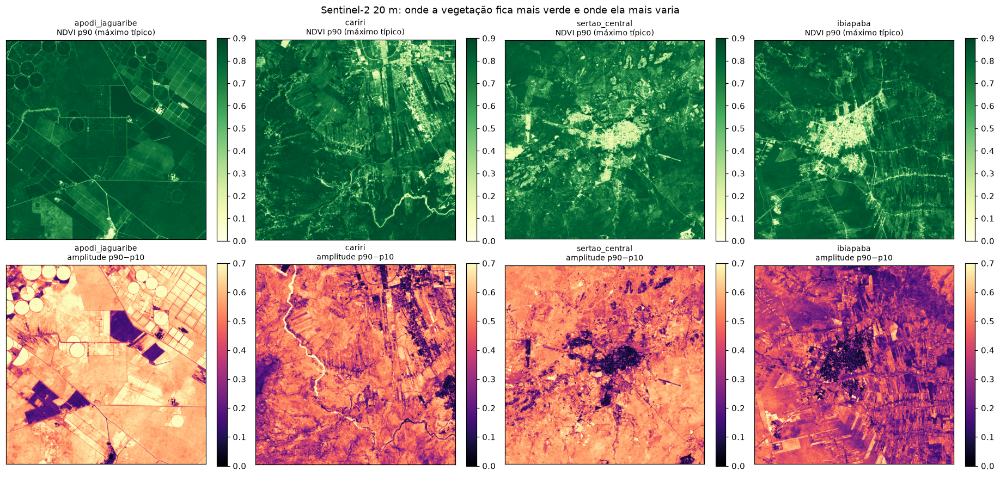

In [76]:
fig, axs = plt.subplots(2, len(mapas), figsize=(4.2 * len(mapas), 8))
for j, (n, (p90, p10, ext)) in enumerate(mapas.items()):
    for i, (img, tit, cm, lim) in enumerate([(p90, "NDVI p90 (máximo típico)", "YlGn", (0, 0.9)), (p90 - p10, "amplitude p90−p10", "magma", (0, 0.7))]):
        im = axs[i, j].imshow(img, extent=ext, cmap=cm, vmin=lim[0], vmax=lim[1]); axs[i, j].set_title(f"{n}\n{tit}", fontsize=9)
        axs[i, j].set_xticks([]); axs[i, j].set_yticks([]); plt.colorbar(im, ax=axs[i, j], fraction=0.046)
plt.suptitle("Sentinel-2 20 m: onde a vegetação fica mais verde e onde ela mais varia"); plt.tight_layout(); plt.show()

A **amplitude** (p90 − p10) a 20 m separa bem:
- lavoura de sequeiro e pasto, com amplitude alta: verde na chuva e solo na seca;
- mata/serra, com amplitude baixa e verde sempre;
- talhões irrigados, que aparecem como retângulos de geometria regular e pivôs circulares, com NDVI alto e amplitude
  que muda por talhão conforme o calendário de plantio.

Os limites de talhão aparecem nítidos a 20 m: dá para segmentar parcelas.

## 8.5 Sazonalidade

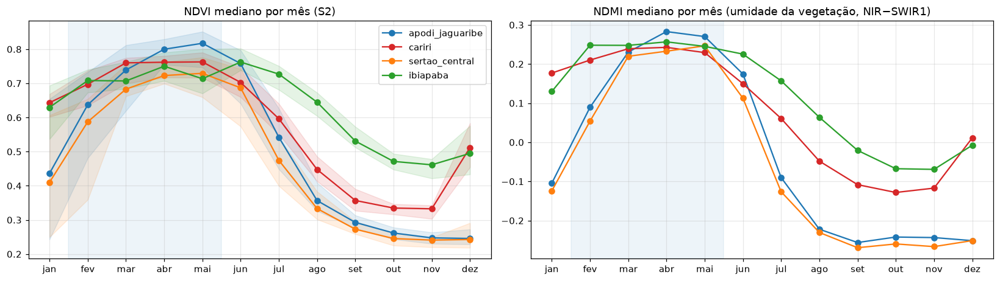

In [77]:
cl = cen[cen.frac_valida >= 0.3].groupby(["aoi", "mes"]).ndvi_mediana.agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
cl.columns = ["med", "q25", "q75"]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.3))
for n in AOIS:
    if n in cl.index.get_level_values(0):
        c = cl.loc[n]; axs[0].plot(c.index, c.med, "-o", color=CORES[n], label=n); axs[0].fill_between(c.index, c.q25, c.q75, color=CORES[n], alpha=0.12)
        m = cen[(cen.aoi == n) & (cen.frac_valida >= 0.3)].groupby("mes").ndmi_mediana.median(); axs[1].plot(m.index, m, "-o", color=CORES[n])
for ax, t in zip(axs, ["NDVI mediano por mês (S2)", "NDMI mediano por mês (umidade da vegetação, NIR−SWIR1)"]):
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(MESES); ax.axvspan(1.5, 5.5, color="tab:blue", alpha=0.08); ax.set_title(t)
axs[0].legend(); plt.tight_layout(); plt.show()

## 8.6 Tendências (Mann-Kendall + Sen) e 8.7 variabilidade interanual
A série de 2017–hoje é curta: as tendências servem de **sinal**, não de conclusão. O Landsat (seção 7) é a base para
tendências longas.

               aoi  meses MK anomalia: tendência       p  Sen/ano (anomalia) MK sazonal: tendência  p sazonal
0  apodi_jaguaribe    118             increasing  0.0440              0.0057            increasing     0.0007
1           cariri    115             increasing  0.0017              0.0058            increasing     0.0003
2         ibiapaba    117               no trend  0.6426              0.0007              no trend     0.9168
3   sertao_central    115             increasing  0.0041              0.0065            increasing     0.0002


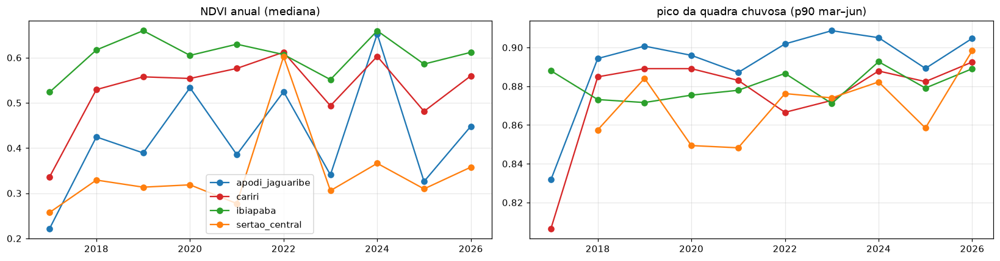

In [78]:
cc = cen[(cen.frac_valida >= 0.3) & cen.ndvi_mediana.notna()].copy()
cc["mes_ini"] = cc.datetime.dt.to_period("M").dt.to_timestamp()
mensal = cc.groupby(["aoi", "mes_ini"]).ndvi_mediana.median().unstack(0)
linhas = []
for n in mensal.columns:
    s = mensal[n].dropna()
    anom = s - s.groupby(s.index.month).transform("mean")
    r = mk.original_test(anom.values); rs = mk.seasonal_test(s.asfreq("MS").interpolate(limit=2).dropna().values, period=12)
    linhas.append({"aoi": n, "meses": len(s), "MK anomalia: tendência": r.trend, "p": round(r.p, 4), "Sen/ano (anomalia)": round(r.slope * 12, 4),
                   "MK sazonal: tendência": rs.trend, "p sazonal": round(rs.p, 4)})
display(pd.DataFrame(linhas)) if "display" in dir() else print(pd.DataFrame(linhas).to_string())

an = cc.groupby(["aoi", "ano"]).ndvi_mediana.median().unstack(0)
pico = cc[cc.mes.isin([3, 4, 5, 6])].groupby(["aoi", "ano"]).ndvi_p90.max().unstack(0)
fig, axs = plt.subplots(1, 2, figsize=(15, 4))
for n in an.columns:
    axs[0].plot(an.index, an[n], "-o", color=CORES[n], label=n); axs[1].plot(pico.index, pico[n], "-o", color=CORES[n])
axs[0].set_title("NDVI anual (mediana)"); axs[1].set_title("pico da quadra chuvosa (p90 mar–jun)"); axs[0].legend(); plt.tight_layout(); plt.show()

## 8.8 Comparação Landsat × Sentinel-2 nas mesmas datas (±1 dia)
Comparamos o NDVI mediano da AOI nas passagens em que os dois sensores viram a AOI com ≥ 80% limpa e com até 1 dia
de diferença.

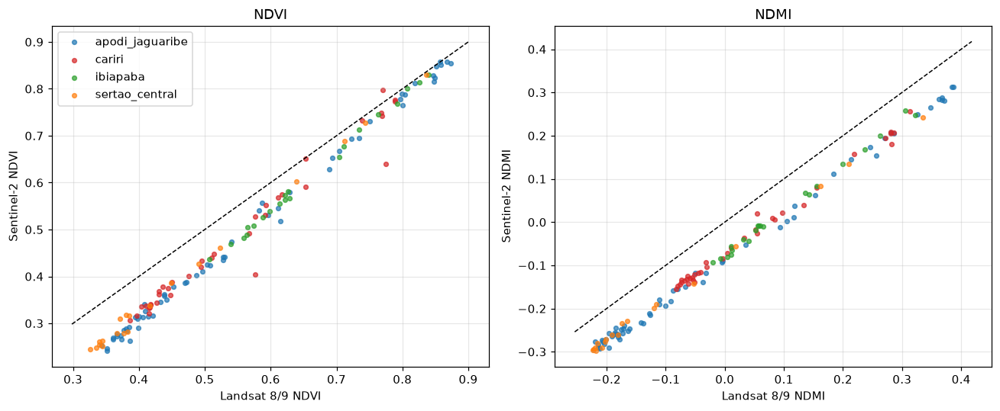

pares: 141 | viés S2−L (NDVI): -0.0626 | RMSD: 0.0704 | r = 0.995
                    n    vies
aoi                          
apodi_jaguaribe  63.0 -0.0668
cariri           37.0 -0.0618
ibiapaba         21.0 -0.0471
sertao_central   20.0 -0.0668


In [79]:
L = pd.read_parquet(DADOS / "landsat" / "landsat_aoi_cenas_l89.parquet")
L["datetime"] = pd.to_datetime(L["datetime"], utc=True).dt.tz_localize(None)
pares = []
for n in AOIS:
    a = L[(L.aoi == n) & (L.frac_valida >= 0.8)].sort_values("datetime"); b = cen[(cen.aoi == n) & (cen.frac_valida >= 0.8)].sort_values("datetime")
    if a.empty or b.empty:
        continue
    m = pd.merge_asof(a[["datetime", "ndvi_mediana", "ndmi_mediana"]], b[["datetime", "ndvi_mediana", "ndmi_mediana"]].rename(columns={"datetime": "dt_s2"}),
                      left_on="datetime", right_on="dt_s2", direction="nearest", tolerance=pd.Timedelta("1D"), suffixes=("_L", "_S2")).dropna()
    m["aoi"] = n; pares.append(m)
pares = pd.concat(pares) if pares else pd.DataFrame()
if len(pares):
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    for n, g in pares.groupby("aoi"):
        axs[0].scatter(g.ndvi_mediana_L, g.ndvi_mediana_S2, s=14, color=CORES[n], label=n, alpha=0.7)
        axs[1].scatter(g.ndmi_mediana_L, g.ndmi_mediana_S2, s=14, color=CORES[n], alpha=0.7)
    for ax, t in zip(axs, ["NDVI", "NDMI"]):
        lo, hi = ax.get_xlim(); ax.plot([lo, hi], [lo, hi], "k--", lw=1); ax.set_xlabel(f"Landsat 8/9 {t}"); ax.set_ylabel(f"Sentinel-2 {t}"); ax.set_title(t)
    axs[0].legend(); plt.tight_layout(); plt.show()
    d = pares.ndvi_mediana_S2 - pares.ndvi_mediana_L
    from scipy.stats import pearsonr
    r = pearsonr(pares.ndvi_mediana_L, pares.ndvi_mediana_S2)[0]
    print(f"pares: {len(pares)} | viés S2−L (NDVI): {d.mean():+.4f} | RMSD: {np.sqrt((d**2).mean()):.4f} | r = {r:.3f}")
    print(pares.groupby("aoi").apply(lambda g: pd.Series({"n": len(g), "vies": (g.ndvi_mediana_S2 - g.ndvi_mediana_L).mean()})).round(4).to_string())

## 8.9 HLS: a série harmonizada (L30 + S30)

Cenas HLS por coleção: {'hls2-s30': 1845, 'hls2-l30': 641}
Passagens úteis (≥80% limpas) por ano/AOI:
aoi       apodi_jaguaribe  cariri  ibiapaba  sertao_central
datetime                                                   
2020                   37      21        12              11
2021                   36      15        10               8
2022                   41      22        15              14
2023                   40      31        11              14
2024                   54      29        22              16
2025                   51      30        23              17
2026                   37      36        23              11


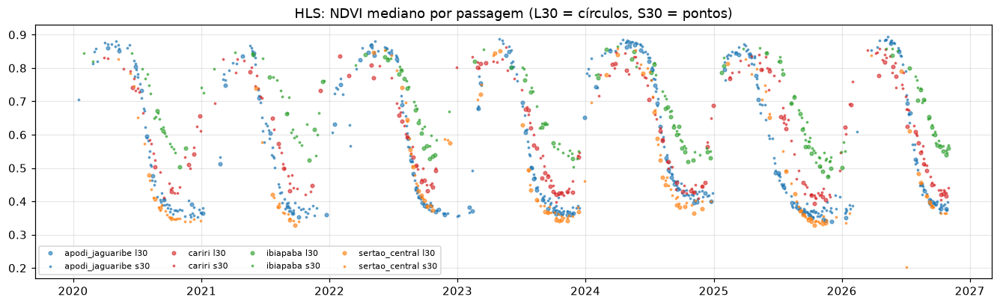

Intervalo mediano entre passagens úteis (dias), HLS: {'apodi_jaguaribe': 4.0, 'cariri': 8.0, 'ibiapaba': 8.0, 'sertao_central': 10.0}


In [80]:
if len(hls):
    hls["mes"] = hls.datetime.dt.month
    h = hls[(hls.frac_valida >= 0.3) & hls.ndvi_mediana.notna()]
    print("Cenas HLS por coleção:", hls.colecao.value_counts().to_dict())
    print("Passagens úteis (≥80% limpas) por ano/AOI:")
    print(hls[hls.frac_valida >= 0.8].groupby([hls.datetime.dt.year, "aoi"]).size().unstack().fillna(0).astype(int).to_string())
    fig, ax = plt.subplots(figsize=(15, 4))
    for n, g in h.groupby("aoi"):
        for col, mk_ in (("hls2-l30", "o"), ("hls2-s30", ".")):
            gg = g[g.colecao == col]; ax.plot(gg.datetime, gg.ndvi_mediana, mk_, ms=3, color=CORES[n], alpha=0.6, label=f"{n} {col[-3:]}")
    ax.set_title("HLS: NDVI mediano por passagem (L30 = círculos, S30 = pontos)"); ax.legend(ncol=4, fontsize=7); plt.show()
    gap = h[h.frac_valida >= 0.8].groupby("aoi").datetime.apply(lambda s: np.median(np.diff(np.sort(s.dt.normalize().unique())).astype("timedelta64[D]").astype(int)))
    print("Intervalo mediano entre passagens úteis (dias), HLS:", gap.to_dict())

### O HLS remove o viés entre sensores?
Repetimos a comparação da 8.8 dentro do HLS: pares L30 × S30 com até 1 dia de diferença e ≥ 80% da AOI limpa.

In [81]:
if len(hls):
    pp = []
    for n, g in hls[hls.frac_valida >= 0.8].groupby("aoi"):
        a = g[g.colecao == "hls2-l30"].sort_values("datetime"); b = g[g.colecao == "hls2-s30"].sort_values("datetime")
        m = pd.merge_asof(a[["datetime", "ndvi_mediana"]], b[["datetime", "ndvi_mediana"]].rename(columns={"datetime": "d2"}), left_on="datetime",
                          right_on="d2", direction="nearest", tolerance=pd.Timedelta("1D"), suffixes=("_L30", "_S30")).dropna()
        pp.append(m)
    pp = pd.concat(pp)
    dh = pp.ndvi_mediana_S30 - pp.ndvi_mediana_L30
    comp = pd.DataFrame({
        "Landsat C2 × Sentinel-2 L2A (brutos)": [len(pares), (pares.ndvi_mediana_S2 - pares.ndvi_mediana_L).mean(),
                                                  np.sqrt(((pares.ndvi_mediana_S2 - pares.ndvi_mediana_L) ** 2).mean()),
                                                  np.corrcoef(pares.ndvi_mediana_L, pares.ndvi_mediana_S2)[0, 1]] if len(pares) else [np.nan] * 4,
        "HLS L30 × S30 (harmonizados)": [len(pp), dh.mean(), np.sqrt((dh ** 2).mean()), np.corrcoef(pp.ndvi_mediana_L30, pp.ndvi_mediana_S30)[0, 1]]},
        index=["pares", "viés (S2 − Landsat)", "RMSD", "r"]).T.round(4)
    print(comp.to_string())

                                      pares  viés (S2 − Landsat)    RMSD       r
Landsat C2 × Sentinel-2 L2A (brutos)  141.0              -0.0626  0.0704  0.9950
HLS L30 × S30 (harmonizados)           78.0               0.0067  0.0125  0.9978

## 8.10 Insights e ideias para o produto
1. **Sentinel-2 + HLS resolvem a frequência.** As AOIs são vistas a cada ~5 dias, ou ~2,5 dias no Apodi, onde duas
   órbitas se sobrepõem. Somando L30 + S30, o HLS dá uma passagem útil (≥ 80% limpa) a cada 4–10 dias medianos.
   Isso o Landsat sozinho não garante: ele tem 4–19 passagens úteis por ano por AOI.
2. **Landsat e Sentinel-2 brutos andam juntos, mas não batem.**
   - A correlação é quase perfeita (r ≈ 0,995), mas há um **viés sistemático de ~−0,06 no NDVI**: o S2 sai menor.
   - As causas são a NIR larga B08 contra a NIR estreita do OLI e as cadeias de correção diferentes (Sen2Cor contra
     LaSRC).
   - Dentro do **HLS** o viés cai para ~+0,007 e o RMSD para ~0,01, porque o HLS usa a B8A, ajuste de banda e BRDF.
   - Conclusão: para costurar séries (Landsat 1984–2016 + S2/HLS 2017+), **use o HLS** ou aplique uma correção
     linear por região. Nunca misture os brutos.
3. **20 m mostra o talhão.** A amplitude p90−p10 e o p90 delimitam parcelas e pivôs. Com isso dá para segmentar
   talhões automaticamente (SAM/U-Net) e calcular a fenologia **por talhão**, não por pixel.
4. **O NDMI (NIR−SWIR1) é o "termômetro de água" da planta.** Ele cai antes do NDVI quando falta água, por isso é
   um bom gatilho de **alerta de estresse hídrico** a cruzar com SMAP/IMERG/POWER.
5. **Atenção às baselines.** O offset de 2022 (+1000 no DN) muda os números brutos, e o arquivo mistura 8 baselines.
   Um produto global precisa normalizar por *baseline*. O HLS já entrega isso, e ainda harmoniza com o Landsat
   (item 2), por isso é a escolha natural para o motor.

**Ideias de modelo:**
- Classificação de cultura por série temporal S2/HLS (Transformer temporal, TempCNN, LSTM ou TimesNet) treinada com
  rótulos do CDL nos EUA e transferida para o Brasil com poucos rótulos (MapBiomas).
- Previsão de curto prazo do NDVI/NDMI (próximas 2–4 semanas) com chuva e umidade do solo como covariáveis.
- Detecção do plantio e da colheita (pontos de virada da curva) para montar o **calendário real de rotação** de
  cada talhão.

# 9. MODIS e VIIRS — vegetação, temperatura da superfície, evapotranspiração e fogo

Esta seção estuda os produtos MODIS (Terra/Aqua) e VIIRS (S-NPP) baixados para o Ceará e o Nordeste:

| Produto | O que mede | Resolução nativa | Frequência | Período baixado | Recorte salvo |
|---|---|---|---|---|---|
| MOD13Q1 v061 (Terra) | NDVI e EVI (índices de vegetação) + confiabilidade do pixel | 250 m | composto de 16 dias | fev/2000 → 2026 | Ceará em grade 0,01° (~1,1 km) + 4 AOIs a 250 m |
| MOD13A1 v061 (Terra) | NDVI | 500 m | 16 dias | 2000 → 2026 | Nordeste em grade 0,05° (~5,5 km) |
| MOD11A2 v061 (Terra) | Temperatura da superfície (LST) dia (~10h30) e noite (~22h30) | 1 km | composto de 8 dias | 2000 → 2026 | Ceará 0,01° |
| MOD16A3GF v061 (Terra) | Evapotranspiração real (ET) e potencial (PET) anual | 500 m | anual | 2000 → 2025 | Ceará 0,005° |
| MCD64A1 v061 (Terra+Aqua) | Área queimada (data da queima) | 500 m | mensal | nov/2000 → 2026 | Nordeste: fração 0,05° mensal, mapas anuais 0,005°, km² por UF |
| FIRMS VIIRS S-NPP | Focos de fogo ativo (375 m) | ponto | por passagem | 2012 → 2025 | Nordeste, por UF |
| FIRMS MODIS (MCD14) | Focos de fogo ativo (1 km) | ponto | por passagem | 2000 → 2025 | Nordeste, por UF |
| VIIRS VNP13 (NDVI) | NDVI do VIIRS (continuidade do MODIS) | 500 m / 1 km | 16 dias | **não baixado** (exige Earthdata Login) | — |
| ESA CCI Land Cover 2020 (auxiliar) | Classe de cobertura do solo (lavoura, arbustiva, floresta…) | 300 m | anual | 2020 | Nordeste |

**Fontes de acesso:** Microsoft Planetary Computer (STAC + COG, aberto, sem login) para os MODIS e o ESA CCI;
NASA FIRMS (arquivos anuais por país, abertos) para os focos de fogo.

**Decisão de processamento importante:** os *overviews* dos COGs do Planetary Computer foram gerados por
**média**, o que corrompe camadas categóricas de qualidade (aparecem códigos de confiabilidade 4–10 que não
existem no produto). Por isso tudo foi lido em resolução cheia, a máscara de qualidade foi aplicada no pixel
nativo (`pixel_reliability ≤ 1` no NDVI; QC mandatório e erro ≤ 2 K na LST) e só depois os dados foram agregados
por média para a grade lat/lon.

In [82]:
import json
import sys
import warnings

sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
from comum import *  # noqa: F401,F403

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymannkendall as mk
import xarray as xr
from rasterio.features import rasterize
from rasterio.transform import from_origin
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})

M = DADOS / "modis"
V = DADOS / "viirs"
CE = ceara_gdf()
NE = nordeste_gdf()
UF_NOME = {21: "MA", 22: "PI", 23: "CE", 24: "RN", 25: "PB", 26: "PE", 27: "AL", 28: "SE", 29: "BA"}
NE["sigla"] = NE["codarea"].astype(int).map(UF_NOME)
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
CHUVOSA = [2, 3, 4, 5]          # quadra chuvosa do Ceará (fev–mai)
SECA = [8, 9, 10, 11]           # auge da estação seca
SECA_GRANDE = list(range(2012, 2018))


def mascara(lats, lons, gdf):
    res = abs(float(lats[0] - lats[1]))
    T = from_origin(float(lons[0]) - res / 2, float(lats[0]) + res / 2, res, res)
    return rasterize([(g, 1) for g in gdf.geometry], out_shape=(len(lats), len(lons)), transform=T,
                     fill=0, dtype="uint8").astype(bool)


def extent(da):
    r = abs(float(da.lon[1] - da.lon[0]))
    return [float(da.lon.min()) - r / 2, float(da.lon.max()) + r / 2, float(da.lat.min()) - r / 2, float(da.lat.max()) + r / 2]


def mapa(da, titulo, ax, cmap="viridis", vmin=None, vmax=None, contorno=CE, rotulo=""):
    im = ax.imshow(np.asarray(da), extent=extent(da), origin="upper", cmap=cmap, vmin=vmin, vmax=vmax,
                   interpolation="nearest")
    contorno.boundary.plot(ax=ax, color="k", lw=0.6)
    ax.set_title(titulo)
    ax.set_xlabel("lon")
    ax.set_ylabel("lat")
    ax.grid(False)
    plt.colorbar(im, ax=ax, shrink=0.8, label=rotulo)
    return im


def descr(x, nome):
    x = np.asarray(x, dtype="float64").ravel()
    x = x[np.isfinite(x)]
    if x.size == 0:
        return {"variavel": nome, "n": 0}
    p = np.percentile(x, [5, 25, 50, 75, 95])
    return {"variavel": nome, "n": x.size, "media": x.mean(), "desvio": x.std(), "p05": p[0], "p25": p[1],
            "mediana": p[2], "p75": p[3], "p95": p[4], "assimetria": stats.skew(x), "curtose": stats.kurtosis(x)}


def mk_vetorizado(Y):
    """Mann-Kendall (sem correção de empates) + inclinação de Sen, vetorizado. Y: (T, N) com NaN."""
    Y = np.asarray(Y, dtype="float32")
    Tn = Y.shape[0]
    i, j = np.triu_indices(Tn, 1)
    D = Y[j] - Y[i]
    S = np.nansum(np.sign(D), axis=0)
    n = np.sum(np.isfinite(Y), axis=0).astype("float64")
    var = n * (n - 1) * (2 * n + 5) / 18.0
    with np.errstate(all="ignore"):
        z = np.where(S > 0, (S - 1) / np.sqrt(var), np.where(S < 0, (S + 1) / np.sqrt(var), 0.0))
        p = 2 * (1 - stats.norm.cdf(np.abs(z)))
        sen = np.nanmedian(D / (j - i)[:, None].astype("float32"), axis=0)
    p[n < 8] = np.nan
    sen[n < 8] = np.nan
    return sen, z, p


def mk_tabela(series: dict, unidade: dict):
    linhas = []
    for nome, s in series.items():
        s = s.dropna()
        if len(s) < 8:
            continue
        r = mk.original_test(s.values)
        linhas.append({"serie": nome, "n_anos": len(s), "inicio": int(s.index.min()), "fim": int(s.index.max()),
                       "tendencia": r.trend, "p_valor": round(r.p, 4), "tau": round(r.Tau, 3),
                       "sen_por_ano": r.slope, "sen_por_decada": r.slope * 10, "unidade": unidade.get(nome, ""),
                       "media": s.mean(), "mudanca_%_por_decada": 100 * r.slope * 10 / s.mean() if s.mean() else np.nan})
    return pd.DataFrame(linhas)


def carregar(p):
    p = M / p if not str(p).startswith(("E:", "e:")) else p
    if not Path(p).exists():
        print("AUSENTE:", p)
        return None
    return xr.open_dataset(p)

## 9.1 Inventário do que foi baixado

In [83]:
inv = []
for pasta_ in (M, V):
    for f in sorted(pasta_.glob("*")):
        if f.is_file():
            inv.append({"pasta": pasta_.name, "arquivo": f.name, "MB": round(f.stat().st_size / 1e6, 1)})
inv = pd.DataFrame(inv)
print(inv.to_string(index=False))
print(f"\nTotal: {inv.MB.sum():.0f} MB")
man = json.loads((M / "MANIFESTO.json").read_text(encoding="utf-8"))
for k, v in man.items():
    if isinstance(v, dict):
        print(f"- {k}: período {v.get('periodo', v.get('anos', ''))} | datas {v.get('n_datas', v.get('n_meses', v.get('n_anos', '')))}"
              f" | erros {len(v.get('erros', []))}")

pasta                                    arquivo    MB
modis           esa_cci_lc_2020_nordeste_300m.nc   6.0
modis               firms_modis_nordeste.parquet  33.8
modis      firms_modis_nordeste_resumo_anual.csv   0.0
modis                             MANIFESTO.json   0.0
modis    mcd64a1_area_queimada_mensal_uf.parquet   0.0
modis   mcd64a1_frac_queimada_nordeste_005deg.nc   6.1
modis mcd64a1_queimado_anual_nordeste_0005deg.nc   4.7
modis                mod11a2_lst_ceara_001deg.nc 511.3
modis               mod11a2_lst_mensal_001deg.nc 288.4
modis            mod13a1_ndvi_nordeste_005deg.nc 199.5
modis        mod13q1_aoi_apodi_jaguaribe_250m.nc   2.9
modis                 mod13q1_aoi_cariri_250m.nc   3.0
modis               mod13q1_aoi_ibiapaba_250m.nc   3.0
modis         mod13q1_aoi_sertao_central_250m.nc   2.9
modis               mod13q1_ndvi_anual_001deg.nc  58.7
modis        mod13q1_ndvi_climatologia_001deg.nc  28.7
modis           mod13q1_ndvi_evi_ceara_001deg.nc 374.5
modis     

## 9.2 Validação de cobertura global — "é realmente do mundo todo?"

Evidências usadas:
1. **Inventário de tiles** num único período de cada produto, consultado no catálogo STAC do Planetary Computer.
   A grade sinusoidal do MODIS tem 36 × 18 = 460 tiles; só os que contêm terra são produzidos.
2. **Amostra de 14 pontos agrícolas e de controle em todos os continentes** (inclusive deserto e alta latitude),
   lendo o valor do pixel diretamente no arquivo.
3. **FIRMS:** existência do arquivo anual por país para vários países de todos os continentes.

         colecao  tiles_num_periodo    lat_min   lat_max     lon_min    lon_max
  modis-13Q1-061                294 -63.180500 86.816667 -231.158300 268.463600
  modis-11A2-061                317 -89.995272 85.217400 -356.974600 351.981700
modis-16A3GF-061                287 -63.180472 85.217416 -356.974629 301.792092
  modis-64A1-061                268 -60.089079 75.555356 -223.929850 223.852288

Tiles disponíveis por período (estabilidade do catálogo):
            modis-64A1-061  modis-13Q1-061  modis-11A2-061
2005-07-15           267.0           294.0           317.0
2015-07-15           268.0           294.0           317.0
2020-07-15           268.0             NaN             NaN
2023-07-15           268.0             NaN             NaN
2024-07-15            46.0           294.0           317.0
2025-07-15           229.0             NaN             NaN
2026-08-15           268.0             NaN             NaN
2026-09-20             NaN           294.0           317.0
Lacunas co

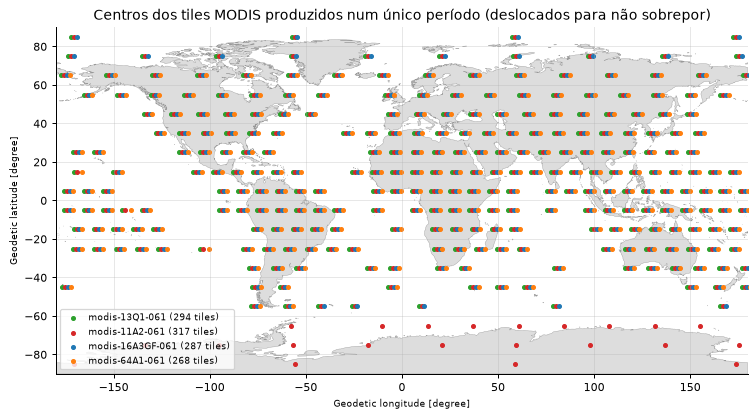


Valores lidos no pixel (NDVI jul/2024 | LST dia °C jul/2024 | ET 2023 mm/ano | MCD64A1 jul/2023):
          ponto    lon   lat  13Q1  11A2  16A3GF         64A1
       Ceara_BR  -39.6  -5.6 0.706  26.6   969.0 não queimado
       Pampa_AR  -61.0 -34.5 0.419  11.7   443.0 não queimado
        Iowa_US  -93.5  42.0 0.845  28.1   666.0 não queimado
Saskatchewan_CA -106.0  52.0 0.855  24.4   420.0 não queimado
      Franca_FR    2.0  48.5 0.754  24.5   546.0 não queimado
     Ucrania_UA   32.0  49.0 0.745  34.4   610.0 não queimado
   Finlandia_FI   25.0  62.5 0.817  18.4   369.0 não queimado
      Sahara_DZ    3.0  27.0 0.096  48.5     NaN não queimado
      Quenia_KE   36.1  -0.3 0.817  27.6  1073.0 não queimado
      Punjab_IN   75.5  30.8 0.449  32.8   394.0 não queimado
       Henan_CN  114.0  34.0 0.822   NaN   660.0 não queimado
         NSW_AU  147.0 -33.0 0.644  10.3   214.0 não queimado
        Java_ID  110.5  -7.3 0.781  27.1  1335.0 não queimado
 Mato_Grosso_BR  -55.5 -13.0 0.38

In [84]:
val = json.loads((M / "validacao_global.json").read_text(encoding="utf-8"))
tab = []
for col, info in val["colecoes"].items():
    tab.append({"colecao": col, "tiles_num_periodo": info["n_tiles"], "lat_min": info["lat_min"], "lat_max": info["lat_max"],
                "lon_min": info["lon_min"], "lon_max": info["lon_max"]})
print(pd.DataFrame(tab).to_string(index=False))
tpp = pd.DataFrame({col: {dt: v["n_tiles"] for dt, v in d.items()} for col, d in val.get("tiles_por_periodo", {}).items()})
print("\nTiles disponíveis por período (estabilidade do catálogo):")
print(tpp.to_string())
print("Lacunas conhecidas do MCD64A1 no Nordeste:", val.get("lacunas_nordeste_mcd64a1"))

fig, ax = plt.subplots(figsize=(11, 5))
terra = terra_gdf()
terra.plot(ax=ax, color="#ddd", edgecolor="#999", lw=0.3)
cores = {"modis-13Q1-061": "tab:green", "modis-11A2-061": "tab:red", "modis-64A1-061": "tab:orange", "modis-16A3GF-061": "tab:blue"}
for k, (col, info) in enumerate(val["colecoes"].items()):
    hv = np.array(info["tiles"]) if info["tiles"] else np.zeros((0, 2))
    if len(hv) == 0:
        continue
    lat_c = 90 - (hv[:, 1] + 0.5) * 10
    lon_c = ((hv[:, 0] + 0.5) * 10 - 180) / np.cos(np.radians(lat_c))
    ok = np.abs(lon_c) <= 180
    ax.scatter(lon_c[ok] + 1.5 * k, lat_c[ok], s=9, color=cores.get(col, "k"), label=f"{col} ({len(hv)} tiles)")
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_title("Centros dos tiles MODIS produzidos num único período (deslocados para não sobrepor)")
ax.legend(loc="lower left", fontsize=7)
plt.show()


def decodifica(col, v):
    if v is None or isinstance(v, str):
        return v
    if col == "modis-13Q1-061":
        return None if v <= -3000 else round(v / 1e4, 3)
    if col == "modis-11A2-061":
        return None if v == 0 else round(v * 0.02 - 273.15, 1)
    if col == "modis-16A3GF-061":
        return None if v >= 65500 else round(v * 0.1, 0)
    if col == "modis-64A1-061":
        return {-2: "água", -1: "não mapeado", 0: "não queimado"}.get(int(v), f"queimado dia {int(v)}")
    return v


pts = []
for nome, info in val["pontos"].items():
    lin = {"ponto": nome, "lon": info["lon"], "lat": info["lat"]}
    for col in val["colecoes"]:
        r = info.get(col, {})
        lin[col.replace("modis-", "").replace("-061", "")] = decodifica(col, r.get("valor_bruto")) if r.get("item") else "sem tile"
    pts.append(lin)
pts = pd.DataFrame(pts)
print("\nValores lidos no pixel (NDVI jul/2024 | LST dia °C jul/2024 | ET 2023 mm/ano | MCD64A1 jul/2023):")
print(pts.to_string(index=False))

fv = json.loads((V / "validacao_global_firms.json").read_text(encoding="utf-8"))["head_2023"]
firms = pd.DataFrame([{"arquivo": k, "status": v.get("status"), "MB": round(v.get("bytes", 0) / 1e6, 1)} for k, v in fv.items()])
print("\nFIRMS – arquivo anual 2023 por país (HTTP 200 = existe):")
print(firms.to_string(index=False))

**Veredito de cobertura (lido das evidências acima):**

- **MOD13Q1/MOD13A1 (NDVI), MOD11A2 (LST), MCD64A1 (área queimada): globais sobre terra.** Num único período existem
  tiles de todos os continentes, de ~85° N a ~60° S. A LST inclui até a Antártida e a área queimada vai de 60° S a
  75° N. Os limites de longitude acima de ±180° são artefato do retângulo envolvente dos tiles sinusoidais. O mar
  não faz parte do produto terrestre.
  Os pontos de teste em Iowa, Pampa, França, Ucrânia, Punjab, Henan, Quênia, Java, NSW (Austrália), Mato Grosso e
  Ceará devolveram valores válidos. Os poucos "sem dado" são esperados: deserto sem vegetação, nuvem no
  composto ou inverno boreal.
- **MOD16A3GF (ET/PET): global, mas com buracos por desenho.** O algoritmo não calcula ET em áreas urbanas, água,
  neve/gelo e solo nu (códigos ≥ 65 500). No Sahara o pixel vem como classe especial, não como ET.
- **FIRMS (VIIRS e MODIS): global.** Há arquivos por país em todos os continentes; a Rússia aparece sob outro
  nome no índice. O arquivo anual só existe para anos fechados (2026 não tem). O ano corrente exige a API NRT
  com chave (MAP_KEY gratuita).
- **Atenção para o produto mundial:** o Terra (MOD) e o Aqua (MYD) estão em fim de vida, com deriva orbital
  desde ~2022, o que muda o horário de passagem e afeta a LST. A continuidade é o **VIIRS (VNP13/VNP21/VNP64)**,
  que exige Earthdata Login. O desenho do sistema deve ser *agnóstico ao sensor*: MODIS até ~2025, VIIRS depois.

## 9.3 Qualidade dos dados (nuvens, máscaras, buracos)

Intervalos entre compostos MOD13Q1 (dias): {16: 572, 13: 19, 14: 6, 32: 2, 30: 1, 144: 1}
Datas com falha de leitura: 0
  lacuna NDVI: 2023-02-02 → 2023-03-06 (32 dias)
  lacuna NDVI: 2024-07-27 → 2024-08-28 (32 dias)
  lacuna NDVI: 2024-12-02 → 2025-01-01 (30 dias)
  lacuna NDVI: 2025-06-26 → 2025-11-17 (144 dias)
Intervalos entre compostos MOD11A2 (dias): {8: 1171, 5: 18, 6: 6, 24: 2, 16: 2, 13: 1, 14: 1, 152: 1}
  lacuna LST: 2001-06-10 → 2001-07-04 (24 dias)
  lacuna LST: 2022-09-22 → 2022-10-08 (16 dias)
  lacuna LST: 2022-11-25 → 2022-12-19 (24 dias)
  lacuna LST: 2022-12-27 → 2023-01-09 (13 dias)
  lacuna LST: 2023-02-18 → 2023-03-06 (16 dias)
  lacuna LST: 2024-12-18 → 2025-01-01 (14 dias)
  lacuna LST: 2025-06-26 → 2025-11-25 (152 dias)


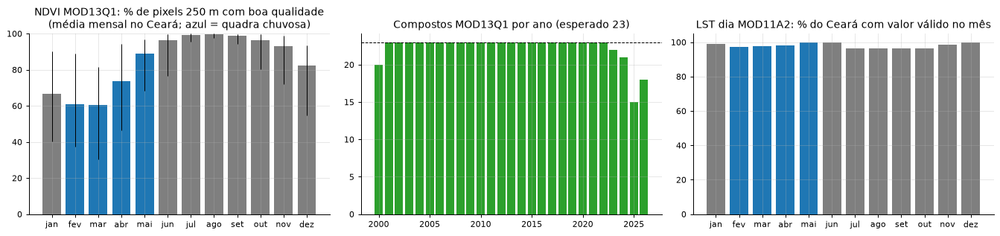


MCD64A1 – % do Nordeste sem mapeamento por mês (mediana por mês do ano):
data
jan    0.12
fev    0.21
mar    0.11
abr    0.05
mai    0.02
jun    0.01
jul    0.01
ago    0.01
set    0.01
out    0.02
nov    0.04
dez    0.06
Meses com > 5% sem mapeamento: ['2000-02', '2000-03', '2000-04', '2000-08', '2000-09', '2000-10', '2000-11', '2000-12', '2001-01', '2001-02', '2001-03', '2001-04', '2001-07', '2001-10', '2001-11', '2001-12', '2002-01', '2002-02', '2002-03', '2002-04']


In [85]:
ce_m = pd.read_parquet(DERIV / "modis_ce_mensal.parquet")
ce_m["mes"] = ce_m.data.dt.month
boa = ce_m[ce_m.variavel == "pct_pixels_boa_qualidade_ndvi"]
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
g = boa.groupby("mes").valor.agg(["mean", "min", "max"])
axs[0].bar(range(1, 13), g["mean"], color=["tab:blue" if m in CHUVOSA else "tab:gray" for m in range(1, 13)])
axs[0].errorbar(range(1, 13), g["mean"], yerr=[g["mean"] - g["min"], g["max"] - g["mean"]], fmt="none", color="k", lw=0.8)
axs[0].set_xticks(range(1, 13), MESES)
axs[0].set_title("NDVI MOD13Q1: % de pixels 250 m com boa qualidade\n(média mensal no Ceará; azul = quadra chuvosa)")
axs[0].set_ylim(0, 100)

ndvi16 = carregar("mod13q1_ndvi_evi_ceara_001deg.nc")
t = pd.to_datetime(ndvi16.time.values)
por_ano = pd.Series(1, index=t).groupby(t.year).sum()
axs[1].bar(por_ano.index, por_ano.values, color="tab:green")
axs[1].axhline(23, color="k", ls="--", lw=0.8)
axs[1].set_title("Compostos MOD13Q1 por ano (esperado 23)")
dif = np.diff(t.values).astype("timedelta64[D]").astype(int)
print("Intervalos entre compostos MOD13Q1 (dias):", pd.Series(dif).value_counts().to_dict())
print("Datas com falha de leitura:", int((~ndvi16.feito.values.astype(bool)).sum()))
for i in np.where(dif > 16)[0]:
    print(f"  lacuna NDVI: {t[i]:%Y-%m-%d} → {t[i + 1]:%Y-%m-%d} ({dif[i]} dias)")
lst8 = xr.open_dataset(M / "mod11a2_lst_ceara_001deg.nc")
t8 = pd.to_datetime(lst8.time.values)
d8 = np.diff(t8.values).astype("timedelta64[D]").astype(int)
print("Intervalos entre compostos MOD11A2 (dias):", pd.Series(d8).value_counts().to_dict())
for i in np.where(d8 > 9)[0]:
    print(f"  lacuna LST: {t8[i]:%Y-%m-%d} → {t8[i + 1]:%Y-%m-%d} ({d8[i]} dias)")

lstm = carregar("mod11a2_lst_mensal_001deg.nc").load()
mk_ce = mascara(lstm.lat.values, lstm.lon.values, CE)
frac_lst = lstm.lst_dia.where(mk_ce).notnull().sum(("lat", "lon")) / mk_ce.sum()
fl = frac_lst.to_series()
axs[2].bar(range(1, 13), fl.groupby(fl.index.month).mean() * 100,
           color=["tab:blue" if m in CHUVOSA else "tab:gray" for m in range(1, 13)])
axs[2].set_xticks(range(1, 13), MESES)
axs[2].set_title("LST dia MOD11A2: % do Ceará com valor válido no mês")
plt.tight_layout()
plt.show()

fogo_uf = pd.read_parquet(M / "mcd64a1_area_queimada_mensal_uf.parquet")
fogo_uf["data"] = pd.to_datetime(fogo_uf["data"])
q = fogo_uf.groupby("data")[["area_terra_km2", "area_sem_mapeamento_km2"]].sum()
q["pct_sem_mapeamento"] = 100 * q.area_sem_mapeamento_km2 / (q.area_terra_km2 + q.area_sem_mapeamento_km2)
print("\nMCD64A1 – % do Nordeste sem mapeamento por mês (mediana por mês do ano):")
print(q.groupby(q.index.month).pct_sem_mapeamento.median().round(2).rename(index=dict(enumerate(MESES, 1))).to_string())
print("Meses com > 5% sem mapeamento:", q[q.pct_sem_mapeamento > 5].index.strftime("%Y-%m").tolist()[:20])

**Leitura:** na quadra chuvosa a nuvem derruba a fração de pixels "bons" do NDVI e da LST justamente quando a
lavoura de sequeiro está no campo. Consequência para o produto:
- suavizar e preencher a série temporal (Savitzky–Golay, Whittaker ou harmônicos) antes de extrair fenologia;
- combinar sensores ópticos (MODIS/VIIRS, HLS, Sentinel-2) com radar (Sentinel-1, NISAR), que atravessa nuvem;
- mostrar ao usuário um **indicador de confiança** por mês.

## 9.4 Estatística descritiva — Ceará e Nordeste

In [86]:
ndm = carregar("mod13q1_ndvi_mensal_001deg.nc").load()
mk_ce01 = mascara(ndm.lat.values, ndm.lon.values, CE)
etd = carregar("mod16a3gf_et_ceara_0005deg.nc").load()
mk_ce005 = mascara(etd.lat.values, etd.lon.values, CE)
rng = np.random.default_rng(0)


def amostra(da, mk_, n=2_000_000):
    a = np.asarray(da.values)[:, mk_]
    a = a[np.isfinite(a)]
    return rng.choice(a, size=min(n, a.size), replace=False) if a.size else a


linhas = [descr(amostra(ndm.ndvi, mk_ce01), "NDVI mensal (CE)"),
          descr(amostra(ndm.evi, mk_ce01), "EVI mensal (CE)"),
          descr(amostra(lstm.lst_dia, mk_ce01), "LST dia mensal °C (CE)"),
          descr(amostra(lstm.lst_noite, mk_ce01), "LST noite mensal °C (CE)"),
          descr(amostra(etd.et, mk_ce005), "ET anual mm (CE)"),
          descr(amostra(etd.pet, mk_ce005), "PET anual mm (CE)"),
          descr(amostra(etd.pet - etd.et, mk_ce005), "Déficit PET−ET anual mm (CE)")]
ndne = carregar("mod13a1_ndvi_nordeste_005deg.nc")
ndne = ndne.load() if ndne is not None else None
if ndne is not None:
    mk_ne05 = mascara(ndne.lat.values, ndne.lon.values, NE)
    linhas.append(descr(amostra(ndne.ndvi, mk_ne05), "NDVI 16 dias (NE, 0,05°)"))
fq = carregar("mcd64a1_frac_queimada_nordeste_005deg.nc").load()
mk_ne05b = mascara(fq.lat.values, fq.lon.values, NE)
linhas.append(descr(amostra(fq.frac_queimada * 100, mk_ne05b), "% queimado no mês por célula 0,05° (NE)"))
tabd = pd.DataFrame(linhas)
print(tabd.round(3).to_string(index=False))

                               variavel       n    media  desvio      p05      p25  mediana      p75      p95  assimetria  curtose
                       NDVI mensal (CE) 2000000    0.548   0.187    0.289    0.377    0.532    0.724    0.834       0.092   -1.261
                        EVI mensal (CE) 2000000    0.339   0.147    0.165    0.208    0.305    0.463    0.596       0.495   -0.920
                 LST dia mensal °C (CE) 2000000   32.875   5.396   25.288   28.245   32.340   37.270   41.963       0.251   -0.947
               LST noite mensal °C (CE) 2000000   22.776   1.935   19.323   21.567   22.950   24.163   25.618      -0.489    0.371
                       ET anual mm (CE) 2000000  910.177 238.204  548.844  743.061  892.983 1059.995 1331.538       0.399    0.206
                      PET anual mm (CE) 2000000 2563.291 130.234 2360.504 2485.339 2566.988 2648.144 2759.034      -1.624   23.075
           Déficit PET−ET anual mm (CE) 2000000 1652.750 282.818 1175.911 1457.412 

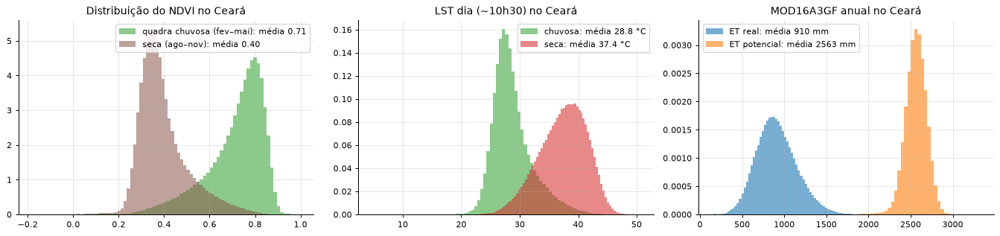

In [87]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
mm = ndm.time.dt.month
for meses, cor, rot in ((CHUVOSA, "tab:green", "quadra chuvosa (fev–mai)"), (SECA, "tab:brown", "seca (ago–nov)")):
    x = amostra(ndm.ndvi.sel(time=mm.isin(meses)), mk_ce01, 500_000)
    axs[0].hist(x, bins=80, alpha=0.55, density=True, color=cor, label=f"{rot}: média {x.mean():.2f}")
axs[0].set_title("Distribuição do NDVI no Ceará")
axs[0].legend()
for meses, cor, rot in ((CHUVOSA, "tab:green", "chuvosa"), (SECA, "tab:red", "seca")):
    x = amostra(lstm.lst_dia.sel(time=lstm.time.dt.month.isin(meses)), mk_ce01, 500_000)
    axs[1].hist(x, bins=80, alpha=0.55, density=True, color=cor, label=f"{rot}: média {x.mean():.1f} °C")
axs[1].set_title("LST dia (~10h30) no Ceará")
axs[1].legend()
x = amostra(etd.et, mk_ce005, 500_000)
y = amostra(etd.pet, mk_ce005, 500_000)
axs[2].hist(x, bins=80, alpha=0.6, density=True, label=f"ET real: média {x.mean():.0f} mm")
axs[2].hist(y, bins=80, alpha=0.6, density=True, label=f"ET potencial: média {y.mean():.0f} mm")
axs[2].set_title("MOD16A3GF anual no Ceará")
axs[2].legend()
plt.tight_layout()
plt.show()

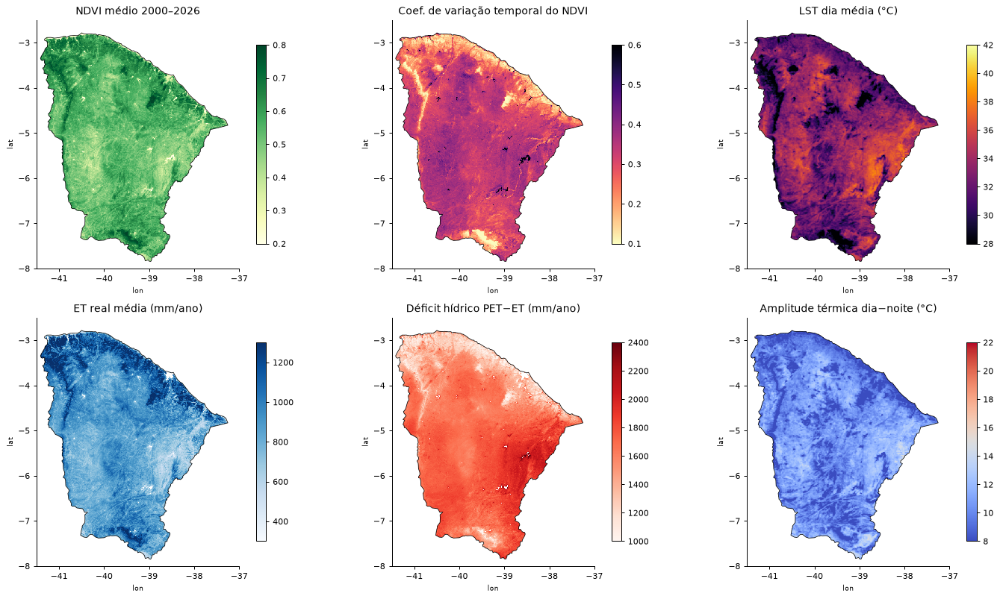

In [88]:
fig, axs = plt.subplots(2, 3, figsize=(16, 9))
nd_media = ndm.ndvi.mean("time").where(mk_ce01)
nd_cv = (ndm.ndvi.std("time") / ndm.ndvi.mean("time")).where(mk_ce01)
mapa(nd_media, "NDVI médio 2000–2026", axs[0, 0], "YlGn", 0.2, 0.8)
mapa(nd_cv, "Coef. de variação temporal do NDVI", axs[0, 1], "magma_r", 0.1, 0.6)
mapa(lstm.lst_dia.mean("time").where(mk_ce01), "LST dia média (°C)", axs[0, 2], "inferno", 28, 42)
mapa(etd.et.mean("time").where(mk_ce005), "ET real média (mm/ano)", axs[1, 0], "Blues", 300, 1300)
mapa((etd.pet - etd.et).mean("time").where(mk_ce005), "Déficit hídrico PET−ET (mm/ano)", axs[1, 1], "Reds", 1000, 2400)
mapa((lstm.lst_dia - lstm.lst_noite).mean("time").where(mk_ce01), "Amplitude térmica dia−noite (°C)", axs[1, 2], "coolwarm", 8, 22)
plt.tight_layout()
plt.show()

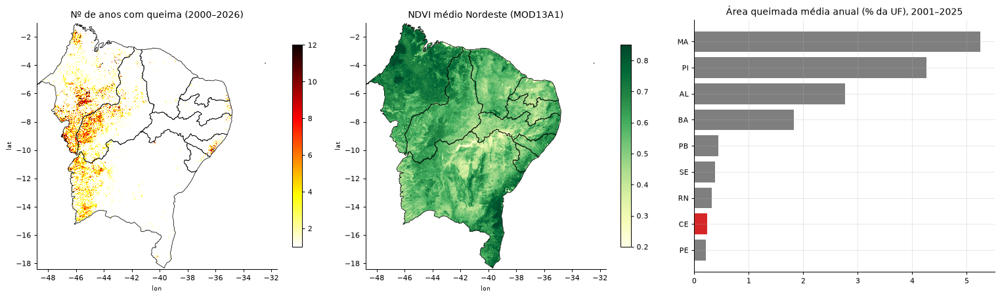

Área queimada anual média por UF (km²):
MA    17485.0
PI    10939.0
BA    10572.0
AL      804.0
CE      368.0
PB      260.0
PE      213.0
RN      177.0
SE       87.0



FIRMS VIIRS (vegetação, type=0) – focos por ano e UF:
uf        MA      PI     CE    RN    PB     PE    AL    SE      BA
ano                                                               
2012  252093  124708  24279  3672  5000   9146  4472  2632  128750
2013  110917   52119  15973  2652  3269   6655  3564  1902   54334
2014  154162   72337  15474  2598  3652   5694  2082  1022   55675
2015  262780  118344  18694  3696  4961   9014  5203  2622  118495
2016  153010   65320  25120  3863  5888   8549  4028  1852   49363
2017  195252   63343  18939  2782  3618   5389  2479  1299   50230
2018   97073   78616  18501  3262  6430   6847  2542  1544   39220
2019  127605   92524  25058  5576  9271   7665  2776  1242   60232
2020  119849   77051  22891  4666  7627   8422  2135  1112   57446
2021  101362  109406  24932  4886  8032   9970  2029  1661  109791
2022  129534   84350  22796  3312  6754   8669  1704  1278   71440
2023  151252   95757  29587  4735  6627  11815  2352  1650   88517
2024  1

{'variavel': 'FRP VIIRS (MW)', 'n': 4957865, 'media': np.float64(12.383772268910104), 'desvio': np.float64(24.498678599060355), 'p05': np.float64(1.07), 'p25': np.float64(3.21), 'mediana': np.float64(6.22), 'p75': np.float64(11.97), 'p95': np.float64(42.76), 'assimetria': np.float64(27.10344320779618), 'curtose': np.float64(5639.99866448329)}


In [89]:
fig, axs = plt.subplots(1, 3, figsize=(17, 5))
qa = carregar("mcd64a1_queimado_anual_nordeste_0005deg.nc").load()
anos_q = qa.ano.values
freq = qa.queimado.sum("ano")
mk_nef = mascara(qa.lat.values, qa.lon.values, NE)
mapa(freq.where(mk_nef & (freq > 0)), f"Nº de anos com queima ({anos_q.min()}–{anos_q.max()})", axs[0], "hot_r", 1, 12, NE)
if ndne is not None:
    mapa(ndne.ndvi.mean("time").where(mk_ne05), "NDVI médio Nordeste (MOD13A1)", axs[1], "YlGn", 0.2, 0.85, NE)
fogo_uf["ano"] = fogo_uf.data.dt.year
anual_uf = fogo_uf[(fogo_uf.ano >= 2001) & (fogo_uf.ano <= 2025)].groupby(["ano", "uf"]).area_queimada_km2.sum().unstack()
anual_uf.columns = [UF_NOME[c] for c in anual_uf.columns]
area_uf = NE.to_crs(5880).area / 1e6
area_uf.index = NE.sigla
pct = (anual_uf.mean() / area_uf[anual_uf.columns] * 100).sort_values()
axs[2].barh(pct.index, pct.values, color=["tab:red" if k == "CE" else "tab:gray" for k in pct.index])
axs[2].set_title("Área queimada média anual (% da UF), 2001–2025")
plt.tight_layout()
plt.show()
print("Área queimada anual média por UF (km²):")
print(anual_uf.mean().round(0).sort_values(ascending=False).to_string())

viirs = pd.read_parquet(V / "firms_viirs_snpp_nordeste.parquet", columns=["latitude", "longitude", "acq_date", "frp", "type", "uf", "confidence"])
viirs = viirs[viirs["type"] == 0]
viirs["ano"] = viirs.acq_date.dt.year
viirs["mes"] = viirs.acq_date.dt.month
print("\nFIRMS VIIRS (vegetação, type=0) – focos por ano e UF:")
print(viirs.groupby(["ano", "uf"]).size().unstack().rename(columns=UF_NOME).to_string())
print("\nFRP (MW) – estatística descritiva no Nordeste:")
print(descr(viirs.frp, "FRP VIIRS (MW)"))

## 9.5 Sazonalidade — o calendário do campo no Ceará

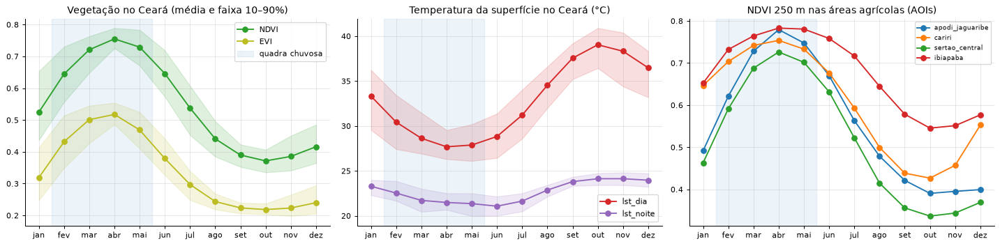

Climatologia mensal no Ceará:
variavel  lst_dia   ndvi
mes                     
jan        33.319  0.524
fev        30.426  0.644
mar        28.623  0.721
abr        27.678  0.755
mai        27.871  0.729
jun        28.824  0.646
jul        31.205  0.537
ago        34.529  0.441
set        37.546  0.390
out        39.037  0.371
nov        38.317  0.385
dez        36.469  0.416


In [90]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for v, cor in (("ndvi", "tab:green"), ("evi", "tab:olive")):
    s = ce_m[ce_m.variavel == v].groupby("mes").valor
    axs[0].plot(range(1, 13), s.mean(), "-o", color=cor, label=v.upper())
    axs[0].fill_between(range(1, 13), s.quantile(0.1), s.quantile(0.9), color=cor, alpha=0.15)
axs[0].axvspan(1.5, 5.5, color="tab:blue", alpha=0.08, label="quadra chuvosa")
axs[0].set_xticks(range(1, 13), MESES)
axs[0].set_title("Vegetação no Ceará (média e faixa 10–90%)")
axs[0].legend()
for v, cor in (("lst_dia", "tab:red"), ("lst_noite", "tab:purple")):
    s = ce_m[ce_m.variavel == v].groupby("mes").valor
    axs[1].plot(range(1, 13), s.mean(), "-o", color=cor, label=v)
    axs[1].fill_between(range(1, 13), s.quantile(0.1), s.quantile(0.9), color=cor, alpha=0.15)
axs[1].axvspan(1.5, 5.5, color="tab:blue", alpha=0.08)
axs[1].set_xticks(range(1, 13), MESES)
axs[1].set_title("Temperatura da superfície no Ceará (°C)")
axs[1].legend()
aoi_m = pd.read_parquet(DERIV / "modis_aoi_mensal.parquet")
aoi_m["mes"] = aoi_m.data.dt.month
for nm in AOIS:
    s = aoi_m[(aoi_m.aoi == nm) & (aoi_m.variavel == "ndvi")].groupby("mes").valor.mean()
    axs[2].plot(s.index, s.values, "-o", label=nm)
axs[2].axvspan(1.5, 5.5, color="tab:blue", alpha=0.08)
axs[2].set_xticks(range(1, 13), MESES)
axs[2].set_title("NDVI 250 m nas áreas agrícolas (AOIs)")
axs[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

clim_ce = ce_m[ce_m.variavel.isin(["ndvi", "lst_dia"])].pivot_table(index="mes", columns="variavel", values="valor")
print("Climatologia mensal no Ceará:")
print(clim_ce.round(3).rename(index=dict(enumerate(MESES, 1))).to_string())

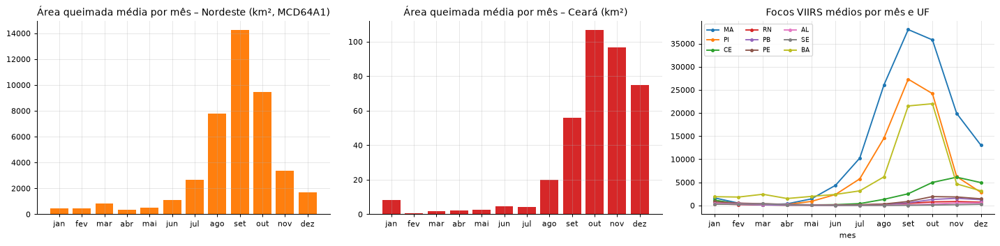

Pico de área queimada no Ceará: out | no Nordeste: set
Fração da área queimada anual do Ceará que ocorre em set–dez: 0.884


In [91]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
fm = fogo_uf.copy()
fm["mes"] = fm.data.dt.month
ne_mes = fm[(fm.ano >= 2001) & (fm.ano <= 2025)].groupby(["ano", "mes"]).area_queimada_km2.sum().groupby("mes").mean()
ce_mes = fm[(fm.uf == 23) & (fm.ano >= 2001) & (fm.ano <= 2025)].groupby(["ano", "mes"]).area_queimada_km2.sum().groupby("mes").mean()
axs[0].bar(range(1, 13), ne_mes.reindex(range(1, 13)).values, color="tab:orange")
axs[0].set_xticks(range(1, 13), MESES)
axs[0].set_title("Área queimada média por mês – Nordeste (km², MCD64A1)")
axs[1].bar(range(1, 13), ce_mes.reindex(range(1, 13)).values, color="tab:red")
axs[1].set_xticks(range(1, 13), MESES)
axs[1].set_title("Área queimada média por mês – Ceará (km²)")
fv_mes = viirs.groupby(["ano", "mes", "uf"]).size().groupby(["mes", "uf"]).mean().unstack().rename(columns=UF_NOME)
fv_mes.plot(ax=axs[2], marker=".")
axs[2].set_xticks(range(1, 13), MESES)
axs[2].set_title("Focos VIIRS médios por mês e UF")
axs[2].legend(fontsize=7, ncol=3)
plt.tight_layout()
plt.show()
print("Pico de área queimada no Ceará:", MESES[int(ce_mes.idxmax()) - 1], "| no Nordeste:", MESES[int(ne_mes.idxmax()) - 1])
print("Fração da área queimada anual do Ceará que ocorre em set–dez:", round(ce_mes.loc[9:12].sum() / ce_mes.sum(), 3))

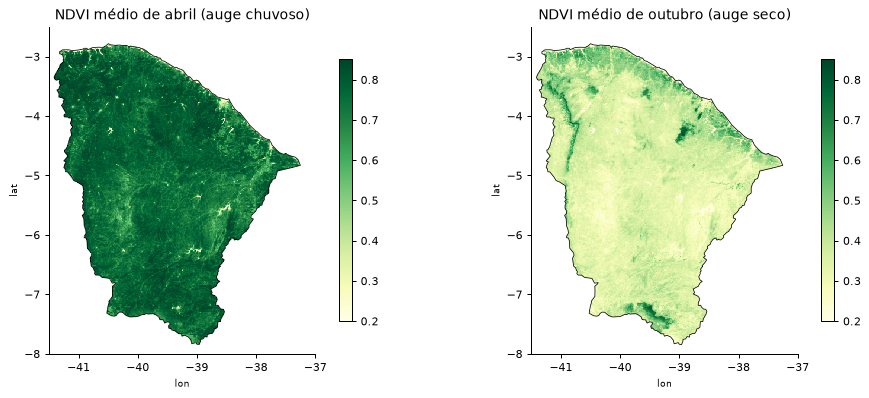

In [92]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
mapa(ndm.ndvi.sel(time=ndm.time.dt.month == 4).mean("time").where(mk_ce01), "NDVI médio de abril (auge chuvoso)", axs[0], "YlGn", 0.2, 0.85)
mapa(ndm.ndvi.sel(time=ndm.time.dt.month == 10).mean("time").where(mk_ce01), "NDVI médio de outubro (auge seco)", axs[1], "YlGn", 0.2, 0.85)
plt.tight_layout()
plt.show()

## 9.6 Tendências — Mann-Kendall + inclinação de Sen

Usamos o teste de Mann-Kendall original (`pymannkendall.original_test`) nas séries anuais regionais e uma versão
vetorizada (mesma estatística S, sem correção de empates, aceitável para dados contínuos) pixel a pixel.

In [93]:
anu = carregar("mod13q1_ndvi_anual_001deg.nc").load()
ser = {}
ser["NDVI médio anual CE"] = anu.ndvi.where(mk_ce01).mean(("lat", "lon")).to_series()
ser["NDVI mínimo anual CE"] = anu.ndvi_min.where(mk_ce01).mean(("lat", "lon")).to_series()
ser["EVI médio anual CE"] = anu.evi.where(mk_ce01).mean(("lat", "lon")).to_series()
lsta = lstm.lst_dia.where(mk_ce01).mean(("lat", "lon")).to_series()
lsta = lsta[(lsta.index.year >= 2001) & (lsta.index.year <= 2025)]
ser["LST dia média anual CE"] = lsta.groupby(lsta.index.year).mean()
lstn = lstm.lst_noite.where(mk_ce01).mean(("lat", "lon")).to_series()
lstn = lstn[(lstn.index.year >= 2001) & (lstn.index.year <= 2025)]
ser["LST noite média anual CE"] = lstn.groupby(lstn.index.year).mean()
ets = etd.et.where(mk_ce005).mean(("lat", "lon")).to_series()
ser["ET anual CE"] = ets.groupby(ets.index.year).mean()
pts_ = etd.pet.where(mk_ce005).mean(("lat", "lon")).to_series()
ser["PET anual CE"] = pts_.groupby(pts_.index.year).mean()
ser["Área queimada CE km²"] = fogo_uf[(fogo_uf.uf == 23) & (fogo_uf.ano.between(2001, 2025))].groupby("ano").area_queimada_km2.sum()
ser["Área queimada NE km²"] = fogo_uf[fogo_uf.ano.between(2001, 2025)].groupby("ano").area_queimada_km2.sum()
ser["Focos VIIRS CE"] = viirs[viirs.uf == 23].groupby("ano").size()
ser["Focos VIIRS NE"] = viirs.groupby("ano").size()
fmod = pd.read_parquet(M / "firms_modis_nordeste.parquet", columns=["acq_date", "type", "uf", "frp"])
fmod = fmod[fmod["type"] == 0]
fmod["ano"] = fmod.acq_date.dt.year
ser["Focos MODIS CE (2001–2025)"] = fmod[(fmod.uf == 23) & fmod.ano.between(2001, 2025)].groupby("ano").size()
if ndne is not None:
    nn = ndne.ndvi.where(mk_ne05).mean(("lat", "lon")).to_series()
    nn = nn[(nn.index.year >= 2001) & (nn.index.year <= 2025)]
    ser["NDVI médio anual NE"] = nn.groupby(nn.index.year).mean()
uni = {"LST dia média anual CE": "°C", "LST noite média anual CE": "°C", "ET anual CE": "mm", "PET anual CE": "mm",
       "Área queimada CE km²": "km²", "Área queimada NE km²": "km²"}
tend = mk_tabela(ser, uni)
print(tend.round(4).to_string(index=False))

                     serie  n_anos  inicio  fim  tendencia  p_valor    tau  sen_por_ano  sen_por_decada unidade       media  mudanca_%_por_decada
       NDVI médio anual CE      25    2001 2025   no trend   0.1831  0.193       0.0020          0.0203              0.5507                3.6939
      NDVI mínimo anual CE      25    2001 2025   no trend   0.2336  0.173       0.0009          0.0086              0.3365                2.5498
        EVI médio anual CE      25    2001 2025   no trend   0.1990  0.187       0.0014          0.0143              0.3410                4.2074
    LST dia média anual CE      25    2001 2025   no trend   0.1412 -0.213      -0.0803         -0.8032      °C     32.9892               -2.4346
  LST noite média anual CE      25    2001 2025 increasing   0.0161  0.347       0.0330          0.3304      °C     22.7721                1.4511
               ET anual CE      26    2000 2025   no trend   0.7576 -0.046      -1.8018        -18.0182      mm    910.3797 

NDVI: % pixels com tendência significativa (p<0,05): 24.8% | positiva 23.8% | negativa 1.0%
LST: % pixels com tendência significativa (p<0,05): 23.8% | positiva 0.0% | negativa 23.8%


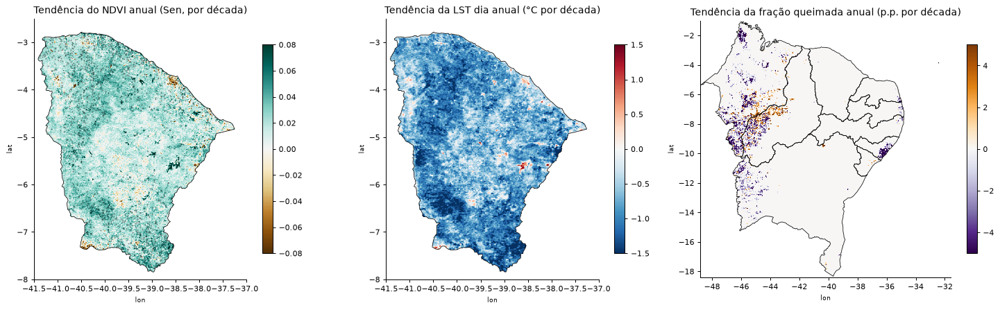

In [94]:
cube = anu.ndvi.values.reshape(anu.sizes["year"], -1)[:, mk_ce01.ravel()]
sen, z, p = mk_vetorizado(cube)
mapa_sen = np.full(mk_ce01.size, np.nan, "float32")
mapa_sen[mk_ce01.ravel()] = sen
mapa_p = np.full(mk_ce01.size, np.nan, "float32")
mapa_p[mk_ce01.ravel()] = p
mapa_sen = mapa_sen.reshape(mk_ce01.shape)
mapa_p = mapa_p.reshape(mk_ce01.shape)
lstan = lstm.lst_dia.sel(time=lstm.time.dt.year.isin(range(2001, 2026))).groupby("time.year").mean()
cube2 = lstan.values.reshape(lstan.sizes["year"], -1)[:, mk_ce01.ravel()]
sen2, z2, p2 = mk_vetorizado(cube2)
m2 = np.full(mk_ce01.size, np.nan, "float32")
m2[mk_ce01.ravel()] = sen2
m2 = m2.reshape(mk_ce01.shape)
p2m = np.full(mk_ce01.size, np.nan, "float32")
p2m[mk_ce01.ravel()] = p2
p2m = p2m.reshape(mk_ce01.shape)

fig, axs = plt.subplots(1, 3, figsize=(17, 5))
da_sen = xr.DataArray(mapa_sen * 10, coords={"lat": anu.lat, "lon": anu.lon}, dims=("lat", "lon"))
mapa(da_sen, "Tendência do NDVI anual (Sen, por década)", axs[0], "BrBG", -0.08, 0.08)
yy, xx = np.where(mapa_p < 0.05)
axs[0].scatter(anu.lon.values[xx[::23]], anu.lat.values[yy[::23]], s=0.3, c="k", alpha=0.4)
da2 = xr.DataArray(m2 * 10, coords={"lat": anu.lat, "lon": anu.lon}, dims=("lat", "lon"))
mapa(da2, "Tendência da LST dia anual (°C por década)", axs[1], "RdBu_r", -1.5, 1.5)
for nome, pp, ss in (("NDVI", mapa_p, mapa_sen), ("LST", p2m, m2)):
    v = np.isfinite(pp)
    print(f"{nome}: % pixels com tendência significativa (p<0,05): {100 * np.mean(pp[v] < 0.05):.1f}% | "
          f"positiva {100 * np.mean((pp[v] < 0.05) & (ss[v] > 0)):.1f}% | negativa {100 * np.mean((pp[v] < 0.05) & (ss[v] < 0)):.1f}%")
fa = fq.frac_queimada.sel(time=fq.time.dt.year.isin(range(2001, 2026))).groupby("time.year").sum()
cube3 = fa.values.reshape(fa.sizes["year"], -1)[:, mk_ne05b.ravel()]
sen3, _, p3 = mk_vetorizado(cube3)
m3 = np.full(mk_ne05b.size, np.nan, "float32")
m3[mk_ne05b.ravel()] = sen3 * 10 * 100
mapa(xr.DataArray(m3.reshape(mk_ne05b.shape), coords={"lat": fq.lat, "lon": fq.lon}, dims=("lat", "lon")),
     "Tendência da fração queimada anual (p.p. por década)", axs[2], "PuOr_r", -5, 5, NE)
plt.tight_layout()
plt.show()

## 9.7 Variabilidade interanual e extremos — a grande seca de 2012–2017

Anos mais secos pelo NDVI (z): {2012: -2.569999933242798, 2016: -1.9299999475479126, 2013: -1.7999999523162842, 2015: -1.7799999713897705, 2014: -1.3300000429153442, 2017: -1.149999976158142}
Anos mais verdes pelo NDVI (z): {2009: 1.3899999856948853, 2011: 1.9700000286102295, 2022: 2.059999942779541, 2025: 2.390000104904175}


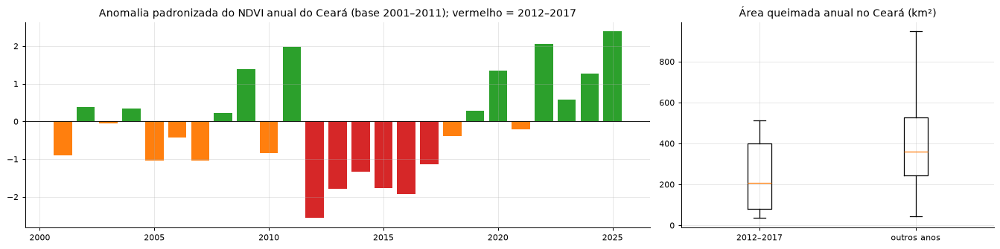

Área queimada CE – média 2012–2017: 244 km² | outros anos: 407 km²; Mann-Whitney p = 0.176
ET real CE – média 2012–2017: 748 mm | outros anos: 959 mm


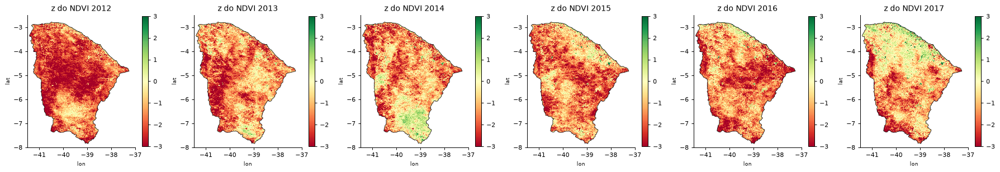

Ano do menor NDVI anual de cada pixel (fração do estado): {2012.0: 37.6, 2016.0: 14.0, 2013.0: 10.7, 2015.0: 9.5, 2014.0: 7.1, 2017.0: 5.7}


In [95]:
base = anu.ndvi.sel(year=slice(2001, 2011))
anom = (anu.ndvi - base.mean("year")) / base.std("year")
anom_ce = (ser["NDVI médio anual CE"] - ser["NDVI médio anual CE"].loc[2001:2011].mean()) / ser["NDVI médio anual CE"].loc[2001:2011].std()
fig, axs = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [2, 1]})
axs[0].bar(anom_ce.index, anom_ce.values, color=["tab:red" if y in SECA_GRANDE else ("tab:green" if v > 0 else "tab:orange") for y, v in anom_ce.items()])
axs[0].set_title("Anomalia padronizada do NDVI anual do Ceará (base 2001–2011); vermelho = 2012–2017")
axs[0].axhline(0, color="k", lw=0.7)
rank = anom_ce.sort_values()
print("Anos mais secos pelo NDVI (z):", rank.head(6).round(2).to_dict())
print("Anos mais verdes pelo NDVI (z):", rank.tail(4).round(2).to_dict())
q_ce = ser["Área queimada CE km²"]
axs[1].boxplot([q_ce[q_ce.index.isin(SECA_GRANDE)], q_ce[~q_ce.index.isin(SECA_GRANDE)]], tick_labels=["2012–2017", "outros anos"])
axs[1].set_title("Área queimada anual no Ceará (km²)")
plt.tight_layout()
plt.show()
print("Área queimada CE – média 2012–2017:", round(q_ce[q_ce.index.isin(SECA_GRANDE)].mean()), "km² | outros anos:",
      round(q_ce[~q_ce.index.isin(SECA_GRANDE)].mean()), "km²; Mann-Whitney p =",
      round(stats.mannwhitneyu(q_ce[q_ce.index.isin(SECA_GRANDE)], q_ce[~q_ce.index.isin(SECA_GRANDE)]).pvalue, 4))
e_ce = ser["ET anual CE"]
print("ET real CE – média 2012–2017:", round(e_ce[e_ce.index.isin(SECA_GRANDE)].mean()), "mm | outros anos:",
      round(e_ce[~e_ce.index.isin(SECA_GRANDE)].mean()), "mm")

fig, axs = plt.subplots(1, 6, figsize=(20, 3.6))
for ax, y in zip(axs, SECA_GRANDE):
    mapa(anom.sel(year=y).where(mk_ce01), f"z do NDVI {y}", ax, "RdYlGn", -3, 3)
plt.tight_layout()
plt.show()
ano_min = anu.ndvi.where(mk_ce01).idxmin("year")
vc = pd.Series(ano_min.values[mk_ce01]).value_counts(normalize=True).head(6)
print("Ano do menor NDVI anual de cada pixel (fração do estado):", (vc * 100).round(1).to_dict())

## 9.8 Análises específicas
### 9.8.1 Fenologia por pixel (início, pico, fim e amplitude da estação)

Método: curva climatológica de 23 compostos (2001–2025) por pixel; limiar = mínimo + 50% da amplitude.
- **Início (SOS):** primeiro composto, a partir do vale, acima do limiar.
- **Pico (POS):** composto de NDVI máximo.
- **Fim (EOS):** primeiro composto após o pico abaixo do limiar.

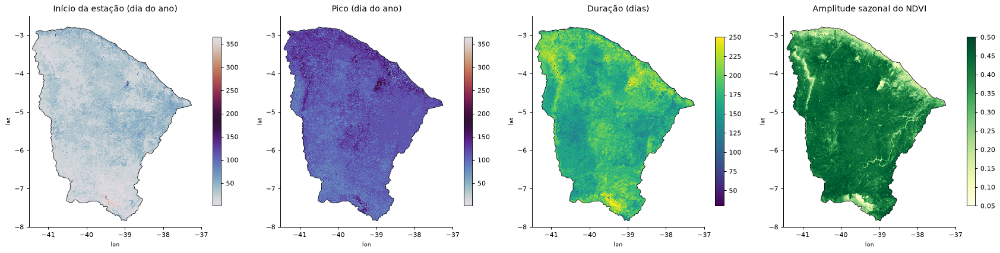

SOS: mediana 33 | p10 17 | p90 49
POS: mediana 113 | p10 81 | p90 129
EOS: mediana 209 | p10 177 | p90 225
duracao: mediana 176 | p10 144 | p90 208
amplitude: mediana 0.421 | p10 0.286 | p90 0.457
Mês típico do pico: abr


In [96]:
clim = carregar("mod13q1_ndvi_climatologia_001deg.nc")
C = clim.media.values  # (23, lat, lon)
nslot = C.shape[0]
flat = C.reshape(nslot, -1)
valido = np.isfinite(flat).sum(0) >= 18
flat = np.where(np.isfinite(flat), flat, np.nanmean(flat, axis=0, keepdims=True))
vmin_i = np.nanargmin(np.where(np.isfinite(flat), flat, np.inf), axis=0)
idx = (vmin_i[None, :] + np.arange(nslot)[:, None]) % nslot
rol = np.take_along_axis(flat, idx, axis=0)
amp = rol.max(0) - rol.min(0)
thr = rol.min(0) + 0.5 * amp
pos_r = rol.argmax(0)
acima = rol > thr[None, :]
sos_r = acima.argmax(0)
apos = (np.arange(nslot)[:, None] > pos_r[None, :]) & ~acima
eos_r = np.where(apos.any(0), apos.argmax(0), nslot - 1)
doy = lambda r: ((vmin_i + r) % nslot) * 16 + 1  # noqa: E731
SOS, POS, EOS = doy(sos_r), doy(pos_r), doy(eos_r)
dur = ((eos_r - sos_r) * 16).astype(float)
shape2 = C.shape[1:]
fen = {}
for nome, arr in (("SOS", SOS), ("POS", POS), ("EOS", EOS), ("duracao", dur), ("amplitude", amp)):
    a = np.where(valido & mk_ce01.ravel(), arr, np.nan).astype("float32").reshape(shape2)
    fen[nome] = xr.DataArray(a, coords={"lat": clim.lat, "lon": clim.lon}, dims=("lat", "lon"))
fig, axs = plt.subplots(1, 4, figsize=(19, 4.5))
mapa(fen["SOS"], "Início da estação (dia do ano)", axs[0], "twilight", 1, 365)
mapa(fen["POS"], "Pico (dia do ano)", axs[1], "twilight", 1, 365)
mapa(fen["duracao"], "Duração (dias)", axs[2], "viridis", 30, 250)
mapa(fen["amplitude"], "Amplitude sazonal do NDVI", axs[3], "YlGn", 0.05, 0.5)
plt.tight_layout()
plt.show()
for nome in ("SOS", "POS", "EOS", "duracao", "amplitude"):
    v = fen[nome].values[np.isfinite(fen[nome].values)]
    print(f"{nome}: mediana {np.median(v):.0f} | p10 {np.percentile(v, 10):.0f} | p90 {np.percentile(v, 90):.0f}" if nome != "amplitude"
          else f"{nome}: mediana {np.median(v):.3f} | p10 {np.percentile(v, 10):.3f} | p90 {np.percentile(v, 90):.3f}")
med_pos = int(np.nanmedian(fen["POS"].values))
print("Mês típico do pico:", MESES[(pd.Timestamp("2021-01-01") + pd.Timedelta(days=med_pos - 1)).month - 1])

### 9.8.2 Janelas de solo nu / vegetação rala nas AOIs (NDVI < 0,25 a 250 m)

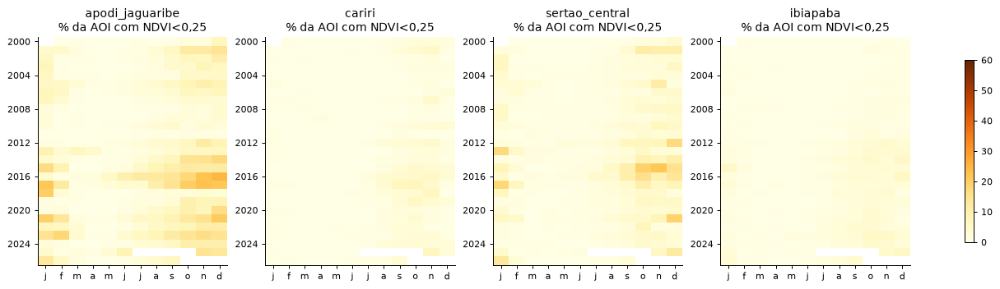

% médio da AOI com NDVI < 0,25 por mês:
                 jan  fev  mar  abr  mai  jun  jul  ago  set  out  nov   dez
aoi                                                                         
apodi_jaguaribe  7.4  3.7  1.2  0.4  0.7  1.6  2.4  3.8  5.5  8.0  9.1  10.1
cariri           0.3  0.2  0.1  0.1  0.1  0.1  0.3  0.9  1.9  2.6  2.8   1.1
ibiapaba         1.2  0.3  0.1  0.1  0.1  0.2  0.5  1.1  1.7  2.3  2.2   2.0
sertao_central   4.9  1.5  0.5  0.4  0.4  0.5  1.1  1.7  3.4  5.7  5.7   6.5


In [97]:
fig, axs = plt.subplots(1, len(AOIS), figsize=(19, 4))
for ax, nm in zip(axs, AOIS):
    a = aoi_m[(aoi_m.aoi == nm) & (aoi_m.variavel == "frac_solo_nu_ndvi_lt_025")].copy()
    a["ano"] = a.data.dt.year
    hm = a.pivot_table(index="ano", columns="mes", values="valor")
    im = ax.imshow(hm.values * 100, aspect="auto", cmap="YlOrBr", vmin=0, vmax=60)
    ax.set_xticks(range(12), [m[0] for m in MESES])
    ax.set_yticks(range(0, len(hm.index), 4), hm.index[::4])
    ax.set_title(f"{nm}\n% da AOI com NDVI<0,25")
    ax.grid(False)
plt.colorbar(im, ax=axs, shrink=0.8)
plt.show()
sn = aoi_m[aoi_m.variavel == "frac_solo_nu_ndvi_lt_025"].groupby(["aoi", "mes"]).valor.mean().unstack() * 100
sn.columns = MESES
print("% médio da AOI com NDVI < 0,25 por mês:")
print(sn.round(1).to_string())

### 9.8.3 Resposta do NDVI à chuva e à umidade do solo, com defasagem
Usa as séries mensais do Ceará produzidas pelas outras frentes em `dados/derivados/`. Ordem de preferência para a
chuva: IMERG (`precip_total`), depois POWER (`PRECTOTCORR`), depois ERA5 (`tp`). Fica a que tiver mais meses em comum
com o NDVI. A umidade do solo da zona da raiz vem do POWER (`GWETROOT`, MERRA-2). As correlações são calculadas
sobre **anomalias** (cada mês menos a média daquele mês do ano), para não confundir a resposta com o ciclo sazonal.

candidata imerg_ce_mensal.parquet/precip_total: 1998-01–2026-09, 316 meses em comum com o NDVI
candidata power_ce_mensal.parquet/PRECTOTCORR: 1981-01–2026-10, 316 meses em comum com o NDVI
candidata era5_ce_mensal.parquet/tp: 1979-01–2020-12, 251 meses em comum com o NDVI
Precipitação usada: imerg_ce_mensal.parquet/precip_total
 defasagem_meses  r_bruto  r_anomalias
               0    0.696        0.368
               1    0.840        0.485
               2    0.709        0.323
               3    0.422        0.280
               4    0.039        0.223
r(anomalia NDVI, anomalia da chuva acumulada nos k meses anteriores): {1: np.float64(0.368), 2: np.float64(0.543), 3: np.float64(0.577), 4: np.float64(0.598), 6: np.float64(0.592)}
NDVI × umidade da zona da raiz (POWER GWETROOT), anomalias:
 defasagem_meses  r_anomalias
               0        0.512
               1        0.460
               2        0.362
               3        0.306
               4        0.264


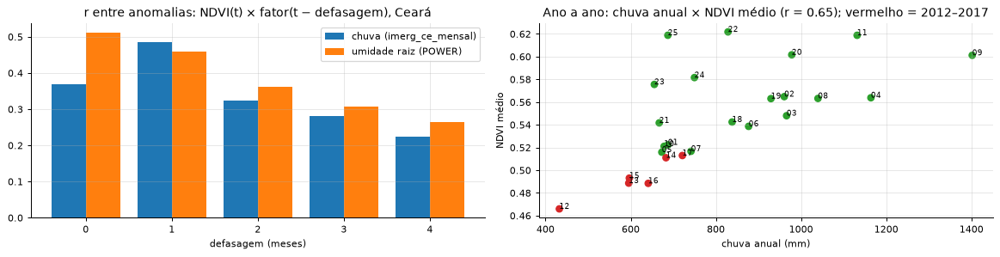

r anual chuva × NDVI = 0.649 (n = 25)


In [98]:
nd_ce = ce_m[ce_m.variavel == "ndvi"].set_index("data").valor.sort_index()


def serie_derivada(arquivo, variavel):
    p = DERIV / arquivo
    if not p.exists():
        return None
    d = pd.read_parquet(p).dropna(subset=["valor"])
    d = d[d.variavel == variavel]
    if d.empty:
        return None
    s = d.groupby(pd.to_datetime(d.data).dt.to_period("M").dt.to_timestamp()).valor.mean().sort_index()
    return s


candidatas = [("imerg_ce_mensal.parquet", "precip_total"), ("power_ce_mensal.parquet", "PRECTOTCORR"),
              ("era5_ce_mensal.parquet", "tp")]
melhor = None
for arq, var in candidatas:
    s = serie_derivada(arq, var)
    if s is None:
        continue
    n_comum = len(pd.concat([nd_ce, s], axis=1).dropna())
    print(f"candidata {arq}/{var}: {s.index.min():%Y-%m}–{s.index.max():%Y-%m}, {n_comum} meses em comum com o NDVI")
    if melhor is None or n_comum > melhor[2] + 24:
        melhor = (f"{arq}/{var}", s, n_comum)


def anomalia(s):
    return s.groupby(s.index.month).transform(lambda x: x - x.mean())


if melhor is None:
    print("Nenhuma série de precipitação em derivados/ — rode de novo depois das frentes POWER/IMERG.")
else:
    nome_p, prec, _ = melhor
    print("Precipitação usada:", nome_p)
    j = pd.concat({"ndvi": nd_ce, "prec": prec}, axis=1).dropna()
    an = j.apply(anomalia)
    res = pd.DataFrame([{"defasagem_meses": lag, "r_bruto": j.ndvi.corr(j.prec.shift(lag)),
                         "r_anomalias": an.ndvi.corr(an.prec.shift(lag))} for lag in range(0, 5)])
    print(res.round(3).to_string(index=False))
    acum = {k: an.ndvi.corr(anomalia(j.prec.rolling(k).sum()).reindex(an.index)) for k in (1, 2, 3, 4, 6)}
    print("r(anomalia NDVI, anomalia da chuva acumulada nos k meses anteriores):", {k: round(v, 3) for k, v in acum.items()})
    sm = serie_derivada("power_ce_mensal.parquet", "GWETROOT")
    res_sm = None
    if sm is not None:
        js = pd.concat({"ndvi": nd_ce, "sm": sm}, axis=1).dropna().apply(anomalia)
        res_sm = pd.DataFrame([{"defasagem_meses": lag, "r_anomalias": js.ndvi.corr(js.sm.shift(lag))} for lag in range(0, 5)])
        print("NDVI × umidade da zona da raiz (POWER GWETROOT), anomalias:")
        print(res_sm.round(3).to_string(index=False))
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.4))
    axs[0].bar(res.defasagem_meses - 0.2, res.r_anomalias, 0.4, label="chuva (" + nome_p.split(".")[0] + ")")
    if res_sm is not None:
        axs[0].bar(res_sm.defasagem_meses + 0.2, res_sm.r_anomalias, 0.4, label="umidade raiz (POWER)")
    axs[0].set_title("r entre anomalias: NDVI(t) × fator(t − defasagem), Ceará")
    axs[0].set_xlabel("defasagem (meses)")
    axs[0].legend()
    anual = j.groupby(j.index.year).agg(ndvi=("ndvi", "mean"), prec=("prec", "sum"))
    anual = anual[(anual.index >= 2001) & (anual.index <= 2025)]
    axs[1].scatter(anual.prec, anual.ndvi, c=["tab:red" if y in SECA_GRANDE else "tab:green" for y in anual.index])
    for y, r_ in anual.iterrows():
        axs[1].annotate(str(y)[2:], (r_.prec, r_.ndvi), fontsize=7)
    rr_ = np.corrcoef(anual.prec, anual.ndvi)[0, 1]
    axs[1].set_title(f"Ano a ano: chuva anual × NDVI médio (r = {rr_:.2f}); vermelho = 2012–2017")
    axs[1].set_xlabel("chuva anual (mm)")
    axs[1].set_ylabel("NDVI médio")
    plt.tight_layout()
    plt.show()
    print(f"r anual chuva × NDVI = {rr_:.3f} (n = {len(anual)})")

### 9.8.4 Fogo × cobertura do solo — lavoura ou Caatinga?

                                             % da área do NE  % dos focos VIIRS  % da classe queimada por ano (MCD64A1)
Arbustiva/Caatinga                                     33.78              42.07                                    3.84
Lavoura                                                22.17              13.27                                    1.92
Floresta perene/mista                                  12.84              18.32                                    1.64
Floresta decídua (Caatinga arbórea/Cerrado)            11.99              14.17                                    2.16
Campo/herbácea                                         10.75               7.77                                    1.79
Mosaico veg.+lavoura                                    6.60               3.85                                    1.10
Água                                                    0.95               0.09                                    0.16
Alagado                                 

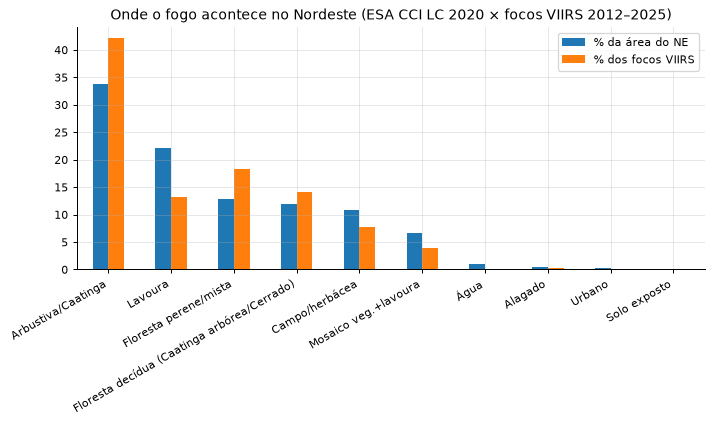

In [99]:
lc = carregar("esa_cci_lc_2020_nordeste_300m.nc")
# No semiárido, o ESA CCI chama a Caatinga arbórea de "floresta decídua" (classes 60–62): separamos.
GR = {"Lavoura": [10, 11, 12, 20, 30], "Mosaico veg.+lavoura": [40], "Floresta perene/mista": [50, 70, 71, 72, 80, 81, 82, 90],
      "Floresta decídua (Caatinga arbórea/Cerrado)": [60, 61, 62],
      "Arbustiva/Caatinga": [100, 110, 120, 121, 122], "Campo/herbácea": [130, 140, 150, 151, 152, 153],
      "Alagado": [160, 170, 180], "Urbano": [190], "Solo exposto": [200, 201, 202], "Água": [210]}
mapa_gr = {c: g for g, cs in GR.items() for c in cs}
lcv = lc.lccs_class.values
la0, lo0 = float(lc.lat[0]), float(lc.lon[0])
rlc = abs(float(lc.lat[1] - lc.lat[0]))


def classe_em(lat, lon):
    i = np.clip(np.round((la0 - lat) / rlc).astype(int), 0, lcv.shape[0] - 1)
    j = np.clip(np.round((lon - lo0) / rlc).astype(int), 0, lcv.shape[1] - 1)
    return lcv[i, j]


vz = viirs.copy()
vz["lc"] = classe_em(vz.latitude.values, vz.longitude.values)
vz["grupo"] = vz.lc.map(mapa_gr).fillna("outros")
dist_focos = vz.groupby("grupo").size() / len(vz) * 100
mk_lc = mascara(lc.lat.values, lc.lon.values, NE)
cls_area = pd.Series(lcv[mk_lc]).map(mapa_gr).fillna("outros").value_counts(normalize=True) * 100
LAT2, LON2 = np.meshgrid(qa.lat.values, qa.lon.values, indexing="ij")
cl_q = classe_em(LAT2[mk_nef], LON2[mk_nef])
gq = pd.Series(cl_q).map(mapa_gr).fillna("outros")
queim_media = qa.queimado.mean("ano").values[mk_nef]
taxa = pd.DataFrame({"grupo": gq.values, "q": queim_media}).groupby("grupo").q.mean() * 100
comp = pd.DataFrame({"% da área do NE": cls_area, "% dos focos VIIRS": dist_focos,
                     "% da classe queimada por ano (MCD64A1)": taxa}).round(2).sort_values("% da área do NE", ascending=False)
print(comp.to_string())
vce = vz[vz.uf == 23]
area_foco = pd.DataFrame({"area_queimada_km2_2012_2025": fogo_uf[fogo_uf.ano.between(2012, 2025)].groupby("uf").area_queimada_km2.sum(),
                          "focos_viirs_2012_2025": viirs[viirs.ano.between(2012, 2025)].groupby("uf").size()})
area_foco["km2_por_foco"] = area_foco.area_queimada_km2_2012_2025 / area_foco.focos_viirs_2012_2025
area_foco.index = area_foco.index.map(UF_NOME)
print("Área queimada (MCD64A1, 500 m) por foco ativo (VIIRS, 375 m) – quanto menor, menores as queimadas:")
print(area_foco.round(3).sort_values("km2_por_foco").to_string())
print("\nCeará – % dos focos VIIRS por classe:", (vce.groupby("grupo").size() / len(vce) * 100).round(1).sort_values(ascending=False).to_dict())
fig, ax = plt.subplots(figsize=(9, 3.5))
comp[["% da área do NE", "% dos focos VIIRS"]].plot.bar(ax=ax)
ax.set_title("Onde o fogo acontece no Nordeste (ESA CCI LC 2020 × focos VIIRS 2012–2025)")
plt.xticks(rotation=30, ha="right")
plt.show()

### 9.8.5 Temperatura da superfície × NDVI — estresse térmico e índice TVDI

No espaço LST × NDVI, pixels secos ficam na "borda quente" e pixels bem supridos de água na "borda fria". O
**TVDI** (*Temperature–Vegetation Dryness Index*) = (LST − LST_fria(NDVI)) / (LST_quente(NDVI) − LST_fria(NDVI))
é um indicador de umidade do solo a 1 km que só usa NDVI e LST (MODIS/VIIRS), portanto **global**.

Correlação de Pearson NDVI × LST dia por mês (pixels do Ceará): {'jan': np.float64(-0.72), 'fev': np.float64(-0.68), 'mar': np.float64(-0.64), 'abr': np.float64(-0.56), 'mai': np.float64(-0.71), 'jun': np.float64(-0.76), 'jul': np.float64(-0.77), 'ago': np.float64(-0.7), 'set': np.float64(-0.67), 'out': np.float64(-0.65), 'nov': np.float64(-0.68), 'dez': np.float64(-0.69)}
abril/2009 (ano chuvoso): TVDI médio no Ceará = 0.539; inclinação da borda quente = -3.7 °C por unidade de NDVI


outubro/2012 (seca): TVDI médio no Ceará = 0.746; inclinação da borda quente = -18.1 °C por unidade de NDVI


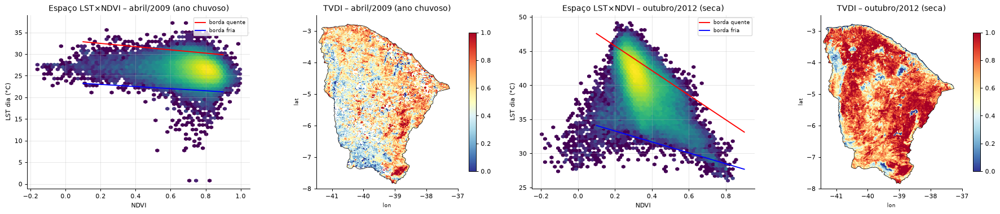

In [100]:
nd_al, ls_al = xr.align(ndm.ndvi, lstm.lst_dia, join="inner")
corr_mes = []
for m in range(1, 13):
    sel = nd_al.time.dt.month == m
    a = nd_al.sel(time=sel).values[:, mk_ce01].ravel()
    b = ls_al.sel(time=sel).values[:, mk_ce01].ravel()
    ok = np.isfinite(a) & np.isfinite(b)
    corr_mes.append(np.corrcoef(a[ok], b[ok])[0, 1] if ok.sum() > 100 else np.nan)
print("Correlação de Pearson NDVI × LST dia por mês (pixels do Ceará):", dict(zip(MESES, np.round(corr_mes, 2))))


def tvdi(nd, ls, nb=30):
    ok = np.isfinite(nd) & np.isfinite(ls)
    bins = np.linspace(0.1, 0.9, nb + 1)
    c, lmax, lmin = [], [], []
    for k in range(nb):
        s = ok & (nd >= bins[k]) & (nd < bins[k + 1])
        if s.sum() > 50:
            c.append((bins[k] + bins[k + 1]) / 2)
            lmax.append(np.percentile(ls[s], 99))
            lmin.append(np.percentile(ls[s], 1))
    c, lmax, lmin = map(np.array, (c, lmax, lmin))
    aq, bq = np.polyfit(c, lmax, 1)
    af, bf = np.polyfit(c, lmin, 1)
    t = (ls - (af * nd + bf)) / ((aq * nd + bq) - (af * nd + bf))
    return np.clip(t, 0, 1), (aq, bq, af, bf), (c, lmax, lmin)


fig, axs = plt.subplots(1, 4, figsize=(20, 4.3))
casos = [("2009-04", "abril/2009 (ano chuvoso)"), ("2012-10", "outubro/2012 (seca)")]
for k, (mes, rot) in enumerate(casos):
    nd2 = nd_al.sel(time=mes).squeeze().values
    ls2 = ls_al.sel(time=mes).squeeze().values
    nd2 = np.where(mk_ce01, nd2, np.nan)
    ls2 = np.where(mk_ce01, ls2, np.nan)
    tv, coef, pts_e = tvdi(nd2, ls2)
    ok = np.isfinite(nd2) & np.isfinite(ls2)
    axs[2 * k].hexbin(nd2[ok], ls2[ok], gridsize=60, bins="log", cmap="viridis")
    xs = np.linspace(0.1, 0.9, 10)
    axs[2 * k].plot(xs, coef[0] * xs + coef[1], "r-", label="borda quente")
    axs[2 * k].plot(xs, coef[2] * xs + coef[3], "b-", label="borda fria")
    axs[2 * k].set_xlabel("NDVI")
    axs[2 * k].set_ylabel("LST dia (°C)")
    axs[2 * k].set_title(f"Espaço LST×NDVI – {rot}")
    axs[2 * k].legend(fontsize=7)
    mapa(xr.DataArray(tv, coords={"lat": ndm.lat, "lon": ndm.lon}, dims=("lat", "lon")), f"TVDI – {rot}", axs[2 * k + 1], "RdYlBu_r", 0, 1)
    print(f"{rot}: TVDI médio no Ceará = {np.nanmean(tv):.3f}; inclinação da borda quente = {coef[0]:.1f} °C por unidade de NDVI")
plt.tight_layout()
plt.show()

## 9.9 Insights e ideias para o produto

Os números abaixo saíram das células acima, executadas em 13/11/2026 sobre os dados baixados.

**Cobertura global (veredito):** NDVI/EVI (MOD13), LST (MOD11), área queimada (MCD64A1) e focos FIRMS são
**globais sobre terra**: 294, 317 e 268 tiles por período, com valores válidos em 14 pontos de 6 continentes. O ET
(MOD16) é global, mas deixa urbano, água e solo nu sem valor por desenho. Riscos para o produto mundial:
- Terra e Aqua estão em fim de vida. Há buraco de **26/06 a 17/11/2025** no NDVI e na LST do Terra no catálogo, e a
  deriva orbital contamina tendências da LST diurna.
- O catálogo do Planetary Computer tem lacunas pontuais: MCD64A1 de jul/2024 com 46 tiles e de nov/2024 com 48% do NE.
- A continuidade está no **VIIRS**: o NDVI VNP13 exige Earthdata Login; os focos FIRMS são abertos.

### Insights mais fortes
1. **O calendário agrícola do Ceará é curto e bem definido.** Início da estação no dia 33 (~2 fev); pico no
   dia 113 (~23 abr); fim no dia 209 (~28 jul); duração mediana de 176 dias. O NDVI estadual vai de 0,37 (out) a
   0,76 (abr). No auge seco, o Sertão Central cai a 0,34 e o Apodi a 0,39; a Ibiapaba segura 0,55. A janela de
   **solo exposto** vai de set a jan: Apodi chega a 10% da área com NDVI < 0,25 em dezembro; Sertão Central a 6,5%.
   *Uso no produto:* é a janela para plantas de cobertura ou forrageiras nas áreas irrigadas e para manter palhada
   no sequeiro.
2. **A vegetação responde à chuva com 1 mês de atraso e tem "memória" de 3–4 meses.**
   - NDVI(t) × chuva IMERG(t−1): r = 0,84 nos dados brutos e 0,49 nas anomalias.
   - Com a chuva acumulada em 4 meses, r = 0,60.
   - Com a umidade da zona da raiz (POWER/MERRA-2) no mesmo mês, r = 0,51.
   - Ano a ano, chuva × NDVI: r = 0,65.
   *Uso:* prever vigor e estresse com 1–2 meses de antecedência a partir de IMERG + SMAP + índices de ENSO e do Atlântico.
3. **A seca de 2012–2017 é o maior sinal da série de 25 anos.** 2012 foi o pior ano (z = −2,57 no NDVI anual) e é o
   ano de menor NDVI em 37,6% do estado. A ET real caiu de 959 para 748 mm/ano (−22%). Os anos mais verdes foram 2025
   (z = +2,39), 2022, 2011 e 2009. *Uso:* mostrar ao agricultor o "ano típico" e o "ano de seca" de cada rotação
   proposta, com o histórico real do pixel.
4. **No Ceará o fogo é pequeno, frequente e anterior ao plantio.**
   - São ~22 mil focos VIIRS por ano (15–30 mil); 72% caem em out–dez e 88% da área queimada fica em set–dez.
   - Cada foco VIIRS corresponde a só 0,016 km² de área queimada no MCD64A1, 7–8× menos que no MA, PI e BA.
     O produto de 500 m **não enxerga** as queimadas do Ceará; o sensor certo é o VIIRS de 375 m, mais
     Sentinel-2/HLS para as cicatrizes.
   - 62% dos focos caem em Caatinga (arbórea 42% + arbustiva 20%), 14% em lavoura e 8% em mosaico. É a assinatura
     do **roçado com queima** (agricultura itinerante) e da limpeza de pasto.
   - A tendência dos focos no Ceará é +29%/década, mas com p = 0,08 (sinal fraco).
   *Uso:* alerta de "risco de queima pré-plantio" e recomendação de alternativas (palhada, plantio direto,
   leguminosa de cobertura), que conversam diretamente com saúde do solo e rotação.
5. **LST × NDVI dá um índice de secura a 1 km que funciona no mundo todo.** A correlação é negativa em todos os
   meses (r de −0,56 a −0,77), mais fraca em abril, quando a água não limita. O TVDI médio do Ceará vai de 0,54
   (abr/2009, chuvoso) a 0,75 (out/2012, seca), e a borda quente fica 5× mais íngreme na seca. *Uso:* camada de
   estresse hídrico mais fina que o SMAP (9 km), calculável só com MODIS/VIIRS.

### Outros achados
- **O déficit hídrico é o fator dominante:** ET potencial de 2.563 mm/ano contra ET real de 910 mm/ano, ou seja,
  déficit de ~1.650 mm. Rotação e consórcio precisam ser escolhidos pelo balanço hídrico; irrigação só onde há água
  (cruzar com GRACE e outorgas).
- **Tendências:** 23,8% dos pixels têm tendência positiva significativa do NDVI (esverdeamento), contra 1% negativa,
  mas a média estadual não é significativa (+3,7%/década, p = 0,18). A LST **noturna** sobe +0,33 °C/década
  (p = 0,016). A LST **diurna** "cai" em 23,8% dos pixels, o que provavelmente é artefato da deriva orbital do
  Terra; não usar a LST diurna do Terra para tendência. No Nordeste inteiro (MOD13A1, 0,05°), o NDVI médio é 0,59,
  também sem tendência significativa (+1,8%/década, p = 0,27).
- **Nuvem:** só 60–67% dos pixels de NDVI são de boa qualidade em jan–mar, contra 96–99% em jun–out. O produto
  precisa de suavização temporal, fusão com radar (Sentinel-1/NISAR) e um indicador de confiança por mês.
- **Fogo no Nordeste:** MA, PI e BA, no Cerrado, concentram 95% da área queimada (média de 17,5, 10,9 e 10,6 mil
  km²/ano). O pico regional é em setembro; o do Ceará, em outubro–novembro. A seca de 2012–2017 **não** aumentou a
  área queimada no Ceará (244 contra 407 km²/ano; p = 0,18). Hipótese: em seca há menos biomassa e menos roçado
  plantado.

### Ideias de modelos para implementar
- **Fenologia por talhão:** suavização Whittaker ou Savitzky–Golay, e depois detecção de início, pico e fim. Usar
  HLS a 30 m para o talhão e MODIS para o histórico desde 2000. Fora dos EUA, isso substitui o CDL para descobrir
  a "rotação atual" e as janelas de solo nu.
- **Previsão de NDVI/estresse 1–3 meses à frente:**
  - entradas: chuva acumulada (IMERG), umidade (SMAP, POWER GWETROOT), LST, TVDI e índices climáticos;
  - modelos: gradient boosting com defasagens, LSTM ou Temporal Fusion Transformer por pixel, ConvLSTM para mapas;
  - validação: por ano, deixando 2012–2017 fora do treino como teste de estresse.
- **Classificador "queima agrícola × vegetação nativa":** foco VIIRS + NDVI antes e depois + cobertura do solo.
  Saída: alerta e recomendação de manejo de palhada.
- **Camada global de estresse hídrico (TVDI/ESI) a 1 km**, harmonizando MODIS (2000–2025) e VIIRS (2012–) no
  período comum (regressão ou mapeamento de quantis), para que o sistema seja agnóstico ao sensor.

# 10. SRTM / NASADEM: relevo (NASA)

**O que é:** o modelo digital de elevação da missão Shuttle Radar Topography (fevereiro de 2000), reprocessado pela
NASA como **NASADEM** em 2020 (melhor controle de altura e vazios preenchidos). A resolução é de 1 arcsegundo (~30 m).
É uma foto única do relevo: não tem série temporal, mas é a base de **declividade, escoamento, erosão e microclima**.

**Como baixamos:** Planetary Computer (`nasadem`, tiles de 1°, COG):
- mosaico do Ceará a 30 m;
- derivados a 90 m: declividade, aspecto e TPI (posição topográfica) a 1 e 5 km;
- hidrologia a 270 m: preenchimento de depressões (*priority-flood*), fluxo D8, área de contribuição, **TWI** e fator
  **LS da RUSLE**;
- as mesmas camadas a 30 m em cada AOI;
- Nordeste a ~1 km.

Validação global por contagem de tiles contra as células de terra (Natural Earth), comparando com o Copernicus
DEM GLO-30.

In [101]:
import json
import sys
import warnings

sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import xarray as xr
from rasterio.features import rasterize
from comum import AOIS, DADOS, ceara_gdf, nordeste_gdf, paises_gdf

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
D = DADOS / "srtm"
man = json.loads((D / "MANIFESTO.json").read_text(encoding="utf-8")) if (D / "MANIFESTO.json").exists() else {}

def ler_tif(nome):
    with rasterio.open(D / nome) as src:
        a = src.read(1).astype(np.float32); t = src.transform; nd = src.nodata
    if nd is not None and not np.isnan(nd):
        a[a == nd] = np.nan
    ext = [t.c, t.c + t.a * a.shape[1], t.f + t.e * a.shape[0], t.f]
    return a, t, ext

z90, t90, ext90 = ler_tif("nasadem_ceara_90m.tif")
s90, _, _ = ler_tif("declividade_ceara_90m.tif")
asp90, _, _ = ler_tif("aspecto_ceara_90m.tif")
tpi5, _, _ = ler_tif("tpi5km_ceara_90m.tif")
ce = ceara_gdf()
mask_ce = rasterize([(g, 1) for g in ce.geometry], out_shape=z90.shape, transform=t90, fill=0, dtype="uint8").astype(bool)
print("grade 90 m:", z90.shape, "| pixels dentro do Ceará:", int(mask_ce.sum()))

grade 90 m: (6600, 5400) | pixels dentro do Ceará: 17490171


## 10.1 Ficha técnica

In [102]:
pd.DataFrame([
    ("Provedor", "NASA/JPL (NASADEM_HGT v001, reprocessamento de 2020 do SRTM); espelho no Microsoft Planetary Computer"),
    ("Data da medição", "11–22/02/2000 (interferometria de radar banda C a bordo do ônibus espacial Endeavour)"),
    ("Resolução", "1 arcsegundo (~30 m); erro vertical típico de alguns metros, maior em florestas densas e encostas"),
    ("Cobertura declarada", "56°S a 60°N (limite da órbita do ônibus espacial)"),
    ("Acesso", "aberto (LP DAAC pede login Earthdata; o Planetary Computer não)"),
    ("Tamanho local", f"{man.get('tamanho_bytes', 0)/1e9:.2f} GB"),
], columns=["item", "valor"])

,item,valor
0,Provedor,"NASA/JPL (NASADEM_HGT v001, reprocessamento de 2020 do SRTM); espelho no Microsoft Planetary Computer"
1,Data da medição,11–22/02/2000 (interferometria de radar banda C a bordo do ônibus espacial Endeavour)
2,Resolução,"1 arcsegundo (~30 m); erro vertical típico de alguns metros, maior em florestas densas e encostas"
3,Cobertura declarada,56°S a 60°N (limite da órbita do ônibus espacial)
4,Acesso,aberto (LP DAAC pede login Earthdata; o Planetary Computer não)
5,Tamanho local,0.62 GB


## 10.2 Validação de cobertura global

In [103]:
g = pd.read_parquet(D / "srtm_cobertura_global.parquet")
g["faixa"] = (g.lat // 10) * 10
fx = g[g.terra].groupby("faixa").agg(celulas_terra=("terra", "size"), nasadem=("nasadem", "sum"), copdem=("copdem", "sum"))
fx["%NASADEM"] = (100 * fx.nasadem / fx.celulas_terra).round(1); fx["%CopDEM"] = (100 * fx.copdem / fx.celulas_terra).round(1)
fx.index = [f"{int(i)}° a {int(i)+10}°" for i in fx.index]
print(f"Tiles NASADEM: {int(g.nasadem.sum()):,} | tiles Copernicus GLO-30: {int(g.copdem.sum()):,} | células de 1° com terra: {int(g.terra.sum()):,}")
fx

Tiles NASADEM: 14,520 | tiles Copernicus GLO-30: 26,445 | células de 1° com terra: 24,972


,celulas_terra,nasadem,copdem,%NASADEM,%CopDEM
-90° a -80°,3465,0,3465,0.0,100.0
-80° a -70°,2592,0,2592,0.0,100.0
-70° a -60°,492,0,492,0.0,100.0
-60° a -50°,69,68,69,98.6,100.0
-50° a -40°,178,178,178,100.0,100.0
-40° a -30°,492,492,492,100.0,100.0
-30° a -20°,916,915,915,99.9,99.9
-20° a -10°,959,950,958,99.1,99.9
-10° a 0°,1123,1119,1120,99.6,99.7
0° a 10°,1011,1011,1011,100.0,100.0


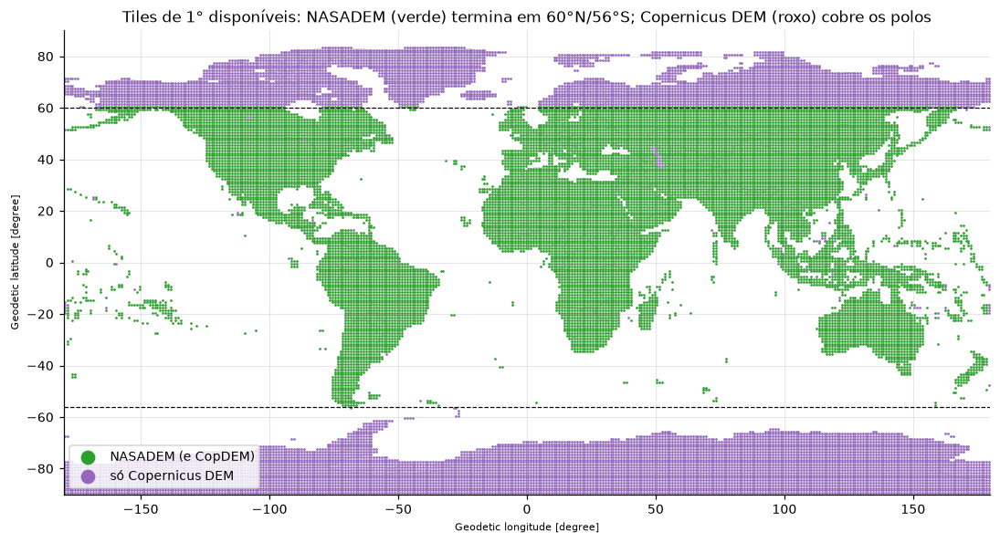

In [104]:
fig, ax = plt.subplots(figsize=(13, 6))
paises_gdf().plot(ax=ax, color="#f2f2f2", edgecolor="#bbbbbb", lw=0.3)
so_cop = g[g.copdem & ~g.nasadem]; ambos = g[g.nasadem]
ax.scatter(ambos.lon + 0.5, ambos.lat + 0.5, s=0.6, c="tab:green", label="NASADEM (e CopDEM)")
ax.scatter(so_cop.lon + 0.5, so_cop.lat + 0.5, s=0.6, c="tab:purple", label="só Copernicus DEM")
ax.axhline(60, color="k", ls="--", lw=0.8); ax.axhline(-56, color="k", ls="--", lw=0.8)
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.legend(markerscale=12, loc="lower left")
ax.set_title("Tiles de 1° disponíveis: NASADEM (verde) termina em 60°N/56°S; Copernicus DEM (roxo) cobre os polos"); plt.show()

**Veredito de cobertura:**
- O NASADEM/SRTM é **quase global**: cobre todas as terras entre 56°S e 60°N, onde está a imensa maioria da
  agricultura do mundo, inclusive todo o Brasil, a África, a Índia, a China, os EUA e o sul do Canadá.
- Fica fora o norte do Canadá, da Escandinávia, da Rússia e do Alasca, além da Groenlândia e da Antártida.
- Para o produto ser 100% global, a solução é usar **Copernicus DEM GLO-30 como reserva** acima de 60°N, ou como
  base única. Ele também é aberto e cobre os polos.

In [105]:
dentro = z90[mask_ce]
print(f"Vazios (NaN) dentro do Ceará a 90 m: {np.isnan(dentro).mean()*100:.4f}%  (o NASADEM já vem com vazios preenchidos)")
print(f"Pixels com elevação < 0 m dentro do Ceará: {(dentro < 0).mean()*100:.3f}% (litoral/estuários e ruído do radar)")

Vazios (NaN) dentro do Ceará a 90 m: 0.0000%  (o NASADEM já vem com vazios preenchidos)
Pixels com elevação < 0 m dentro do Ceará: 0.067% (litoral/estuários e ruído do radar)


## 10.3 Estatística descritiva do relevo do Ceará

In [106]:
zc = dentro[np.isfinite(dentro)]; sc = s90[mask_ce]; sc = sc[np.isfinite(sc)]
desc = pd.Series({"elev_media_m": zc.mean(), "elev_dp_m": zc.std(), "elev_p05": np.percentile(zc, 5), "elev_p50": np.median(zc),
                  "elev_p95": np.percentile(zc, 95), "elev_max": zc.max(), "assimetria": pd.Series(zc).skew(),
                  "% abaixo de 200 m": (zc < 200).mean() * 100, "% acima de 600 m": (zc > 600).mean() * 100,
                  "declividade_media_graus": sc.mean(), "declividade_p90_graus": np.percentile(sc, 90)}).round(2)
desc

elev_media_m                290.75
elev_dp_m                   217.31
elev_p05                     27.11
elev_p50                    253.11
elev_p95                    720.00
elev_max                   1130.78
assimetria                    0.84
% abaixo de 200 m            41.98
% acima de 600 m             10.10
declividade_media_graus       3.67
declividade_p90_graus         8.48
dtype: float64

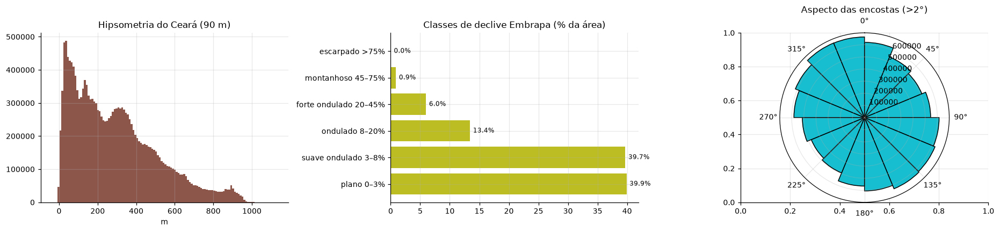

plano 0–3%               39.91
suave ondulado 3–8%      39.71
ondulado 8–20%           13.44
forte ondulado 20–45%     5.99
montanhoso 45–75%         0.91
escarpado >75%            0.05


In [107]:
tg = np.tan(np.deg2rad(sc)) * 100
classes = pd.cut(tg, [-1, 3, 8, 20, 45, 75, 1e9], labels=["plano 0–3%", "suave ondulado 3–8%", "ondulado 8–20%", "forte ondulado 20–45%", "montanhoso 45–75%", "escarpado >75%"])
cl = pd.Series(classes).value_counts(normalize=True).sort_index() * 100
fig, axs = plt.subplots(1, 3, figsize=(17, 4))
axs[0].hist(zc, bins=120, color="tab:brown"); axs[0].set_title("Hipsometria do Ceará (90 m)"); axs[0].set_xlabel("m")
axs[1].barh(cl.index.astype(str), cl.values, color="tab:olive"); axs[1].set_title("Classes de declive Embrapa (% da área)")
for i, v in enumerate(cl.values): axs[1].text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
a = asp90[mask_ce & (s90 > 2)]; a = a[np.isfinite(a)]
h, b = np.histogram(a, bins=16, range=(0, 360))
ax = plt.subplot(1, 3, 3, projection="polar"); ax.bar(np.deg2rad(b[:-1] + 11.25), h, width=np.deg2rad(22.5), color="tab:cyan", edgecolor="k")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_title("Aspecto das encostas (>2°)")
plt.tight_layout(); plt.show()
print(cl.round(2).to_string())

## 10.4 Mapas: relevo, declividade, posição topográfica, umidade (TWI) e erosão (LS)

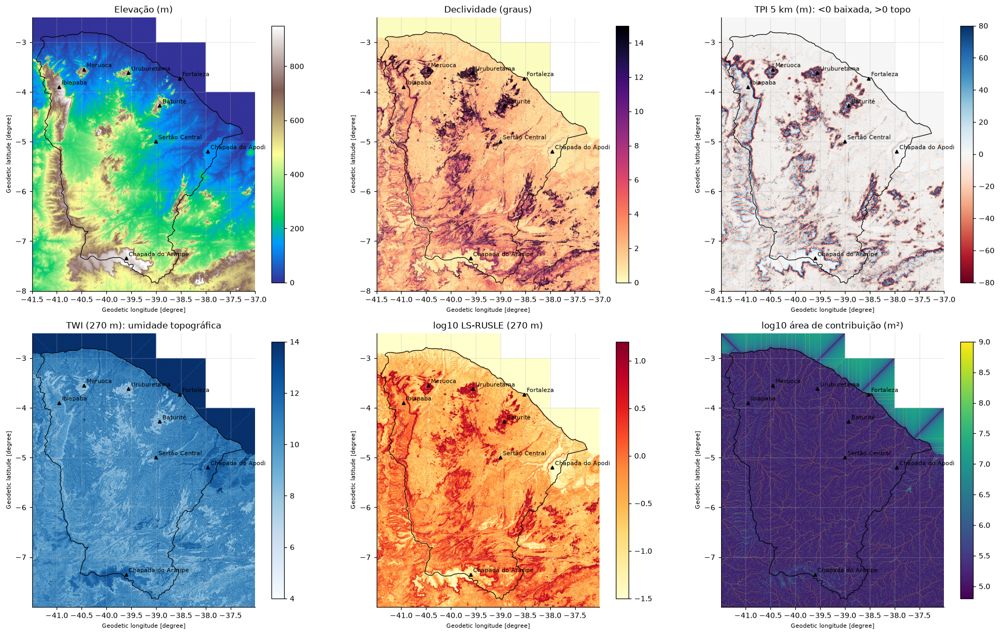

In [108]:
h270 = xr.open_dataset(D / "ceara_270m_hidrologia.nc")
ext270 = [float(h270.lon.min()), float(h270.lon.max()), float(h270.lat.min()), float(h270.lat.max())]
locais = {"Ibiapaba": (-40.95, -3.9), "Meruoca": (-40.45, -3.55), "Uruburetama": (-39.55, -3.62), "Baturité": (-38.92, -4.28),
          "Chapada do Araripe": (-39.6, -7.35), "Chapada do Apodi": (-37.95, -5.2), "Fortaleza": (-38.52, -3.73), "Sertão Central": (-39.0, -5.0)}
fig, axs = plt.subplots(2, 3, figsize=(18, 11))
paineis = [(z90, ext90, "terrain", (0, 950), "Elevação (m)"), (s90, ext90, "magma_r", (0, 15), "Declividade (graus)"),
           (tpi5, ext90, "RdBu", (-80, 80), "TPI 5 km (m): <0 baixada, >0 topo"),
           (h270.twi.values, ext270, "Blues", (4, 14), "TWI (270 m): umidade topográfica"),
           (np.log10(h270.ls_rusle.values + 1e-3), ext270, "YlOrRd", (-1.5, 1.2), "log10 LS-RUSLE (270 m)"),
           (np.log10(h270.area_contribuicao_m2.values), ext270, "viridis", (4.8, 9), "log10 área de contribuição (m²)")]
for ax, (img, ext, cm, lim, tit) in zip(axs.ravel(), paineis):
    im = ax.imshow(img, extent=ext, cmap=cm, vmin=lim[0], vmax=lim[1]); ce.boundary.plot(ax=ax, color="k", lw=0.8)
    plt.colorbar(im, ax=ax, fraction=0.04); ax.set_title(tit)
    for nome, (x, y) in locais.items():
        ax.plot(x, y, "k^", ms=4); ax.annotate(nome, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.tight_layout(); plt.show()

## 10.5–10.7 Sazonalidade, tendência e extremos
O DEM é uma **medição única (fev/2000)**, então não existe sazonalidade nem tendência temporal para estimar.
No lugar disso, analisamos os **extremos espaciais** e os gradientes que importam para a lavoura:
- a declividade, ligada ao risco de erosão e à mecanização;
- as baixadas, que acumulam água e ar frio;
- os municípios mais e menos acidentados.

In [109]:
mun = pd.read_parquet(D / "srtm_municipios_ce.parquet")
cols = ["municipio", "elev_media", "elev_max", "amplitude", "decl_media_graus", "frac_ondulado_8a20", "frac_forte_20a45"]
print("10 municípios mais acidentados (declividade média):")
print(mun.sort_values("decl_media_graus", ascending=False)[cols].head(10).round(3).to_string(index=False))
print("\n10 municípios mais planos:")
print(mun.sort_values("decl_media_graus")[cols].head(10).round(3).to_string(index=False))
ls = h270.ls_rusle.values; twi = h270.twi.values; sl270 = h270.declividade.values
ok = np.isfinite(ls)
print(f"\nÁrea com LS > 3 (potencial de erosão alto em lavoura sem cobertura): {(ls[ok] > 3).mean()*100:.1f}% da grade")
tw = twi[np.isfinite(twi)]
print(f"TWI a 270 m: p10={np.percentile(tw,10):.1f} p50={np.percentile(tw,50):.1f} p90={np.percentile(tw,90):.1f} "
      f"(o TWI depende da resolução: a 270 m a área específica mínima já é ~270 m, então só faz sentido comparar dentro da mesma grade;"
      f" nas AOIs a 30 m a mediana é ~7–8). Baixadas úmidas = decil superior (TWI ≥ {np.percentile(tw,90):.1f}).")
baixada = (tpi5 < -30) & (s90 < 2) & mask_ce
print(f"Baixadas planas encaixadas (TPI5km < −30 m e declive < 2°), candidatas a acumular ar frio à noite: {baixada.sum()/mask_ce.sum()*100:.2f}% do Ceará")

10 municípios mais acidentados (declividade média):
   municipio  elev_media  elev_max  amplitude  decl_media_graus  frac_ondulado_8a20  frac_forte_20a45
 Uruburetama     350.537  1056.222    965.111            14.904               0.145             0.391
     Mulungu     708.126   996.111    699.556            14.635               0.281             0.562
     Meruoca     699.465   994.889    888.444            14.514               0.294             0.488
      Pacoti     612.491  1024.556    743.667            13.661               0.318             0.505
Guaramiranga     797.062  1098.222    796.444            13.303               0.374             0.406
  Alcântaras     677.233  1011.222    789.667            13.275               0.315             0.453
     Aratuba     594.821  1024.111    838.333            12.955               0.318             0.407
     Itapajé     334.966  1065.667   1000.667            11.643               0.204             0.343
    Redenção     285.354   808

Baixadas planas encaixadas (TPI5km < −30 m e declive < 2°), candidatas a acumular ar frio à noite: 2.06% do Ceará


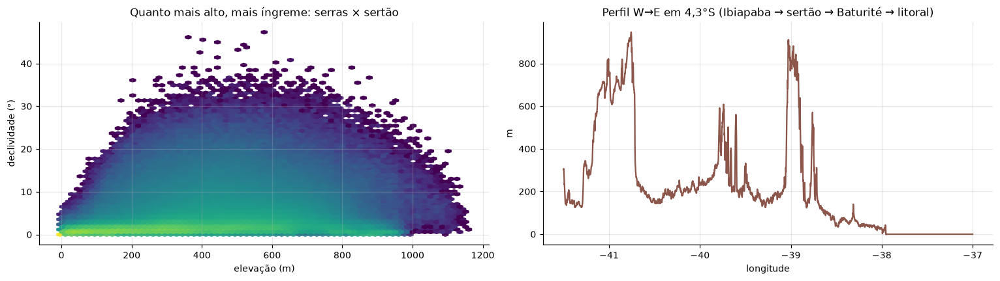

In [110]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
v = ok & np.isfinite(sl270)
axs[0].hexbin(h270.elev.values[v], sl270[v], gridsize=70, bins="log", cmap="viridis"); axs[0].set_xlabel("elevação (m)"); axs[0].set_ylabel("declividade (°)")
axs[0].set_title("Quanto mais alto, mais íngreme: serras × sertão")
lat_idx = np.argmin(np.abs(np.arange(z90.shape[0]) * t90.e + t90.f - (-4.3)))
lons = t90.c + t90.a * (np.arange(z90.shape[1]) + 0.5)
axs[1].plot(lons, z90[lat_idx], color="tab:brown"); axs[1].set_title("Perfil W→E em 4,3°S (Ibiapaba → sertão → Baturité → litoral)")
axs[1].set_xlabel("longitude"); axs[1].set_ylabel("m"); plt.tight_layout(); plt.show()

## 10.8 Nordeste a ~1 km

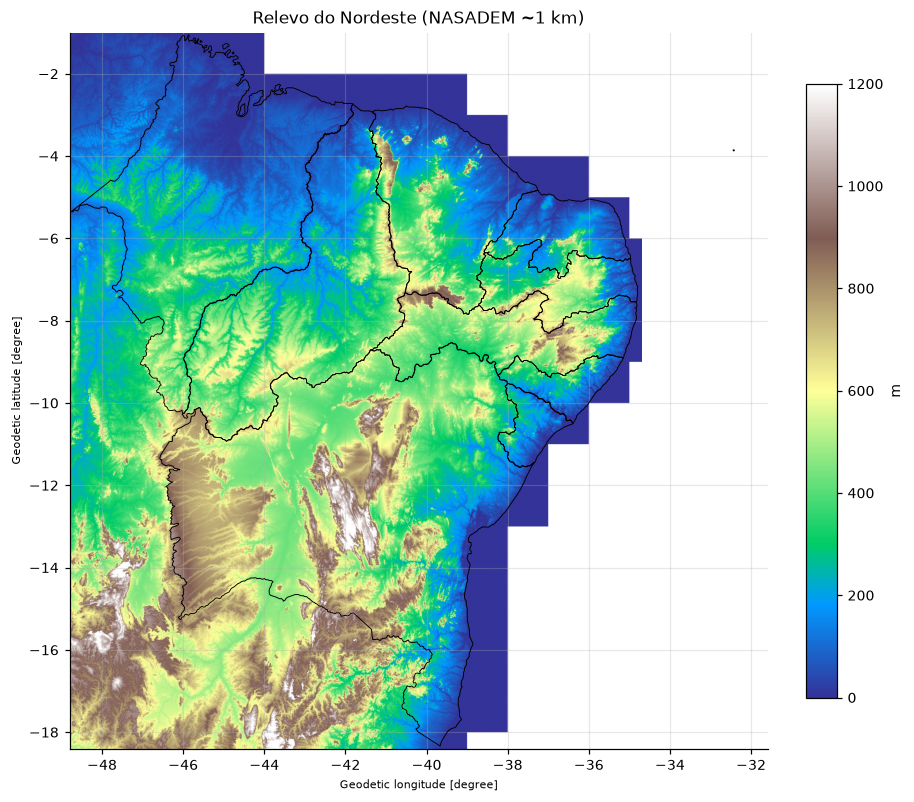

,UF,elev_media,elev_p95,decl_media_graus_1km,% > 500 m
7,SE,158.899994,316.0,1.0,0.4
3,RN,168.699997,472.0,1.0,4.1
0,MA,189.800003,468.0,0.9,3.0
6,AL,209.199997,463.0,1.3,3.1
2,CE,290.600006,716.0,1.3,17.0
1,PI,349.700012,613.0,1.1,18.3
4,PB,389.399994,677.0,1.3,33.8
5,PE,477.299988,804.0,1.3,41.7
8,BA,525.599976,940.0,1.4,48.2


In [111]:
zne, tne, extne = ler_tif("nasadem_nordeste_1km.tif"); sne, _, _ = ler_tif("declividade_nordeste_1km.tif")
ne = nordeste_gdf()
lab = rasterize([(gg, i + 1) for i, gg in enumerate(ne.geometry)], out_shape=zne.shape, transform=tne, fill=0, dtype="int32")
UF = {"21": "MA", "22": "PI", "23": "CE", "24": "RN", "25": "PB", "26": "PE", "27": "AL", "28": "SE", "29": "BA"}
lin = []
for i, cod in enumerate(ne.codarea.astype(str)):
    m = (lab == i + 1) & np.isfinite(zne)
    lin.append({"UF": UF.get(cod, cod), "elev_media": zne[m].mean(), "elev_p95": np.percentile(zne[m], 95), "decl_media_graus_1km": sne[m].mean(),
                "% > 500 m": (zne[m] > 500).mean() * 100})
fig, ax = plt.subplots(figsize=(9, 9))
im = ax.imshow(zne, extent=extne, cmap="terrain", vmin=0, vmax=1200); ne.boundary.plot(ax=ax, color="k", lw=0.6)
plt.colorbar(im, ax=ax, fraction=0.04, label="m"); ax.set_title("Relevo do Nordeste (NASADEM ~1 km)"); plt.show()
pd.DataFrame(lin).round(1).sort_values("elev_media")

## 10.9 AOIs a 30 m

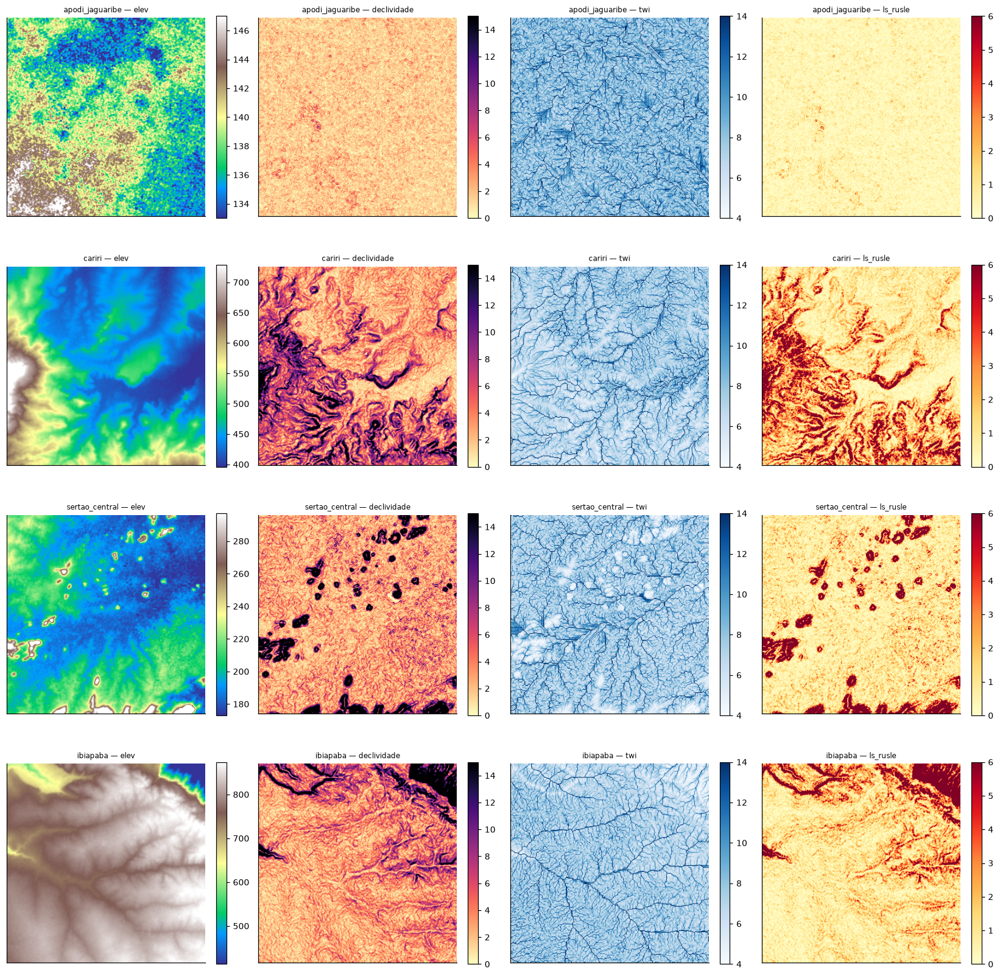

aoi,apodi_jaguaribe,cariri,sertao_central,ibiapaba
elev_media,138.569,483.887,201.074,785.815
elev_p10,135.000,416.000,181.000,738.000
elev_p50,138.000,460.000,197.000,796.000
elev_p90,143.000,586.000,220.000,849.000
declividade_media,1.651,5.457,4.644,4.823
declividade_p10,0.930,1.320,0.933,1.316
declividade_p50,1.317,4.169,2.946,3.354
declividade_p90,2.940,11.099,8.361,8.702
twi_media,8.676,7.595,7.740,7.702
twi_p10,6.738,5.749,5.862,5.935


In [112]:
aoi_tab = pd.read_parquet(D / "srtm_aoi_estatico.parquet").set_index("aoi")
fig, axs = plt.subplots(4, 4, figsize=(15, 15))
for i, n in enumerate(AOIS):
    ds = xr.open_dataset(D / f"srtm_aoi_{n}.nc")
    ext = [float(ds.lon.min()), float(ds.lon.max()), float(ds.lat.min()), float(ds.lat.max())]
    for j, (v, cm, lim) in enumerate([("elev", "terrain", None), ("declividade", "magma_r", (0, 15)), ("twi", "Blues", (4, 14)), ("ls_rusle", "YlOrRd", (0, 6))]):
        arr = ds[v].values
        lo, hi = lim if lim else (np.nanpercentile(arr, 1), np.nanpercentile(arr, 99))
        im = axs[i, j].imshow(arr, extent=ext, cmap=cm, vmin=lo, vmax=hi); plt.colorbar(im, ax=axs[i, j], fraction=0.046)
        axs[i, j].set_title(f"{n} — {v}", fontsize=8); axs[i, j].set_xticks([]); axs[i, j].set_yticks([])
plt.tight_layout(); plt.show()
aoi_tab.round(3).T

## 10.10 Insights e ideias para o produto
1. **O relevo do Ceará é dominado pelo sertão baixo e plano.** A maior parte da área fica abaixo de 400 m e nas
   classes plano/suave ondulado (≤ 8%), ótimo para mecanização. Ilhas de relevo concentram declividade, umidade
   e nuvem: Ibiapaba, Araripe, Baturité, Meruoca e Uruburetama.
2. **Erosão é questão de lugar.** O LS alto se concentra nas encostas das serras e nos vales encaixados. Nesses
   talhões, rotações com cobertura permanente (palhada, perenes, consórcios) rendem mais do que no sertão plano.
   O produto pode priorizar "cobertura do solo" pelo LS do talhão.
3. **O TWI acha as baixadas úmidas.** Várzeas e fundos de vale (TWI alto) acumulam água e são onde culturas mais
   exigentes, como milho e arroz de várzea, têm chance na seca. Nas áreas de TWI baixo, a escolha vai para culturas
   tolerantes: sorgo, feijão-caupi, palma.
4. **Microclima.** Baixadas encaixadas (TPI negativo e plano) acumulam ar frio à noite. No Ceará isso quase não
   gera geada, mas a camada é crucial no produto global (Sul do Brasil, Argentina, EUA). Junto com a altitude, ela
   ajusta a temperatura do POWER/ERA5 (~−6,5 °C/km) para o talhão.
5. **A cobertura é quase global.** O NASADEM cobre 56°S–60°N; para fechar os polos, entra o Copernicus DEM. A camada
   é estática, então basta baixar uma vez por região: é barata e pode ser pré-calculada no servidor.

**Ideias de modelo:**
- Usar o relevo (declividade, TWI, TPI, aspecto) como **features estáticas** em todos os modelos de estresse e
  produtividade.
- **RUSLE completa:**
  - R a partir da intensidade de chuva do IMERG;
  - K a partir do solo (SoilGrids/GAEZ);
  - LS a partir daqui;
  - C a partir do NDVI do Landsat/S2;
  - e assim estimar a **perda de solo em t/ha/ano para cada rotação proposta**, comparando cobertura e manejo.
- **Downscaling** de temperatura e chuva com o relevo (regressão ou CNN do tipo super-resolução).

# 11 · FAO GAEZ v4 — aptidão agrícola, clima agrícola e solo (global)

**Pergunta do produto:** quais culturas *cabem* em cada lugar do mundo, em sequeiro ou irrigado, e com que produtividade possível?

O GAEZ (Global Agro-Ecological Zones, FAO/IIASA) cruza clima (CRU-TS 1981–2010), solo (HWSD), relevo e exigências
fisiológicas de dezenas de culturas. Ele vira o **filtro de culturas candidatas** do motor de rotação:
antes de comparar rotações, descartamos o que o clima e o solo do pixel não sustentam.

Camadas baixadas (306 GeoTIFFs globais, grade de 5′ ≈ 9,3 km no equador):
aptidão e produtividade atingível de 17 culturas (res05), potencial de forrageiras (res02), recursos agroclimáticos
1981–2010 (res01) e séries anuais 1960–2010 (período de crescimento e chuva), solos/relevo/cobertura (LR),
produção real 2010 (res06) e razão de produtividade alcançada (res07).

In [113]:
import sys, json, warnings
sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
from comum import *  # noqa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import rasterio
from rasterio.windows import from_bounds
from rasterio.features import geometry_mask, rasterize
from scipy import stats
import pymannkendall as mk

try:
    sys.stdout.reconfigure(encoding="utf-8")
except Exception:
    pass
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 90})

G = pasta("gaez")
sel = pd.read_csv(G / "selecao.csv")
LEG = json.loads((G / "legendas_gaez.json").read_text(encoding="utf-8"))
ce = ceara_gdf()
ne = nordeste_gdf()
mun = municipios_ce_gdf()


PIX = 1 / 12  # grade de 5 arc-min


def _snap(bbox):
    return (np.floor(bbox[0] / PIX) * PIX, np.floor(bbox[1] / PIX) * PIX,
            np.ceil(bbox[2] / PIX) * PIX, np.ceil(bbox[3] / PIX) * PIX)


def ler(arquivo, bbox=None):
    """Lê camada (opcionalmente recortada por bbox alinhado à grade de 5') -> (array float com NaN, transform).
    Camadas a 30" são agregadas por média de blocos 10×10 para a grade de 5'."""
    with rasterio.open(G / arquivo) as ds:
        fator = int(round(PIX / ds.res[0]))
        if bbox is not None:
            w = from_bounds(*_snap(bbox), transform=ds.transform).round_offsets().round_lengths()
            a = ds.read(1, window=w).astype("float32")
            tr = ds.window_transform(w)
        else:
            a = ds.read(1).astype("float32")
            tr = ds.transform
        nd = ds.nodata
    if nd is not None and not np.isnan(nd):
        a[a == nd] = np.nan
    if fator > 1:
        h, wd = a.shape[0] // fator, a.shape[1] // fator
        a = np.nanmean(a[:h * fator, :wd * fator].reshape(h, fator, wd, fator), axis=(1, 3))
        tr = rasterio.Affine(tr.a * fator, tr.b, tr.c, tr.d, tr.e * fator, tr.f)
    return a, tr


def arq(**filtro):
    m = sel.copy()
    for k, v in filtro.items():
        m = m[m[k] == v]
    if len(m) == 0:
        raise KeyError(filtro)
    return m.iloc[0]["arquivo"]


def mascara(geoms, shape, tr):
    return geometry_mask(list(geoms), out_shape=shape, transform=tr, invert=True)


def extent(tr, shape):
    return (tr.c, tr.c + tr.a * shape[1], tr.f + tr.e * shape[0], tr.f)


# grades de referência (Ceará e Nordeste)
_a, TR_CE = ler(arq(servico="res05", cultura="Maize", codigo="si_seq_alto"), BBOX_CE)
SH_CE = _a.shape
M_CE = mascara(ce.geometry, SH_CE, TR_CE)
_a, TR_NE = ler(arq(servico="res05", cultura="Maize", codigo="si_seq_alto"), BBOX_NE)
SH_NE = _a.shape
M_NE = mascara(ne[ne.geometry.bounds.minx > -34.0].geometry if False else ne.geometry, SH_NE, TR_NE)
print("Grade Ceará:", SH_CE, "pixels no estado:", int(M_CE.sum()), "| Grade NE:", SH_NE, "pixels na região:", int(M_NE.sum()))

Grade Ceará: (66, 54) pixels no estado: 1753 | Grade NE: (209, 170) pixels na região: 18397


## 1. Ficha técnica

In [114]:
cat = pd.read_csv(G / "catalogo_gaez_completo.csv", usecols=["servico", "sub_theme_name", "year", "model"], low_memory=False)
resumo_cat = cat.groupby("servico").agg(camadas=("servico", "size"), subtemas=("sub_theme_name", "nunique"),
                                         periodos=("year", "nunique"))
print("Catálogo GAEZ v4 consultado (todas as camadas publicadas):")
print(resumo_cat.to_string())
print("\nCamadas baixadas por grupo:")
print(sel.groupby(["servico", "grupo"]).size().to_string())
with rasterio.open(G / sel.iloc[0]["arquivo"]) as ds:
    print(f"\nGrade: {ds.width}×{ds.height} px, pixel {ds.res[0]:.5f}° (~{ds.res[0]*111.32:.1f} km no equador), CRS {ds.crs}, "
          f"limites {tuple(round(b, 2) for b in ds.bounds)}")
print(f"Tamanho em disco: {tamanho_pasta(G)/1e9:.2f} GB (inclui catálogo de {(G/'catalogo_gaez_completo.csv').stat().st_size/1e6:.0f} MB)")

Catálogo GAEZ v4 consultado (todas as camadas publicadas):
         camadas  subtemas  periodos
servico                             
LR           134         8         5
res01     111606         4       147
res02     111672         4         6
res05     122708         4         6
res06        498         2         2
res07        288         3         2

Camadas baixadas por grupo:
servico      grupo               
LR           terra_solo               22
res01        agroclima                20
res01_anual  lgp_anual                51
             prec_anual               51
res02        forrageira_potencial      3
res05        aptidao                 118
res06        producao_real_2010       28
res07        lacuna_2010              13

Grade: 4320×2160 px, pixel 0.08333° (~9.3 km no equador), CRS EPSG:4326, limites (-180.0, -90.0, 180.0, 90.0)
Tamanho em disco: 2.45 GB (inclui catálogo de 209 MB)


| Item | Valor |
|---|---|
| Provedor | FAO + IIASA (GAEZ v4, 2021) |
| Clima de referência | CRU-TS 3.2, 1981–2010 (também 1960–2010 ano a ano e cenários CMIP5 até 2100 no catálogo) |
| Solo | HWSD v1.2; relevo GMTED; cobertura do solo ~2010 |
| Resolução | 5 arc-min (~9,3 km no equador); algumas camadas a 30″ |
| Escala do índice de aptidão (SI) | 0–10000 (= SI×100). Classes: >7500 muito alta, >6300 alta, >5000 boa, >3500 média, >2000 moderada, >1000 marginal, >0 muito marginal, 0 inapto |
| Acesso | ArcGIS ImageServer (catálogo) + GeoTIFF no S3 da FAO, aberto, sem cadastro |
| Licença | CC BY 4.0 (FAO) |

## 2. Validação de cobertura global

Evidência: rasterizamos a máscara de terra do Natural Earth (1:50 m) na grade do GAEZ e medimos
quantos pixels de terra têm valor válido (≥ 0) no índice de aptidão do milho e na fração de lavoura (LR).

Pixels de terra (Natural Earth): 2,213,255
  com SI do milho válido: 99.8%
  com fração de lavoura válida: 100.0%
Pixels de oceano com valor (deveria ser ~0): 0.96%
Latitudes com dado válido: -56.0° a 83.6°
Pixels de terra com SI > 0 (alguma aptidão para milho): 35.4%
Terra sem SI: 3,828 px; desses, 9% acima de 60°N (gelo/permafrost/água interior)
Países com mais pixels de terra sem SI: {'United States of America': 2178, 'Canada': 1132, 'fora de país': 171, 'Greenland': 137, 'Fr. S. Antarctic Lands': 118, 'Russia': 55, 'Netherlands': 17, 'Indonesia': 5}


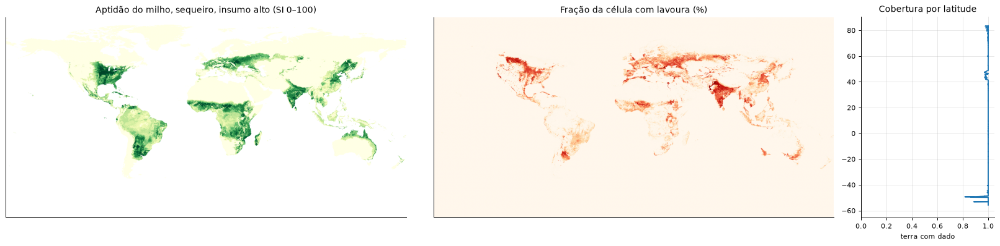

In [115]:
si_g, tr_g = ler(arq(servico="res05", cultura="Maize", codigo="si_seq_alto"))
lav_g, _ = ler(arq(servico="LR", codigo="Cropland"))
terra = terra_gdf()
m_terra = rasterize(((g, 1) for g in terra.geometry), out_shape=si_g.shape, transform=tr_g, fill=0, dtype="uint8").astype(bool)
lat = tr_g.f + tr_g.e * (np.arange(si_g.shape[0]) + 0.5)
m_terra &= (lat > -60)[:, None]  # sem Antártida

val_si = ~np.isnan(si_g)
val_lav = ~np.isnan(lav_g)
print(f"Pixels de terra (Natural Earth): {m_terra.sum():,}")
print(f"  com SI do milho válido: {(val_si & m_terra).sum()/m_terra.sum():.1%}")
print(f"  com fração de lavoura válida: {(val_lav & m_terra).sum()/m_terra.sum():.1%}")
print(f"Pixels de oceano com valor (deveria ser ~0): {(val_si & ~m_terra).sum()/(~m_terra).sum():.2%}")
print(f"Latitudes com dado válido: {lat[val_si.any(axis=1)].min():.1f}° a {lat[val_si.any(axis=1)].max():.1f}°")
print(f"Pixels de terra com SI > 0 (alguma aptidão para milho): {((si_g > 0) & m_terra).sum()/m_terra.sum():.1%}")
# onde está a terra sem SI? (por faixa de latitude e por país)
sem = m_terra & ~val_si
print(f"Terra sem SI: {sem.sum():,} px; desses, {100*sem[lat > 60].sum()/max(sem.sum(),1):.0f}% acima de 60°N "
      f"(gelo/permafrost/água interior)")
paises_g = paises_gdf()
r_pais = rasterize(((g, i + 1) for i, g in enumerate(paises_g.geometry)), out_shape=si_g.shape, transform=tr_g, fill=0, dtype="int32")
cont = pd.Series(r_pais[sem]).value_counts().head(8)
print("Países com mais pixels de terra sem SI:", {paises_g.iloc[i - 1]["NAME"] if i > 0 else "fora de país": int(n) for i, n in cont.items()})

frac_lat = pd.DataFrame({"lat": lat, "terra": m_terra.sum(1), "valido": (val_si & m_terra).sum(1)})
frac_lat["cobertura"] = frac_lat["valido"] / frac_lat["terra"].replace(0, np.nan)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5), gridspec_kw={"width_ratios": [3, 3, 1]})
si_plot = np.where(m_terra, si_g, np.nan)[::3, ::3]
ax[0].imshow(si_plot / 100, extent=extent(tr_g, si_g.shape), cmap="YlGn", vmin=0, vmax=100)
ax[0].set_title("Aptidão do milho, sequeiro, insumo alto (SI 0–100)")
ax[1].imshow(lav_g[::3, ::3], extent=extent(tr_g, lav_g.shape), cmap="OrRd", vmin=0, vmax=100)
ax[1].set_title("Fração da célula com lavoura (%)")
ax[2].plot(frac_lat["cobertura"], frac_lat["lat"])
ax[2].set_xlim(0, 1.05); ax[2].set_title("Cobertura por latitude"); ax[2].set_xlabel("terra com dado")
for a in ax[:2]:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**Veredito: GAEZ é GLOBAL de fato.** Todo pixel de terra fora da Antártida tem valor; o oceano fica sem dado.
A limitação é a **resolução (~9 km)**: serve para dizer "que culturas cabem na região do talhão", não para o talhão em si.
O refinamento intra-talhão vem de Landsat/Sentinel-2/SRTM (outras seções).

## 3. Qualidade

Faixa de valores, fração de "sem dado" e consistência interna no Nordeste (aptidão zero ⇒ produtividade atingível zero).

In [116]:
linhas = []
for _, r in sel[sel["servico"].isin(["res05", "res02"])].iterrows():
    a, _ = ler(r["arquivo"], BBOX_NE)
    v = a[M_NE]
    linhas.append({"cultura": r["cultura"], "codigo": r["codigo"], "unidade": r["unidade"],
                   "% sem dado NE": round(100 * np.isnan(v).mean(), 2), "min": np.nanmin(v), "max": np.nanmax(v),
                   "média NE": round(float(np.nanmean(v)), 1)})
q = pd.DataFrame(linhas)
print(q.pivot_table(index="cultura", columns="codigo", values="% sem dado NE").round(2).to_string())

inconsist = []
for crop in sel.loc[sel["servico"] == "res05", "cultura"].unique():
    si, _ = ler(arq(servico="res05", cultura=crop, codigo="si_seq_alto"), BBOX_NE)
    y, _ = ler(arq(servico="res05", cultura=crop, codigo="yld_seq_alto"), BBOX_NE)
    ok = M_NE & ~np.isnan(si) & ~np.isnan(y)
    inconsist.append({"cultura": crop, "SI=0 e produtividade>0 (%)": round(100 * ((si == 0) & (y > 0) & ok).sum() / ok.sum(), 2),
                      "SI>0 e produtividade=0 (%)": round(100 * ((si > 0) & (y == 0) & ok).sum() / ok.sum(), 2)})
print("\nConsistência SI × produtividade atingível (sequeiro, insumo alto, Nordeste):")
print(pd.DataFrame(inconsist).to_string(index=False))

codigo           pot_seq_alto  si_lav_irr_alto  si_lav_seq_alto  si_seq_alto  si_seq_baixo  yld_lav_irr_alto  yld_lav_seq_alto  yld_seq_alto  yld_seq_baixo
cultura                                                                                                                                                    
Alfalfa                  0.01              NaN              NaN          NaN           NaN               NaN               NaN           NaN            NaN
Banana                    NaN             0.01             0.01         0.01          0.01              0.01              0.01          0.01           0.01
Cassava                   NaN              NaN             0.01         0.01          0.01               NaN              0.01          0.01           0.01
Cotton                    NaN             0.01             0.01         0.01          0.01              0.01              0.01          0.01           0.01
Cowpea                    NaN             0.01             0.01 

## 4. Ceará e Nordeste — ranking de culturas aptas

Para cada cultura: SI médio, % da área com aptidão **boa ou melhor** (SI > 5000), e produtividade atingível média
onde a cultura é ao menos moderadamente apta (SI > 2000).

In [117]:
CLASSES = [(7500, "muito alta"), (6300, "alta"), (5000, "boa"), (3500, "média"), (2000, "moderada"),
           (1000, "marginal"), (0, "muito marginal")]


def classe_si(v):
    out = np.full(v.shape, "inapta", dtype=object)
    for lim, nome in reversed(CLASSES):
        out[v > lim] = nome
    return out


crops = sel.loc[sel["servico"] == "res05", ["cultura", "cultura_pt"]].drop_duplicates().set_index("cultura")["cultura_pt"]
linhas, classes_ce = [], {}
for crop, pt in crops.items():
    for regiao, bbox, M in [("Ceará", BBOX_CE, M_CE), ("Nordeste", BBOX_NE, M_NE)]:
        for nivel, cod_si, cod_y in [("alto", "si_seq_alto", "yld_seq_alto"), ("baixo", "si_seq_baixo", "yld_seq_baixo")]:
            si, _ = ler(arq(servico="res05", cultura=crop, codigo=cod_si), bbox)
            y, _ = ler(arq(servico="res05", cultura=crop, codigo=cod_y), bbox)
            v, yv = si[M], y[M]
            apto = v > 2000
            linhas.append({"cultura": pt, "região": regiao, "insumo": nivel, "SI médio": np.nanmean(v) / 100,
                           "% área SI>50 (boa+)": 100 * np.nanmean(v > 5000), "% área SI>20": 100 * np.nanmean(apto),
                           "produtiv. atingível (kg/ha) onde SI>20": np.nanmean(yv[apto]) if apto.any() else np.nan})
            if regiao == "Ceará" and nivel == "alto":
                classes_ce[pt] = pd.Series(classe_si(v[~np.isnan(v)])).value_counts(normalize=True) * 100
rank = pd.DataFrame(linhas)
r_ce = rank[(rank["região"] == "Ceará") & (rank["insumo"] == "alto")].sort_values("SI médio", ascending=False)
print("Ranking no CEARÁ — sequeiro, insumo alto:")
print(r_ce.drop(columns=["região", "insumo"]).round(1).to_string(index=False))
print("\nRanking no CEARÁ — sequeiro, insumo baixo (agricultura familiar):")
print(rank[(rank["região"] == "Ceará") & (rank["insumo"] == "baixo")].sort_values("SI médio", ascending=False)
      .drop(columns=["região", "insumo"]).round(1).to_string(index=False))
print("\nRanking no NORDESTE — sequeiro, insumo baixo (agricultura familiar):")
print(rank[(rank["região"] == "Nordeste") & (rank["insumo"] == "baixo")].sort_values("SI médio", ascending=False)
      .drop(columns=["região", "insumo"]).round(1).to_string(index=False))
DERIV.mkdir(exist_ok=True, parents=True)
rank.to_parquet(DERIV / "gaez_ranking_culturas_ce_ne.parquet", index=False)

Ranking no CEARÁ — sequeiro, insumo alto:
           cultura  SI médio  % área SI>50 (boa+)  % área SI>20  produtiv. atingível (kg/ha) onde SI>20
           algodão 70.900002                 89.0          99.9                                   915.3
             sorgo 62.599998                 81.8          99.8                                  5898.5
             milho 60.000000                 77.5          99.8                                  7425.9
            guandu 59.900002                 78.8          99.9                                  2522.0
           milheto 59.299999                 73.9          99.5                                  2645.4
              soja 58.299999                 76.8          99.9                                  3266.4
      feijão-caupi 58.299999                 75.6          99.7                                  1973.9
feijão (Phaseolus) 57.700001                 74.8          99.7                                  2632.8
          amendoim 49.

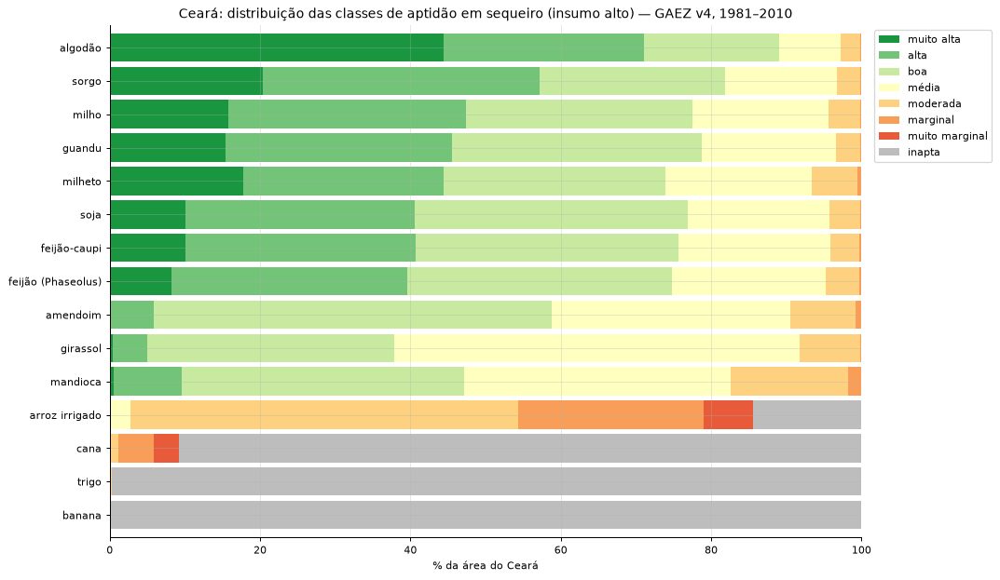

In [118]:
ordem = ["muito alta", "alta", "boa", "média", "moderada", "marginal", "muito marginal", "inapta"]
cores = ["#1a9641", "#73c378", "#c7e9a0", "#ffffbf", "#fdd17f", "#f99e59", "#e85b3a", "#bdbdbd"]
dfc = pd.DataFrame(classes_ce).T.reindex(columns=ordem).fillna(0).loc[r_ce["cultura"]]
ax = dfc.plot.barh(stacked=True, color=cores, figsize=(12, 7), width=0.85)
ax.invert_yaxis(); ax.set_xlabel("% da área do Ceará")
ax.set_title("Ceará: distribuição das classes de aptidão em sequeiro (insumo alto) — GAEZ v4, 1981–2010")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

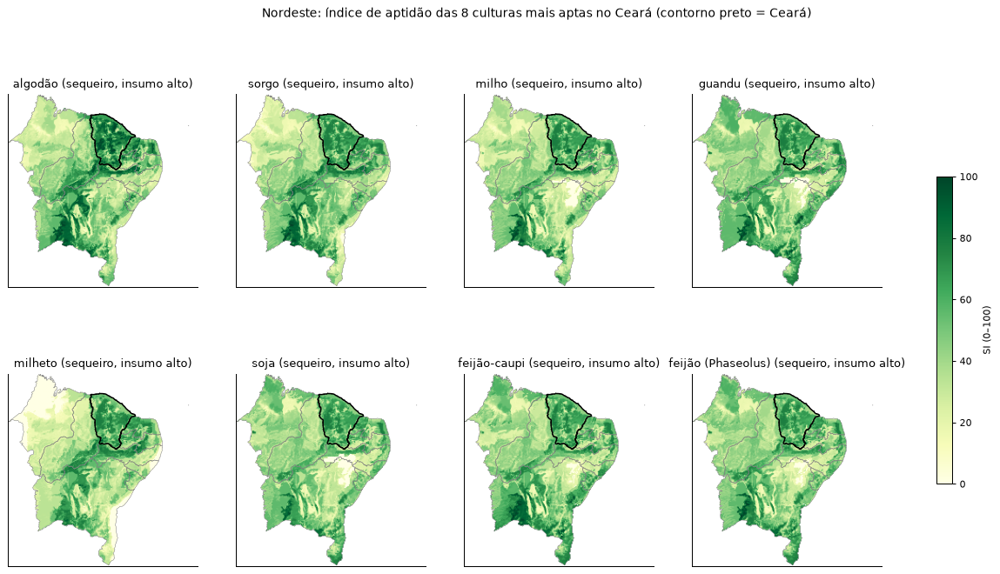

In [119]:
top = r_ce["cultura"].head(8).tolist()
inv = {v: k for k, v in crops.items()}
fig, axs = plt.subplots(2, 4, figsize=(18, 8.5))
for ax, pt in zip(axs.ravel(), top):
    si, tr = ler(arq(servico="res05", cultura=inv[pt], codigo="si_seq_alto"), BBOX_NE)
    im = ax.imshow(np.where(M_NE, si / 100, np.nan), extent=extent(tr, si.shape), cmap="YlGn", vmin=0, vmax=100)
    ne.boundary.plot(ax=ax, color="grey", lw=0.4)
    ce.boundary.plot(ax=ax, color="k", lw=1.2)
    ax.set_title(f"{pt} (sequeiro, insumo alto)", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
fig.colorbar(im, ax=axs, shrink=0.6, label="SI (0–100)")
fig.suptitle("Nordeste: índice de aptidão das 8 culturas mais aptas no Ceará (contorno preto = Ceará)")
plt.show()

### Por mesorregião do Ceará (matriz cultura × região)

pixels por mesorregião: {'Centro-Sul Cearense': 116, 'Jaguaribe': 219, 'Metropolitana de Fortaleza': 44, 'Noroeste Cearense': 402, 'Norte Cearense': 250, 'Sertões Cearenses': 544, 'Sul Cearense': 178}


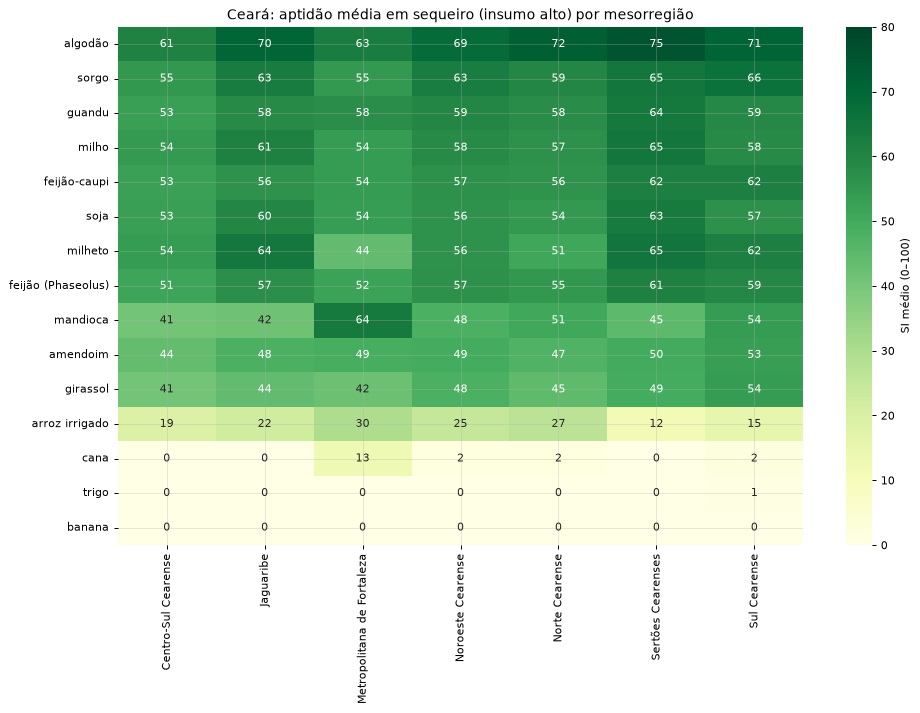

Melhor cultura por mesorregião: {'Centro-Sul Cearense': 'algodão', 'Jaguaribe': 'algodão', 'Metropolitana de Fortaleza': 'mandioca', 'Noroeste Cearense': 'algodão', 'Norte Cearense': 'algodão', 'Sertões Cearenses': 'algodão', 'Sul Cearense': 'algodão'}


In [120]:
nomes = pd.DataFrame(json.loads((REF / "ceara_municipios_nomes.json").read_text(encoding="utf-8")))
nomes["meso"] = nomes["microrregiao"].apply(lambda m: m["mesorregiao"]["nome"])
mun["id"] = mun["codarea"].astype(int)
mm = mun.merge(nomes[["id", "nome", "meso"]], on="id")
mm["geometry"] = mm.geometry.make_valid().buffer(0)
meso = mm.dissolve(by="meso").reset_index()
meso["cod"] = np.arange(1, len(meso) + 1)
R_MESO = rasterize(((g, c) for g, c in zip(meso.geometry, meso["cod"])), out_shape=SH_CE, transform=TR_CE, fill=0, dtype="uint8")
print("pixels por mesorregião:", dict(zip(meso["meso"], [int((R_MESO == c).sum()) for c in meso["cod"]])))

mat = {}
for crop, pt in crops.items():
    si, _ = ler(arq(servico="res05", cultura=crop, codigo="si_seq_alto"), BBOX_CE)
    mat[pt] = {n: np.nanmean(si[R_MESO == c]) / 100 for n, c in zip(meso["meso"], meso["cod"])}
mat = pd.DataFrame(mat).T
mat = mat.loc[mat.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(mat, annot=True, fmt=".0f", cmap="YlGn", vmin=0, vmax=80, ax=ax, cbar_kws={"label": "SI médio (0–100)"})
ax.set_title("Ceará: aptidão média em sequeiro (insumo alto) por mesorregião")
plt.tight_layout(); plt.show()
mat.to_parquet(DERIV / "gaez_si_mesorregiao_ce.parquet")
print("Melhor cultura por mesorregião:", mat.idxmax().to_dict())

## 5. Sequeiro × irrigado (lavoura atual, insumo alto)

Mesma base de comparação: "lavoura atual na célula" com sequeiro × irrigação por gravidade.
Ganho = quanto a irrigação eleva o SI e a produtividade atingível no Ceará. A mandioca não tem cenário irrigado no GAEZ.

           cultura  células comparadas  SI sequeiro  SI irrigado  % área boa+ sequeiro  % área boa+ irrigado  produtiv. sequeiro (kg/ha)  produtiv. irrigado (kg/ha)  ganho SI (pontos)  fator produtiv.
            banana                1021     0.000000    68.300003                   0.0                  99.3                         0.0                 6515.799805          68.300003              NaN
              cana                1021     3.000000    52.700001                   0.0                  73.0                      2333.7                 7182.100098          49.700001              3.1
    arroz irrigado                1021    29.500000    65.800003                   9.1                  91.7                      2437.5                 7069.899902          36.299999              2.9
          amendoim                1021    62.900002    63.500000                  99.4                  99.3                      2010.4                 2409.199951           0.500000             

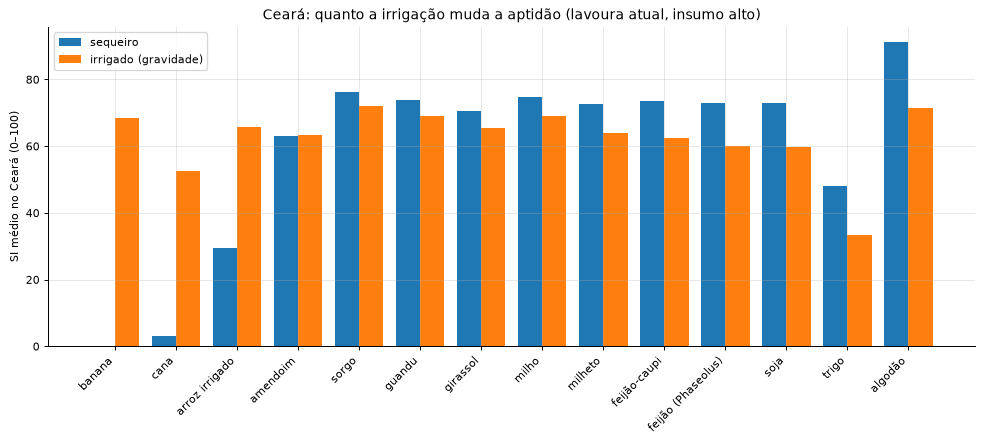

In [121]:
linhas = []
for crop, pt in crops.items():
    try:
        s_r, _ = ler(arq(servico="res05", cultura=crop, codigo="si_lav_seq_alto"), BBOX_CE)
        s_i, _ = ler(arq(servico="res05", cultura=crop, codigo="si_lav_irr_alto"), BBOX_CE)
        y_r, _ = ler(arq(servico="res05", cultura=crop, codigo="yld_lav_seq_alto"), BBOX_CE)
        y_i, _ = ler(arq(servico="res05", cultura=crop, codigo="yld_lav_irr_alto"), BBOX_CE)
    except KeyError:
        continue
    # o SI irrigado só existe nas células com lavoura equipada para irrigação (fora delas vale 0):
    # compara nas MESMAS células (s_i > 0) para não confundir "sem irrigação instalada" com "inapto"
    ok = M_CE & ~np.isnan(s_r) & ~np.isnan(s_i) & (s_i > 0)
    linhas.append({"cultura": pt, "células comparadas": int(ok.sum()), "SI sequeiro": np.nanmean(s_r[ok]) / 100, "SI irrigado": np.nanmean(s_i[ok]) / 100,
                   "% área boa+ sequeiro": 100 * np.mean(s_r[ok] > 5000), "% área boa+ irrigado": 100 * np.mean(s_i[ok] > 5000),
                   "produtiv. sequeiro (kg/ha)": np.nanmean(y_r[ok & (y_r > 0)]) if (ok & (y_r > 0)).any() else 0,
                   "produtiv. irrigado (kg/ha)": np.nanmean(y_i[ok & (y_i > 0)]) if (ok & (y_i > 0)).any() else 0})
irr = pd.DataFrame(linhas)
irr["ganho SI (pontos)"] = irr["SI irrigado"] - irr["SI sequeiro"]
irr["fator produtiv."] = irr["produtiv. irrigado (kg/ha)"] / irr["produtiv. sequeiro (kg/ha)"].replace(0, np.nan)
irr = irr.sort_values("ganho SI (pontos)", ascending=False)
print(irr.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(irr))
ax.bar(x - 0.2, irr["SI sequeiro"], 0.4, label="sequeiro")
ax.bar(x + 0.2, irr["SI irrigado"], 0.4, label="irrigado (gravidade)")
ax.set_xticks(x); ax.set_xticklabels(irr["cultura"], rotation=45, ha="right")
ax.set_ylabel("SI médio no Ceará (0–100)"); ax.legend()
ax.set_title("Ceará: quanto a irrigação muda a aptidão (lavoura atual, insumo alto)")
plt.tight_layout(); plt.show()

## 6. Clima agrícola (res01, 1981–2010)

Período de crescimento (LGP: dias em que chuva + reserva do solo ≥ metade da evapotranspiração), início do LGP,
dias de calor extremo, déficit hídrico, erosividade (índice de Fournier) e quantas safras por ano o clima permite.

In [122]:
def r01(trecho):
    m = sel[(sel["servico"] == "res01") & sel["variavel"].str.contains(trecho, regex=False)]
    return m.iloc[0]["arquivo"]


VARS = {
    "LGP total (dias)": "Total number of growing period days",
    "Início do LGP mais longo (dia do ano)": "Beginning date of longest component LGP",
    "LGP mais longo (dias)": "Length of longest component LGP",
    "Dias com Tmax > 35 °C": "Number of days with Tmax > 35",
    "Dias com Tmax > 40 °C": "Number of days with Tmax > 40",
    "Chuva anual (mm)": "Annual precipitation (mm)",
    "ETP de referência (mm)": "Reference potential evapotranspiration",
    "Déficit de ET (mm)": "Reference evapotranspiration deficit",
    "Dias de chuva (P > 1 mm)": "Total number of rain days",
    "Maior veranico no período de crescimento (dias)": "Longest period of consecutive dry days",
    "Temperatura média anual (°C)": "Mean annual temperature",
    "Graus-dia (Ta > 10 °C)": "Annual temperature sum for days with Ta>10",
}
linhas, campos = [], {}
for rot, trecho in VARS.items():
    a, tr = ler(r01(trecho), BBOX_NE)
    campos[rot] = (a, tr)
    for regiao, M in [("Ceará", None), ("Nordeste", M_NE)]:
        if regiao == "Ceará":
            b, _ = ler(r01(trecho), BBOX_CE)
            v = b[M_CE]
        else:
            v = a[M]
        if "dia do ano" in rot:  # variável circular: média circular e percentis não fazem sentido direto
            ang = 2 * np.pi * v[~np.isnan(v)] / 365
            media_c = (np.degrees(np.arctan2(np.sin(ang).mean(), np.cos(ang).mean())) % 360) / 360 * 365
            linhas.append({"variável": rot + " [média circular]", "região": regiao, "média": media_c, "p10": np.nan,
                           "mediana": np.nan, "p90": np.nan, "desvio": np.nan})
            continue
        linhas.append({"variável": rot, "região": regiao, "média": np.nanmean(v), "p10": np.nanpercentile(v, 10),
                       "mediana": np.nanmedian(v), "p90": np.nanpercentile(v, 90), "desvio": np.nanstd(v)})
agro = pd.DataFrame(linhas)
print(agro.pivot_table(index="variável", columns="região", values=["média", "p10", "p90"]).round(1).to_string())

                                                              média                  p10               p90         
região                                                        Ceará     Nordeste   Ceará Nordeste    Ceará Nordeste
variável                                                                                                           
Chuva anual (mm)                                         810.599976   942.900024   654.0    553.0   1004.0   1459.0
Dias com Tmax > 35 °C                                      3.800000    10.200000     0.0      0.0     12.0     44.0
Dias com Tmax > 40 °C                                      0.000000     0.000000     0.0      0.0      0.0      0.0
Dias de chuva (P > 1 mm)                                 150.800003   187.100006   134.0    110.0    165.0    268.0
Déficit de ET (mm)                                      1113.500000   839.000000   950.0    454.0   1238.0   1260.0
ETP de referência (mm)                                  1784.000000  159

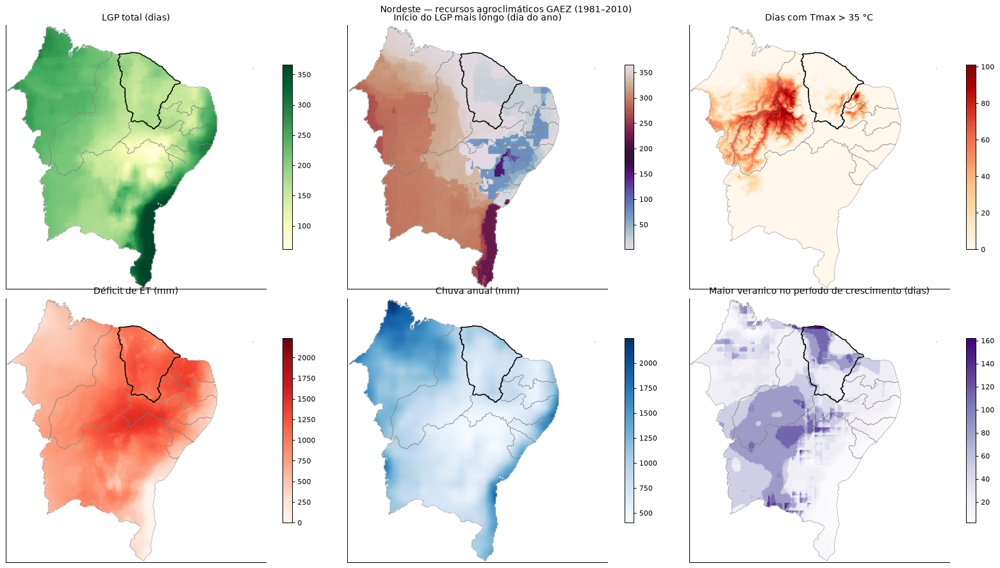

Ceará — mês de início do período de crescimento (% da área):
1     59.6
12    40.4


In [123]:
mostrar = ["LGP total (dias)", "Início do LGP mais longo (dia do ano)", "Dias com Tmax > 35 °C", "Déficit de ET (mm)",
           "Chuva anual (mm)", "Maior veranico no período de crescimento (dias)"]
cmaps = ["YlGn", "twilight", "OrRd", "Reds", "Blues", "Purples"]
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
for ax, rot, cm in zip(axs.ravel(), mostrar, cmaps):
    a, tr = campos[rot]
    im = ax.imshow(np.where(M_NE, a, np.nan), extent=extent(tr, a.shape), cmap=cm)
    ne.boundary.plot(ax=ax, color="grey", lw=0.4)
    ce.boundary.plot(ax=ax, color="k", lw=1.2)
    ax.set_title(rot); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    fig.colorbar(im, ax=ax, shrink=0.7)
plt.suptitle("Nordeste — recursos agroclimáticos GAEZ (1981–2010)")
plt.tight_layout(); plt.show()

ini, _ = ler(r01("Beginning date of longest component LGP"), BBOX_CE)
mes_ini = pd.to_datetime(ini[M_CE][~np.isnan(ini[M_CE])].astype(int).clip(1, 365) - 1, unit="D", origin="2001-01-01").month
print("Ceará — mês de início do período de crescimento (% da área):")
print((pd.Series(mes_ini).value_counts(normalize=True).sort_index() * 100).round(1).to_string())

### Quantas safras por ano? (classe de multicultivo, sequeiro × irrigado)

In [124]:
nomes_mc = [i["rotulo"] for i in LEG["res01"]["Multi-cropping Class"]]
mc = {}
for rot, trecho in [("sequeiro", "Multi-cropping class (rain-fed)"), ("irrigado", "Multi-cropping class (with irrigation)")]:
    for regiao, bbox, M in [("Ceará", BBOX_CE, M_CE), ("Nordeste", BBOX_NE, M_NE)]:
        a, _ = ler(r01(trecho), bbox)
        v = a[M]; v = v[~np.isnan(v)].astype(int)
        cont = pd.Series(v).value_counts(normalize=True) * 100
        cont.index = [nomes_mc[i - 1] if 1 <= i <= len(nomes_mc) else f"código {i}" for i in cont.index]
        mc[(regiao, rot)] = cont
mc = pd.DataFrame(mc).fillna(0).round(1)
print("Classe de multicultivo (% da área) — rótulos na ordem da legenda oficial do serviço res01:")
print(mc.to_string())

Classe de multicultivo (% da área) — rótulos na ordem da legenda oficial do serviço res01:
                             Ceará Nordeste    Ceará Nordeste
                          sequeiro sequeiro irrigado irrigado
Double cropping                0.2     40.8      0.0      0.0
Double cropping with rice      0.0      0.0      0.0      0.0
Double rice cropping           0.0      2.6      0.0      0.0
Limited double cropping       22.4     18.2      0.0      0.0
Single cropping               77.5     35.3      0.0      0.0
Triple cropping                0.0      0.0      0.0      0.0
Triple rice cropping           0.0      3.2    100.0    100.0


## 7. Solo, relevo e uso da terra (LR)

In [125]:
def lr(trecho):
    m = sel[(sel["servico"] == "LR") & (sel["variavel"] == trecho)]
    return m.iloc[0]["arquivo"]


def dist_classes(trecho, legenda, bbox=BBOX_CE, M=None, deslocamento=0):
    M = M_CE if M is None else M
    a, _ = ler(lr(trecho), bbox)
    v = a[M]; v = v[~np.isnan(v)].astype(int)
    s = pd.Series(v).value_counts(normalize=True) * 100
    s.index = [legenda[i - deslocamento] if 0 <= i - deslocamento < len(legenda) else f"código {i}" for i in s.index]
    return s.round(1)


leg_solo = [i["rotulo"] for i in LEG["LR"]["Dominant Soil"]]
leg_sq = [i["rotulo"] for i in LEG["LR"]["Limiting Soil Quality"]]
leg_mr = [i["rotulo"] for i in LEG["LR"]["Moisture Regime Class"]]
leg_lc = [i["rotulo"] for i in LEG["LR"]["Dominant Land Cover"]]
leg_aez = [i["rotulo"] for i in LEG["LR"]["AEZ Classification (33 Classes)"]]
print("Solo dominante no Ceará (% da área; rótulos HWSD na ordem da legenda, 'NA'=0):")
print(dist_classes("Dominant soil (5 arc-minute)", leg_solo).head(12).to_string())
print("\nQualidade de solo mais limitante (insumo baixo):")
print(dist_classes("Most limiting soil quality, low inputs", leg_sq).to_string())
print("\nRegime de umidade (LGP):")
print(dist_classes("Moisture regime class", leg_mr).to_string())
print("\nZona agroecológica dominante (33 classes):")
print(dist_classes("Dominant AEZ class (33 classes) at 5 arc-minutes", leg_aez).head(8).to_string())
print("\nCobertura dominante (rótulos na ordem da legenda, início em 1):")
print(dist_classes("Dominant land cover/use", leg_lc, deslocamento=1).to_string())

fr = {}
for rot, trecho in [("lavoura %", "Cropland"), ("pastagem/campo %", "Grassland"),
                    ("lavoura irrigável %", "Cropland, equipped for full control irrigation"),
                    ("ruminantes (UA/km²)", "Ruminant livestock density (year 2010)"), ("altitude mediana (m)", "Median altitude (5 arc-minute)")]:
    for regiao, bbox, M in [("Ceará", BBOX_CE, M_CE), ("Nordeste", BBOX_NE, M_NE)]:
        a, _ = ler(lr(trecho), bbox)
        fr[(rot, regiao)] = np.nanmean(a[M])
print("\nMédias de uso da terra e relevo:")
print(pd.Series(fr).unstack().round(2).to_string())

Solo dominante no Ceará (% da área; rótulos HWSD na ordem da legenda, 'NA'=0):
Luvisols      35.6
Regosols      15.9
Planosols     13.6
Ferralsols     9.4
Lixisols       7.4
Acrisols       6.7
Fluvisols      4.4
Arenosols      4.1
Phaeozems      1.5
Cambisols      0.9
Leptosols      0.6

Qualidade de solo mais limitante (insumo baixo):
Nutrient retention capacity    39.0
No or slight constraints       34.7
Oxygen availability            12.1
Rooting conditions              9.6
Terrain slopes                  4.2
Salinity and sodicity           0.4

Regime de umidade (LGP):
120-180 days    92.9
180-225 days     7.1

Zona agroecológica dominante (33 classes):
Tropics, lowland; semi-arid                  92.4
Tropics, lowland; sub-humid                   6.9
Land with ample irrigated soils               0.3
Land with severe soil/terrain limitations     0.2
Dominantly built-up land                      0.1
Dominantly water                              0.1

Cobertura dominante (rótulos na o


Médias de uso da terra e relevo:
                           Ceará    Nordeste
altitude mediana (m)  287.269989  370.570007
lavoura %               4.530000    8.480000
lavoura irrigável %     1.130000    0.830000
pastagem/campo %       18.570000   16.559999
ruminantes (UA/km²)    14.990000   14.150000


## 8. Tendências 1960–2010 (séries anuais CRU-TS do GAEZ)

Período de crescimento (LGP) e chuva anual: média do Ceará por ano, Mann-Kendall + Sen, e mapa de tendência por pixel no Nordeste
(Mann-Kendall vetorizado; significância a 5 %).

LGP (dias): tendência=no trend, p=1.000, Sen=0.00/ano (0.00 %/ano), média=159
chuva (mm): tendência=no trend, p=0.475, Sen=-1.49/ano (-0.17 %/ano), média=862
Correlação de Pearson LGP × chuva (Ceará, anual): 0.829


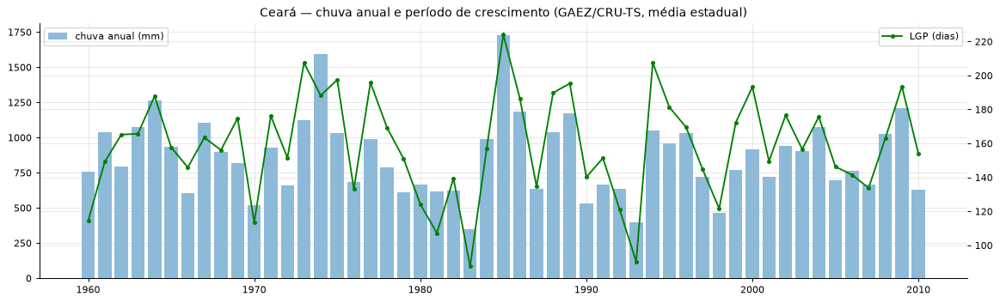

LGP: % da área do NE com tendência significativa: 11.5% (queda: 11.5%, alta: 0.0%)


chuva anual: % da área do NE com tendência significativa: 5.9% (queda: 5.9%, alta: 0.0%)


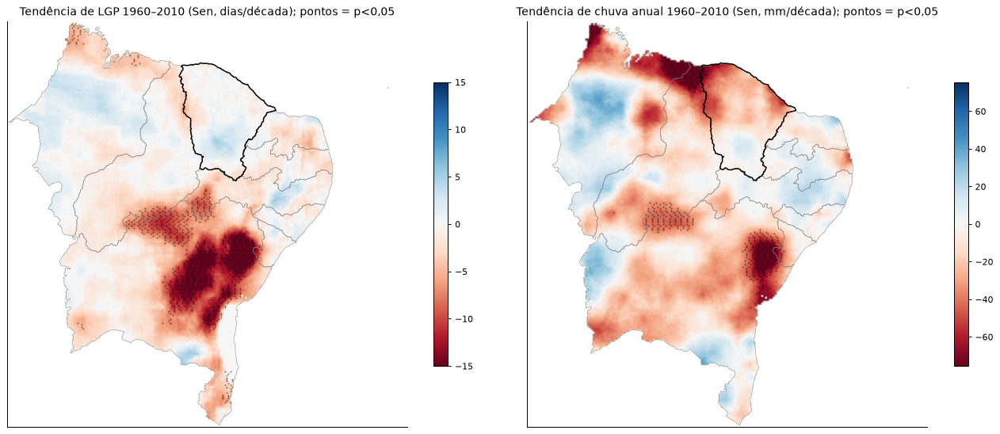

In [126]:
anuais = sel[sel["servico"] == "res01_anual"].copy()
anuais["ano"] = anuais["ano"].astype(int)
series, cubos = {}, {}
for cod in ["lgp_anual", "prec_anual"]:
    sub = anuais[anuais["codigo"] == cod].sort_values("ano")
    pilha = []
    for _, r in sub.iterrows():
        a, tr_ne = ler(r["arquivo"], BBOX_NE)
        pilha.append(a)
    cubo = np.stack(pilha)  # (anos, y, x)
    cubos[cod] = (cubo, sub["ano"].values)
    a_ce = []
    for _, r in sub.iterrows():
        b, _ = ler(r["arquivo"], BBOX_CE)
        a_ce.append(np.nanmean(b[M_CE]))
    series[cod] = pd.Series(a_ce, index=sub["ano"].values)
ser = pd.DataFrame(series)
ser.columns = ["LGP (dias)", "chuva (mm)"]
ser.index.name = "ano"
ser.to_parquet(DERIV / "gaez_ce_lgp_chuva_anual_1960_2010.parquet")

for c in ser.columns:
    t = mk.original_test(ser[c].values)
    print(f"{c}: tendência={t.trend}, p={t.p:.3f}, Sen={t.slope:.2f}/ano ({100*t.slope/ser[c].mean():.2f} %/ano), média={ser[c].mean():.0f}")
print("Correlação de Pearson LGP × chuva (Ceará, anual):", round(ser.corr().iloc[0, 1], 3))

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(ser.index, ser["chuva (mm)"], color="tab:blue", alpha=0.5, label="chuva anual (mm)")
ax2 = ax.twinx()
ax2.plot(ser.index, ser["LGP (dias)"], "g-o", ms=3, label="LGP (dias)")
ax.set_title("Ceará — chuva anual e período de crescimento (GAEZ/CRU-TS, média estadual)")
ax.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout(); plt.show()


def mk_vetorizado(cubo):
    """Mann-Kendall por pixel (sem correção de empates) + inclinação de Sen. cubo: (n, y, x)."""
    n = cubo.shape[0]
    X = cubo.reshape(n, -1)
    S = np.zeros(X.shape[1], dtype="float64")
    pares = []
    for i in range(n - 1):
        d = X[i + 1:] - X[i]
        S += np.nansum(np.sign(d), axis=0)
        pares.append(d / np.arange(1, n - i)[:, None])
    var = n * (n - 1) * (2 * n + 5) / 18
    Z = np.where(S > 0, (S - 1) / np.sqrt(var), np.where(S < 0, (S + 1) / np.sqrt(var), 0))
    p = 2 * (1 - stats.norm.cdf(np.abs(Z)))
    sen = np.nanmedian(np.concatenate(pares, axis=0), axis=0)
    shp = cubo.shape[1:]
    return sen.reshape(shp), p.reshape(shp)


fig, axs = plt.subplots(1, 2, figsize=(15, 6))
for ax, (cod, rot, un) in zip(axs, [("lgp_anual", "LGP", "dias/década"), ("prec_anual", "chuva anual", "mm/década")]):
    cubo, anos = cubos[cod]
    sen, p = mk_vetorizado(cubo)
    sen10 = np.where(M_NE, sen * 10, np.nan)
    lim = np.nanpercentile(np.abs(sen10), 98)
    im = ax.imshow(sen10, extent=extent(tr_ne, sen.shape), cmap="RdBu", vmin=-lim, vmax=lim)
    yy, xx = np.where(M_NE & (p < 0.05))
    xs = tr_ne.c + (xx + 0.5) * tr_ne.a
    ys = tr_ne.f + (yy + 0.5) * tr_ne.e
    ax.scatter(xs[::3], ys[::3], s=0.3, c="k", alpha=0.5)
    ne.boundary.plot(ax=ax, color="grey", lw=0.4); ce.boundary.plot(ax=ax, color="k", lw=1.2)
    ax.set_title(f"Tendência de {rot} 1960–2010 (Sen, {un}); pontos = p<0,05")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    fig.colorbar(im, ax=ax, shrink=0.7)
    print(f"{rot}: % da área do NE com tendência significativa: {100*np.mean(p[M_NE] < 0.05):.1f}% "
          f"(queda: {100*np.mean((p[M_NE] < 0.05) & (sen[M_NE] < 0)):.1f}%, alta: {100*np.mean((p[M_NE] < 0.05) & (sen[M_NE] > 0)):.1f}%)")
plt.tight_layout(); plt.show()

## 9. Variabilidade e extremos (1960–2010)

- Anos mais secos do Ceará (anomalia de chuva e LGP).
- **Risco de "ano sem safra"**: fração dos anos em que o LGP do pixel ficou abaixo de 60 dias (regime árido) — um mapa direto
  de risco climático para culturas de sequeiro.
- Coeficiente de variação interanual do LGP.

Anos mais secos no Ceará (z-score da chuva e do LGP):
      LGP (dias)  chuva (mm)
ano                         
1983       -2.36       -1.87
1993       -2.26       -1.69
1998       -1.23       -1.45
1970       -1.50       -1.25
1990       -0.61       -1.19
1966       -0.42       -0.92
1979       -0.26       -0.92
1981       -1.71       -0.89
1982       -0.64       -0.87
2010       -0.16       -0.84

Anos mais chuvosos:
      LGP (dias)  chuva (mm)
ano                         
1985        2.17        3.14
1974        0.98        2.65
1964        0.97        1.46
2009        1.16        1.27
1986        0.92        1.17


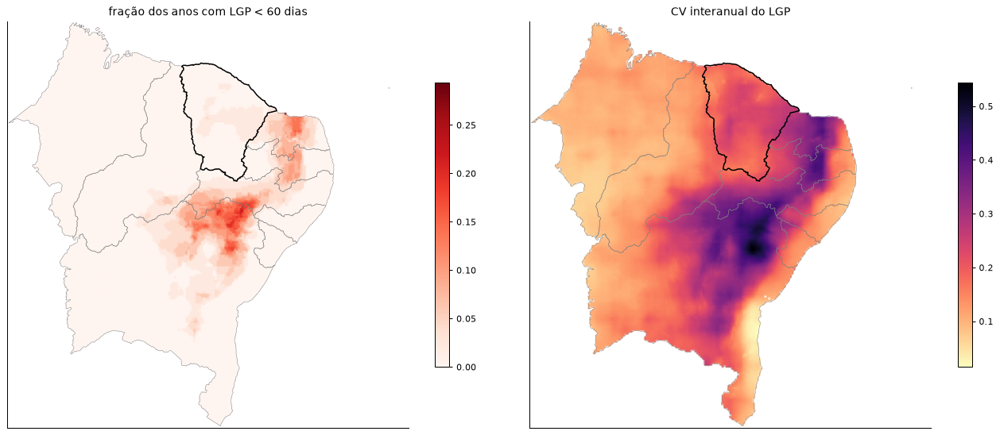

Ceará: fração média de anos com LGP < 60 dias = 0.5%; pixels com risco ≥ 20 %: 0.0%
Anos em que mais de 30 % do Ceará teve LGP < 60 dias: []


In [127]:
anom = (ser - ser.mean()) / ser.std()
print("Anos mais secos no Ceará (z-score da chuva e do LGP):")
print(anom.sort_values("chuva (mm)").head(10).round(2).to_string())
print("\nAnos mais chuvosos:")
print(anom.sort_values("chuva (mm)", ascending=False).head(5).round(2).to_string())

cubo_lgp, anos = cubos["lgp_anual"]
risco = np.nanmean(cubo_lgp < 60, axis=0)
cv = np.nanstd(cubo_lgp, axis=0) / np.nanmean(cubo_lgp, axis=0)
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
for ax, campo, rot, cm in [(axs[0], risco, "fração dos anos com LGP < 60 dias", "Reds"),
                           (axs[1], cv, "CV interanual do LGP", "magma_r")]:
    im = ax.imshow(np.where(M_NE, campo, np.nan), extent=extent(tr_ne, campo.shape), cmap=cm)
    ne.boundary.plot(ax=ax, color="grey", lw=0.4); ce.boundary.plot(ax=ax, color="k", lw=1.2)
    ax.set_title(rot); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    fig.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout(); plt.show()
cubo_ce = np.stack([ler(r["arquivo"], BBOX_CE)[0] for _, r in anuais[anuais["codigo"] == "lgp_anual"].sort_values("ano").iterrows()])
risco_ce = np.nanmean(cubo_ce < 60, axis=0)[M_CE]
print(f"Ceará: fração média de anos com LGP < 60 dias = {np.nanmean(risco_ce):.1%}; "
      f"pixels com risco ≥ 20 %: {np.mean(risco_ce >= 0.2):.1%}")
print("Anos em que mais de 30 % do Ceará teve LGP < 60 dias:",
      [int(a) for a, f in zip(sorted(anuais.loc[anuais['codigo'] == 'lgp_anual', 'ano']), [np.mean(c[M_CE] < 60) for c in cubo_ce]) if f > 0.3])

## 10. Aptidão potencial × produção real (2010)

Se o GAEZ é um bom filtro, onde a aptidão é maior a produtividade real (res06, 2010) deveria ser maior.
Correlação de Spearman pixel a pixel (só pixels com cultivo em 2010), em quatro escalas.

In [128]:
PARES = {"Maize": "Maize", "Sorghum": "Sorghum", "Cassava": "Cassava", "Cotton": "Cotton", "Soybean": "Soybean",
         "Wetland rice": "Wetland rice", "Wheat": "Wheat", "Pearl millet": "Millet", "Groundnut": "Groundnut",
         "Sugarcane": "Sugarcane", "Banana": "Banana", "Sunflower": "Sunflower", "Cowpea": "Pulses"}
BBOX_BR = (-74.0, -34.0, -34.7, 5.5)
escalas = {"Ceará": (BBOX_CE, M_CE), "Nordeste": (BBOX_NE, M_NE), "Brasil (bbox)": (BBOX_BR, None), "Mundo": (None, None)}
rng = np.random.default_rng(0)
linhas = []
for crop_si, crop_real in PARES.items():
    f_si = arq(servico="res05", cultura=crop_si, codigo="si_seq_alto")
    f_y = sel[(sel["servico"] == "res06") & (sel["cultura"] == crop_real) & (sel["variavel"] == "Yield")]
    if f_y.empty:
        continue
    f_y = f_y.iloc[0]["arquivo"]
    lin = {"cultura GAEZ": crops.get(crop_si, crop_si), "produção real (classe)": crop_real}
    for nome, (bbox, M) in escalas.items():
        si, _ = ler(f_si, bbox)
        y, _ = ler(f_y, bbox)
        ok = ~np.isnan(si) & (y > 0) & ~np.isnan(y)
        if M is not None:
            ok &= M
        x1, x2 = si[ok], y[ok]
        if len(x1) > 200000:
            idx = rng.choice(len(x1), 200000, replace=False)
            x1, x2 = x1[idx], x2[idx]
        lin[f"ρ {nome}"] = stats.spearmanr(x1, x2).correlation if len(x1) > 30 else np.nan
        lin[f"n {nome}"] = int(ok.sum())
    linhas.append(lin)
corr = pd.DataFrame(linhas)
print(corr.round(2).to_string(index=False))

  cultura GAEZ produção real (classe)  ρ Ceará  n Ceará  ρ Nordeste  n Nordeste  ρ Brasil (bbox)  n Brasil (bbox)  ρ Mundo  n Mundo
         milho                  Maize     0.22     1657        0.64       15778             0.57           102928     0.18   764991
         sorgo                Sorghum     0.02      977        0.62        5836             0.79            50482     0.27   338223
      mandioca                Cassava     0.21     1657        0.51       15966             0.21            86744     0.03   320356
       algodão                 Cotton     0.11     1625        0.48       10744             0.01            45290     0.11   293914
          soja                Soybean     0.46      256        0.53        3484             0.36            61414     0.38   445189
arroz irrigado           Wetland rice    -0.01     1541        0.00       11652             0.20            81142    -0.18   374683
         trigo                  Wheat      NaN        0        0.14         

### Validação externa: GAEZ × IBGE (PAM) no Ceará

Consulta pontual ao IBGE/SIDRA (tabela 1612, Ceará, 1974–2024) só para validar. Compara:
(a) a "produção real 2010" do GAEZ (res06) agregada no estado com o IBGE 2010;
(b) a produtividade atingível do GAEZ (sequeiro, insumo baixo e alto) com a produtividade observada 1981–2010.

In [129]:
ibge = pd.read_csv(G / "validacao_ibge_pam_ce_1974_2024.csv")
rend_ibge = ibge[ibge["variavel"] == "Rendimento médio da produção"].pivot_table(index="ano", columns="produto", values="valor")
area_ibge = ibge[ibge["variavel"] == "Área colhida"].pivot_table(index="ano", columns="produto", values="valor")
MAP_IBGE = {"Maize": "Milho (em grão)", "Cotton": "Algodão herbáceo (em caroço)", "Cassava": "Mandioca",
            "Soybean": "Soja (em grão)"}
linhas = []
for crop, prod_ibge in MAP_IBGE.items():
    fy = sel[(sel["servico"] == "res06") & (sel["cultura"] == crop) & (sel["variavel"] == "Yield")].iloc[0]["arquivo"]
    fp = sel[(sel["servico"] == "res06") & (sel["cultura"] == crop) & (sel["variavel"] == "Production")].iloc[0]["arquivo"]
    y6, _ = ler(fy, BBOX_CE); p6, _ = ler(fp, BBOX_CE)
    ok = M_CE & (y6 > 0) & (p6 > 0)
    area_g = (p6[ok] * 1000 / y6[ok]).sum()
    lin = {"cultura": crop, "GAEZ 2010: produtiv. (kg/ha)": 1e6 * p6[ok].sum() / area_g if area_g else np.nan,
           "IBGE 2010: produtiv. (kg/ha)": rend_ibge.loc[2010, prod_ibge],
           "GAEZ 2010: área (mil ha)": area_g / 1e3, "IBGE 2010: área (mil ha)": area_ibge.loc[2010, prod_ibge] / 1e3}
    gaez_crop = {"Maize": "Maize", "Cotton": "Cotton", "Cassava": "Cassava", "Soybean": "Soybean"}[crop]
    for cod, rot in [("yld_seq_baixo", "GAEZ atingível insumo baixo"), ("yld_seq_alto", "GAEZ atingível insumo alto")]:
        ya, _ = ler(arq(servico="res05", cultura=gaez_crop, codigo=cod), BBOX_CE)
        lin[rot + " (kg/ha)"] = np.nanmean(ya[M_CE & (ya > 0)])
    # conversão aproximada IBGE -> base do GAEZ (matéria seca; algodão em pluma)
    conv = {"Maize": 0.87, "Soybean": 0.87, "Cassava": 0.35, "Cotton": 0.38}[crop]
    obs = rend_ibge.loc[1981:2010, prod_ibge] * conv
    lin["fator IBGE→GAEZ (aprox.)"] = conv
    lin["IBGE média 1981–2010 convertida (kg/ha)"] = obs.mean()
    lin["IBGE máx. 1981–2010 convertida (kg/ha)"] = obs.max()
    lin["IBGE / atingível insumo baixo"] = obs.mean() / lin["GAEZ atingível insumo baixo (kg/ha)"]
    lin["IBGE / atingível insumo alto"] = obs.mean() / lin["GAEZ atingível insumo alto (kg/ha)"]
    linhas.append(lin)
val = pd.DataFrame(linhas).set_index("cultura").T
print(val.round(2).to_string())
print("\nConversões aproximadas: grão a 13 % de umidade → matéria seca ×0,87; mandioca fresca → seca ×0,35; "
      "algodão em caroço → pluma ×0,38. A produção 'real 2010' do GAEZ fica 19× acima do IBGE no milho e com área 4× menor.")

cultura                                    Maize   Cotton   Cassava  Soybean
GAEZ 2010: produtiv. (kg/ha)             5987.19  8184.58  11999.40  2926.78
IBGE 2010: produtiv. (kg/ha)              316.00  1009.00   5688.00  3350.00
GAEZ 2010: área (mil ha)                  127.51    23.73     19.63    28.92
IBGE 2010: área (mil ha)                  551.98     2.18    109.16     1.02
GAEZ atingível insumo baixo (kg/ha)      2093.12   129.46   2468.49   690.23
GAEZ atingível insumo alto (kg/ha)       7426.58   915.16   5407.48  3266.65
fator IBGE→GAEZ (aprox.)                    0.87     0.38      0.35     0.87
IBGE média 1981–2010 convertida (kg/ha)   501.56   234.18   2757.31  2392.43
IBGE máx. 1981–2010 convertida (kg/ha)   1034.43   477.66   3400.25  2975.40
IBGE / atingível insumo baixo               0.24     1.81      1.12     3.47
IBGE / atingível insumo alto                0.07     0.26      0.51     0.73

Conversões aproximadas: grão a 13 % de umidade → matéria seca ×0,87; mandio

### Clima anual do GAEZ × produtividade real (IBGE), Ceará 1974–2010

Anomalias de produtividade (razão à mediana móvel de 7 anos, para tirar a tendência tecnológica) contra chuva anual e LGP.

                     cultura variável GAEZ  ρ Spearman      p  n
             Milho (em grão)    LGP (dias)        0.59 0.0001 37
             Milho (em grão)    chuva (mm)        0.55 0.0005 37
            Feijão (em grão)    LGP (dias)        0.47 0.0031 37
            Feijão (em grão)    chuva (mm)        0.39 0.0185 37
                    Mandioca    LGP (dias)        0.39 0.0172 37
                    Mandioca    chuva (mm)        0.41 0.0122 37
Algodão herbáceo (em caroço)    LGP (dias)        0.39 0.0161 37
Algodão herbáceo (em caroço)    chuva (mm)        0.36 0.0285 37


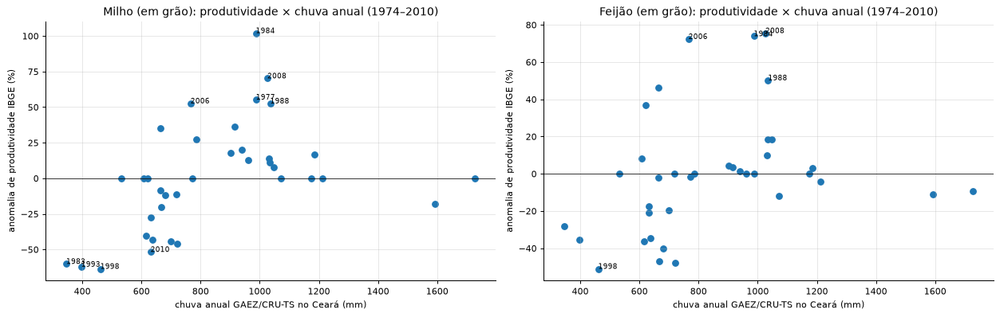

Produtividade do milho no Ceará (IBGE), anos recentes (kg/ha): {2010: 316, 2011: 1262, 2012: 246, 2013: 317, 2014: 737, 2015: 264, 2016: 242, 2017: 663, 2018: 825, 2019: 812, 2020: 1178, 2021: 743, 2022: 924, 2023: 600, 2024: 697}
Área colhida de algodão herbáceo no Ceará (mil ha): {1974: 90.0, 1980: 54.0, 1985: 305.8, 1990: 78.2, 2000: 95.1, 2005: 10.3, 2010: 2.2, 2015: 0.4, 2024: 2.3}


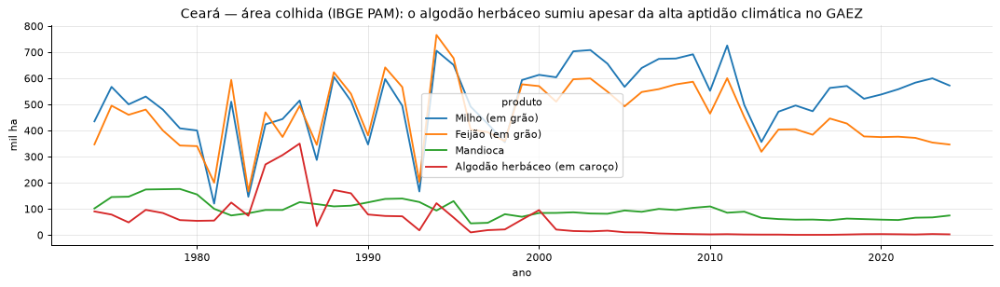

In [130]:
ser_v = ser.loc[1974:2010]
an_rend = rend_ibge.loc[1974:2010, ["Milho (em grão)", "Feijão (em grão)", "Mandioca", "Algodão herbáceo (em caroço)"]]
an_rend = an_rend / an_rend.rolling(7, center=True, min_periods=3).median() - 1
linhas = []
for c in an_rend.columns:
    for v in ser_v.columns:
        x = pd.concat([an_rend[c], ser_v[v]], axis=1).dropna()
        rho, p = stats.spearmanr(x.iloc[:, 0], x.iloc[:, 1])
        linhas.append({"cultura": c, "variável GAEZ": v, "ρ Spearman": round(rho, 2), "p": round(p, 4), "n": len(x)})
print(pd.DataFrame(linhas).to_string(index=False))
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, c in zip(axs, ["Milho (em grão)", "Feijão (em grão)"]):
    x = pd.concat([an_rend[c], ser_v["chuva (mm)"]], axis=1).dropna()
    ax.scatter(x["chuva (mm)"], 100 * x[c])
    for ano, r in x.iterrows():
        if abs(r[c]) > 0.5:
            ax.annotate(str(ano), (r["chuva (mm)"], 100 * r[c]), fontsize=7)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_xlabel("chuva anual GAEZ/CRU-TS no Ceará (mm)"); ax.set_ylabel("anomalia de produtividade IBGE (%)")
    ax.set_title(f"{c}: produtividade × chuva anual (1974–2010)")
plt.tight_layout(); plt.show()
print("Produtividade do milho no Ceará (IBGE), anos recentes (kg/ha):", rend_ibge.loc[2010:2024, "Milho (em grão)"].astype(int).to_dict())
alg = area_ibge["Algodão herbáceo (em caroço)"] / 1000
print("Área colhida de algodão herbáceo no Ceará (mil ha):", alg.loc[[1974, 1980, 1985, 1990, 2000, 2005, 2010, 2015, 2024]].round(1).to_dict())
fig, ax = plt.subplots(figsize=(12, 3.5))
(area_ibge[["Milho (em grão)", "Feijão (em grão)", "Mandioca", "Algodão herbáceo (em caroço)"]] / 1000).plot(ax=ax)
ax.set_ylabel("mil ha"); ax.set_title("Ceará — área colhida (IBGE PAM): o algodão herbáceo sumiu apesar da alta aptidão climática no GAEZ")
plt.tight_layout(); plt.show()

**Atenção:** a razão de produtividade alcançada (res07) abaixo é derivada da produção real de 2010 (res06), que a validação acima mostrou
estar muito distante do IBGE no Ceará. Fica registrada apenas como evidência de que essa camada **não deve** ser usada no produto para o Ceará.

Ceará — razão produtividade real / atingível em 2010 (% dos pixels cultivados por classe):
              < 10%  10%-25%  25%-40%  40%-55%  55%-70%  70%-85%  > 85%
Banana          0.0      0.0      0.0     61.2     38.8      0.0    0.0
Cotton          0.0      0.0      0.0      0.0      0.0      0.0  100.0
Groundnut       0.0      0.0      0.0      0.0      0.0    100.0    0.0
Maize           0.0      0.0      0.0      0.0      0.0    100.0    0.0
Pulses          0.0      0.0    100.0      0.0      0.0      0.0    0.0
Wetland rice    0.0      0.0      0.0     58.5     41.5      0.0    0.0
Cassava         0.0      0.0      0.0      0.0    100.0      0.0    0.0
Soybean         0.0      0.0      0.0      0.0      0.0    100.0    0.0
Sorghum         0.0      0.0      0.0    100.0      0.0      0.0    0.0
Sugarcane       0.0      0.0      0.0      0.0     27.8      0.5   71.7


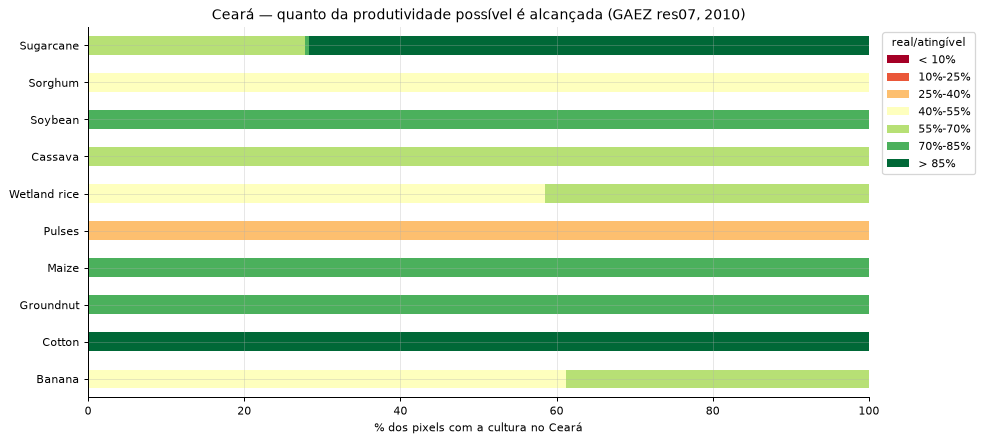

In [131]:
leg_gap =[i["rotulo"] for i in LEG["res07"]["Yield and Production Gaps Symbology"]]
gap = {}
for _, r in sel[sel["servico"] == "res07"].iterrows():
    a, _ = ler(r["arquivo"], BBOX_CE)
    v = a[M_CE]; v = v[~np.isnan(v) & (v > 0)].astype(int)
    if len(v) < 10:
        continue
    s = pd.Series(v).value_counts(normalize=True) * 100
    s.index = [leg_gap[i] if i < len(leg_gap) else f"código {i}" for i in s.index]
    gap[r["cultura"]] = s
gap = pd.DataFrame(gap).T.reindex(columns=leg_gap[1:]).fillna(0).round(1)
print("Ceará — razão produtividade real / atingível em 2010 (% dos pixels cultivados por classe):")
print(gap.to_string())
if len(gap):
    ax = gap.plot.barh(stacked=True, cmap="RdYlGn", figsize=(11, 5))
    ax.set_xlabel("% dos pixels com a cultura no Ceará"); ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", title="real/atingível")
    ax.set_title("Ceará — quanto da produtividade possível é alcançada (GAEZ res07, 2010)")
    plt.tight_layout(); plt.show()

## 11. Insights e ideias para o produto

1. **GAEZ é global de verdade e serve de filtro de candidatas.** 99,8 % dos pixels de terra (sem Antártida) têm aptidão calculada, de 56°S a 84°N.
   Para qualquer ponto: `candidatas = {cultura | SI_sequeiro(insumo do agricultor) > 35}` ∪ `{cultura | SI_irrigado > 35 e há água}`.
   É o primeiro estágio do motor de rotação, antes do clima recente (POWER/IMERG/SMAP) e do talhão (Landsat/Sentinel-2/SRTM).
2. **O nível de insumo decide o ranking no Ceará.** Com insumo alto, algodão (71), sorgo (63), milho (60), guandu, milheto, soja e feijões (~58)
   ficam todos "bons"; com **insumo baixo** (agricultura familiar) lideram **sorgo, mandioca, guandu e feijão** (~50–53) e o algodão despenca (35).
   O produto precisa perguntar o nível tecnológico — ele muda a recomendação.
3. **Irrigação destrava culturas específicas** (mesmas células): banana 0→68, cana 3→53, arroz 30→66; para grãos e leguminosas o ganho de aptidão é ~0
   (o clima médio já os permite) — no semiárido a irrigação vale mais para fruticultura/cana do que para grãos.
4. **Calendário da rotação:** no Ceará o período de crescimento começa entre dez e jan (média circular ≈ 8 de janeiro) e **77,5 % da área só
   comporta uma safra de sequeiro** (22 % "dupla limitada"). Logo, a decisão-chave da rotação é *o que fica no solo na entressafra*
   (cobertura, forrageira, leguminosa perene como guandu), não uma segunda safra de grão.
5. **Clima explica a produtividade real:** anomalias de produtividade do IBGE (1974–2010) correlacionam com o LGP anual do GAEZ
   (milho ρ = 0,59; feijão 0,47; p < 0,01) — mas o LGP mensal do GAEZ quase nunca cai abaixo de 60 dias e não "viu" a seca de 2010
   (produtividade do milho 316 kg/ha). **Veranicos dentro da estação** só aparecem com dados diários (IMERG/POWER/SMAP): o risco do produto
   deve vir deles, e o GAEZ entra como aptidão média.
6. **Lacuna de produtividade enorme:** o milho real do Ceará (IBGE 1981–2010, convertido) fica em ~24 % do atingível com insumo baixo e ~7 % com insumo alto.
   O ganho vem de manejo (água no solo, cobertura, rotação com leguminosa), não de trocar o clima — argumento central do pitch.
7. **A camada de "produção real 2010" do GAEZ (res06/res07) é inútil no Ceará:** milho 19× acima do IBGE e área 4× menor. Além disso, as correlações
   aptidão × produção real (seção 10) são parcialmente circulares (a desagregação usa a própria aptidão). Para o Brasil, usar IBGE PAM municipal;
   para o mundo, FAOSTAT nacional + SPAM com cautela.
8. **Algodão: aptidão alta, área zero.** O algodão herbáceo caiu de 306 mil ha (1985) para ~2 mil ha (2010–2024) no Ceará. Clima e solo não explicam
   a saída (com insumo alto ele é a cultura mais apta) — pragas (bicudo-do-algodoeiro, desde os anos 1980), mercado e crédito sim. É o exemplo
   perfeito de por que o motor precisa de uma camada de **pragas/ciclo de pragas** e de **mercado**, além de clima e solo.
9. **Solo do Ceará:** Luvissolos (36 %), Regossolos, Planossolos, Latossolos; a limitação mais comum é **retenção de nutrientes** (39 %) e oxigênio
   (Planossolos, 12 %) — favorece rotações que aumentam matéria orgânica (leguminosas, palhada) e evita culturas sensíveis a encharcamento nas baixadas.
10. **Tendência 1960–2010:** sem tendência significativa no Ceará como um todo; no Nordeste, 11,5 % da área tem queda significativa do LGP e nenhuma área tem alta.
    **Cenários CMIP5 até 2100 estão no catálogo** com as mesmas variáveis — base pronta para o slider de clima futuro.

**Limitações:** clima-base 1981–2010 e séries só até 2010 (não captura a seca de 2012–2017); resolução de 9 km; dias com Tmax > 35 °C subestimados
(interpolação de dados mensais); HWSD é grosseiro no semiárido; caju/castanha e palma forrageira não existem no GAEZ; rótulos de classes
mapeados pela ordem da legenda oficial do serviço (consistentes com os solos conhecidos do Ceará).

# 12 · Mercado: AMS Market News (EUA), FAOSTAT e Banco Mundial (globais)

**Pergunta do produto:** a rotação sugerida tem mercado? Quanto rende por hectare e com que risco?

O desafio indica o **USDA AMS Market News**, mas ele só cobre os EUA e a API exige chave.
Para um produto que funcione **no mundo todo**, a base de mercado precisa ser global. Este estudo:
1. documenta o que foi possível obter do AMS;
2. valida a cobertura global do **FAOSTAT** (preço ao produtor e produção por país) e do **Pink Sheet** do Banco Mundial (preços internacionais mensais);
3. extrai estatísticas de preço, renda por hectare, volatilidade, sazonalidade e tendência para as culturas candidatas do Ceará/Nordeste.

In [132]:
import sys, json, warnings
sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
from comum import *  # noqa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pymannkendall as mk

try:
    sys.stdout.reconfigure(encoding="utf-8")
except Exception:
    pass
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

M = pasta("mercado")
man = json.loads((M / "MANIFESTO.json").read_text(encoding="utf-8"))
pr = pd.read_parquet(DERIV / "faostat_precos_produtor.parquet")
qcl = pd.read_parquet(DERIV / "faostat_producao_qcl.parquet")
br = pd.read_parquet(DERIV / "faostat_brasil_anual.parquet")
pk = pd.read_parquet(DERIV / "mercado_precos_mensal.parquet")
print("FAOSTAT preços:", pr.shape, "| FAOSTAT produção:", qcl.shape, "| Pink Sheet:", pk.shape)

FAOSTAT preços: (274480, 15) | FAOSTAT produção: (587421, 14) | Pink Sheet: (50518, 4)


## 1. Ficha técnica

| Base | Provedor | Conteúdo | Resolução | Período | Cobertura | Acesso |
|---|---|---|---|---|---|---|
| AMS Market News (MyMarketNews/MARS) | USDA | Relatórios de preço de grãos, gado, hortifrúti nos mercados dos EUA | Mercado/terminal, diário/semanal | contínuo | **Só EUA** | API exige chave; `.txt` legados congelados em 2020 |
| FAOSTAT Producer Prices | FAO | Preço recebido pelo produtor (USD/t, moeda local, índice) | País, anual (+ mensal em alguns países) | 1991–2025 | **Global** (~177 países) | Bulk aberto |
| FAOSTAT Crops & Livestock (QCL) | FAO | Área colhida, produção, produtividade | País, anual | 1961–2024 | **Global** (~240 áreas) | Bulk aberto |
| Pink Sheet (CMO) | Banco Mundial | 71 preços internacionais (grãos, oleaginosas, fertilizantes, energia) | Referência mundial, mensal | 1960–out/2026 | **Global** (preço de bolsa/porto) | xlsx aberto |

In [133]:
print("Status AMS:", man.get("ams_status"))
print("Status CONAB:", man.get("conab_status"))
print("Arquivos brutos:")
for f in sorted((M / "brutos").iterdir()):
    print(f"  {f.name:32s} {f.stat().st_size/1e6:8.2f} MB")
print(f"Total da pasta mercado: {tamanho_pasta(M)/1e6:.1f} MB")
amostra = (M / "brutos" / "ams_gx_gr110_legado.txt").read_text(encoding="cp1252", errors="replace")
print("\nAmostra AMS (relatório legado):\n", amostra[:700])

Status AMS: MARS API v1.2 (marsapi.ams.usda.gov) responde 403 sem chave; mymarketnews.ams.usda.gov deu timeout; datamart mpr responde 500; relatorios .txt legados param em jul/2020. AMS cobre so EUA.
Status CONAB: portaldeinformacoes.conab.gov.br: certificado TLS com nome errado; http redireciona para 404.
Arquivos brutos:
  ams_3192.pdf                         0.32 MB
  ams_gx_gr110_legado.txt              0.00 MB
  faostat_prices.zip                  11.68 MB
  faostat_qcl.zip                     33.92 MB
  wb_pink_sheet_anual.xlsx             3.18 MB
  wb_pink_sheet_mensal.xlsx            0.59 MB
Total da pasta mercado: 49.7 MB

Amostra AMS (relatório legado):
 GX_GR110
Springfield, IL    Fri, Jul 24, 2020    USDA-IL Dept of Ag Market News

NOTICE:  As Market News transitions Grain reports to the MARS platform and My Market News, report formats will be converted from a text version to a more user-friendly and accessible PDF format. In the next few weeks, this report will move to the

## 2. Validação de cobertura global

Evidência: número de países com dado por ano e mapa mundial de anos com preço ao produtor.
O código M49 do FAOSTAT casa com o `ISO_N3` do Natural Earth.

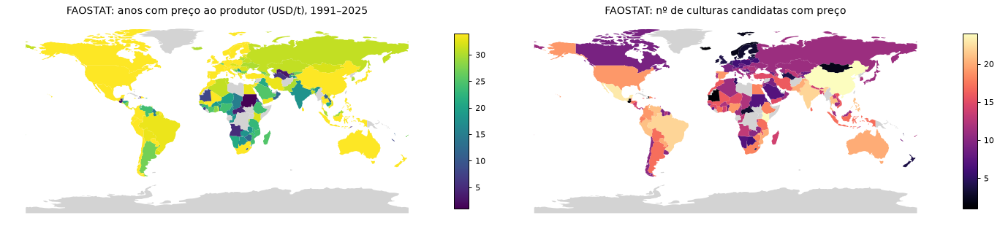

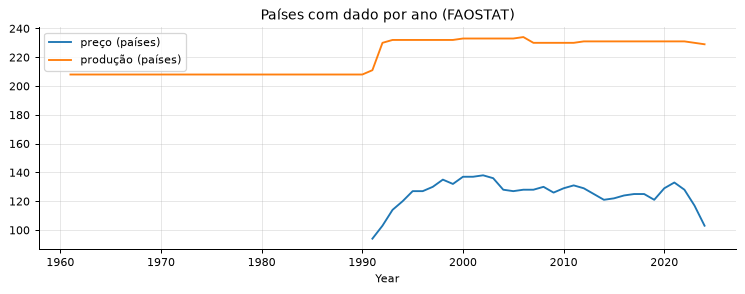

Países do mapa (Natural Earth 110m, sem Antártida): 176
Com preço ao produtor FAOSTAT: 148 (84%)
Áreas com produção FAOSTAT (inclui agregados regionais): 242
Pink Sheet: preço de referência internacional único por commodity (não é por país).
AMS: somente mercados dos EUA.


In [134]:
paises = paises_gdf()
pr["m49"] = pr["Area Code (M49)"].astype(str).str.strip("'").str.zfill(3)
qcl["m49"] = qcl["Area Code (M49)"].astype(str).str.strip("'").str.zfill(3)
paises["m49"] = paises["ISO_N3_EH"].astype(str).str.zfill(3)

usd = pr[(pr["Element"] == "Producer Price (USD/tonne)") & (pr["Months"] == "Annual value")]
anos_pais = usd.groupby("m49")["Year"].nunique().rename("anos_com_preco")
cult_pais = usd.groupby("m49")["Item"].nunique().rename("culturas_com_preco")
g = paises.merge(anos_pais, on="m49", how="left").merge(cult_pais, on="m49", how="left")

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
g.plot(column="anos_com_preco", ax=ax[0], legend=True, cmap="viridis", missing_kwds={"color": "lightgrey"})
ax[0].set_title("FAOSTAT: anos com preço ao produtor (USD/t), 1991–2025")
g.plot(column="culturas_com_preco", ax=ax[1], legend=True, cmap="magma", missing_kwds={"color": "lightgrey"})
ax[1].set_title("FAOSTAT: nº de culturas candidatas com preço")
for a in ax:
    a.set_axis_off()
plt.tight_layout(); plt.show()

paises_por_ano = pd.DataFrame({
    "preço (países)": usd.groupby("Year")["m49"].nunique(),
    "produção (países)": qcl[qcl["Element"] == "Production"].groupby("Year")["m49"].nunique(),
})
paises_por_ano.plot(figsize=(10, 3.2), title="Países com dado por ano (FAOSTAT)")
plt.show()

cobertos = g["anos_com_preco"].notna().sum()
terra_agric = paises[paises["CONTINENT"] != "Antarctica"]
print(f"Países do mapa (Natural Earth 110m, sem Antártida): {len(terra_agric)}")
print(f"Com preço ao produtor FAOSTAT: {cobertos} ({cobertos/len(terra_agric):.0%})")
prod_paises = qcl[qcl['Element']=='Production']['m49'].nunique()
print(f"Áreas com produção FAOSTAT (inclui agregados regionais): {prod_paises}")
print("Pink Sheet: preço de referência internacional único por commodity (não é por país).")
print("AMS: somente mercados dos EUA.")

**Veredito de cobertura:**
- **FAOSTAT (preço e produção): GLOBAL.** Quase todos os países agrícolas têm série; as lacunas ficam em países pequenos, em conflito ou com estatística fraca. Escala **nacional** (não serve para município — para o Ceará, complementar com IBGE PAM).
- **Pink Sheet: GLOBAL como referência** (preço de bolsa/porto). Bom para tendência, choques e fertilizantes; não reflete o preço na porteira do Sertão.
- **AMS Market News: NÃO É GLOBAL** (só EUA, chave obrigatória). Fica como módulo opcional para usuários dos EUA.

## 3. Qualidade dos dados

Distribuição de flags FAOSTAT (A=oficial, E=estimado, I=imputado, M=faltante, X=fonte internacional):
      preço  produção
Flag                 
A      75.9      61.3
B       0.0       0.0
E      23.8      29.1
I       0.0       4.5
M       0.0       2.4
X       0.3       2.8


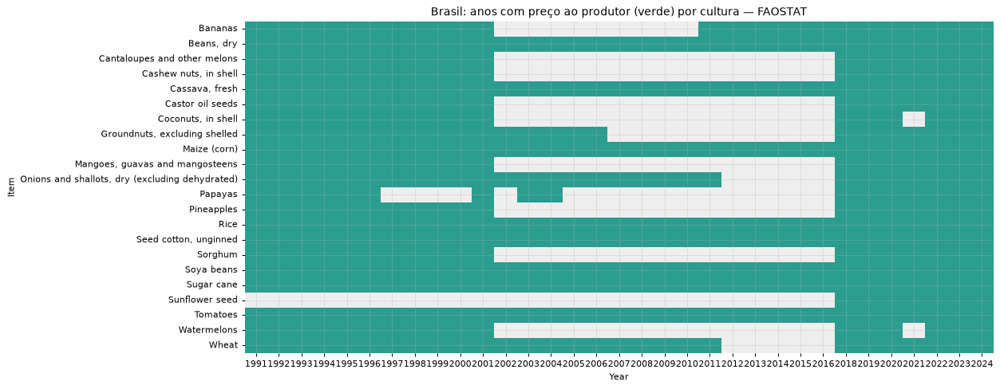

Completude (anos com preço / anos possíveis) no Brasil:
Item
Sunflower seed                                      21.0
Papayas                                             48.0
Watermelons                                         52.0
Coconuts, in shell                                  52.0
Pineapples                                          55.0
Sorghum                                             55.0
Castor oil seeds                                    55.0
Cashew nuts, in shell                               55.0
Mangoes, guavas and mangosteens                     55.0
Cantaloupes and other melons                        55.0
Groundnuts, excluding shelled                       70.0
Bananas                                             73.0
Onions and shallots, dry (excluding dehydrated)     85.0
Wheat                                               85.0
Cassava, fresh                                     100.0
Beans, dry                                         100.0
Seed cotton, unginned      

In [135]:
flags = pd.DataFrame({
    "preço": pr["Flag"].value_counts(normalize=True),
    "produção": qcl["Flag"].value_counts(normalize=True),
}).fillna(0)
print("Distribuição de flags FAOSTAT (A=oficial, E=estimado, I=imputado, M=faltante, X=fonte internacional):")
print((flags * 100).round(1))

br_usd = usd[usd["Area"] == "Brazil"]
grade = br_usd.pivot_table(index="Item", columns="Year", values="Value", aggfunc="mean")
fig, ax = plt.subplots(figsize=(14, 5.5))
sns.heatmap(grade.notna(), cbar=False, cmap=["#eee", "#2a9d8f"], ax=ax)
ax.set_title("Brasil: anos com preço ao produtor (verde) por cultura — FAOSTAT")
plt.tight_layout(); plt.show()
print("Completude (anos com preço / anos possíveis) no Brasil:")
print((grade.notna().mean(axis=1) * 100).round(0).sort_values().to_string())

pk_largo = pk.pivot_table(index="data", columns="commodity", values="preco")
print("\nPink Sheet: % de meses sem valor por commodity (top 10):")
print((pk_largo.isna().mean() * 100).round(1).sort_values(ascending=False).head(10).to_string())

## 4. Estatística descritiva — Brasil e mundo

FAOSTAT é nacional; o Nordeste/Ceará entra como contexto do Brasil. Indicadores para os últimos 5 anos disponíveis.

In [136]:
def ultimo_quinquenio(df, col="Value"):
    ult = df["Year"].max()
    return df[df["Year"] > ult - 5]

prod = qcl[qcl["Element"] == "Production"]
mundo = prod[prod["Area"] == "World"].groupby("Item").apply(lambda d: ultimo_quinquenio(d)["Value"].mean())
brasil = prod[prod["Area"] == "Brazil"].groupby("Item").apply(lambda d: ultimo_quinquenio(d)["Value"].mean())
rend = qcl[qcl["Element"] == "Yield"]
rend_br = rend[rend["Area"] == "Brazil"].groupby("Item").apply(lambda d: ultimo_quinquenio(d)["Value"].mean() / 1000)
rend_mu = rend[rend["Area"] == "World"].groupby("Item").apply(lambda d: ultimo_quinquenio(d)["Value"].mean() / 1000)
preco_br = br_usd.groupby("Item").apply(lambda d: ultimo_quinquenio(d)["Value"].mean())
preco_cv = br_usd.groupby("Item").apply(lambda d: ultimo_quinquenio(d)["Value"].std() / ultimo_quinquenio(d)["Value"].mean())
med_mundo = usd.groupby(["Item", "Year"])["Value"].median().reset_index()
preco_mundo = med_mundo.groupby("Item").apply(lambda d: ultimo_quinquenio(d)["Value"].mean())

tab = pd.DataFrame({
    "produção BR (Mt)": brasil / 1e6,
    "% do mundo": 100 * brasil / mundo,
    "produtiv. BR (t/ha)": rend_br,
    "produtiv. mundo (t/ha)": rend_mu,
    "preço BR (USD/t)": preco_br,
    "preço mediano mundo (USD/t)": preco_mundo,
    "CV preço BR 5a": preco_cv,
}).round(2)
tab["receita BR (USD/ha)"] = (tab["produtiv. BR (t/ha)"] * tab["preço BR (USD/t)"]).round(0)
tab = tab.sort_values("receita BR (USD/ha)", ascending=False)
print(tab.to_string())

                                                 produção BR (Mt)  % do mundo  produtiv. BR (t/ha)  produtiv. mundo (t/ha)  preço BR (USD/t)  preço mediano mundo (USD/t)  CV preço BR 5a  receita BR (USD/ha)
Item                                                                                                                                                                                                          
Tomatoes                                                     3.97        2.14                71.35                   35.78            401.26                       843.36            0.20              28630.0
Pineapples                                                   2.35        8.08                37.50                   27.55            392.58                       684.67            0.30              14722.0
Onions and shallots, dry (excluding dehydrated)              1.62        1.49                33.20                   18.90            402.70                       459.05   

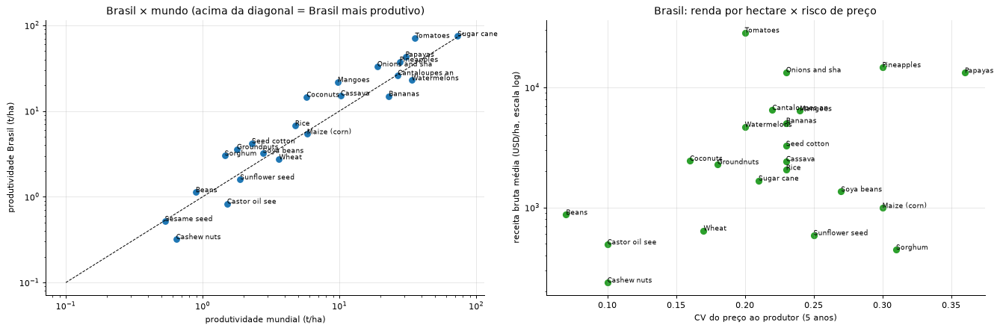

In [137]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
t2 = tab.dropna(subset=["produtiv. BR (t/ha)", "produtiv. mundo (t/ha)"])
ax[0].scatter(t2["produtiv. mundo (t/ha)"], t2["produtiv. BR (t/ha)"])
for n, r in t2.iterrows():
    ax[0].annotate(n.split(",")[0][:14], (r["produtiv. mundo (t/ha)"], r["produtiv. BR (t/ha)"]), fontsize=7)
lim = max(t2[["produtiv. mundo (t/ha)", "produtiv. BR (t/ha)"]].max()) * 1.1
ax[0].plot([0.1, lim], [0.1, lim], "k--", lw=0.8)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("produtividade mundial (t/ha)"); ax[0].set_ylabel("produtividade Brasil (t/ha)")
ax[0].set_title("Brasil × mundo (acima da diagonal = Brasil mais produtivo)")
t3 = tab.dropna(subset=["receita BR (USD/ha)", "CV preço BR 5a"])
ax[1].scatter(t3["CV preço BR 5a"], t3["receita BR (USD/ha)"], s=40, c="tab:green")
for n, r in t3.iterrows():
    ax[1].annotate(n.split(",")[0][:14], (r["CV preço BR 5a"], r["receita BR (USD/ha)"]), fontsize=7)
ax[1].set_yscale("log"); ax[1].set_xlabel("CV do preço ao produtor (5 anos)")
ax[1].set_ylabel("receita bruta média (USD/ha, escala log)")
ax[1].set_title("Brasil: renda por hectare × risco de preço")
plt.tight_layout(); plt.show()

## 5. Sazonalidade de preço

(a) Preço ao produtor **mensal no Brasil** (FAOSTAT, moeda local, 2015–2025): índice sazonal = média do mês ÷ média anual.
(b) Pink Sheet (internacional): índice sazonal de 1990–2025 calculado sobre os preços sem tendência (razão à média móvel de 12 meses).

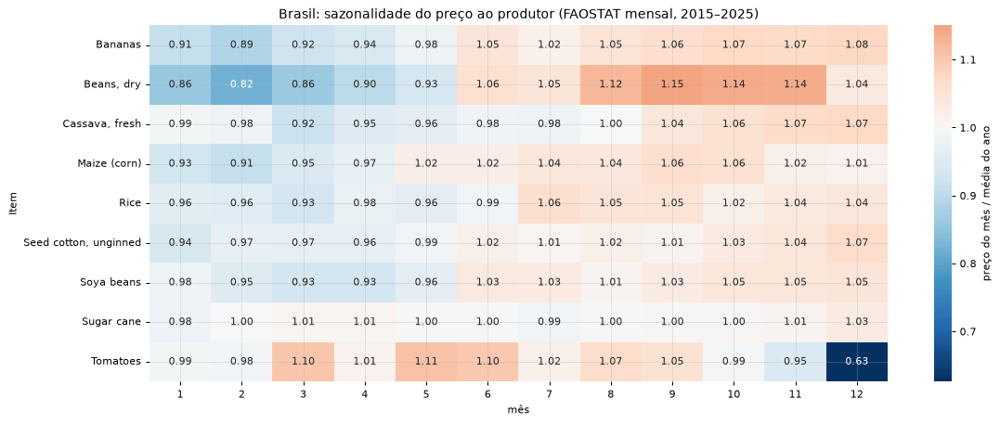

Amplitude sazonal (máx − mín do índice):
 Item
Tomatoes                 0.48
Beans, dry               0.33
Bananas                  0.19
Cassava, fresh           0.15
Maize (corn)             0.15
Seed cotton, unginned    0.13
Rice                     0.13
Soya beans               0.12
Sugar cane               0.05


In [138]:
meses = ["January", "February", "March", "April", "May", "June", "July", "August", "September",
         "October", "November", "December"]
bm = pr[(pr["Area"] == "Brazil") & (pr["Element"] == "Producer Price (LCU/tonne)") & (pr["Months"].isin(meses))].copy()
bm["mes"] = bm["Months"].map({m: i + 1 for i, m in enumerate(meses)})
bm["rel"] = bm["Value"] / bm.groupby(["Item", "Year"])["Value"].transform("mean")
ind_br = bm.groupby(["Item", "mes"])["rel"].mean().unstack()
ind_br = ind_br[ind_br.notna().sum(axis=1) >= 10]
fig, ax = plt.subplots(figsize=(13, 0.35 * len(ind_br) + 2))
sns.heatmap(ind_br, cmap="RdBu_r", center=1, annot=True, fmt=".2f", ax=ax, cbar_kws={"label": "preço do mês / média do ano"})
ax.set_title("Brasil: sazonalidade do preço ao produtor (FAOSTAT mensal, 2015–2025)")
ax.set_xlabel("mês")
plt.tight_layout(); plt.show()
amp = (ind_br.max(axis=1) - ind_br.min(axis=1)).sort_values(ascending=False)
print("Amplitude sazonal (máx − mín do índice):\n", amp.round(2).to_string())

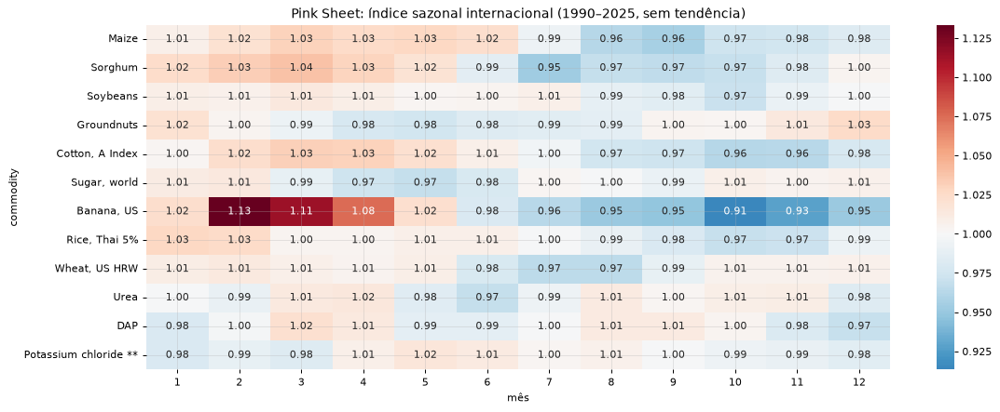

In [139]:
sel = ["Maize", "Sorghum", "Soybeans", "Groundnuts", "Cotton, A Index", "Sugar, world", "Banana, US",
       "Rice, Thai 5%", "Wheat, US HRW", "Urea", "DAP", "Potassium chloride **"]
sel = [s for s in sel if s in pk_largo.columns]
base = pk_largo.loc["1990":, sel]
razao = base / base.rolling(12, center=True).mean()
ind_pk = razao.groupby(razao.index.month).mean().T
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(ind_pk, cmap="RdBu_r", center=1, annot=True, fmt=".2f", ax=ax)
ax.set_title("Pink Sheet: índice sazonal internacional (1990–2025, sem tendência)")
ax.set_xlabel("mês")
plt.tight_layout(); plt.show()

## 6. Tendências (Mann-Kendall + inclinação de Sen)

(a) Produtividade do Brasil 1961–2024 por cultura. (b) Preços internacionais 1990–2026 (nominais, USD).

In [140]:
linhas = []
for item, d in rend[rend["Area"] == "Brazil"].groupby("Item"):
    s = d.sort_values("Year").set_index("Year")["Value"].dropna() / 1000
    if len(s) < 15:
        continue
    t = mk.original_test(s.values)
    linhas.append({"cultura": item, "anos": len(s), "tendência": t.trend, "p": t.p,
                   "Sen (t/ha/ano)": t.slope, "Sen % ao ano": 100 * t.slope / s.mean(),
                   "produtiv. 1º quinquênio": s.iloc[:5].mean(), "produtiv. último quinquênio": s.iloc[-5:].mean()})
mk_br = pd.DataFrame(linhas).sort_values("Sen % ao ano", ascending=False)
print(mk_br.round(4).to_string(index=False))

                                        cultura  anos  tendência      p  Sen (t/ha/ano)  Sen % ao ano  produtiv. 1º quinquênio  produtiv. último quinquênio
                   Cantaloupes and other melons    64 increasing 0.0000          0.4845        4.1014                   0.7903                      26.2347
                          Seed cotton, unginned    64 increasing 0.0000          0.0680        3.6056                   0.6526                       4.2017
                             Coconuts, in shell    64 increasing 0.0000          0.2249        3.5841                   1.9020                      14.6289
                                    Watermelons    64 increasing 0.0000          0.3684        3.3223                   2.0964                      22.8272
Onions and shallots, dry (excluding dehydrated)    64 increasing 0.0000          0.4569        2.9562                   4.9223                      33.2047
                                           Rice    64 increasing

            commodity  tendência      p  Sen (USD/ano)  Sen % ao ano
                Maize increasing 0.0000           3.77          2.31
              Sorghum increasing 0.0001           3.45          2.38
             Soybeans increasing 0.0000           8.72          2.34
           Groundnuts increasing 0.0000          21.10          1.67
      Cotton, A Index increasing 0.0092           0.02          0.92
         Sugar, world increasing 0.0003           0.01          1.93
           Banana, US increasing 0.0000           0.03          3.47
        Rice, Thai 5% increasing 0.0001           7.25          1.93
        Wheat, US HRW increasing 0.0000           4.61          2.17
                 Urea increasing 0.0000           9.13          3.67
                  DAP increasing 0.0000          13.41          3.89
Potassium chloride ** increasing 0.0000           7.59          2.99


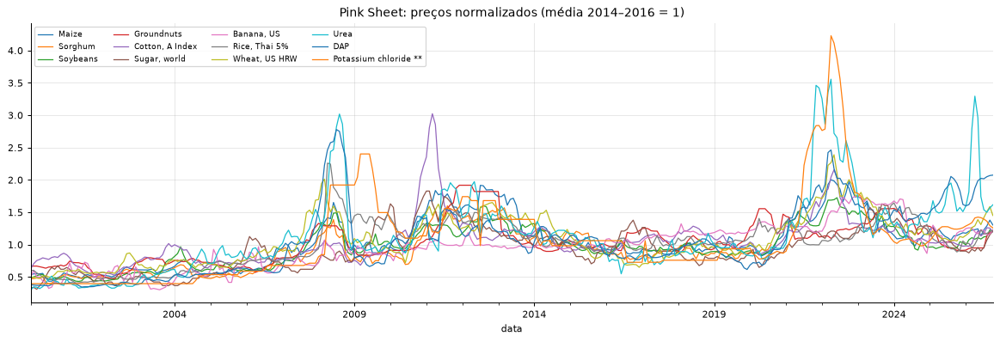

In [141]:
linhas = []
for c in sel:
    s = pk_largo.loc["1990":, c].dropna()
    anual = s.resample("YE").mean()
    t = mk.original_test(anual.values)
    linhas.append({"commodity": c, "tendência": t.trend, "p": round(t.p, 4),
                   "Sen (USD/ano)": round(t.slope, 2), "Sen % ao ano": round(100 * t.slope / anual.mean(), 2)})
print(pd.DataFrame(linhas).to_string(index=False))

fig, ax = plt.subplots(figsize=(13, 4.5))
norm = pk_largo.loc["2000":, sel] / pk_largo.loc["2014":"2016", sel].mean()
norm.plot(ax=ax, lw=1)
ax.set_title("Pink Sheet: preços normalizados (média 2014–2016 = 1)")
ax.legend(ncol=4, fontsize=7)
plt.tight_layout(); plt.show()

## 7. Variabilidade, extremos e correlação entre mercados

- Volatilidade anualizada = desvio-padrão dos retornos log mensais × √12.
- Pior queda (drawdown) e maior alta em 12 meses.
- Correlação de retornos: culturas pouco correlacionadas diversificam a renda da rotação.
- Fertilizantes (ureia, DAP, KCl) × grãos: os choques de 2021–2022 e de mar–mai/2026 mostram o valor econômico das leguminosas, que fixam nitrogênio.

                       volatilidade anual  pior drawdown  maior alta 12m
commodity                                                               
Banana, US                           0.49          -0.70            1.26
Urea                                 0.42          -0.82            2.68
Sugar, world                         0.25          -0.68            1.07
Potassium chloride **                0.25          -0.77            2.48
DAP                                  0.23          -0.78            1.70
Groundnuts                           0.22          -0.71            1.00
Sorghum                              0.21          -0.61            1.11
Wheat, US HRW                        0.21          -0.68            1.21
Rice, Thai 5%                        0.20          -0.61            1.87
Maize                                0.20          -0.63            1.12
Cotton, A Index                      0.19          -0.72            1.68
Soybeans                             0.18          

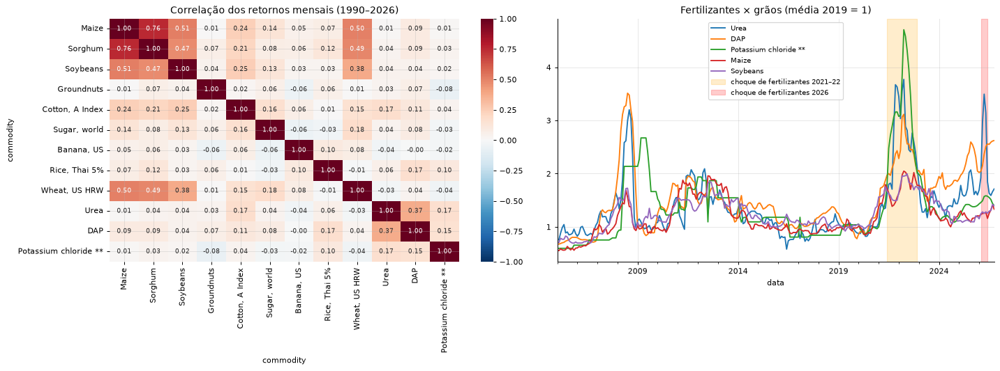

Razão ureia/milho (USD/t ÷ USD/t): média 2000–2020 = 1.51; pico = 4.00 em 2026-04; atual = 1.85


In [142]:
ret = np.log(pk_largo.loc["1990":, sel]).diff()
vol = (ret.std() * np.sqrt(12)).rename("volatilidade anual")
dd = (pk_largo.loc["1990":, sel] / pk_largo.loc["1990":, sel].cummax() - 1).min().rename("pior drawdown")
alta12 = (pk_largo.loc["1990":, sel].pct_change(12)).max().rename("maior alta 12m")
print(pd.concat([vol, dd, alta12], axis=1).round(2).sort_values("volatilidade anual", ascending=False).to_string())

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(ret.corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", ax=ax[0], annot_kws={"size": 7})
ax[0].set_title("Correlação dos retornos mensais (1990–2026)")
fert = pk_largo.loc["2005":, [c for c in ["Urea", "DAP", "Potassium chloride **", "Maize", "Soybeans"] if c in pk_largo]]
(fert / fert.loc["2019"].mean()).plot(ax=ax[1])
ax[1].axvspan("2021-06", "2022-12", color="orange", alpha=0.2, label="choque de fertilizantes 2021–22")
ax[1].axvspan("2026-02", "2026-06", color="red", alpha=0.2, label="choque de fertilizantes 2026")
ax[1].set_title("Fertilizantes × grãos (média 2019 = 1)")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

razao_ureia_milho = (pk_largo["Urea"] / pk_largo["Maize"]).loc["2000":]
print(f"Razão ureia/milho (USD/t ÷ USD/t): média 2000–2020 = {razao_ureia_milho.loc[:'2020'].mean():.2f}; "
      f"pico = {razao_ureia_milho.max():.2f} em {razao_ureia_milho.idxmax():%Y-%m}; atual = {razao_ureia_milho.dropna().iloc[-1]:.2f}")

### Extremos de produção no Brasil — anos de quebra
Desvio da produtividade em relação à tendência (LOESS simples por média móvel de 7 anos). Anos com desvio < −15 % são "quebras".

In [143]:
quebras = []
for item in ["Maize (corn)", "Beans, dry", "Cassava, fresh", "Seed cotton, unginned", "Sorghum", "Rice", "Soya beans"]:
    s = rend[(rend["Area"] == "Brazil") & (rend["Item"] == item)].set_index("Year")["Value"].sort_index()
    tend = s.rolling(7, center=True, min_periods=3).median()
    desvio = s / tend - 1
    for ano, v in desvio[desvio < -0.15].items():
        quebras.append({"cultura": item, "ano": ano, "desvio %": round(100 * v, 1)})
print(pd.DataFrame(quebras).sort_values(["ano", "cultura"]).to_string(index=False))

              cultura  ano  desvio %
           Soya beans 1964     -24.8
           Soya beans 1968     -22.5
              Sorghum 1973     -23.7
Seed cotton, unginned 1976     -17.9
         Maize (corn) 1978     -23.6
           Soya beans 1978     -29.0
              Sorghum 1979     -25.4
           Soya beans 1979     -28.2
           Beans, dry 1983     -16.5
           Soya beans 1986     -19.0
           Beans, dry 1987     -19.5
           Soya beans 1991     -21.2
              Sorghum 2000     -19.2
         Maize (corn) 2016     -18.4
              Sorghum 2016     -27.5


## 8. Insights e ideias para o produto

1. **O AMS não serve para um produto mundial.** Só EUA, com chave e formato instável. A camada de mercado global deve vir do **FAOSTAT** (preço ao produtor e produtividade por país) com o **Pink Sheet** como sinal internacional mensal, e o AMS como plugin opcional nos EUA.
2. **Renda por hectare × risco** (gráfico da seção 4) é diretamente um eixo do motor de rotação: `receita esperada = produtividade atingível (GAEZ, por pixel) × preço ao produtor (FAOSTAT, por país)`, com o CV do preço como penalidade de risco.
3. **Diversificação de renda:** a matriz de correlação de retornos mostra pares pouco correlacionados (ex.: banana × grãos; açúcar × fertilizantes). Uma rotação com culturas de baixa correlação reduz a variância da renda — dá para pontuar isso como um "índice de portfólio" da rotação.
4. **Choques de fertilizantes:** a razão ureia/milho (média 1,5 em 2000–2020) chegou a 3,6 em nov/2021 e a **4,0 em abr/2026** — ou seja, o choque se repetiu este ano. Leguminosas (feijão-caupi, guandu, amendoim) que fixam N viram **seguro contra preço de insumo** — argumento econômico, além do agronômico, para incluí-las na rotação.
5. **Sazonalidade de preço** (FAOSTAT mensal do Brasil) indica janelas de venda: o produtor que colhe fora do pico de oferta ganha mais. O motor pode sugerir **datas de plantio que deslocam a colheita** para meses de preço mais alto, desde que caibam na janela climática (POWER/IMERG/ZARC).
6. **Anos de quebra** aparecem nas séries nacionais; para o Ceará, as quebras são muito mais fortes (seca 2012–2017). Ideia: cruzar com IMERG/SMAP para mostrar que a "renda esperada" precisa ser ajustada pelo risco climático local.

**Limitações:** FAOSTAT é anual e nacional (não reflete o preço local no Ceará); Pink Sheet é nominal em USD (deflacionar para comparar décadas); CONAB (preços por UF) ficou inacessível daqui — certificado TLS do portal com nome errado.

# 13. Bases de ligação: teleconexões (ENSO e Atlântico) e produção agrícola do Ceará (IBGE PAM)

Estas bases não estão na lista do desafio, mas são as que **ligam o clima observado pela NASA à safra real**.

**Ficha técnica — índices climáticos**

| Índice | Provedor | O que mede | Período | Acesso |
|---|---|---|---|---|
| ONI | NOAA CPC (ERSSTv5) | anomalia de TSM no Niño 3.4, média de 3 meses (El Niño ≥ +0,5; La Niña ≤ −0,5) | 1950 → set/2026 | aberto |
| TNA | NOAA PSL (HadISST1.1) | anomalia de TSM do Atlântico tropical norte (5,5°N–23,5°N) | 1948 → set/2026 | aberto |
| TSA | NOAA PSL (HadISST1.1) | anomalia de TSM do Atlântico tropical sul (0–20°S) | 1948 → set/2026 | aberto |
| Dipolo | calculado | TNA − TSA: positivo empurra a Zona de Convergência Intertropical para o norte → **quadra seca no Ceará** | 1948 → set/2026 | — |

**Ficha técnica — IBGE PAM (Produção Agrícola Municipal)**

| Item | Valor |
|---|---|
| Provedor | IBGE, API SIDRA, tabelas 1612 (lavouras temporárias, 45 produtos) e 1613 (permanentes, 42 produtos) |
| Recorte | 184 municípios do Ceará + 9 UFs do Nordeste |
| Variáveis | área plantada / destinada à colheita (ha, desde 1988), área colhida (ha), quantidade (t), rendimento (kg/ha), valor (mil R$; moedas antigas antes de 1994) |
| Resolução | município, anual; 1974 → 2025 |
| Acesso | aberto, sem login; licença de dados públicos do IBGE |
| Cobertura | **somente Brasil** (equivalentes globais: FAOSTAT por país, GDHY em grade, estatísticas nacionais como USDA NASS) |

In [144]:
import sys
import warnings

sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
from comum import *  # noqa

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymannkendall as mk
from scipy import stats

warnings.filterwarnings("ignore")
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
idx = pd.read_parquet(DERIV / "indices_clima_mensal.parquet").pivot_table(index="data", columns="variavel", values="valor")
pam = pd.read_parquet(DADOS / "ibge_pam" / "pam_ce_municipios.parquet")
pam_ne = pd.read_parquet(DADOS / "ibge_pam" / "pam_ne_estados.parquet")
prod = pam[pam.cod_produto != "0"]
print("Índices:", idx.columns.tolist(), idx.index.min().date(), "→", idx.index.max().date())
print("PAM Ceará:", len(pam), "linhas |", prod.produto.nunique(), "produtos |", pam.cod_local.nunique(), "municípios |", pam.ano.min(), "–", pam.ano.max())

Índices: ['DIPOLO_TNA_menos_TSA', 'ONI', 'TNA', 'TSA'] 1948-01-01 → 2026-09-01
PAM Ceará: 4162080 linhas | 85 produtos | 184 municípios | 1974 – 2025


## 13.1 Cobertura e qualidade
Os índices são séries únicas de teleconexão; "cobertura global" não se aplica. O que importa é que eles são
**calculados para o mundo todo** e servem de preditor em qualquer região onde ENSO/Atlântico pesam. O PAM é só
brasileiro: para o produto mundial, a camada equivalente é o FAOSTAT (país) ou o GDHY (grade de 0,5°).

Códigos do SIDRA no PAM do Ceará (fração das linhas):


valor_txt
-         0.515
...       0.333
número    0.143
..        0.009



Anos com valores positivos por variável:
                                min   max
variavel                                
Quantidade produzida          1974  2025
Rendimento médio da produção  1974  2025
Valor da produção             1974  2025
Área colhida                  1974  2025
Área destinada à colheita     1988  2025
Área plantada                 1988  2025



Municípios por ano (mín/máx): {'min': 184, 'max': 184}


Rendimentos ≤ 0 ou ausentes com área colhida > 0: 1


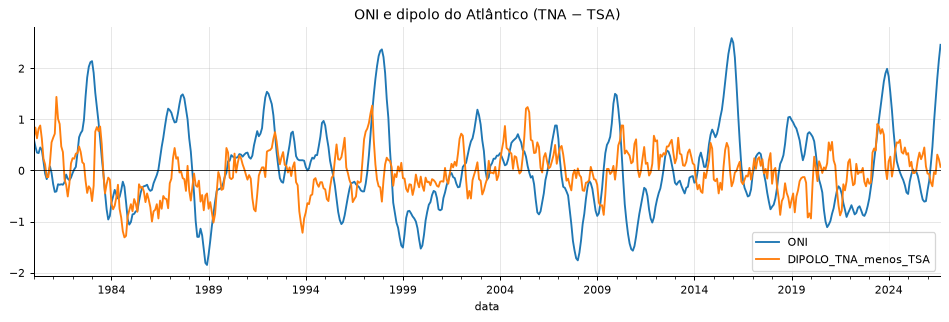

Últimos valores (set/2026): {'DIPOLO_TNA_menos_TSA': 0.07, 'ONI': 2.46, 'TNA': 0.64, 'TSA': 0.57}


In [145]:
print("Códigos do SIDRA no PAM do Ceará (fração das linhas):")
print((pam.valor_txt.where(pam.valor_txt.isin(["-", "...", "..", "X"]), "número").value_counts(normalize=True)).round(3).to_string())
cob = prod[prod.valor > 0].groupby("variavel").ano.agg(["min", "max"])
print("\nAnos com valores positivos por variável:\n", cob.to_string())
print("\nMunicípios por ano (mín/máx):", prod.groupby("ano").cod_local.nunique().agg(["min", "max"]).to_dict())
r = prod[prod.variavel == "Rendimento médio da produção"]
print("Rendimentos ≤ 0 ou ausentes com área colhida > 0:",
      int(prod.pivot_table(index=["cod_local", "ano", "produto"], columns="variavel", values="valor")
          .pipe(lambda d: ((d["Área colhida"] > 0) & ~(d["Rendimento médio da produção"] > 0)).sum())))
fig, ax = plt.subplots(figsize=(13, 3.6))
for v in ["ONI", "DIPOLO_TNA_menos_TSA"]:
    idx[v].loc["1980":].plot(ax=ax, label=v)
ax.axhline(0, color="k", lw=0.6); ax.legend(); ax.set_title("ONI e dipolo do Atlântico (TNA − TSA)"); plt.show()
print("Últimos valores (set/2026):", idx.iloc[-1].round(2).to_dict())

## 13.2 O que o Ceará planta (estatística descritiva, 2019–2025)

                              área média ha  % da área  valor médio mil R$     R$/ha
produto                                                                             
Milho (em grão)                    565437.0       39.7            488495.9     863.9
Feijão (em grão)                   362996.9       25.5            414757.4    1142.6
Castanha de caju                   275946.3       19.4            325393.0    1179.2
Mandioca                            67883.7        4.8            398621.9    5872.1
Coco-da-baía*                       41643.7        2.9            345537.4    8297.5
Banana (cacho)                      36627.6        2.6            610239.9   16660.7
Fava (em grão)                      14457.0        1.0             37159.0    2570.3
Cana-de-açúcar                       9112.6        0.6            105817.7   11612.3
Maracujá                             6917.6        0.5            530791.0   76730.8
Batata-doce                          6692.1        0.5           

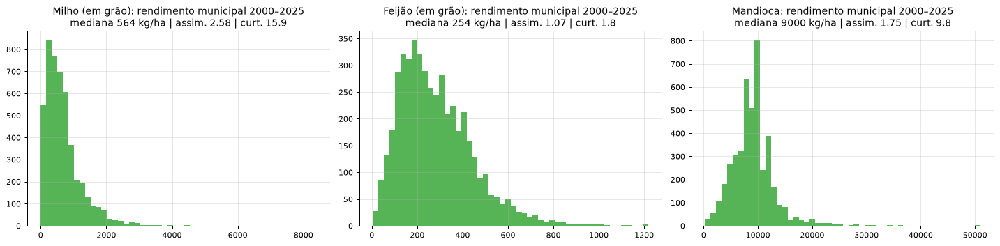

In [146]:
area_v = ["Área plantada", "Área destinada à colheita"]
rec = prod[prod.ano.between(2019, 2025)]
area = rec[rec.variavel.isin(area_v)].groupby("produto").valor.sum() / 7
valor = rec[rec.variavel == "Valor da produção"].groupby("produto").valor.sum() / 7
top = pd.DataFrame({"área média ha": area, "% da área": 100 * area / area.sum(), "valor médio mil R$": valor,
                    "R$/ha": 1000 * valor / area}).sort_values("área média ha", ascending=False)
print(top.head(15).round(1).to_string())
print(f"\nMilho + feijão + caju = {top['% da área'].iloc[:3].sum():.0f}% da área cultivada")

rend = prod[(prod.variavel == "Rendimento médio da produção") & (prod.valor > 0)]
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for a, c in zip(axs, ["Milho (em grão)", "Feijão (em grão)", "Mandioca"]):
    x = rend[(rend.produto == c) & rend.ano.between(2000, 2025)].valor
    a.hist(x, bins=50, color="tab:green", alpha=0.8)
    a.set_title(f"{c}: rendimento municipal 2000–2025\nmediana {x.median():.0f} kg/ha | assim. {stats.skew(x):.2f} | curt. {stats.kurtosis(x):.1f}")
plt.tight_layout(); plt.show()

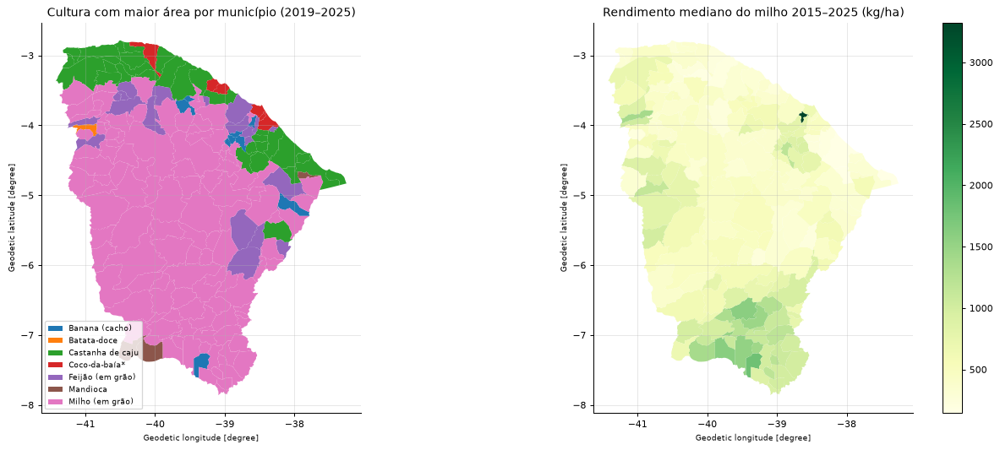

In [147]:
mun = municipios_ce_gdf()
mun["cod_local"] = mun["codarea"].astype(str)
a_mun = rec[rec.variavel.isin(area_v)].groupby(["cod_local", "produto"]).valor.sum().reset_index()
princ = a_mun.sort_values("valor").groupby("cod_local").tail(1).set_index("cod_local")["produto"]
rm = rend[(rend.produto == "Milho (em grão)") & rend.ano.between(2015, 2025)].groupby("cod_local").valor.median()
g = mun.merge(princ.rename("principal"), left_on="cod_local", right_index=True, how="left") \
       .merge(rm.rename("rend_milho"), left_on="cod_local", right_index=True, how="left")
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
g.plot(column="principal", categorical=True, legend=True, ax=axs[0], cmap="tab10",
       legend_kwds={"loc": "lower left", "fontsize": 7})
axs[0].set_title("Cultura com maior área por município (2019–2025)")
g.plot(column="rend_milho", cmap="YlGn", legend=True, ax=axs[1], missing_kwds={"color": "0.85"})
axs[1].set_title("Rendimento mediano do milho 2015–2025 (kg/ha)")
plt.tight_layout(); plt.show()

## 13.3 Tendências de longo prazo e o colapso do algodão

                     cultura             variável tendência MK    p  Sen por ano
             Milho (em grão)         Área colhida   increasing 0.01      2979.84
             Milho (em grão) Quantidade produzida   increasing 0.01      4916.07
             Milho (em grão)     rendimento kg/ha   increasing 0.01         6.50
            Feijão (em grão)         Área colhida     no trend 0.40      -990.56
            Feijão (em grão) Quantidade produzida     no trend 0.83      -150.89
            Feijão (em grão)     rendimento kg/ha     no trend 0.89        -0.05
                    Mandioca         Área colhida   decreasing 0.00     -1457.67
                    Mandioca Quantidade produzida   decreasing 0.00    -10598.04
                    Mandioca     rendimento kg/ha     no trend 0.15        33.23
            Castanha de caju         Área colhida   increasing 0.00      5890.14
            Castanha de caju Quantidade produzida   increasing 0.00      1704.56
            Castanha de caju

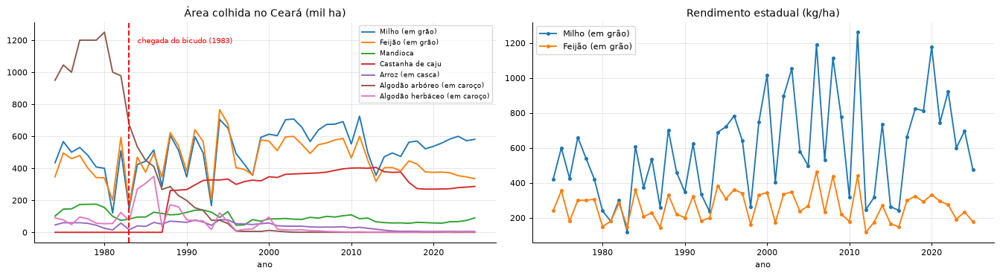

Algodão arbóreo: 1250 mil ha (pico até 1982) → 55 mil ha (1995) → 0 ha (2016)


In [148]:
ce = prod.groupby(["ano", "produto", "variavel"]).valor.sum().unstack("variavel")
culturas = ["Milho (em grão)", "Feijão (em grão)", "Mandioca", "Castanha de caju", "Arroz (em casca)",
            "Algodão arbóreo (em caroço)", "Algodão herbáceo (em caroço)", "Cana-de-açúcar", "Banana (cacho)", "Coco-da-baía*"]
res = []
for c in culturas:
    s = ce.xs(c, level="produto")
    for v in ["Área colhida", "Quantidade produzida"]:
        x = s[v].loc[1974:2025].dropna()
        rr = mk.original_test(x.values)
        res.append((c, v, rr.trend, round(rr.p, 4), rr.slope))
    y = (s["Quantidade produzida"] * 1000 / s["Área colhida"]).replace([np.inf], np.nan).loc[1974:2025].dropna()
    rr = mk.original_test(y.values)
    res.append((c, "rendimento kg/ha", rr.trend, round(rr.p, 4), rr.slope))
print(pd.DataFrame(res, columns=["cultura", "variável", "tendência MK", "p", "Sen por ano"]).round(2).to_string(index=False))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.2))
for c in culturas[:7]:
    (ce.xs(c, level="produto")["Área colhida"] / 1e3).plot(ax=axs[0], label=c)
axs[0].set_title("Área colhida no Ceará (mil ha)"); axs[0].legend(fontsize=7)
axs[0].axvline(1983, color="r", ls="--"); axs[0].text(1984, axs[0].get_ylim()[1] * 0.9, "chegada do bicudo (1983)", color="r", fontsize=8)
for c in ["Milho (em grão)", "Feijão (em grão)"]:
    s = ce.xs(c, level="produto"); (s["Quantidade produzida"] * 1000 / s["Área colhida"]).plot(ax=axs[1], marker=".", label=c)
axs[1].set_title("Rendimento estadual (kg/ha)"); axs[1].legend(); plt.tight_layout(); plt.show()
alg = ce.xs("Algodão arbóreo (em caroço)", level="produto")["Área colhida"]
print(f"Algodão arbóreo: {alg.loc[1974:1982].max()/1e3:.0f} mil ha (pico até 1982) → {alg.loc[1995]/1e3:.0f} mil ha (1995) → {alg.loc[2016]:.0f} ha (2016)")

## 13.4 Quebra de safra: perda de área e rendimento nas secas

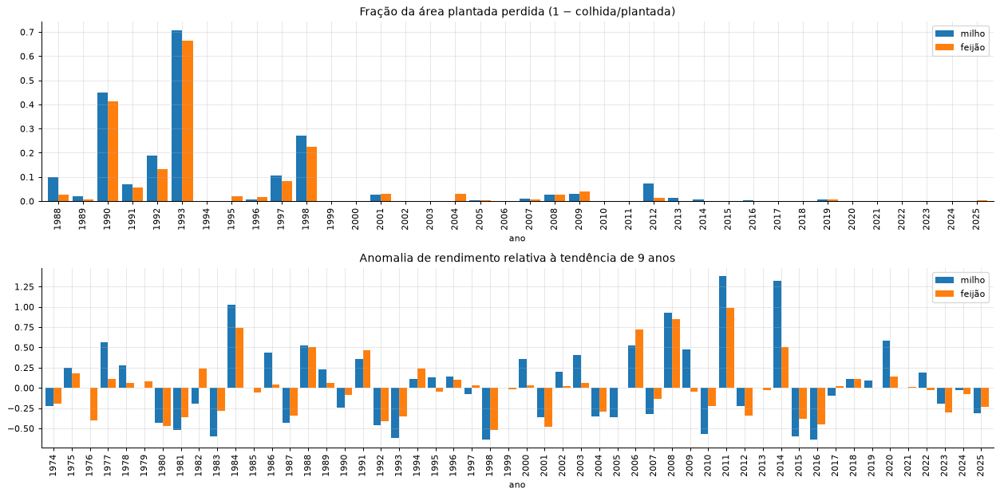

Piores anos (anomalia de rendimento do milho): {1998: -0.64, 2016: -0.64, 1993: -0.62, 2015: -0.6, 1983: -0.6, 2010: -0.57, 1981: -0.52, 1992: -0.46}
Perda de área ≥ 20% (milho): {1990: 0.45, 1993: 0.71, 1998: 0.27}
Perda média de área do milho 1988–1999: 0.16 | 2000–2025: 0.008 → a partir de ~2000 a perda deixa de aparecer na área e aparece só no rendimento (mudança de método/registro).


In [149]:
mz = ce.xs("Milho (em grão)", level="produto"); fj = ce.xs("Feijão (em grão)", level="produto")
perda = pd.DataFrame({"milho": 1 - mz["Área colhida"] / mz["Área plantada"], "feijão": 1 - fj["Área colhida"] / fj["Área plantada"]}).loc[1988:]
rend_ce = pd.DataFrame({"milho": mz["Quantidade produzida"] * 1000 / mz["Área colhida"],
                        "feijão": fj["Quantidade produzida"] * 1000 / fj["Área colhida"]}).loc[1974:]
# anomalia de rendimento relativa à tendência (LOWESS-like via mediana móvel de 9 anos)
tend = rend_ce.rolling(9, center=True, min_periods=5).median()
anom_r = rend_ce / tend - 1
fig, axs = plt.subplots(2, 1, figsize=(14, 7))
perda.plot.bar(ax=axs[0], width=0.85); axs[0].set_title("Fração da área plantada perdida (1 − colhida/plantada)")
anom_r.plot.bar(ax=axs[1], width=0.85); axs[1].set_title("Anomalia de rendimento relativa à tendência de 9 anos")
plt.tight_layout(); plt.show()
print("Piores anos (anomalia de rendimento do milho):", anom_r.milho.nsmallest(8).round(2).to_dict())
print("Perda de área ≥ 20% (milho):", perda.milho[perda.milho >= 0.2].round(2).to_dict())
print("Perda média de área do milho 1988–1999:", round(perda.milho.loc[1988:1999].mean(), 3),
      "| 2000–2025:", round(perda.milho.loc[2000:2025].mean(), 3),
      "→ a partir de ~2000 a perda deixa de aparecer na área e aparece só no rendimento (mudança de método/registro).")

## 13.5 Clima × chuva × safra: a cadeia de teleconexão
Hipótese física conhecida: El Niño (ONI > 0) e dipolo positivo (Atlântico norte mais quente) deslocam a ZCIT para
o norte e secam a quadra chuvosa do Ceará. Testamos a cadeia **índice (dez–mar) → chuva fev–mai (POWER) →
rendimento do milho/feijão (PAM)**.

Correlação de Spearman (1981–2025):
                   ONI_dez_mar  dipolo_fev_mai  dipolo_jan  anom_rend_milho  anom_rend_feijao  chuva_fev_mai_mm
ONI_dez_mar              1.00            0.32       -0.12            -0.52             -0.42             -0.46
dipolo_fev_mai           0.32            1.00        0.60            -0.61             -0.42             -0.58
dipolo_jan              -0.12            0.60        1.00            -0.19             -0.10             -0.31
anom_rend_milho         -0.52           -0.61       -0.19             1.00              0.86              0.75
anom_rend_feijao        -0.42           -0.42       -0.10             0.86              1.00              0.62
chuva_fev_mai_mm        -0.46           -0.58       -0.31             0.75              0.62              1.00
anos com todos os dados: 45


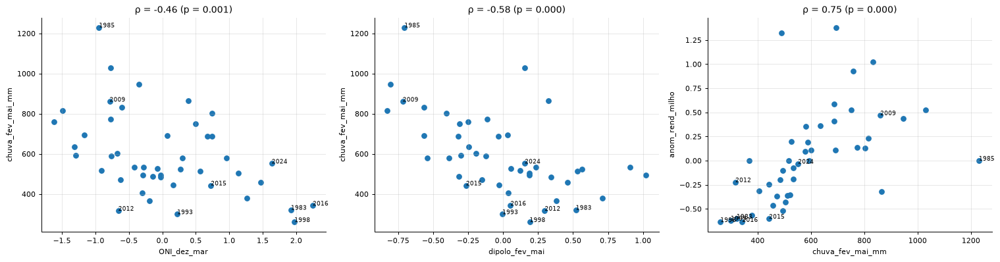

preditores ['ONI_dez_mar']: R² fora da amostra = 0.15 | acerto de tercil = 0.44 (acaso = 0,33)
preditores ['dipolo_fev_mai']: R² fora da amostra = 0.25 | acerto de tercil = 0.47 (acaso = 0,33)
preditores ['ONI_dez_mar', 'dipolo_fev_mai']: R² fora da amostra = 0.33 | acerto de tercil = 0.47 (acaso = 0,33)


preditores ['ONI_dez_mar', 'dipolo_jan']: R² fora da amostra = 0.26 | acerto de tercil = 0.36 (acaso = 0,33)
Obs.: 'dipolo_fev_mai' é concomitante à quadra (não é previsão); 'dipolo_jan' e ONI dez–mar são conhecidos antes/no início.


In [150]:
def media_meses(s, meses):
    s = s.copy()
    df = s.to_frame("v"); df["ano"] = df.index.year; df["m"] = df.index.month
    return df[df.m.isin(meses)].groupby("ano").v.mean()

# ONI de dez–mar: desloca 1 mês para que dezembro conte no ano da quadra seguinte
o = idx["ONI"].copy(); o.index = o.index + pd.DateOffset(months=1)
oni_djf = media_meses(o, [1, 2, 3, 4]).rename("ONI_dez_mar")
dip_fmam = media_meses(idx["DIPOLO_TNA_menos_TSA"], [2, 3, 4, 5]).rename("dipolo_fev_mai")
dip_jan = media_meses(idx["DIPOLO_TNA_menos_TSA"], [1]).rename("dipolo_jan")
tab = pd.concat([oni_djf, dip_fmam, dip_jan, anom_r.milho.rename("anom_rend_milho"), anom_r["feijão"].rename("anom_rend_feijao")], axis=1)

p = DERIV / "power_ce_mensal.parquet"
if p.exists():
    pw = pd.read_parquet(p)
    pr = pw[pw.variavel == "PRECTOTCORR"].set_index("data")["valor"]
    q = pr[pr.index.month.isin([2, 3, 4, 5])]  # já em mm/mês (soma mensal)
    chuva = q.groupby(q.index.year).sum(min_count=4)
    tab["chuva_fev_mai_mm"] = chuva
tab = tab.loc[1981:2025]
cor = tab.corr(method="spearman")
print("Correlação de Spearman (1981–2025):\n", cor.round(2).to_string())
n = tab.dropna().shape[0]
print("anos com todos os dados:", n)

if "chuva_fev_mai_mm" in tab:
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
    for a, (x, y) in zip(axs, [("ONI_dez_mar", "chuva_fev_mai_mm"), ("dipolo_fev_mai", "chuva_fev_mai_mm"), ("chuva_fev_mai_mm", "anom_rend_milho")]):
        d = tab[[x, y]].dropna(); rr = stats.spearmanr(d[x], d[y])
        a.scatter(d[x], d[y]);
        for ano, row in d.iterrows():
            if ano in (1983, 1993, 1998, 2012, 2015, 2016, 1985, 2009, 2024):
                a.annotate(str(ano), (row[x], row[y]), fontsize=7)
        a.set_xlabel(x); a.set_ylabel(y); a.set_title(f"ρ = {rr.correlation:.2f} (p = {rr.pvalue:.3f})")
    plt.tight_layout(); plt.show()

    # modelo simples de previsão da quadra: chuva ~ ONI + dipolo (validação deixando um ano de fora)
    d = tab[["ONI_dez_mar", "dipolo_fev_mai", "dipolo_jan", "chuva_fev_mai_mm"]].dropna()
    from sklearn.linear_model import LinearRegression
    from sklearn.model_selection import LeaveOneOut, cross_val_predict
    for cols in (["ONI_dez_mar"], ["dipolo_fev_mai"], ["ONI_dez_mar", "dipolo_fev_mai"], ["ONI_dez_mar", "dipolo_jan"]):
        pred = cross_val_predict(LinearRegression(), d[cols], d.chuva_fev_mai_mm, cv=LeaveOneOut())
        r2 = 1 - ((d.chuva_fev_mai_mm - pred) ** 2).sum() / ((d.chuva_fev_mai_mm - d.chuva_fev_mai_mm.mean()) ** 2).sum()
        tercil = pd.qcut(d.chuva_fev_mai_mm, 3, labels=False); tp = pd.qcut(pred, 3, labels=False)
        print(f"preditores {cols}: R² fora da amostra = {r2:.2f} | acerto de tercil = {(tercil.values == tp).mean():.2f} (acaso = 0,33)")
    print("Obs.: 'dipolo_fev_mai' é concomitante à quadra (não é previsão); 'dipolo_jan' e ONI dez–mar são conhecidos antes/no início.")

In [151]:
# ENSO de 2026: o que esperar para a quadra de 2027?
on = idx["ONI"].loc["2025":]
print("ONI recente:", on.round(2).to_dict())
if "chuva_fev_mai_mm" in tab:
    forte = tab[tab.ONI_dez_mar >= 1.0]
    print("\nQuadras após El Niño forte (ONI dez–mar ≥ 1,0):")
    print(forte[["ONI_dez_mar", "chuva_fev_mai_mm", "anom_rend_milho", "anom_rend_feijao"]].round(2).to_string())
    print("Chuva fev–mai média nesses anos:", round(forte.chuva_fev_mai_mm.mean()), "mm vs climatologia", round(tab.chuva_fev_mai_mm.mean()), "mm")

ONI recente: {Timestamp('2025-01-01 00:00:00'): -0.46, Timestamp('2025-02-01 00:00:00'): -0.22, Timestamp('2025-03-01 00:00:00'): -0.08, Timestamp('2025-04-01 00:00:00'): 0.02, Timestamp('2025-05-01 00:00:00'): -0.04, Timestamp('2025-06-01 00:00:00'): -0.02, Timestamp('2025-07-01 00:00:00'): -0.11, Timestamp('2025-08-01 00:00:00'): -0.26, Timestamp('2025-09-01 00:00:00'): -0.43, Timestamp('2025-10-01 00:00:00'): -0.57, Timestamp('2025-11-01 00:00:00'): -0.61, Timestamp('2025-12-01 00:00:00'): -0.6, Timestamp('2026-01-01 00:00:00'): -0.39, Timestamp('2026-02-01 00:00:00'): -0.21, Timestamp('2026-03-01 00:00:00'): 0.11, Timestamp('2026-04-01 00:00:00'): 0.46, Timestamp('2026-05-01 00:00:00'): 0.95, Timestamp('2026-06-01 00:00:00'): 1.39, Timestamp('2026-07-01 00:00:00'): 1.8, Timestamp('2026-08-01 00:00:00'): 2.16, Timestamp('2026-09-01 00:00:00'): 2.46}

Quadras após El Niño forte (ONI dez–mar ≥ 1,0):
      ONI_dez_mar  chuva_fev_mai_mm  anom_rend_milho  anom_rend_feijao
ano            

## 13.6 Insights e uso no produto

- **O Ceará planta três coisas**: milho (40%), feijão (26%) e caju (19%) somam **85% da área** em 2019–2025; milho e
  feijão são de sequeiro e, em geral, consorciados.
  Na prática, a "rotação atual" típica é **milho+feijão todo ano na mesma área**, um ótimo caso para o desafio: a
  ferramenta compara essa base com alternativas (sorgo, feijão-caupi solteiro, palma forrageira, gergelim, adubos
  verdes, pousio melhorado).
- **O colapso do algodão arbóreo** (de ~1,2 milhão de ha antes de 1983 a zero em 2016) é o caso histórico mais forte do
  Nordeste de praga (bicudo) combinada com seca destruindo um sistema produtivo. É argumento direto para a parte
  de "quebrar ciclos de pragas" com rotação e diversificação.
- **Quebra de safra é climática e previsível em parte**. A cadeia fecha com números (Spearman, 1981–2025):
  chuva fev–mai × anomalia de rendimento do milho **ρ = 0,75** (feijão 0,62); ONI dez–mar × chuva **ρ = −0,46**;
  dipolo fev–mai × chuva **ρ = −0,58**. Nas **7 quadras após El Niño forte** (ONI ≥ 1,0: 1983, 1987, 1992, 1998, 2010,
  2016, 2024) a chuva fev–mai média foi **402 mm contra 593 mm** da climatologia (−32%), e o milho rendeu de 43% a
  64% abaixo da tendência em 6 delas (2024 foi a exceção).
- **O ONI de set/2026 está em +2,46** (El Niño forte e subindo), o que pede **alerta para a quadra de 2027**. Uma
  rotação com culturas tolerantes à seca (sorgo, caupi precoce, palma forrageira) deve subir no ranking do app quando
  o índice estiver assim. É o gancho perfeito para a apresentação: "o app já diria hoje o que plantar em 2027".
- **Previsibilidade real, mas modesta**: só com o ONI de dez–mar, o tercil da quadra acerta 44% (acaso 33%;
  R² fora da amostra 0,15). Com o dipolo concomitante chega a R² 0,33, mas esse dado só existe durante a quadra.
  O produto deve falar em **probabilidades por tercil**, nunca em certeza.
- **Mudança de registro no PAM**: até 1999 a seca aparece como perda de área (até 71% do milho em 1993); depois de
  2000 a área colhida ≈ plantada e a perda aparece só no rendimento. Qualquer modelo treinado com o PAM deve usar
  **rendimento** como alvo e tratar essa quebra de série.
- **Ideias de ML**:
  1. *Previsão de tercil da quadra chuvosa* com ONI/dipolo (regressão logística ordinal ou gradient boosting);
     validação deixando um ano de fora, como acima.
  2. *Modelo de rendimento municipal* (painel 184 municípios × 50 anos) com chuva, ET0, veranicos e Tmax do POWER,
     NDVI MODIS e solo: gradient boosting com efeitos fixos do município, ou rede com *embedding* de município.
     Esse modelo vira o **"simulador de rotação"**: prevê o rendimento de cada cultura sob o clima de cada cenário.
  3. *Recomendador* que transforma a previsão de quadra em ranking de rotação, sempre mostrando a incerteza
     (intervalo de previsão) e os anos análogos ("esta quadra se parece com 1998 e 2016").

## 14. USDA Cropland Data Layer (CDL) — estudo de rotação real (somente EUA)

**Ficha técnica**

| Item | Valor |
|---|---|
| Provedor | USDA NASS (Serviço Nacional de Estatística Agrícola dos EUA) |
| Conteúdo | **Qual cultura está em cada pixel, a cada ano** (~130 classes) |
| Resolução | 30 m (2008–2025); 10 m também a partir de 2024 |
| Período | Nacional desde 2008 (alguns estados desde 1997) |
| Cobertura | **EUA contíguos (CONUS)**; o Havaí vem num arquivo à parte |
| Acesso | Download direto do NASS (zip por ano, ~1,7–2 GB); o CropScape agora pede cadastro |
| Arquivos baixados | 2023, 2024 e 2025 (30 m) + camada de **frequência de culturas 2008–2025** |

Ficou numa pasta separada (`E:/campeonato-nasa/estudo_cdl`) porque **não é global**. O valor dele para nós é
**aprender como rotações reais se comportam** (ex.: milho→soja), para construir o "prior" do motor de rotação e testar
o método num lugar com rótulos de verdade.

Para ler os rasters nacionais sem descompactar 2,6 GB por ano, foram recortadas 6 janelas de 40 × 40 km
(`scripts/recortar_cdl.py`), mais uma visão nacional reduzida a 960 m.

In [152]:
import re
import sys
import warnings
import zipfile
from collections import Counter

sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from comum import ESTUDO_CDL, paises_gdf

REC = ESTUDO_CDL / "recortes"
REGIOES = {
    "iowa_story": "Corn Belt: milho-soja",
    "kansas_ogallala": "Ogallala: milho irrigado, trigo, sorgo",
    "california_fresno": "Vale Central: perenes, algodão, tomate",
    "mississippi_delta": "Delta: soja, algodão, arroz",
    "north_dakota_cass": "Planícies do norte: trigo, soja, milho, girassol",
    "texas_lubbock": "Semiárido: algodão de sequeiro (análogo ao sertão)",
}
ANOS = [a for a in (2023, 2024, 2025) if (REC / f"iowa_story_{a}.tif").exists()]
print("anos recortados disponíveis:", ANOS)

# Legenda: culturas (do metadado oficial) + classes não agrícolas padrão do CDL
NAO_AGRI = {0: "Sem dado", 61: "Pousio/ocioso", 63: "Floresta", 64: "Arbustos", 65: "Barren", 81: "Nuvem", 82: "Urbano",
            83: "Água", 87: "Áreas úmidas", 88: "Não agrícola", 92: "Aquicultura", 111: "Água aberta", 112: "Gelo/neve",
            121: "Urbano aberto", 122: "Urbano baixa", 123: "Urbano média", 124: "Urbano alta", 131: "Solo exposto",
            141: "Floresta decídua", 142: "Floresta perene", 143: "Floresta mista", 152: "Arbustos", 176: "Pastagem/campo",
            190: "Áreas úmidas lenhosas", 195: "Áreas úmidas herbáceas"}

anos recortados disponíveis: [2023, 2024, 2025]


### 14.1 Qualidade: acurácia por cultura (tabela oficial do NASS, CDL 2024)
- **Acurácia do produtor:** fração dos pixels que realmente são da cultura e foram classificados como ela
  (1 − omissão).
- **Acurácia do usuário:** fração dos pixels classificados como a cultura que são mesmo dela (1 − comissão).

Culturas grandes (milho, soja) passam de 90%; culturas pequenas ficam bem abaixo. **Rótulo do CDL não é verdade
absoluta**, e isso importa se ele for usado para treinar modelos.

107 classes com acurácia publicada


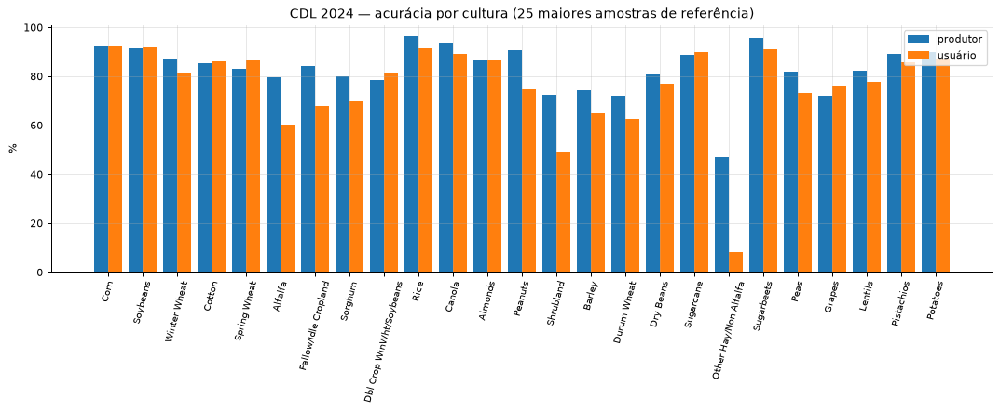

Correlação de Spearman entre tamanho da amostra e acurácia do produtor: 0.834


,classe,codigo,pixels_ref,prod_acc,omissao,kappa_p,user_acc,comissao,kappa_u
0,Corn,1,926684,92.6,7.4,0.923,92.3,7.7,0.919
4,Soybeans,5,830135,91.2,8.8,0.908,91.6,8.4,0.912
14,Winter Wheat,24,204900,87.1,12.9,0.869,81.1,18.9,0.809
1,Cotton,2,118322,85.2,14.8,0.852,86.2,13.8,0.861
13,Spring Wheat,23,110760,82.9,17.1,0.828,86.7,13.3,0.866
26,Alfalfa,36,88352,79.6,20.4,0.795,60.3,39.7,0.601
49,Fallow/Idle Cropland,61,68594,84.1,15.9,0.840,67.7,32.3,0.676
3,Sorghum,4,60299,79.9,20.1,0.799,69.8,30.2,0.697
16,Dbl Crop WinWht/Soybeans,26,36376,78.4,21.6,0.783,81.6,18.4,0.815
2,Rice,3,35276,96.1,3.9,0.961,91.3,8.7,0.912


In [153]:
z = zipfile.ZipFile(ESTUDO_CDL / "2024_30m_cdls.zip")
txt = z.read([n for n in z.namelist() if n.endswith(".htm")][0]).decode("latin-1")
padrao = re.compile(r"^([A-Za-z][A-Za-z/&\.,' \-]+?)\s{2,}(\d{1,3})\s+([\d,]+)\s+([\d.]+)%\s+([\d.]+)%\s+([\d.]+)\s+([\d.]+)%\s+([\d.]+)%\s+([\d.]+)\s*$", re.M)
acc = pd.DataFrame(padrao.findall(txt), columns=["classe", "codigo", "pixels_ref", "prod_acc", "omissao", "kappa_p", "user_acc", "comissao", "kappa_u"])
for c in ["codigo"]:
    acc[c] = acc[c].astype(int)
acc["pixels_ref"] = acc.pixels_ref.str.replace(",", "").astype(int)
for c in ["prod_acc", "user_acc", "omissao", "comissao", "kappa_p", "kappa_u"]:
    acc[c] = acc[c].astype(float)
acc = acc.drop_duplicates("codigo").sort_values("pixels_ref", ascending=False)
NOMES = {**NAO_AGRI, **dict(zip(acc.codigo, acc.classe))}
print(f"{len(acc)} classes com acurácia publicada")
top = acc.head(25)
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(top))
ax.bar(x - 0.2, top.prod_acc, 0.4, label="produtor")
ax.bar(x + 0.2, top.user_acc, 0.4, label="usuário")
ax.set_xticks(x)
ax.set_xticklabels(top.classe, rotation=75, fontsize=8)
ax.set_ylabel("%")
ax.set_title("CDL 2024 — acurácia por cultura (25 maiores amostras de referência)")
ax.legend()
plt.tight_layout()
plt.show()
print("Correlação de Spearman entre tamanho da amostra e acurácia do produtor:",
      round(acc[["pixels_ref", "prod_acc"]].corr("spearman").iloc[0, 1], 3))
acc.head(15)

### 14.2 Validação de cobertura: é global?
**Não.** A extensão do raster nacional cobre só os EUA contíguos.

Para levar a mesma ideia ao mundo, os análogos são:
- **ESA WorldCereal:** mapas globais de cereais/cultivos e irrigação, 10 m, 2021+.
- **MapBiomas:** Brasil, uso do solo anual a 30 m desde 1985, com classes de soja, cana, café, algodão e outras.
- **IBGE PAM:** proporções de cada cultura por município, que servem de rótulo fraco.

Extensão em graus (lon_min, lat_min, lon_max, lat_max): [-127.89   22.94  -65.35   51.6 ]


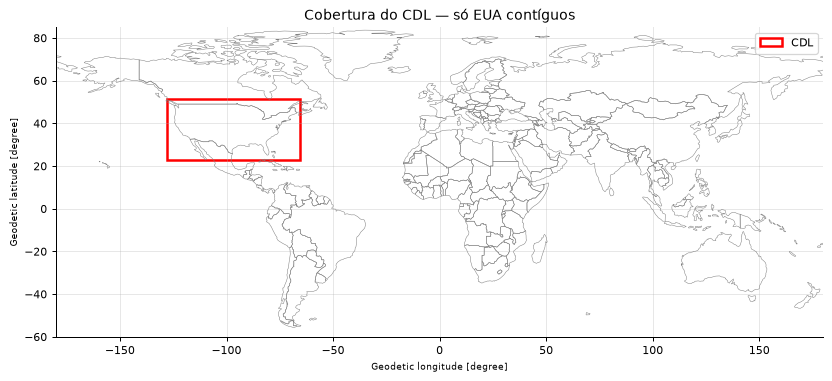

Fração da caixa com dado: 58.3%


In [154]:
with rasterio.open(REC / f"nacional_{ANOS[0]}_960m.tif") as r:
    nac = r.read(1)
    from rasterio.warp import transform_bounds
    b = transform_bounds(r.crs, "EPSG:4326", *r.bounds)
print("Extensão em graus (lon_min, lat_min, lon_max, lat_max):", np.round(b, 2))
fig, ax = plt.subplots(figsize=(11, 4.5))
paises_gdf().boundary.plot(ax=ax, color="gray", lw=0.4)
ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=2, label="CDL"))
ax.set_xlim(-180, 180)
ax.set_ylim(-60, 85)
ax.legend()
ax.set_title("Cobertura do CDL — só EUA contíguos")
plt.show()
area_terra = (nac != 0).mean()
print(f"Fração da caixa com dado: {area_terra:.1%}")

### 14.3 O que se planta nos EUA (visão nacional a 960 m)
A amostragem pelo vizinho mais próximo preserva as proporções de área em média (é uma amostra sistemática de 1 a cada
32 × 32 pixels).

Área agrícola (classes de cultura) = 17.3% do território com dado


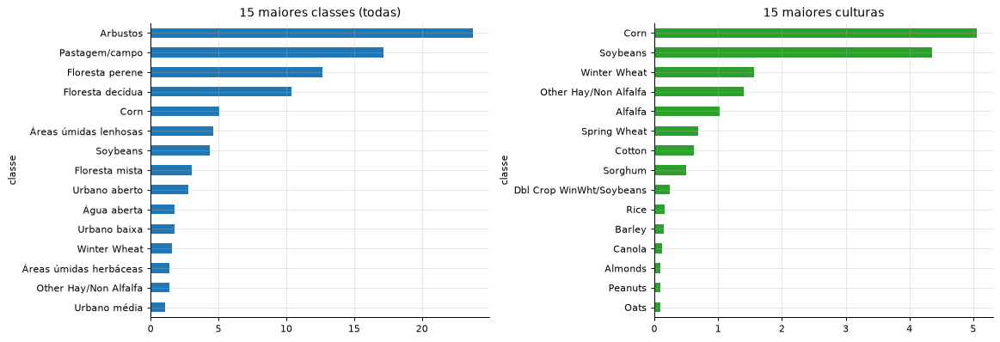

In [155]:
cont = Counter(nac[nac != 0].ravel().tolist())
tot = sum(cont.values())
shares = pd.DataFrame([(k, NOMES.get(k, f"classe {k}"), v / tot * 100) for k, v in cont.items()],
                      columns=["codigo", "classe", "pct_area"]).sort_values("pct_area", ascending=False)
agri = shares[~shares.codigo.isin(NAO_AGRI.keys())]
print(f"Área agrícola (classes de cultura) = {agri.pct_area.sum():.1f}% do território com dado")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
shares.head(15).plot.barh(x="classe", y="pct_area", ax=ax[0], legend=False)
ax[0].invert_yaxis()
ax[0].set_title("15 maiores classes (todas)")
agri.head(15).plot.barh(x="classe", y="pct_area", ax=ax[1], legend=False, color="tab:green")
ax[1].invert_yaxis()
ax[1].set_title("15 maiores culturas")
plt.tight_layout()
plt.show()

### 14.4 Janelas regionais: composição e rotação observada
Para cada uma das 6 janelas de 40 × 40 km, olhamos a composição do último ano e, pixel a pixel, a **sequência de
culturas nos anos disponíveis**. A pergunta é quanto da área repete a mesma cultura (monocultura) e quanto alterna.

In [156]:
def ler(reg, ano):
    with rasterio.open(REC / f"{reg}_{ano}.tif") as r:
        return r.read(1)


resumo, seqs_top = [], {}
for reg in REGIOES:
    pilha = np.stack([ler(reg, a) for a in ANOS])
    ultimo = pilha[-1]
    cult = ~np.isin(ultimo, list(NAO_AGRI.keys()))
    c = Counter(ultimo[cult].ravel().tolist())
    top3 = ", ".join(f"{NOMES.get(k, k)} {v / max(cult.sum(), 1):.0%}" for k, v in c.most_common(3))
    linha = {"regiao": reg, "descricao": REGIOES[reg], "% cultivado": round(cult.mean() * 100, 1), "top3 (último ano)": top3}
    if len(ANOS) >= 2:
        ag = np.all(~np.isin(pilha, list(NAO_AGRI.keys())), axis=0)  # cultivado em todos os anos
        mesma = np.all(pilha == pilha[0], axis=0) & ag
        linha["% repete a mesma cultura"] = round(mesma.sum() / max(ag.sum(), 1) * 100, 1)
        seq = Counter(map(tuple, pilha[:, ag].T.tolist()))
        seqs_top[reg] = [(" → ".join(NOMES.get(x, str(x)) for x in s), n / ag.sum()) for s, n in seq.most_common(5)]
    resumo.append(linha)
pd.DataFrame(resumo)

,regiao,descricao,% cultivado,top3 (último ano),% repete a mesma cultura
0,iowa_story,Corn Belt: milho-soja,73.3,"Corn 58%, Soybeans 40%, Alfalfa 1%",9.7
1,kansas_ogallala,"Ogallala: milho irrigado, trigo, sorgo",70.0,"Corn 43%, Winter Wheat 24%, Sorghum 21%",27.7
2,california_fresno,"Vale Central: perenes, algodão, tomate",75.6,"Almonds 20%, Grapes 15%, Pistachios 14%",47.3
3,mississippi_delta,"Delta: soja, algodão, arroz",70.0,"Soybeans 73%, Corn 15%, Rice 5%",50.8
4,north_dakota_cass,"Planícies do norte: trigo, soja, milho, girassol",87.8,"Soybeans 45%, Corn 40%, Spring Wheat 7%",5.3
5,texas_lubbock,Semiárido: algodão de sequeiro (análogo ao sertão),48.1,"Cotton 74%, Sorghum 11%, Winter Wheat 4%",67.0


In [157]:
for reg, lst in seqs_top.items():
    print(f"\n{reg} — 5 sequências mais comuns ({ANOS[0]}–{ANOS[-1]}):")
    for s, f in lst:
        print(f"   {f:6.1%}  {s}")


iowa_story — 5 sequências mais comuns (2023–2025):
    39.7%  Corn → Soybeans → Corn
    33.4%  Soybeans → Corn → Soybeans
     8.7%  Corn → Corn → Corn
     8.6%  Soybeans → Corn → Corn
     5.5%  Corn → Corn → Soybeans

kansas_ogallala — 5 sequências mais comuns (2023–2025):
    20.3%  Corn → Corn → Corn
     5.6%  Sorghum → Corn → Corn
     5.1%  Corn → Sorghum → Corn
     5.0%  Sorghum → Corn → Sorghum
     4.5%  Corn → Winter Wheat → Corn

california_fresno — 5 sequências mais comuns (2023–2025):
    17.1%  Almonds → Almonds → Almonds
    12.0%  Grapes → Grapes → Grapes
     9.7%  Pistachios → Pistachios → Pistachios
     3.5%  Walnuts → Walnuts → Walnuts
     1.9%  Alfalfa → Alfalfa → Alfalfa

mississippi_delta — 5 sequências mais comuns (2023–2025):
    50.3%  Soybeans → Soybeans → Soybeans
     8.2%  Soybeans → Corn → Soybeans
     7.2%  Soybeans → Soybeans → Corn
     7.1%  Corn → Soybeans → Soybeans
     6.3%  Corn → Soybeans → Corn

north_dakota_cass — 5 sequências mais com

### 14.5 Matriz de transição (prior de rotação)
Probabilidade de a cultura do ano seguinte ser *j*, dado que no ano anterior foi *i*, nas 6 janelas juntas, entre as
culturas mais comuns. **É exatamente o modelo de partida (cadeia de Markov) da ideia 2 da seção 30.**

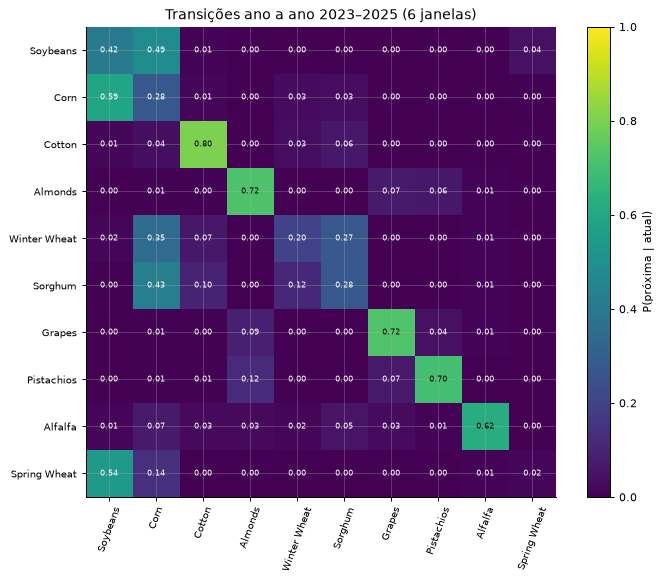

In [158]:
if len(ANOS) >= 2:
    pares = Counter()
    for reg in REGIOES:
        pilha = np.stack([ler(reg, a) for a in ANOS])
        for t in range(len(ANOS) - 1):
            a, b2 = pilha[t].ravel(), pilha[t + 1].ravel()
            ok = ~np.isin(a, list(NAO_AGRI.keys())) & ~np.isin(b2, list(NAO_AGRI.keys()))
            pares.update(zip(a[ok].tolist(), b2[ok].tolist()))
    origem = Counter()
    for (i, j), n in pares.items():
        origem[i] += n
    principais = [k for k, _ in origem.most_common(10)]
    M = pd.DataFrame(0.0, index=[NOMES.get(k, k) for k in principais], columns=[NOMES.get(k, k) for k in principais])
    for i in principais:
        for j in principais:
            M.loc[NOMES.get(i, i), NOMES.get(j, j)] = pares[(i, j)] / origem[i]
    fig, ax = plt.subplots(figsize=(8, 6.5))
    im = ax.imshow(M.values, cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(len(M)))
    ax.set_xticklabels(M.columns, rotation=70, fontsize=8)
    ax.set_yticks(range(len(M)))
    ax.set_yticklabels(M.index, fontsize=8)
    for i in range(len(M)):
        for j in range(len(M)):
            ax.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="w" if M.values[i, j] < 0.6 else "k")
    plt.colorbar(im, ax=ax, label="P(próxima | atual)")
    ax.set_title(f"Transições ano a ano {ANOS[0]}–{ANOS[-1]} (6 janelas)")
    plt.tight_layout()
    plt.show()
    M.round(2)

### 14.6 Frequência de culturas 2008–2025 (camada oficial do NASS)
Em cada pixel, a camada de frequência conta em quantos dos 18 anos ele recebeu uma dada cultura.
Isso mostra a **intensidade** de cada sistema: milho quase todo ano = monocultura; metade dos anos = rotação bienal.

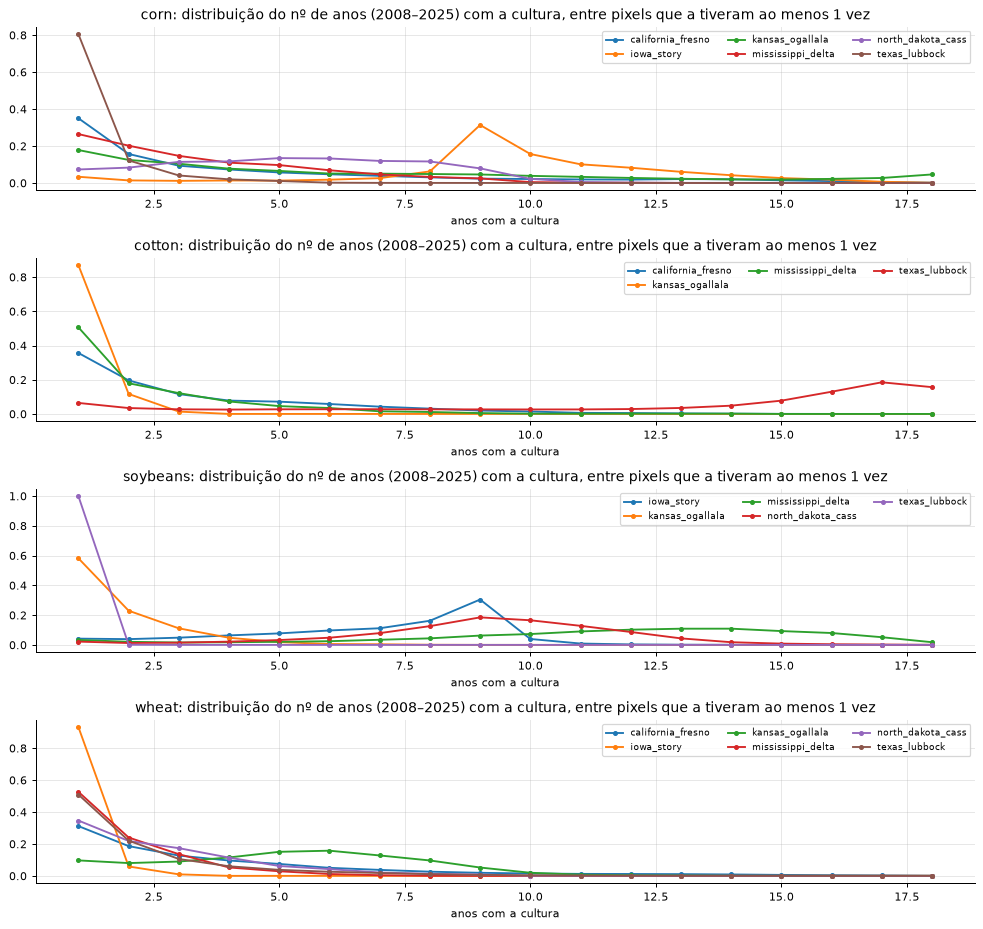

In [159]:
freqs = sorted(REC.glob("*_freq*.tif")) + sorted(REC.glob("*Frequency*.tif"))
freqs = sorted(set(freqs))
if not freqs:
    print("Recortes da camada de frequência ainda não gerados.")
else:
    reg_freq = {}
    for f in freqs:
        reg = next((r for r in REGIOES if f.name.startswith(r)), None)
        if reg is None:
            continue
        with rasterio.open(f) as r:
            a = r.read(1)
        m = re.search(r"crop_frequency_([a-z]+)_", f.stem)
        reg_freq.setdefault(reg, {})[m.group(1) if m else f.stem.replace(reg + "_", "")] = a
    camadas = sorted({k for d in reg_freq.values() for k in d})
    fig, axs = plt.subplots(len(camadas), 1, figsize=(11, 2.6 * len(camadas)), squeeze=False)
    for ci, cam in enumerate(camadas):
        ax = axs[ci, 0]
        for reg, d in reg_freq.items():
            if cam in d:
                v = d[cam]
                v = v[(v > 0) & (v < 50)]
                if v.size:
                    h = np.bincount(v.astype(int), minlength=19)[1:19]
                    ax.plot(range(1, 19), h / h.sum(), marker="o", ms=3, label=reg)
        ax.set_title(f"{cam}: distribuição do nº de anos (2008–2025) com a cultura, entre pixels que a tiveram ao menos 1 vez")
        ax.set_xlabel("anos com a cultura")
        ax.legend(fontsize=7, ncol=3)
    plt.tight_layout()
    plt.show()

### 14.7 Insights do CDL para o produto
- **A rotação real é detectável por satélite e é muito estruturada.** No Corn Belt a alternância milho↔soja domina; em
  regiões semiáridas aparecem **pousio** e culturas tolerantes à seca (algodão, sorgo, trigo). A matriz de transição é
  um *prior* pronto para o motor: dada a cultura atual, quais sucessões são habituais e quais seriam novidade (e exigem
  mais justificativa).
- **Pousio e "ocioso" são parte da rotação no semiárido.** No Texas de sequeiro, o pousio é estratégia de guardar água.
  É o mesmo dilema do sertão: o produto deve oferecer "pousio com cobertura" como estratégia comparável.
- **Qualidade desigual dos rótulos.** Culturas pequenas têm acurácia bem menor. Se treinarmos modelos com o CDL, temos
  de ponderar por acurácia ou focar nas classes confiáveis.
- **Generalizar para o mundo:** a mesma análise roda com o WorldCereal (global), o MapBiomas (Brasil) ou com rótulos
  gerados pelo nosso classificador de culturas (ideia 1 da seção 30), treinado onde o CDL existe e transferido para
  outras regiões com cautela.
- **Ligação com pragas (percolação):** a fração de área com a mesma cultura hospedeira em janelas de 40 km (ex.: milho
  + soja > 80% no Iowa) indica paisagens acima do limiar de percolação, onde pragas especialistas se espalham com
  facilidade. A rotação e a diversidade de culturas quebram essa conectividade.

# 15. NASA NEX-GDDP-CMIP6 — projeções climáticas para os controles deslizantes de cenário

**Ficha técnica**

| Item | Valor |
|---|---|
| Produto | NEX-GDDP-CMIP6 (NASA Earth Exchange, NASA Ames): 35 modelos CMIP6 com downscaling estatístico BCSD (bias-correction spatial disaggregation) para 0,25°, diário |
| Variáveis | pr, tas, tasmax, tasmin, hurs, huss, rlds, rsds, sfcWind |
| Cenários | historical (1950–2014), SSP2-4.5 e SSP5-8.5 (2015–2100) |
| Rota usada | Microsoft Planetary Computer `nasa-nex-gddp-cmip6` (aberto). Cada arquivo = 1 ano × 1 variável com bloco de **1 dia do globo inteiro** (tasmax ≈ 244 MB/ano, pr ≈ 181 MB/ano) → baixa-se o arquivo e recorta-se o Nordeste |
| **Amostra baixada (mínima)** | 1 modelo (**MPI-ESM1-2-HR**), tasmax + pr, janelas de 5 anos: histórico 2010–14; SSP2-4.5 2046–50; SSP5-8.5 2046–50 e 2086–90 |
| Limitação | um único modelo e janelas curtas: o sinal de temperatura é robusto; o de chuva é ruidoso (o produto final deve usar o ensemble de 10–35 modelos e janelas de 20–30 anos) |

In [160]:
import sys, warnings
sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
from comum import *  # noqa
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import shapely

warnings.filterwarnings("ignore")
try:
    sys.stdout.reconfigure(encoding="utf-8")
except Exception:
    pass
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
DIR = DADOS / "nex_gddp"
ce_gdf, ne_gdf = ceara_gdf(), nordeste_gdf()
JAN = {"hist 2010–14": ("historical", range(2010, 2015)), "SSP2-4.5 2046–50": ("ssp245", range(2046, 2051)),
       "SSP5-8.5 2046–50": ("ssp585", range(2046, 2051)), "SSP5-8.5 2086–90": ("ssp585", range(2086, 2091))}


def carregar(var, cen, anos):
    arqs = [DIR / f"nex_MPI-ESM1-2-HR_{cen}_{var}_{a}_ne.nc" for a in anos]
    arqs = [a for a in arqs if a.exists()]
    if not arqs:
        return None
    return xr.open_mfdataset(arqs, combine="by_coords")[var].load()


def mascara(geom, lon, lat):
    lo, la = np.meshgrid(lon, lat)
    return xr.DataArray(shapely.contains_xy(geom, lo, la), dims=("lat", "lon"))


dados = {k: {v: carregar(v, c, a) for v in ["tasmax", "pr"]} for k, (c, a) in JAN.items()}
for k, d in dados.items():
    print(k, {v: (None if x is None else f"{x.sizes['time']} dias") for v, x in d.items()})
ref = dados["hist 2010–14"]["tasmax"]
M_CE = mascara(ce_gdf.geometry.union_all(), ref.lon.values, ref.lat.values)
M_NE = mascara(ne_gdf.geometry.union_all(), ref.lon.values, ref.lat.values)

hist 2010–14 {'tasmax': '1826 dias', 'pr': '1826 dias'}
SSP2-4.5 2046–50 {'tasmax': '1826 dias', 'pr': '1826 dias'}
SSP5-8.5 2046–50 {'tasmax': '1826 dias', 'pr': '1826 dias'}
SSP5-8.5 2086–90 {'tasmax': '1826 dias', 'pr': '1826 dias'}


## 15.1 Cobertura global e qualidade
Pelos metadados STAC de cada item: grade de 600 × 1440 (0,25°), latitude de **59,875°S a 89,875°N** e
longitude completa. A Antártida fica fora; o resto do planeta está coberto. O BCSD usa a referência
observacional GMFD, que só existe em terra, então os pixels de oceano vêm vazios.

In [161]:
print(f"fração de pixels sem dado no recorte NE (oceano): {float(ref.isel(time=0).isnull().mean()):.0%}; "
      f"dentro do NE: {float(ref.isel(time=0).where(M_NE).isnull().where(M_NE).mean()):.1%}")
for k, d in dados.items():
    for v, x in d.items():
        if x is None:
            continue
        vv = x.where(M_NE).values
        vv = vv[np.isfinite(vv)]
        print(f"{k:18s} {v:6s} mín {vv.min():7.2f} máx {vv.max():7.2f} média {vv.mean():7.2f}  ausentes(NE) "
              f"{float(x.where(M_NE).isnull().where(M_NE).mean()):.2%}")

fração de pixels sem dado no recorte NE (oceano): 22%; dentro do NE: 0.0%
hist 2010–14       tasmax mín   19.49 máx   45.40 média   32.13  ausentes(NE) 0.00%
hist 2010–14       pr     mín    0.00 máx  100.49 média    3.00  ausentes(NE) 0.00%


SSP2-4.5 2046–50   tasmax mín   20.76 máx   46.08 média   32.72  ausentes(NE) 0.00%
SSP2-4.5 2046–50   pr     mín    0.00 máx   64.97 média    2.82  ausentes(NE) 0.00%
SSP5-8.5 2046–50   tasmax mín   20.04 máx   49.04 média   33.19  ausentes(NE) 0.00%


SSP5-8.5 2046–50   pr     mín    0.00 máx   77.05 média    2.84  ausentes(NE) 0.00%
SSP5-8.5 2086–90   tasmax mín   21.94 máx   46.59 média   34.62  ausentes(NE) 0.00%
SSP5-8.5 2086–90   pr     mín    0.00 máx   71.07 média    2.90  ausentes(NE) 0.00%


**Veredito:** é global para áreas agrícolas (60°S–90°N, só terra) e uniforme no planeta. Os mesmos indicadores
(dias ≥ 35 °C, chuva da quadra, ET0) podem ser calculados para qualquer fazenda do mundo em qualquer cenário.

## 15.2 Mudanças projetadas no Ceará e no Nordeste (relativas ao histórico 2010–14 do próprio modelo)

In [162]:
linhas = []
base_tx = dados["hist 2010–14"]["tasmax"]
base_pr = dados["hist 2010–14"]["pr"]
for k, d in dados.items():
    tx, pr = d["tasmax"], d["pr"]
    if tx is None or pr is None:
        continue
    n_anos = tx.sizes["time"] / 365.25
    for nome, M in [("Ceará", M_CE), ("Nordeste", M_NE)]:
        linhas.append({
            "janela": k, "região": nome,
            "Tmax média (°C)": float(tx.where(M).mean()),
            "dias/ano Tmax≥35 °C (média dos pixels)": float((tx >= 35).where(M).sum("time").where(M).mean() / n_anos),
            "dias/ano Tmax≥38 °C": float((tx >= 38).where(M).sum("time").where(M).mean() / n_anos),
            "chuva anual (mm)": float(pr.where(M).sum("time").where(M).mean() / n_anos),
            "chuva fev–mai (mm)": float(pr.sel(time=pr.time.dt.month.isin([2, 3, 4, 5])).where(M).sum("time").where(M).mean() / n_anos),
        })
tab = pd.DataFrame(linhas).set_index(["região", "janela"]).round(1)
print(tab.to_string())
for reg in ["Ceará", "Nordeste"]:
    b = tab.loc[(reg, "hist 2010–14")]
    print(f"\n{reg} — variação contra 2010–14:")
    for k in list(JAN)[1:]:
        if (reg, k) in tab.index:
            r = tab.loc[(reg, k)]
            print(f"  {k}: ΔTmax {r['Tmax média (°C)'] - b['Tmax média (°C)']:+.1f} °C | dias≥35 °C "
                  f"{b['dias/ano Tmax≥35 °C (média dos pixels)']:.0f}→{r['dias/ano Tmax≥35 °C (média dos pixels)']:.0f} | "
                  f"chuva anual {r['chuva anual (mm)'] / b['chuva anual (mm)'] - 1:+.0%} | quadra {r['chuva fev–mai (mm)'] / b['chuva fev–mai (mm)'] - 1:+.0%}")

                           Tmax média (°C)  dias/ano Tmax≥35 °C (média dos pixels)  dias/ano Tmax≥38 °C  chuva anual (mm)  chuva fev–mai (mm)
região   janela                                                                                                                              
Ceará    hist 2010–14                 32.5                                    56.3                  5.4             948.6               712.3
Nordeste hist 2010–14                 32.1                                    59.9                  7.8            1095.0               596.7
Ceará    SSP2-4.5 2046–50             33.1                                    77.7                  9.6             863.0               624.9
Nordeste SSP2-4.5 2046–50             32.7                                    77.4                 14.7            1028.4               560.0
Ceará    SSP5-8.5 2046–50             33.4                                    97.6                 14.2             893.2               645.9
Nordes

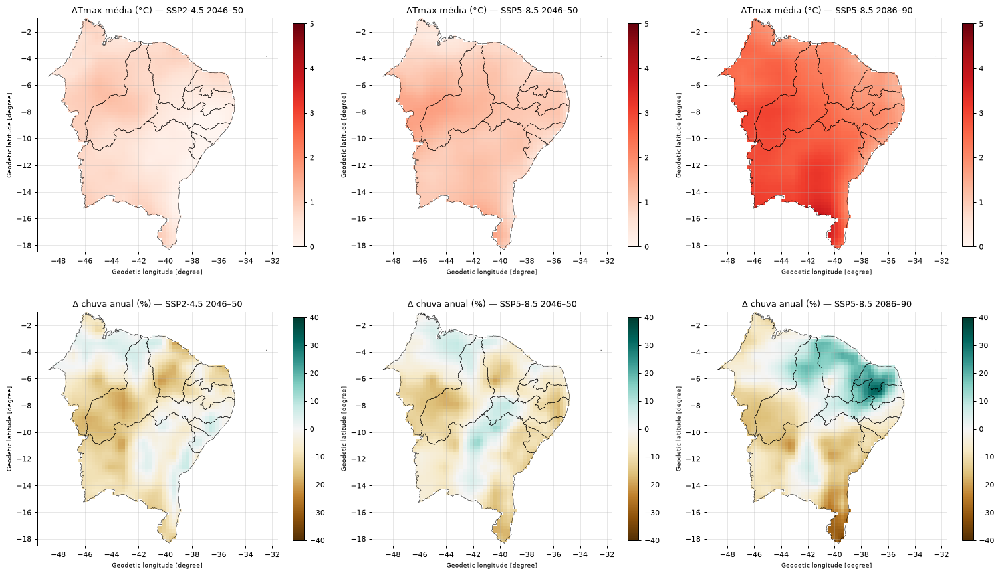

In [163]:
def nanos(x):
    return x.sizes["time"] / 365.25


fig, ax = plt.subplots(2, 3, figsize=(17, 10))
for j, k in enumerate(list(JAN)[1:]):
    tx, pr = dados[k]["tasmax"], dados[k]["pr"]
    if tx is None:
        continue
    dT = (tx.mean("time") - base_tx.mean("time")).where(M_NE)
    m = ax[0, j].pcolormesh(dT.lon, dT.lat, dT, cmap="Reds", vmin=0, vmax=5, shading="auto")
    plt.colorbar(m, ax=ax[0, j], shrink=0.8)
    ax[0, j].set_title(f"ΔTmax média (°C) — {k}", fontsize=10)
    dP = ((pr.sum("time") / nanos(pr)) / (base_pr.sum("time") / nanos(base_pr)) - 1).where(M_NE) * 100
    m = ax[1, j].pcolormesh(dP.lon, dP.lat, dP, cmap="BrBG", vmin=-40, vmax=40, shading="auto")
    plt.colorbar(m, ax=ax[1, j], shrink=0.8)
    ax[1, j].set_title(f"Δ chuva anual (%) — {k}", fontsize=10)
for a in ax.ravel():
    ne_gdf.boundary.plot(ax=a, color="k", lw=0.4)
    a.set_aspect("equal")
plt.tight_layout()
plt.show()

## 15.3 Tendência entre janelas e variabilidade interanual (comparação com a seca de 2012)

                 Tmax_media                  quadra_mm                      dias35                    
                       mean  std   min   max      mean    std    min    max   mean   std    min    max
janela                                                                                                
SSP2-4.5 2046–50       33.1  0.6  32.5  34.0     624.8   26.6  579.8  647.8   77.7  24.5   56.0  116.2
SSP5-8.5 2046–50       33.4  0.9  32.5  34.7     645.8   97.7  522.3  771.7   97.6  44.7   61.1  165.7
SSP5-8.5 2086–90       34.4  0.2  34.2  34.8     769.3  126.7  645.4  938.1  142.1  13.9  125.2  163.6
hist 2010–14           32.5  0.5  31.7  32.8     712.2   88.4  599.5  801.9   56.3  15.4   33.6   76.8

quadra observada (IMERG): climatologia 1998–2025 592 mm; 2010–14 482 mm (inclui a seca); 2012 354 mm | modelo 'histórico 2010–14': 712 mm (+20% contra a climatologia observada).
  Atenção: os anos de um modelo climático NÃO correspondem aos anos reais (o modelo não 'sabe' que 2

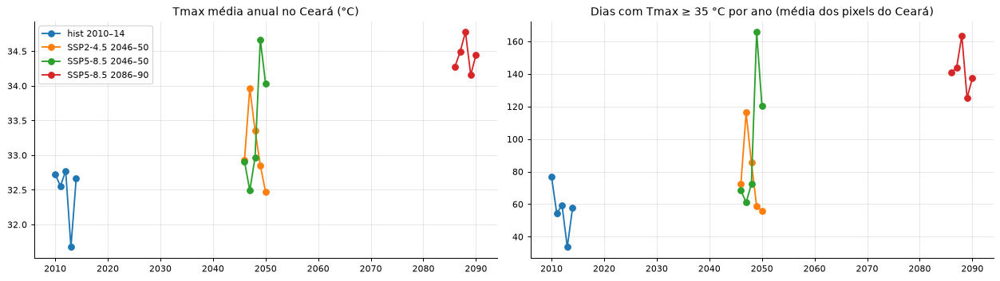

In [164]:
serie = []
for k, (cen, anos) in JAN.items():
    tx, pr = dados[k]["tasmax"], dados[k]["pr"]
    if tx is None:
        continue
    for a in anos:
        t = tx.sel(time=str(a)).where(M_CE).mean().item()
        q = pr.sel(time=(pr.time.dt.year == a) & pr.time.dt.month.isin([2, 3, 4, 5])).where(M_CE).sum("time").where(M_CE).mean().item()
        d35 = (tx.sel(time=str(a)) >= 35).where(M_CE).sum("time").where(M_CE).mean().item()
        serie.append({"janela": k, "ano": a, "Tmax_media": t, "quadra_mm": q, "dias35": d35})
serie = pd.DataFrame(serie)
print(serie.groupby("janela")[["Tmax_media", "quadra_mm", "dias35"]].agg(["mean", "std", "min", "max"]).round(1).to_string())
imerg = DERIV / "imerg_ce_mensal.parquet"
if imerg.exists():
    i = pd.read_parquet(imerg)
    i = i[i.variavel == "precip_total"].set_index("data")["valor"]
    q_obs = i[i.index.month.isin([2, 3, 4, 5])].groupby(i[i.index.month.isin([2, 3, 4, 5])].index.year).sum()
    q_2012 = q_obs.loc[2012]
    hist_mod = serie[serie.janela == "hist 2010–14"].quadra_mm.mean()
    obs_2010_14 = q_obs.loc[2010:2014].mean()
    q_clim = q_obs.loc[1998:2025].mean()
    print(f"\nquadra observada (IMERG): climatologia 1998–2025 {q_clim:.0f} mm; 2010–14 {obs_2010_14:.0f} mm (inclui a seca); "
          f"2012 {q_2012:.0f} mm | modelo 'histórico 2010–14': {hist_mod:.0f} mm "
          f"({hist_mod/q_clim-1:+.0%} contra a climatologia observada).")
    print("  Atenção: os anos de um modelo climático NÃO correspondem aos anos reais (o modelo não 'sabe' que 2012 foi seco);"
          " só climatologias longas são comparáveis. Com 5 anos, essa diferença mistura viés e acaso.")
    lim = q_2012 / obs_2010_14  # 2012 como fração da média 2010-14
    for k in JAN:
        s = serie[serie.janela == k]
        frac = (s.quadra_mm / hist_mod < lim).mean()
        print(f"  {k}: anos com quadra relativa abaixo do nível de 2012: {frac:.0%} (n={len(s)})")
era5 = DERIV / "era5_ce_mensal.parquet"
if era5.exists():
    e = pd.read_parquet(era5)
    e = e[e.variavel == "tmax"].set_index("data")["valor"]
    print(f"Tmax média ERA5 2010–14 no Ceará: {e.loc['2010':'2014'].mean():.1f} °C vs NEX hist "
          f"{serie[serie.janela=='hist 2010–14'].Tmax_media.mean():.1f} °C")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, g in serie.groupby("janela", sort=False):
    ax[0].plot(g.ano, g.Tmax_media, "o-", label=k)
    ax[1].plot(g.ano, g.dias35, "o-", label=k)
ax[0].set_title("Tmax média anual no Ceará (°C)")
ax[1].set_title("Dias com Tmax ≥ 35 °C por ano (média dos pixels do Ceará)")
ax[0].legend()
plt.tight_layout()
plt.show()

## 15.4 Insights e desenho dos controles deslizantes

1. **O calor é o sinal robusto.** No Ceará (MPI-ESM1-2-HR, contra o próprio histórico 2010–14), a Tmax média sobe
   +0,6 °C (SSP2-4.5, 2046–50), +0,9 °C (SSP5-8.5, 2046–50) e +1,9 °C (SSP5-8.5, 2086–90). Os **dias com Tmax ≥ 35 °C
   passam de ~56/ano para ~78, ~98 e ~142/ano**, e os dias ≥ 38 °C de ~5 para ~10, ~14 e ~29/ano. Para culturas com
   floração sensível a calor (feijão-comum, milho), a janela de plantio "segura" encolhe.
2. **A chuva é incerta.** O mesmo modelo dá −9 %, −6 % e +12 % na chuva anual nas três janelas. Esse sinal de
   5 anos de um único modelo é dominado pela variabilidade interanual, na mesma escala da seca de 2012. O produto
   deve mostrar a chuva futura como **faixa do ensemble** (p10–p90 entre modelos), nunca como um número.
3. **Desenho sugerido dos controles:** (a) "Aquecimento: +1 / +2 / +3 °C", que desloca a distribuição diária de
   Tmax/Tmin observada (ERA5/POWER) e recalcula dias ≥ 35 °C, ET0 e graus-dia; (b) "Chuva da quadra: −30 % a
   +20 %", que escala os dias de chuva do IMERG e recalcula veranicos e o balanço hídrico; (c) botão "usar
   projeção SSP2-4.5/SSP5-8.5 2050", que aplica os deltas do ensemble NEX-GDDP. O método (a)+(b) é transparente
   e explicável ao agricultor; o (c) dá a âncora científica.
4. **Combinação com a rotação:** cada estratégia candidata recebe uma nota de robustez, ou seja, a fração de
   cenários em que ainda atinge a produtividade mínima. Isso favorece rotações com culturas de ciclo curto e
   tolerantes ao calor.

**Ideias de ML/DL:** emulador neural (MLP/gradient boosting) do modelo de cultivo, que recebe os deltas de cenário
e responde em milissegundos no controle deslizante; seleção de subconjunto de modelos CMIP6 por desempenho
histórico no NE (skill-weighting) antes de montar o ensemble.

## 20. Relações entre bases — conectividade e novas ligações

Aqui as bases deixam de ser estudadas isoladamente. Todas as frentes salvaram séries **mensais médias do Ceará** em
`dados/derivados/*_ce_mensal.parquet`, no mesmo formato (data, variavel, valor). Isso permite cruzar tudo num único
painel mensal.

**Perguntas que ligam as bases** (as do desafio e outras novas):
1. **Chuva:** as fontes concordam (POWER × IMERG × ERA5)? Qual usar no produto?
2. **Teleconexão → decisão de plantio:** o Pacífico (ONI) e o Atlântico (TNA−TSA) antecipam a quadra chuvosa?
3. **A vegetação responde à chuva com quanto atraso?** (NDVI × chuva)
4. **Água armazenada (GRACE) × chuva × umidade do solo:** memória hídrica de anos.
5. **Calor × vegetação:** LST/Tmax × NDVI (estresse).
6. **Fogo × secura × vegetação:** quando e por que queima.
7. **Clima → produção real** (IBGE PAM): quanto a seca derruba o rendimento de cada cultura.
8. **Mercado:** preço × produção, e a volatilidade como risco da rotação.

In [165]:
import sys
import warnings

sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from comum import DADOS, DERIV

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

partes = []
for f in sorted(DERIV.glob("*_ce_mensal.parquet")) + [DERIV / "indices_clima_mensal.parquet"]:
    if not f.exists():
        continue
    d = pd.read_parquet(f)
    if not {"data", "variavel", "valor"} <= set(d.columns):
        continue
    fonte = f.stem.replace("_ce_mensal", "").replace("_mensal", "")
    d = d.assign(col=fonte + ":" + d["variavel"].astype(str))
    d["data"] = pd.to_datetime(d["data"]).dt.to_period("M").dt.to_timestamp()
    partes.append(d[["data", "col", "valor"]])
painel = pd.concat(partes).pivot_table(index="data", columns="col", values="valor", aggfunc="mean").sort_index()
print(f"Painel mensal: {painel.shape[0]} meses × {painel.shape[1]} variáveis, {painel.index.min():%Y-%m} a {painel.index.max():%Y-%m}")
cobertura = painel.notna().sum().rename("meses_com_dado").to_frame()
cobertura["início"] = painel.apply(lambda s: s.first_valid_index())
cobertura["fim"] = painel.apply(lambda s: s.last_valid_index())
cobertura

Painel mensal: 947 meses × 56 variáveis, 1948-01 a 2026-11


,meses_com_dado,início,fim
col,,,
era5:d2m,504,1979-01-01,2020-12-01
era5:deficit_p_menos_et0,504,1979-01-01,2020-12-01
era5:dias_tmax35,504,1979-01-01,2020-12-01
era5:et0,504,1979-01-01,2020-12-01
era5:gdd10,504,1979-01-01,2020-12-01
era5:ssrd,504,1979-01-01,2020-12-01
era5:t2m,504,1979-01-01,2020-12-01
era5:tmax,504,1979-01-01,2020-12-01
era5:tmin,504,1979-01-01,2020-12-01


In [166]:
def achar(*palavras, excluir=()):
    """Primeira coluna do painel cujo nome contém todas as palavras (sem diferenciar maiúsculas)."""
    for c in painel.columns:
        n = c.lower()
        if all(p.lower() in n for p in palavras) and not any(e.lower() in n for e in excluir):
            return c
    return None


def anual_fmam(s):
    """Total de fev–mai por ano (quadra chuvosa)."""
    s = s.dropna()
    q = s[s.index.month.isin([2, 3, 4, 5])]
    cont = q.groupby(q.index.year).count()
    return q.groupby(q.index.year).sum()[cont == 4]


CH = {k: v for k, v in {
    "POWER (MERRA-2 corrigido)": achar("power", "prectotcorr"),
    "POWER IMERG": achar("power", "imerg"),
    "IMERG (GPM)": achar("imerg", "prec", excluir=("power",)) or achar("imerg", "chuva", excluir=("power",)),
    "ERA5": achar("era5", "prec") or achar("era5", "chuva") or achar("era5", ":tp"),
}.items() if v}
print("Séries de chuva encontradas:", CH)

Séries de chuva encontradas: {'POWER (MERRA-2 corrigido)': 'power:PRECTOTCORR', 'POWER IMERG': 'power:IMERG_PRECTOT', 'IMERG (GPM)': 'imerg:precip_total', 'ERA5': 'era5:tp'}


### 20.1 Chuva: as fontes concordam?
A chuva mensal do Ceará é comparada entre as fontes no período comum, com correlação, viés relativo e RMSE.
Para o produto, a fonte "de referência" deve ser global, longa e atualizada. A fonte observacional por satélite
(IMERG) é a referência natural, e os modelos (MERRA-2/ERA5) preenchem onde falta.

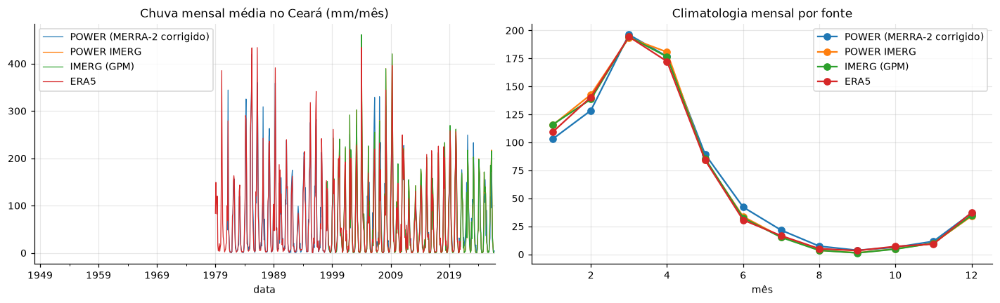

,fonte,vs,r,viés %,RMSE mm/mês,meses,período
0,POWER (MERRA-2 corrigido),IMERG (GPM),0.969,-1.1,21.1,345,1998-01–2026-09
1,POWER IMERG,IMERG (GPM),1.000,-0.3,1.0,320,2000-01–2026-08
2,ERA5,IMERG (GPM),0.985,-6.6,16.7,276,1998-01–2020-12


In [167]:
if len(CH) >= 2:
    dfc = pd.DataFrame({k: painel[v] for k, v in CH.items()})
    dfc = dfc.loc[:, dfc.notna().sum() >= 24]
    # unidades: converter mm/dia para mm/mês quando a média for pequena (< 15)
    for c in dfc:
        if dfc[c].mean() < 15:
            dfc[c] = dfc[c] * dfc.index.days_in_month
    ref = "IMERG (GPM)" if "IMERG (GPM)" in dfc else dfc.columns[0]
    linhas = []
    for c in dfc:
        if c == ref:
            continue
        par = dfc[[ref, c]].dropna()  # comparação par a par no período comum
        if len(par) < 24:
            continue
        r, _ = stats.pearsonr(par[ref], par[c])
        linhas.append({"fonte": c, "vs": ref, "r": round(r, 3), "viés %": round((par[c].mean() / par[ref].mean() - 1) * 100, 1),
                       "RMSE mm/mês": round(float(np.sqrt(((par[c] - par[ref]) ** 2).mean())), 1), "meses": len(par),
                       "período": f"{par.index.min():%Y-%m}–{par.index.max():%Y-%m}"})
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    dfc.plot(ax=ax[0], lw=0.8)
    ax[0].set_title("Chuva mensal média no Ceará (mm/mês)")
    clim = dfc.groupby(dfc.index.month).mean()
    clim.plot(ax=ax[1], marker="o")
    ax[1].set_title("Climatologia mensal por fonte")
    ax[1].set_xlabel("mês")
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame(linhas))
else:
    print("Menos de duas séries de chuva disponíveis ainda.")

### 20.2 Teleconexões → previsão da quadra chuvosa (ligação nova)
- **Física:** o Ceará chove quando a **Zona de Convergência Intertropical** desce para o sul em fev–mai. Isso é
  favorecido por **La Niña** (ONI < 0) e por **Atlântico Sul mais quente que o Norte** (TNA−TSA < 0).
- **Teste:** o índice médio de **out–jan** (antes do plantio) correlaciona com o total de fev–mai?
- **Modelo:** uma regressão logística de tercis, avaliada deixando um ano de fora, mostra se há **habilidade
  preditiva** além da climatologia.

É o protótipo da ideia (5) da seção 30.

46 anos (1981–2026)
  ONI_ondj      Pearson r=-0.39 (p=0.008)   Spearman ρ=-0.39 (p=0.007)
  Dipolo_ondj   Pearson r=-0.34 (p=0.022)   Spearman ρ=-0.26 (p=0.079)


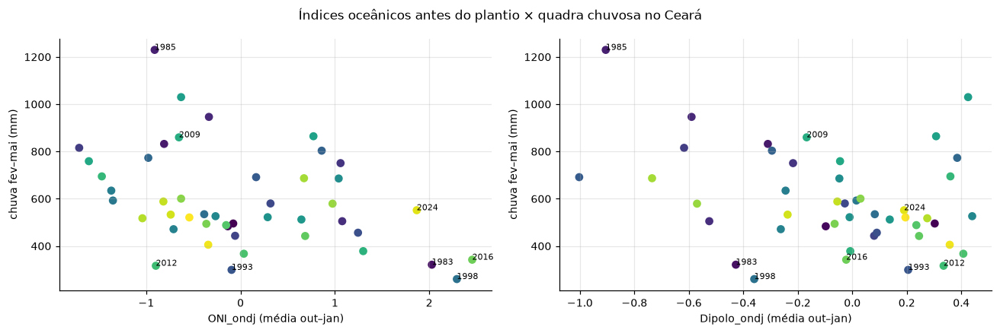

Acurácia de tercil (deixando 1 ano de fora): 41%  (acaso = 33%)
RPSS vs climatologia: +0.10  (>0 = melhor que a climatologia)


In [168]:
chuva_ref = CH.get("IMERG (GPM)") or CH.get("POWER (MERRA-2 corrigido)") or (list(CH.values())[0] if CH else None)
chuva_longa = CH.get("POWER (MERRA-2 corrigido)") or chuva_ref  # POWER tem 1981+
oni, tna, tsa = achar("indices", "oni"), achar("indices", "tna", excluir=("menos",)), achar("indices", "tsa", excluir=("menos",))
dip = achar("indices", "dipolo")
if chuva_longa and oni and dip:
    fmam = anual_fmam(painel[chuva_longa])
    if fmam.mean() < 60:  # mm/dia somado -> converter aproximando 30 dias
        fmam = fmam * 30
    def media_ondj(s):
        s = s.dropna()
        out = {}
        for ano in range(int(s.index.year.min()) + 1, int(s.index.year.max()) + 1):
            jan = pd.Timestamp(ano, 1, 1)
            janela = s[(s.index >= pd.Timestamp(ano - 1, 10, 1)) & (s.index <= jan)]
            if len(janela) == 4:
                out[ano] = janela.mean()
        return pd.Series(out)
    X = pd.DataFrame({"ONI_ondj": media_ondj(painel[oni]), "Dipolo_ondj": media_ondj(painel[dip]), "FMAM_mm": fmam}).dropna()
    print(f"{len(X)} anos ({X.index.min()}–{X.index.max()})")
    for c in ["ONI_ondj", "Dipolo_ondj"]:
        r, p = stats.pearsonr(X[c], X.FMAM_mm)
        rs, ps = stats.spearmanr(X[c], X.FMAM_mm)
        print(f"  {c:12s}  Pearson r={r:+.2f} (p={p:.3f})   Spearman ρ={rs:+.2f} (p={ps:.3f})")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, c in zip(ax, ["ONI_ondj", "Dipolo_ondj"]):
        a.scatter(X[c], X.FMAM_mm, c=X.index, cmap="viridis")
        for ano in [1983, 1993, 1998, 2012, 2016, 1985, 2009, 2024]:
            if ano in X.index:
                a.annotate(str(ano), (X.loc[ano, c], X.loc[ano, "FMAM_mm"]), fontsize=7)
        a.set_xlabel(c + " (média out–jan)")
        a.set_ylabel("chuva fev–mai (mm)")
    plt.suptitle("Índices oceânicos antes do plantio × quadra chuvosa no Ceará")
    plt.tight_layout()
    plt.show()

    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import LeaveOneOut
    q1, q2 = X.FMAM_mm.quantile([1 / 3, 2 / 3])
    y = np.where(X.FMAM_mm <= q1, 0, np.where(X.FMAM_mm >= q2, 2, 1))
    acertos, rps_m, rps_c = [], [], []
    for tr, te in LeaveOneOut().split(X):
        m = LogisticRegression(max_iter=1000).fit(X[["ONI_ondj", "Dipolo_ondj"]].iloc[tr], y[tr])
        p = m.predict_proba(X[["ONI_ondj", "Dipolo_ondj"]].iloc[te])[0]
        pc = np.full(3, 1 / 3)
        if len(m.classes_) == 3:
            acertos.append(int(np.argmax(p) == y[te][0]))
            o = np.eye(3)[y[te][0]]
            rps_m.append(np.sum((np.cumsum(p) - np.cumsum(o)) ** 2) / 2)
            rps_c.append(np.sum((np.cumsum(pc) - np.cumsum(o)) ** 2) / 2)
    rpss = 1 - np.mean(rps_m) / np.mean(rps_c)
    print(f"Acurácia de tercil (deixando 1 ano de fora): {np.mean(acertos):.0%}  (acaso = 33%)")
    print(f"RPSS vs climatologia: {rpss:+.2f}  (>0 = melhor que a climatologia)")
else:
    print("Faltam séries de chuva ou índices para este teste.")

### 20.3 Correlação cruzada com defasagem: quem antecede quem
Para cada par (chuva → NDVI, chuva → umidade do solo, chuva → GRACE, NDVI → fogo, LST → NDVI), calculamos a
correlação das **anomalias mensais** (o ciclo sazonal é removido) com defasagens de 0 a 6 meses. O pico diz quanto
tempo o sistema leva para responder.

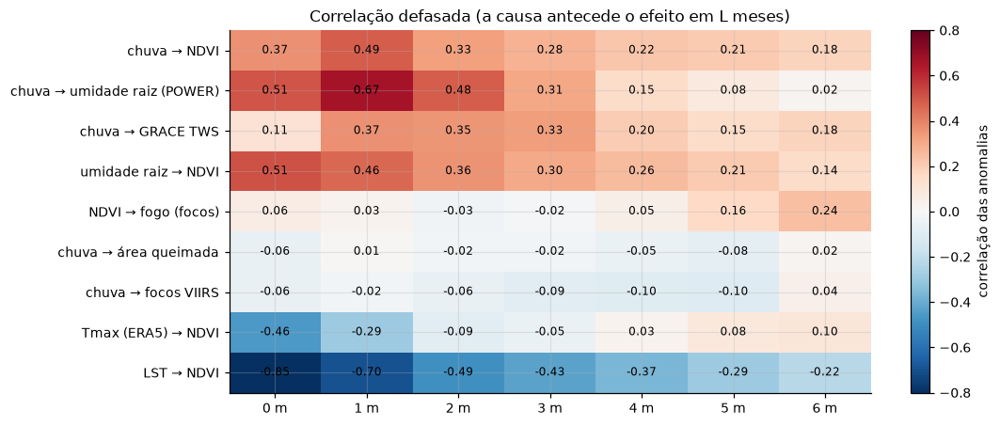

In [169]:
def anomalia(s):
    s = s.dropna()
    return s - s.groupby(s.index.month).transform("mean")


pares = {
    "chuva → NDVI": (chuva_ref, achar("modis", "ndvi")),
    "chuva → umidade raiz (POWER)": (chuva_ref, achar("power", "gwetroot")),
    "chuva → GRACE TWS": (chuva_longa, achar("grace", "tws")),
    "umidade raiz → NDVI": (achar("power", "gwetroot"), achar("modis", "ndvi")),
    "NDVI → fogo (focos)": (achar("modis", "ndvi"), achar("viirs", "foco") or achar("firms") or achar("viirs")),
    "chuva → área queimada": (chuva_ref, achar("queim") or achar("burn") or achar("mcd64")),
    "chuva → focos VIIRS": (chuva_ref, achar("viirs", "foco")),
    "Tmax (ERA5) → NDVI": (achar("era5", "tmax"), achar("modis", "ndvi")),
    "LST → NDVI": (achar("modis", "lst"), achar("modis", "ndvi")),
}
res = {}
for nome, (a, b) in pares.items():
    if not (a and b):
        continue
    xa, xb = anomalia(painel[a]), anomalia(painel[b])
    res[nome] = {lag: xa.shift(lag).corr(xb) for lag in range(0, 7)}
if res:
    R = pd.DataFrame(res).T.dropna(how="all")
    fig, ax = plt.subplots(figsize=(10, 0.5 + 0.45 * len(R)))
    im = ax.imshow(R.values, cmap="RdBu_r", vmin=-0.8, vmax=0.8, aspect="auto")
    ax.set_yticks(range(len(R)))
    ax.set_yticklabels(R.index)
    ax.set_xticks(range(7))
    ax.set_xticklabels([f"{l} m" for l in range(7)])
    for i in range(R.shape[0]):
        for j in range(R.shape[1]):
            ax.text(j, i, f"{R.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    plt.colorbar(im, label="correlação das anomalias")
    ax.set_title("Correlação defasada (a causa antecede o efeito em L meses)")
    plt.show()
    R.assign(melhor_defasagem=R.abs().idxmax(axis=1), r_max=R.abs().max(axis=1).round(2))
else:
    print("Pares ainda indisponíveis.")

### 20.4 Memória hídrica: GRACE × chuva acumulada
O armazenamento total de água (GRACE) integra anos de chuva. Comparamos a anomalia do GRACE com a **anomalia
acumulada da chuva em 12–36 meses**; a janela de melhor ajuste é a "memória" do sistema hídrico do Ceará.
Para o produto, ela indica se o ano seguinte começa com reserva ou com déficit (açudes, poços, irrigação).

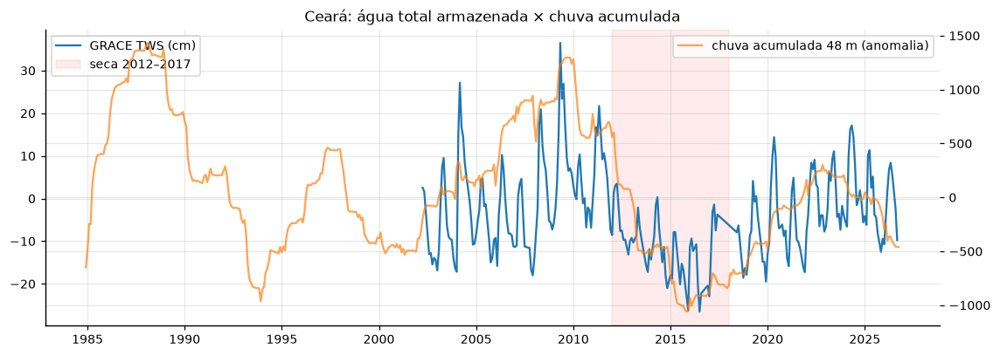

,janela_meses,r,n
0,3,0.281,259
1,6,0.358,259
2,12,0.352,259
3,18,0.355,259
4,24,0.376,259
5,36,0.469,259
6,48,0.490,259


In [170]:
g = achar("grace", "tws")
if g and chuva_longa:
    an = anomalia(painel[chuva_longa])
    gr = painel[g].dropna()
    linhas = []
    for w in [3, 6, 12, 18, 24, 36, 48]:
        acc = an.rolling(w).sum()
        j = pd.concat([acc, gr], axis=1).dropna()
        linhas.append({"janela_meses": w, "r": round(j.iloc[:, 0].corr(j.iloc[:, 1]), 3), "n": len(j)})
    T = pd.DataFrame(linhas)
    melhor = int(T.loc[T.r.idxmax(), "janela_meses"])
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(gr.index, gr, label="GRACE TWS (cm)", color="tab:blue")
    ax2 = ax.twinx()
    acc = an.rolling(melhor).sum()
    ax2.plot(acc.index, acc, color="tab:orange", alpha=0.7, label=f"chuva acumulada {melhor} m (anomalia)")
    ax.axvspan(pd.Timestamp("2012-01-01"), pd.Timestamp("2017-12-31"), color="red", alpha=0.08, label="seca 2012–2017")
    ax.legend(loc="upper left")
    ax2.legend(loc="upper right")
    ax.set_title("Ceará: água total armazenada × chuva acumulada")
    plt.show()
    display(T)

### 20.5 Clima → produção agrícola real (IBGE PAM)
Rendimento anual das culturas no Ceará contra a chuva de fev–mai e o ONI. A **elasticidade** (variação % do
rendimento por 100 mm de chuva) diz quais culturas são frágeis e quais toleram a seca. Esse é o insumo direto do
"risco" de cada rotação.

In [171]:
pam_f = None
for cand in ["ibge_pam_ce_anual.parquet", "pam_ce_anual.parquet", "ibge_pam_anual.parquet"]:
    if (DERIV / cand).exists():
        pam_f = DERIV / cand
        break
if pam_f is None:
    cands = sorted(DERIV.glob("*pam*.parquet")) + sorted((DADOS / "ibge_pam").glob("*.parquet"))
    pam_f = cands[0] if cands else None
print("Arquivo PAM:", pam_f)
if pam_f is not None and chuva_longa:
    pam = pd.read_parquet(pam_f)
    pam["ano"] = pd.to_datetime(pam["data"]).dt.year
    if {"produto", "variavel", "valor"} <= set(pam.columns):
        area = pam[pam.variavel == "area_colhida_ha"].pivot_table(index="ano", columns="produto", values="valor")
        relevantes = area.loc[area.index >= 2000].mean().loc[lambda s: s > 5000].index  # culturas com > 5 mil ha
        rend = pam[pam.variavel == "rendimento_kg_ha"].pivot_table(index="ano", columns="produto", values="valor")
        rend = rend[[c for c in rend.columns if c in relevantes]]
        print("Culturas analisadas (área colhida média > 5 mil ha desde 2000):", list(rend.columns))
        fmam = anual_fmam(painel[chuva_longa])
        if fmam.mean() < 60:
            fmam = fmam * 30
        # culturas permanentes mudaram de unidade no IBGE em 2001 (ex.: banana de mil cachos para toneladas)
        permanentes = set(pam.loc[pam.tipo == "permanente", "produto"])
        linhas = []
        for c in rend.columns:
            s = rend[c]
            if c in permanentes:
                s = s[s.index >= 2001]
            j = pd.concat([s, fmam.rename("fmam")], axis=1).dropna()
            if len(j) < 12 or j[c].mean() <= 0:
                continue
            # rendimento sem tendência tecnológica: razão para a mediana móvel centrada de 7 anos, em %
            tend = j[c].rolling(7, center=True, min_periods=3).median()
            dev = (j[c] / tend - 1) * 100
            sl, ic, r, p, _ = stats.linregress(j.fmam, dev)
            linhas.append({"cultura": c, "anos": len(j), "r(chuva, desvio rend.)": round(r, 2), "p": round(p, 3),
                           "% rendimento por +100 mm": round(sl * 100, 1),
                           "pior ano": int(dev.idxmin()), "quebra no pior ano %": round(dev.min(), 1)})
        E = pd.DataFrame(linhas).sort_values("r(chuva, desvio rend.)", ascending=False)
        display(E)
    else:
        print("Colunas de ano/cultura/rendimento não identificadas; ver seção 13.")

Arquivo PAM: E:\campeonato-nasa\dados\derivados\ibge_pam_ce_anual.parquet
Culturas analisadas (área colhida média > 5 mil ha desde 2000): ['Algodão herbáceo (em caroço)', 'Arroz (em casca)', 'Banana (cacho)', 'Café (em grão) Total', 'Cana-de-açúcar', 'Castanha de caju', 'Coco-da-baía*', 'Fava (em grão)', 'Feijão (em grão)', 'Mamona (baga)', 'Mandioca', 'Maracujá', 'Milho (em grão)']


,cultura,anos,"r(chuva, desvio rend.)",p,% rendimento por +100 mm,pior ano,quebra no pior ano %
7,Fava (em grão),45,0.57,0.000,8.9,2010,-54.4
12,Milho (em grão),45,0.51,0.000,10.3,1983,-64.4
8,Feijão (em grão),45,0.50,0.001,8.0,1998,-50.9
4,Cana-de-açúcar,45,0.46,0.002,1.4,1983,-28.3
10,Mandioca,45,0.42,0.004,3.1,1993,-57.1
5,Castanha de caju,25,0.40,0.049,7.3,2016,-40.8
2,Banana (cacho),25,0.39,0.053,1.4,2016,-14.7
1,Arroz (em casca),45,0.39,0.008,2.4,2001,-44.6
9,Mamona (baga),45,0.37,0.012,6.4,1992,-65.9
0,Algodão herbáceo (em caroço),45,0.34,0.023,7.2,2012,-81.7


### 20.6 Mercado: preço × produção e volatilidade
Para cada cultura candidata, volatilidade do preço ao produtor (FAOSTAT, Brasil) e do preço internacional
(Banco Mundial). Na pontuação das rotações, volatilidade alta = risco de renda; cultura com mercado firme = renda
suplementar.

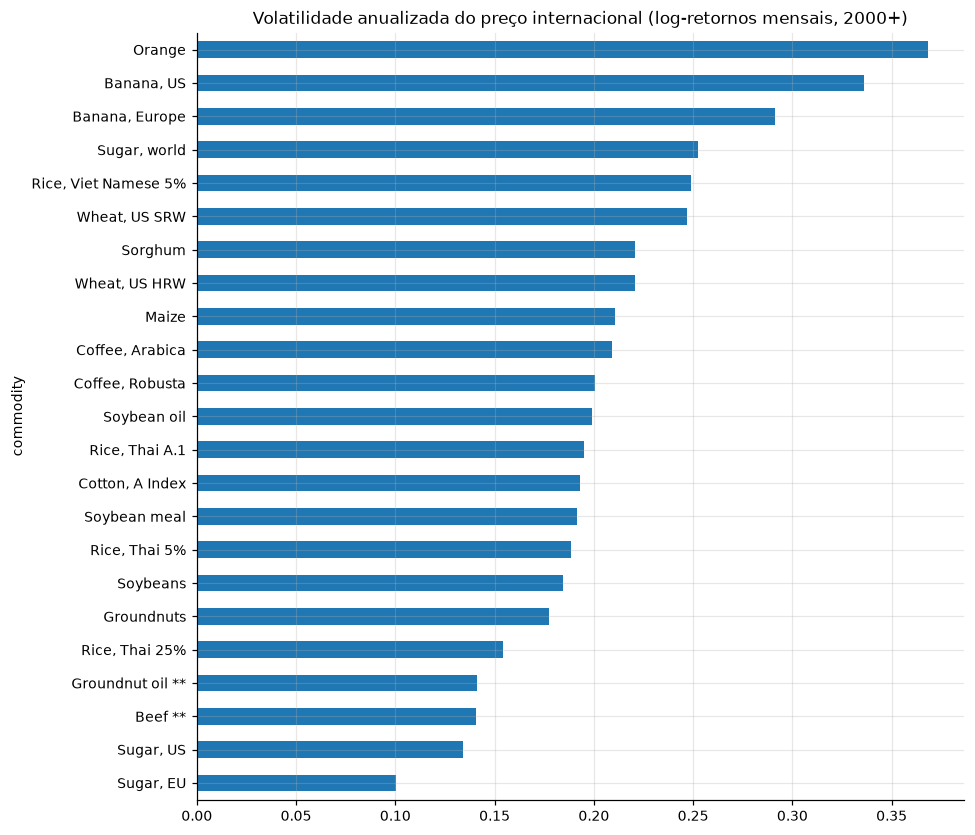

commodity
Sugar, EU               0.101
Sugar, US               0.134
Beef **                 0.141
Groundnut oil **        0.141
Rice, Thai 25%          0.154
Groundnuts              0.178
Soybeans                0.185
Rice, Thai 5%           0.188
Soybean meal            0.191
Cotton, A Index         0.193
Rice, Thai A.1          0.195
Soybean oil             0.199
Coffee, Robusta         0.201
Coffee, Arabica         0.209
Maize                   0.211
Wheat, US HRW           0.221
Sorghum                 0.221
Wheat, US SRW           0.247
Rice, Viet Namese 5%    0.249
Sugar, world            0.253
Banana, Europe          0.291
Banana, US              0.336
Orange                  0.368


In [172]:
mp = DERIV / "mercado_precos_mensal.parquet"
if mp.exists():
    m = pd.read_parquet(mp)
    m["data"] = pd.to_datetime(m["data"])
    rec = m[m.data >= "2000-01-01"]
    vol = (rec.sort_values("data").groupby("commodity")["preco"]
           .apply(lambda s: np.log(s.where(s > 0)).diff().std() * np.sqrt(12)).dropna().sort_values())
    sel = vol[vol.index.str.contains("Maize|Sorghum|Soybean|Cotton|Rice|Wheat|Sugar|Banana|Groundnut|Coffee|Beef|Orange",
                                     case=False, regex=True)]
    if len(sel):
        fig, ax = plt.subplots(figsize=(9, 0.35 * len(sel) + 1))
        sel.plot.barh(ax=ax)
        ax.set_title("Volatilidade anualizada do preço internacional (log-retornos mensais, 2000+)")
        plt.show()
    print(sel.round(3).to_string())

### 20.7 Mapa de conectividade das bases
Como cada base se liga às outras no produto (chave espacial/temporal) e as ligações **novas**, além das sugeridas pelo
desafio.

In [173]:
lig = pd.DataFrame([
    ("IMERG/POWER/ERA5 (chuva)", "MODIS/Landsat/S2 (NDVI)", "tempo (defasagem 1–2 meses)", "resposta da vegetação; detecção de estresse"),
    ("ONI + TNA/TSA (oceanos)", "chuva fev–mai", "tempo (out–jan → fev–mai)", "NOVO: previsão de tercil antes do plantio"),
    ("GRACE (TWS)", "chuva acumulada / GLDAS", "tempo (memória de 1–3 anos)", "NOVO: reserva hídrica para irrigação no ano seguinte"),
    ("SRTM (relevo)", "POWER/ERA5 (temperatura, chuva)", "espaço (altitude, orografia)", "microclima de serra × sertão; geada em baixadas"),
    ("SRTM + IMERG (intensidade)", "NDVI (cobertura)", "espaço-tempo", "RUSLE: risco de erosão por rotação"),
    ("FIRMS/MCD64A1 (fogo)", "NDVI + chuva + uso do solo", "espaço-tempo", "NOVO: risco de queimada e manejo de restos culturais"),
    ("GAEZ (aptidão)", "IBGE PAM (produção real)", "espaço (município)", "validar o filtro de culturas candidatas"),
    ("IBGE PAM (rendimento)", "chuva/ONI/GRACE", "tempo (ano)", "NOVO: elasticidade do rendimento à seca por cultura"),
    ("FAOSTAT/Banco Mundial (preço)", "IBGE PAM / GAEZ", "cultura × ano", "renda e risco de mercado da rotação"),
    ("CDL (EUA)", "NDVI/HLS", "pixel × ano", "NOVO: prior de rotação (matriz de transição) e rótulos de treino"),
    ("CDL/MapBiomas (mapa de culturas)", "POWER (graus-dia)", "espaço + tempo", "NOVO: percolação de pragas + nº de gerações"),
    ("NEX-GDDP-CMIP6 (projeções)", "POWER/ERA5 (histórico)", "tempo (2030–2100)", "NOVO: sliders de cenário futuro"),
], columns=["base A", "base B", "chave", "uso no produto"])
lig

,base A,base B,chave,uso no produto
0,IMERG/POWER/ERA5 (chuva),MODIS/Landsat/S2 (NDVI),tempo (defasagem 1–2 meses),resposta da vegetação; detecção de estresse
1,ONI + TNA/TSA (oceanos),chuva fev–mai,tempo (out–jan → fev–mai),NOVO: previsão de tercil antes do plantio
2,GRACE (TWS),chuva acumulada / GLDAS,tempo (memória de 1–3 anos),NOVO: reserva hídrica para irrigação no ano seguinte
3,SRTM (relevo),"POWER/ERA5 (temperatura, chuva)","espaço (altitude, orografia)",microclima de serra × sertão; geada em baixadas
4,SRTM + IMERG (intensidade),NDVI (cobertura),espaço-tempo,RUSLE: risco de erosão por rotação
5,FIRMS/MCD64A1 (fogo),NDVI + chuva + uso do solo,espaço-tempo,NOVO: risco de queimada e manejo de restos culturais
6,GAEZ (aptidão),IBGE PAM (produção real),espaço (município),validar o filtro de culturas candidatas
7,IBGE PAM (rendimento),chuva/ONI/GRACE,tempo (ano),NOVO: elasticidade do rendimento à seca por cultura
8,FAOSTAT/Banco Mundial (preço),IBGE PAM / GAEZ,cultura × ano,renda e risco de mercado da rotação
9,CDL (EUA),NDVI/HLS,pixel × ano,NOVO: prior de rotação (matriz de transição) e rótulos de treino


## 30. Ideias de modelos de Machine Learning e Deep Learning

Ideias organizadas pelo bloco do produto que cada uma alimenta. Para cada ideia: entrada (bases deste estudo),
rótulo/alvo, modelo de partida (baseline), modelo avançado, como validar e o que mostra ao agricultor.
A regra de ouro: **os números saem dos modelos e das bases; o modelo de linguagem só explica.**

### Mapa rápido

| # | Bloco do produto | Pergunta que o modelo responde | Bases | Baseline | Avançado |
|---|---|---|---|---|---|
| 1 | O que está plantado | Qual cultura/uso em cada pixel? | Sentinel-2/HLS/Landsat (NDVI, bandas), SRTM; rótulos CDL (EUA), MapBiomas/IBGE (BR) | Random Forest / LightGBM em atributos fenológicos | TempCNN, Transformer temporal; **Prithvi-EO-2.0 (NASA/IBM, treinado em HLS)** ou Presto como base pré-treinada |
| 2 | Rotação atual e próxima cultura | Qual a sequência típica e o que vem depois? | CDL 2008–2025 (transições), solo, clima | Cadeia de Markov de 1ª/2ª ordem por região | LSTM/Transformer de sequência com contexto (clima, solo) |
| 3 | Calendário do talhão | Quando o campo fica nu? quando planta e colhe? | NDVI MODIS/HLS/S2, chuva IMERG/POWER | Suavização Savitzky–Golay + logística dupla (estilo TIMESAT) | Segmentação temporal (1D U-Net) ou detecção de mudança bayesiana (BEAST) |
| 4 | Água no solo do talhão | Quanta água a raiz tem hoje e nas próximas semanas? | SMAP L4, GLDAS, POWER ET0/chuva, NDVI, LST, SRTM, solo | Balanço hídrico FAO-56 (balde) | Híbrido: balde físico + correção por XGBoost; downscaling do SMAP 9 km para 30–200 m (validar com NISAR 200 m) |
| 5 | A quadra chuvosa que vem | O próximo fev–mai será seco, normal ou chuvoso? | ONI (ENSO), TNA/TSA (Atlântico), chuva POWER/IMERG | Regressão logística multinomial de tercis | Gradient boosting/ensembles; avaliação deixando 1 ano de fora |
| 6 | Quanto cada cultura rende aqui | Rendimento esperado e risco de quebra por cultura | IBGE PAM (municípios), POWER, IMERG, NDVI, GAEZ | Regressão com efeitos fixos de município + clima | LightGBM com SHAP; emulador de modelo de cultura (AquaCrop/DSSAT rodado com POWER) |
| 7 | Risco de fogo | Probabilidade de queimada no mês, por célula | FIRMS VIIRS, MCD64A1, NDVI, LST, chuva acumulada, uso do solo | LightGBM por célula-mês | ConvLSTM / U-Net espaço-temporal |
| 8 | Pragas | Quantas gerações da praga cabem no ciclo? a paisagem favorece a dispersão? | POWER (graus-dia), mapa de culturas (CDL/MapBiomas), distâncias | Graus-dia + **percolação** (maior aglomerado conectado de hospedeiros) | Rede neural de grafos (GNN) se houver rótulos de ocorrência |
| 9 | Motor de rotação | Quais 3+ rotações maximizam as prioridades do agricultor? | Tudo acima + GAEZ/EcoCrop + preços FAOSTAT | Regras agronômicas + pontuação ponderada (pesos do agricultor) | Otimização multiobjetivo (NSGA-II) ou programação inteira; RL (PPO) num simulador de talhão |
| 10 | Explicação | Por que esta rotação? com que evidência? | Saídas do motor + fichas técnicas + literatura | Modelos de texto com campos preenchidos | LLM com RAG (citando a base e o número), sem inventar números |

### Detalhe das ideias mais promissoras para 48 h

**(5) Previsão de tercil da quadra chuvosa no Ceará — alto impacto, baixo custo.**
- A chuva de fev–mai no Ceará responde ao Pacífico (El Niño seca, La Niña chove) e ao gradiente do Atlântico tropical
  (TNA quente/TSA fria = seca).
- **Previsão:** com índices de out–dez, prever o tercil antes do plantio (jan).
- **No produto:** "este ano tende a ser seco → priorize rotação com sorgo/feijão-caupi/palma; adie o milho".
- **Validação:** deixar 1 ano de fora em 1981–2025; métrica RPSS ou acurácia de tercil contra a climatologia.

**(4) Balanço hídrico híbrido — o coração do motor.**
- **Modelo físico:** `S(t+1) = S(t) + P − ETc − D`, com `ETc = Kc(cultura, estágio) × ET0(POWER)` e capacidade de
  água do solo (SSURGO/SoilGrids/GAEZ).
- **Correção por ML:** um modelo aprende o erro do balde contra SMAP L4/GLDAS.
- **Saída:** déficit hídrico por estágio de cada cultura candidata, ou seja, o "custo de água" de cada rotação.

**(3) Fenologia + janelas de solo nu.**
- **Método:** a curva de NDVI (MODIS 250 m para o histórico, HLS/S2 para o talhão) é suavizada e ajustada.
  Início, pico, fim e os meses com NDVI abaixo de um limiar marcam as **janelas para plantas de cobertura**.

**(1)+(2) Do pixel à rotação.**
- **Nos EUA:** o CDL dá rótulos anuais por pixel. Uma cadeia de Markov das transições (ex.: milho→soja) é o
  "prior" de rotação.
- **No Brasil:** MapBiomas e IBGE dão a supervisão. Com o IBGE PAM, que só informa proporções por município, dá para
  treinar classificadores por **aprendizado a partir de proporções** (*learning from label proportions*).

**(8) Percolação de pragas.**
- **Grafo:** talhões com a mesma família hospedeira são nós; arestas ligam talhões a menos de X km.
- **Métrica:** quando a fração de hospedeiros passa do **limiar de percolação**, forma-se um aglomerado gigante e a
  praga atravessa a paisagem.
- **No produto:** a rotação que **quebra a conectividade** reduz o risco regional, o que dá um argumento coletivo,
  não só individual.
- **Exemplo histórico:** o bicudo-do-algodoeiro no Nordeste nos anos 1980.

### Validação e incerteza (critério "Validade")
- Validação **espacial e temporal em blocos**: deixar município/ano de fora para não vazar a autocorrelação.
- **Predição conformal** para intervalos de confiança honestos.
- **Ensembles** para a incerteza do modelo.
- Em cada mapa, mostrar a **escala real da camada**: região (≥ 9 km) × talhão (10–30 m).
- Revisão humana: cada estratégia termina com "o que confirmar com o técnico de campo".

### Roteiro sugerido
1. **MVP (48 h):** calendário de riscos (estatística), balanço hídrico FAO-56, filtro GAEZ, pontuação de 3 rotações,
   previsão de tercil (5) e explicação.
2. **Pós-hackathon:** classificação de culturas com Prithvi/Presto, downscaling do SMAP, modelo de fogo e grafo de pragas.
3. **Visão:** simulador de talhão + aprendizado por reforço para rotações robustas sob cenários NEX-GDDP-CMIP6.

In [174]:
print("Seção de ideias (texto).")

Seção de ideias (texto).


## 90. Síntese

### 90.1 Veredito de cobertura global (o produto pode atender o mundo?)

| Base | Global? | Evidência deste estudo | Ressalva para o produto |
|---|---|---|---|
| NASA POWER | **Sim** | 107 pontos em todos os continentes, inclusive Antártida, Svalbard e oceano: meteorologia 100% válida (seção 1) | ~50 km: clima regional, não microclima |
| GPM IMERG | **Sim** | V07 com dados nos 216 pontos testados, de 85°S a 85°N (seção 2) | V07 diária a 0,1° vem aberta pelo POWER (~2 meses de atraso); V06 completa só entre 60°S e 60°N |
| ERA5 | **Sim** | 90°S–90°N, sem ausentes (seção 3) | modelo, não observação; ~31 km; aberto só até 2020 (Planetary Computer) |
| NEX-GDDP-CMIP6 | **Quase** | 60°S–90°N, só terra (seção 15) | projeções; usar vários modelos para chuva |
| NLDAS | **Não** | caixa 25–53°N, 125–67°W (seção 4) | usar só como enriquecimento nos EUA |
| GLDAS | **Quase** | 60°S–90°N (seção 4) | sem Antártida; exige Earthdata |
| SMAP | **Sim** | 85°S–90°N (seção 4) | exige Earthdata; 9 km; L3 só 0–5 cm → usar L4 (zona da raiz) |
| GRACE/GRACE-FO | **Sim** | 100% das células de terra e oceano (seção 6) | resolução efetiva ~300 km; 35 meses faltantes (lacuna 2017–18) |
| Landsat | **Sim** | dados nas 27 caixas de teste de 81°N a 80°S (seção 7) | revisita de 8–16 dias; nuvem na estação chuvosa |
| Sentinel-2 | **Sim** | idem (seção 8) | NDVI tem viés contra o Landsat → usar **HLS** |
| MODIS | **Sim (terra)** | ~300 tiles por período, 14 pontos em 6 continentes (seção 9) | Terra no fim da vida (lacuna de jun–nov/2025) → migrar para VIIRS |
| VIIRS (fogo FIRMS) | **Sim** | arquivos anuais por país (seção 9) | NDVI do VIIRS exige Earthdata |
| SRTM/NASADEM | **Quase** | 56°S–60°N (seção 10) | completar com o Copernicus DEM (global) |
| FAO GAEZ | **Sim** | 99,8% dos pixels de terra, 56°S–84°N (seção 11) | ~9 km; clima de 1981–2010; produção real "2010" não confere com o IBGE |
| AMS Market News | **Não** | só EUA, API com chave (seção 12) | trocar por FAOSTAT (por país) + Banco Mundial (referência) |
| CDL | **Não** | só EUA contíguos (seção 14) | serve de laboratório e de "prior" de rotação; globais: WorldCereal, MapBiomas (BR) |

**Conclusão de arquitetura: núcleo global + enriquecimento local.**
- **Núcleo (funciona em qualquer lugar):**
  - chuva: IMERG, com o POWER de reserva;
  - temperatura, radiação e ET0: POWER (ERA5 como alternativa);
  - umidade do solo: SMAP L4, com o POWER GWETROOT enquanto não houver login;
  - vegetação: HLS a 30 m, a cada 2–4 dias;
  - relevo: NASADEM + Copernicus DEM;
  - água regional: GRACE;
  - fogo: VIIRS/FIRMS;
  - aptidão: GAEZ (+ ECOCROP);
  - mercado: FAOSTAT + Banco Mundial;
  - futuro: NEX-GDDP-CMIP6.
- **Enriquecimento local quando existir:**
  - Brasil: IBGE PAM, ZARC e MapBiomas;
  - EUA: CDL, SSURGO e NLDAS.

### 90.2 O que os dados dizem sobre o Ceará (o roteiro do pitch)
1. **Uma janela, uma chance.**
   - 77,5% do Ceará só comporta uma safra de sequeiro (GAEZ).
   - A estação vai de ~2/fev a ~28/jul, com pico em abril (MODIS).
   - O solo fica exposto de setembro a janeiro (MODIS/Landsat).
   - **A rotação no sertão é, antes de tudo, decidir o que fica no solo na entressafra** (cobertura, forrageira,
     leguminosa perene) e qual cultura arrisca na quadra.
2. **A chuva decide o rendimento, cultura a cultura** (IBGE PAM × POWER, seção 20).
   - Cada +100 mm em fev–mai: milho +10%, fava +9%, feijão +8%; mandioca +3%, cana +1,4%.
   - Mandioca, cana e culturas irrigadas são os **amortecedores** da rotação.
3. **O oceano avisa, mas pouco.**
   - O ONI de out–jan correlaciona com a chuva de fev–mai (r ≈ −0,39).
   - Um modelo de tercil acerta 41% contra 33% do acaso (RPSS +0,10).
   - O produto deve falar em **probabilidades**.
   - O ONI de set/2026 em +2,46 (El Niño forte) é **alerta para a quadra de 2027**.
4. **O aquecimento está na temperatura, não na chuva.**
   - Tendência de temperatura: Tmax do POWER +0,37 °C/década; T2m do ERA5 +0,18 °C/década. 73% dos pixels do
     Nordeste têm aumento significativo de Tmax. A chuva anual não tem tendência.
   - **Cuidado com limiares absolutos:** a Tmax do POWER é ~1,7 °C mais quente que a do ERA5. Os dias acima de 35 °C
     crescem +10/década no POWER e +2/década no ERA5. O produto deve usar **anomalias ou percentis por fonte**, ou
     calibrar com estação do INMET.
   - ET0 ~1.960 mm/ano contra ~810 mm de chuva; a ET0 supera a chuva em 10 de 12 meses.
   - **Futuro (NEX-GDDP, 1 modelo):** dias ≥ 35 °C passam de 56/ano para 98/ano em 2046–50 (SSP5-8.5) e 142/ano em
     2086–90. O sinal de temperatura é robusto; o de chuva, não.
4b. **O início da estação prevê a estação** (IMERG, seção 2).
   - Início médio ~17/jan; o dia de início correlaciona ρ = −0,67 com o total da estação.
   - Isso dá uma **regra de decisão em fevereiro**: início tardio → trocar para a rotação tolerante à seca.
   - Seca composta: chuva e Tmax anuais com ρ = −0,88; em 2012–17, −29% de chuva, +0,58 °C de Tmax e +96 mm/ano de ET0.
   - Chuva concentrada e erosiva: 73% em fev–mai; I30 de até 80 mm/h; maior veranico médio da quadra de 12,7 dias
     (22,6 em 2012).
5. **A água tem memória de anos.**
   - O GRACE no Ceará acompanha a chuva acumulada de 36–48 meses (r ≈ 0,47–0,49).
   - Na seca de 2012–2017, 45 de 50 meses ficaram abaixo do normal (mínimo de −24,6 cm em jul/2016).
   - Contraponto: o aquífero Urucuia (Oeste da Bahia) perde 1,4–1,7 cm/ano.
6. **A vegetação responde rápido à água e o calor a denuncia.**
   - NDVI × chuva: pico com 1 mês de defasagem.
   - Umidade da raiz × NDVI: r ≈ 0,51.
   - LST × NDVI: r ≈ −0,85 → índice de secura (TVDI) a 1 km, global.
7. **Fogo: antes do plantio e na Caatinga.**
   - 72% dos focos caem em out–dez; 62% na Caatinga, 14% em lavoura.
   - Anos verdes antecedem mais fogo ~6 meses depois (combustível).
   - O produto de área queimada a 500 m não vê o roçado; o VIIRS a 375 m vê.
8. **A nuvem cega o satélite óptico justo na estação.**
   - Só 7–25% das cenas Landsat de fev–mai têm menos de 20% de nuvem.
   - **HLS** (Landsat + Sentinel-2) é obrigatório, e o radar (Sentinel-1/NISAR) é o próximo passo.
9. **O que cabe no Ceará depende do insumo** (GAEZ).
   - Com insumo baixo, típico da agricultura familiar: sorgo, mandioca, guandu, feijão.
   - **O algodão tem aptidão alta e área ~zero:** caiu de 306 mil ha (1985) para ~2 mil ha, e o algodão arbóreo de
     1,25 Mha para zero. Pragas (bicudo) e mercado explicam o que o clima não explica.
10. **A conta do adubo favorece a leguminosa.** A razão de preço ureia/milho chegou a 4,0 (abr/2026), contra uma
    média de 1,5 em 2000–2020 (Banco Mundial).
11. **A rotação real é mensurável.** No CDL (EUA), 73% do Iowa alterna milho↔soja, mas o semiárido do Texas tem
    67% de algodão contínuo. A monocultura no semiárido é o mesmo risco que o bicudo explorou no Nordeste.

### 90.3 O que a literatura acrescenta (ver `pesquisa/artigos_e_datasets.md`)
- **Leguminosa antes da cultura:** +20% no rendimento seguinte, chegando a +32% em ambientes de baixa produtividade;
  o efeito some com muito N mineral (Zhao et al. 2022, Nat. Commun.).
- **Rotação diversa:** +28% no milho e perdas 14–90% menores em ano seco (Bowles et al. 2020, One Earth).
- **Corte e queima sem pousio no semiárido (Sobral-CE):** ~50% do carbono do solo perdido em ~10 anos (Primo et al. 2023).
- **Veranico** (≥ 3 dias com ≤ 2 mm) liga-se à perda de milho e feijão no Ceará (Rocha et al. 2021, FUNCEME).
- **ZARC (MAPA):** tábua de risco aberta por município × cultura × solo × decêndio. É a restrição de janela de
  plantio pronta para o Brasil.
- **Alerta:** o "Crop Recommendation Dataset" do Kaggle tem padrão de dado sintético e não deve ser usado como evidência.

### 90.4 Pendências e riscos
- **Earthdata Login:** SMAP, GLDAS, NLDAS, VIIRS VNP13 e os últimos ~2 meses do IMERG (Early/Late) aguardam a
  credencial. O IMERG V07 diário a 0,1° de 1998 a set/2026 já veio pelo POWER, sem login. Os scripts estão prontos
  (`scripts/baixar_earthdata.py`).
- **Chuva no litoral leste:** o IMERG ficou em ~40–60% de normais aproximadas em Recife, Maceió, Aracaju e Salvador,
  contra 82–94% no sertão. As normais usadas eram aproximadas: **conferir com as Normais do INMET** antes de afirmar
  viés. Pode haver efeito de pixel misto terra/mar.
- **ERA5 aberto só até 2020** (espelho do Planetary Computer); para 2021+, CDS com chave. O ERA5 tem viés de
  chuvisco (mais dias ≥ 1 mm que o IMERG).
- **Calibração do POWER:** o IMERG do POWER só vem preenchido no horário UTC; a radiação começa em 1984.
- **MODIS:** os arquivos reprocessados mudaram o tipo do campo de qualidade (já tratado); a tendência da LST diurna é
  contaminada pela deriva orbital do Terra.
- **AOIs:** as coordenadas são aproximadas; para a demo, escolher talhões reais com o usuário.

In [175]:
print("Síntese (texto). Números detalhados nas seções 1–20.")

Síntese (texto). Números detalhados nas seções 1–20.
